In [164]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
from typing import Optional

import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score

sns.set_theme()
PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00" 
RANDOM_STATE = 42
FIGSIZE = (10, 6)
TARGET = 'repeat_purchase_90d'
PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / 'data'

In [41]:
train_raw = pd.read_csv(DATA / "train.csv", index_col = "ID")
test_raw = pd.read_csv(DATA / "test.csv", index_col = "ID")
clientes_raw = pd.read_csv(DATA / "clientes.csv", index_col = "customer_id")


In [42]:
datasets = {"train_raw": train_raw, 
            "test_raw": test_raw, 
            "clientes_raw": clientes_raw}

for name, dataset in datasets.items():
    print(f"dataset: {name}\nrows: {dataset.shape[0]}\ncolumns: {dataset.shape[1]}\n")
    

dataset: train_raw
rows: 6534
columns: 38

dataset: test_raw
rows: 986
columns: 37

dataset: clientes_raw
rows: 1143
columns: 12



In [43]:
train_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,9.255563e+02,1.334998e+03,0.930000,188.920000,476.740000,1087.670000,2.229721e+04
Total Bruto,6469.0,8.861527e+02,1.327641e+03,0.830000,175.740000,445.740000,1036.700000,2.157828e+04
Total Liquido,6469.0,7.733364e+02,1.136356e+03,0.760000,154.380000,389.910000,903.370000,1.812781e+04
Total Imp_,6469.0,1.522199e+02,2.252624e+02,0.000000,29.930000,79.740000,184.840000,4.169400e+03
Total Portes,6469.0,1.151427e+00,5.844091e+00,0.000000,0.000000,0.000000,0.000000,1.810600e+02
Total Desc_ Global,6469.0,3.499072e-01,5.116564e+00,0.000000,0.000000,0.000000,0.000000,2.184900e+02
Total Desc_ Linha,6469.0,1.124664e+02,2.899863e+02,0.000000,0.000000,13.130000,92.280000,4.103440e+03
Custo,6469.0,3.281650e+02,5.195072e+02,0.000000,49.050000,152.540000,396.061499,7.427401e+03
N_ Detalhes,6469.0,2.152450e+01,2.771342e+01,1.000000,4.000000,11.000000,29.000000,4.230000e+02
invoice_count_current_purchase,6469.0,1.066007e+00,3.108069e-01,1.000000,1.000000,1.000000,1.000000,5.000000e+00


In [44]:
train_raw.T

ID,10000000,10000001,10000002,10000003,10000004,10000005,10000007,10000009,10000011,10000012,...,10007664,10007665,10007666,10007667,10007669,10007670,10007671,10007672,10007673,10007674
Total a Pagar,558.11,978.8,10.33,856.83,1616.1,640.78,122.83,1409.75,962.63,457.95,...,34.65,790.78,1488.1,1456.39,81.87,3023.34,1362.26,4396.55,452.07,951.71
Total Bruto,510.9,830.02,12.0,696.61,1488.85,568.24,105.55,1272.44,786.27,372.32,...,49.5,642.91,1864.26,1195.39,66.56,3761.38,1723.1,3574.43,483.6,982.0
Total Liquido,453.75,795.77,8.4,696.61,1313.9,520.96,100.43,1146.14,782.63,372.32,...,34.65,642.91,1209.84,1184.06,66.56,2458.0,1107.53,3574.43,367.54,773.75
Total Imp_,104.36,183.03,1.93,160.22,302.2,119.82,22.4,263.61,180.0,85.63,...,0.0,147.87,278.26,272.33,15.31,565.34,254.73,822.12,84.53,177.96
Total Portes,0.0,0.0,0.0,0.0,0.0,0.0,3.05,0.0,0.0,0.0,...,0.0,0.0,9.65,0.0,3.36,0.0,0.0,0.0,0.0,0.0
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,34.25,0.0,0.0,0.0
Total Desc_ Linha,57.15,34.25,3.6,0.0,174.95,47.28,5.12,126.3,3.64,0.0,...,14.85,0.0,654.42,11.33,0.0,1303.38,581.32,0.0,116.06,208.25
Custo,153.099911,472.943134,6.097485,408.167275,485.401864,336.60065,0.0,246.974108,496.926279,129.982522,...,0.0,385.608527,429.921971,661.260577,37.15,1099.19,197.514,2075.838024,265.159468,224.543079
N_ Detalhes,4.0,32.0,1.0,9.0,33.0,11.0,5.0,66.0,46.0,14.0,...,1.0,17.0,75.0,31.0,3.0,49.0,16.0,78.0,7.0,30.0
invoice_count_current_purchase,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [45]:
train_raw.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

In [46]:
train_raw.dtypes

Total a Pagar                     float64
Total Bruto                       float64
Total Liquido                     float64
Total Imp_                        float64
Total Portes                      float64
Total Desc_ Global                float64
Total Desc_ Linha                 float64
Custo                             float64
N_ Detalhes                       float64
invoice_count_current_purchase    float64
repeat_purchase_90d                 int64
days_since_previous_purchase      float64
customer_tenure_days              float64
prior_purchase_count              float64
prior_total_spend                 float64
prior_mean_purchase_value         float64
prior_std_purchase_value          float64
prior_min_purchase_value          float64
prior_max_purchase_value          float64
prior_mean_gap_days               float64
prior_std_gap_days                float64
purchase_count_30d                float64
spend_30d                         float64
purchase_count_90d                

In [47]:
train_raw.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03
Custo,6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00


In [48]:
train_raw.describe(include="str").T

,count,unique,top,freq
payment_type,6274,9,Maybe Tomorrow Payment 7,4565
salesperson,6275,9,VLOOKUP Master 1,4054
commercial_zone,6469,5,Decorative Dashboard Zone 4,6260
transport_method,6273,80,Maybe Tomorrow Delivery 72,1119
warehouse,6274,2,Final Excel Warehouse 1,6253
document_series,6469,3,Ctrl Z Series 2,2738
purchase_date,6469,1492,2015-10-31,52


In [49]:
# Get a look of the data

for column in train_raw.columns:
    print(f"Column: {column}\nExamples:\n {train_raw[column].head(10)}\n")

Column: Total a Pagar
Examples:
 ID
10000000     558.11
10000001     978.80
10000002      10.33
10000003     856.83
10000004    1616.10
10000005     640.78
10000007     122.83
10000009    1409.75
10000011     962.63
10000012     457.95
Name: Total a Pagar, dtype: float64

Column: Total Bruto
Examples:
 ID
10000000     510.90
10000001     830.02
10000002      12.00
10000003     696.61
10000004    1488.85
10000005     568.24
10000007     105.55
10000009    1272.44
10000011     786.27
10000012     372.32
Name: Total Bruto, dtype: float64

Column: Total Liquido
Examples:
 ID
10000000     453.75
10000001     795.77
10000002       8.40
10000003     696.61
10000004    1313.90
10000005     520.96
10000007     100.43
10000009    1146.14
10000011     782.63
10000012     372.32
Name: Total Liquido, dtype: float64

Column: Total Imp_
Examples:
 ID
10000000    104.36
10000001    183.03
10000002      1.93
10000003    160.22
10000004    302.20
10000005    119.82
10000007     22.40
10000009    263.61


### Missing Values

In [50]:
row_missing_count = train_raw.isna().sum(axis=1)
row_missing_count.value_counts()

0     3929
1     1287
7      511
3      354
2      190
4      100
8       86
36      65
5        6
9        6
Name: count, dtype: int64

In [51]:
rows_with_36_missings = train_raw[row_missing_count==36]
rows_with_36_missings

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000678,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,508217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000870,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10007151,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,151492,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10007169,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,230585,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10007339,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,902830,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [52]:
# Check if the ID is duplicated
other_rows = train_raw[row_missing_count != 36]
rows_with_36_missings.index.isin(other_rows.index).sum()

np.int64(0)

In [53]:
# Check if these ID are from the same customer form another purchase
incomplete_customers = rows_with_36_missings["customer_id"]
incomplete_customers.isin(other_rows["customer_id"]).value_counts()


customer_id
True     62
False     3
Name: count, dtype: int64

In [54]:
# Check the 3 customers that we don't have in the train data to see if they exists in clientes.csv
incomplete_customers[~incomplete_customers.isin(other_rows["customer_id"])] 

ID
10001116    793048
10001537    133497
10007590    697676
Name: customer_id, dtype: int64

In [55]:
new_customers_with_no_data = [793048, 133497, 697676]

for customer in new_customers_with_no_data:
    clientes_info = clientes_raw[clientes_raw.index == customer]

    if clientes_info.empty:
        print(f"Customer {customer}: NOT FOUND")
    else:
        print(f"Customer {customer}: FOUND")
        display(clientes_info)
    

Customer 793048: FOUND


,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
customer_id,,,,,,,,,,,,
793048,Country CT10: Land of The Final Version,Region RG19: We Will See Later,NaN,Municipality MU42: Council of Last Minute Edits,City CY227: AutoFill Village,Postal area PA217: Hidden Sheet Sector,Postal code PC425: #REF! Delivery Route,Street ST242: PowerPoint New Parade,Address AD639: Cell Without a Home,NaN,Excel Is Not A Database Ltd 313,2015


Customer 133497: FOUND


,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
customer_id,,,,,,,,,,,,
133497,Country CT10: Land of The Final Version,Region RG32: We Will See Later,NaN,Municipality MU147: Council of Last Minute Edits,NaN,Postal area PA15: Hidden Sheet Sector,Postal code PC77: #REF! Delivery Route,NaN,Address AD950: Cell Without a Home,NaN,Excel Is Not A Database Ltd 435,2016


Customer 697676: FOUND


,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
customer_id,,,,,,,,,,,,
697676,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS7: The Pivot Archipelago,Municipality MU4: Council of Last Minute Edits,NaN,Postal area PA251: Hidden Sheet Sector,Postal code PC531: #REF! Delivery Route,Street ST60: Frozen Pane Avenue,Address AD212: Cell Without a Home,NaN,Excel Is Not A Database Ltd 242,2015


Notes:
For the missing values in the general aspect of the dataframe, we have found out that in every column (except ID, cumtomer_id and repeat_purchase_90d) have missing values, at this point we are not focusing in these missings column by column, more in the big picture, because of this, at this momnet the relevant info that we have retrieved is the folling:

· 65 rows have no info except ID, cumtomer_id and repeat_purchase_90d

· From these 65, 62 are customers that are linked with one or more purchases in the train_raw

· The 3 missing, even though that we don't have any more purchase than the empty row, we have found these customers in clientes.csv

In [56]:
train_raw.duplicated().sum()

np.int64(10)

In [57]:
duplicated_rows = train_raw[train_raw.duplicated(keep=False)]
duplicated_rows.T

ID,10000457,10000560,10000983,10002381,10003209,10003718,10004187,10004463,10004649,10005141,10005177,10005269,10005608,10006618,10006879,10007583
Total a Pagar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Bruto,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Liquido,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Imp_,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Portes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Desc_ Global,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Desc_ Linha,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Custo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
N_ Detalhes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
invoice_count_current_purchase,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [58]:
# See if all these duplicated are in the list of the rows where 36 columns are NaN
duplicated_rows.index.isin(rows_with_36_missings.index).all()

np.True_

In [59]:
train_raw.index.duplicated().sum()

np.int64(0)

### Cardinality 

In [60]:
train_raw.nunique(dropna=False).sort_values()

repeat_purchase_90d                  2
warehouse                            3
document_series                      4
invoice_count_current_purchase       6
commercial_zone                      6
salesperson                         10
payment_type                        10
purchase_count_30d                  13
purchase_count_90d                  24
purchase_count_180d                 39
purchase_count_365d                 62
transport_method                    81
Total Desc_ Global                 110
N_ Detalhes                        172
Total Portes                       216
prior_purchase_count               278
days_since_previous_purchase       496
customer_id                        610
prior_max_purchase_value          1157
prior_min_purchase_value          1158
purchase_date                     1493
spend_30d                         2106
customer_tenure_days              2122
Total Desc_ Linha                 3521
spend_90d                         3524
prior_mean_gap_days      

Anomalies detected for future study:

transport_method -> Too many different categories

random_noise -> Each of the values in all records are different, the 6469 + the Nans

customer_id -> Surprisingly low number, that means that in the dataframe we have a lot of customer_id that have more than one purchase

### Numerical anomalies

In [61]:
train_raw.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03
Custo,6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00


Anomalies detected for future study:

days_since_previous_purchase -> Have a min of -4, being days since the previous purchase doesn't make much sense being negative

prior_mean_gap_days -> Same as days_since_previous_purchase, might be an error from last field dragged

prior_mean_purchase_value -> The max and min seems very excesive 

spend_365d -> The max and min seems very excesive


In [62]:
numeric_columns = train_raw.select_dtypes(include="number").columns

(train_raw[numeric_columns] < 0).sum()

Total a Pagar                        0
Total Bruto                          0
Total Liquido                        0
Total Imp_                           0
Total Portes                         0
Total Desc_ Global                   0
Total Desc_ Linha                    0
Custo                                0
N_ Detalhes                          0
invoice_count_current_purchase       0
repeat_purchase_90d                  0
days_since_previous_purchase        16
customer_tenure_days                 0
prior_purchase_count                 0
prior_total_spend                    0
prior_mean_purchase_value           16
prior_std_purchase_value             0
prior_min_purchase_value             0
prior_max_purchase_value             0
prior_mean_gap_days                 16
prior_std_gap_days                   0
purchase_count_30d                   0
spend_30d                            0
purchase_count_90d                   0
spend_90d                            0
purchase_count_180d      

In [63]:
negative_columns = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_mean_gap_days", "spend_365d"]

negative_columns_records = (train_raw[negative_columns] < 0).any(axis=1)

negative_records = train_raw[negative_columns_records]

print(len(negative_records.index))
print(negative_records)

63
          Total a Pagar  Total Bruto  Total Liquido  Total Imp_  Total Portes  \
ID                                                                              
10000018        2460.00      2000.00        2000.00      460.00           0.0   
10000300         322.65       276.70         262.32       60.33           0.0   
10000358        1814.29      1670.79        1475.03      339.26           0.0   
10000407         507.87       470.25         412.90       94.97           0.0   
10000519         221.74       180.28         180.28       41.46           0.0   
...                 ...          ...            ...         ...           ...   
10006915         804.57       664.22         654.12      150.45           0.0   
10006958         263.27       214.04         214.04       49.23           0.0   
10007015         359.04       382.85         291.90       67.14           0.0   
10007510          28.33        23.03          23.03        5.30           0.0   
10007587        3121.70  

We check the negative values, and if they are in different records or maybe there are two or more in different records, seeing that we have a total of 63 unique IDs and 63 are the rows obtained for the negative columns, and being the count of negative values of the:

days_since_previous_purchase        16

+

prior_mean_purchase_value           16

+

prior_mean_gap_days                 16

+

spend_365d                          15
---------------- ---------------------------
                63

We can confirm that all these 63 negative values are in different rows, which means that is not an error in one record that is being dragged while calculating other columns, but we will analize it better later on

### Summary of the potential issues seen

+ We have seen that we have 65 records where all of the fields (except ID, cumtomer_id and repeat_purchase_90d) are NaN
+ When ignoring the ID column, we get a total of 10 duplicated rows, those ID are inside the list of the 65 records that are all NaNs, so probably is a same customer_id with same target value, that there has been an error while registering the purchase
+ Pending analysis on the missings of different columns, pending deeper analisis
+ We haven't seen any major error in the cardinality of the fields, but need to analyze `transport method`that are many categories
+ Negative values, we have seen that 63 different records contain negative values in fields that shouldn't be negative
+ Extreme values, we have seen in the min and max of some of the fields, extreme values that differe a lor with the mean
+ We have identified columns stored as float that can be stored as int to reduce the storage weight improve computational power


## Analisis column by column
### ID


In [64]:
print(train_raw.index.unique())
print(len(train_raw))

Index([10000000, 10000001, 10000002, 10000003, 10000004, 10000005, 10000007,
       10000009, 10000011, 10000012,
       ...
       10007664, 10007665, 10007666, 10007667, 10007669, 10007670, 10007671,
       10007672, 10007673, 10007674],
      dtype='int64', name='ID', length=6534)
6534


As we expected, we have the same amount of unique values of our index, ID, as the total length of the dataframe, which supports the decision of making this field the index

### customer_id

In [65]:
customer_purchases = train_raw["customer_id"].value_counts()

print(f"Number of unique customers: {train_raw["customer_id"].nunique()}")
print(f"Purcheses per unique client: {customer_purchases.describe()}")

Number of unique customers: 610
Purcheses per unique client: count    610.000000
mean      10.711475
std       19.969320
min        1.000000
25%        1.000000
50%        4.000000
75%       12.000000
max      277.000000
Name: count, dtype: float64


In [66]:
customer_purchases.head(10)

customer_id
103940    277
258332    203
755628    112
519184     89
151492     89
239651     81
703834     80
227020     74
497930     73
488020     67
Name: count, dtype: int64

We see that in all the train data we have 610 different customer_id, meaning that from the 6534 records that we have in train, a lot of the purchesases are from the same customer. We have seen, that the mean and the median are very different, this comes because most of the records, 50% of them, have 4 or fewer purchases, but we have some clients that have registered a lot of purchases, example:

103940    277
258332    203

Which pumps a lot the mean, let's check how much of the dataset is represented by the top 10 clientes with the most purchases in the dataset

In [67]:
customer_purchases_top10 = customer_purchases.head(10).sum()

print(f"Number of purcheses from the top10 customers: {customer_purchases_top10}")
print(f"How much do they contribute to our dataset: {(customer_purchases_top10/len(train_raw) * 100).round(2)}%")


Number of purcheses from the top10 customers: 1145
How much do they contribute to our dataset: 17.52%


We see that only 10 customers represent a 17.52% of the records in the dataset, at the moment we will just flag this and later on we will decide how to deal with these customers

### purchase_date

In [68]:
print(f"Data type of purchase_date: {train_raw["purchase_date"].dtype}")
print(f"Number of NaN values: {train_raw["purchase_date"].isna().sum()}")
print(f"Number of NaN after converting from string to datetime: {pd.to_datetime(train_raw["purchase_date"], errors="coerce").isna().sum()}")
purchase_dates = pd.to_datetime(train_raw["purchase_date"], errors="coerce")
print(f"Earliest purchase in the dataset: {purchase_dates.min()}")
print(f"Last purchase in the dataset: {purchase_dates.max()}")
print(f"Difference between the first and last purchase of the dataset: {(purchase_dates.max() - purchase_dates.min())}")

Data type of purchase_date: str
Number of NaN values: 65
Number of NaN after converting from string to datetime: 65
Earliest purchase in the dataset: 2015-07-11 00:00:00
Last purchase in the dataset: 2025-02-15 00:00:00
Difference between the first and last purchase of the dataset: 3507 days 00:00:00


We have seen that all the records are good converted to datetime, the only NaNs are the ones that we already had, we also have checked the first and the last purchase registered in the dataset, that are almost 10 years apart

## Functions that’s  we will use

Before starting we will define some functions that we will be using to help discover useful information about the columns

In [720]:
def descrive_monetary(column_name: str, dataframe):

    print(f"{column_name} describe:\n{dataframe[column_name].describe().round(2)}\n")

    print(f"Missing values: {dataframe[column_name].isna().sum()}\n")
    print(f"Unique values: {dataframe[column_name].nunique()}\n")
    print(f"Zero values: {(dataframe[column_name] == 0).sum()}\n")
    print(f"Negative values: {(dataframe[column_name] < 0).sum()}\n")

    
    top10 = dataframe.nlargest(10, column_name)
    print(f"{column_name} top 10 maximum:\n{top10[["customer_id", column_name]]}\n")
    
    print(f"The top 10 represent the: {((top10[column_name].sum()/ dataframe[column_name].sum()) * 100):.2f}% of the column {column_name}")

In [207]:
def descrive_discrete(column_name: str, dataframe):
    print(f"{column_name} describe:\n{dataframe[column_name].describe().round(2)}\n")

    print(f"{column_name} missings:\n{dataframe[column_name].isna().sum()}\n")

    print(f"{column_name} number of unique values: {dataframe[column_name].nunique()}\n")

    frequencies = dataframe[column_name].value_counts(dropna=False).sort_index()
    percentatge = dataframe[column_name].value_counts(normalize=True, dropna=False).sort_index()*100
    frequency_table = pd.DataFrame({"Count": frequencies, "Percentage:": percentatge.round(2)})
    display(frequency_table)
    


In [699]:
def histograms_one_column(column_name: str, dataframe, filter_data, quantile = 0.99, bins= 150):
    if bins < 50:
        bin_list = []
        for bin in range(bins + 1):
            add = -0.5 + bin
            bin_list.append(add)
        plt.hist(dataframe[column_name], bins=bin_list, color=PLOT_BLUE)
        plt.xlabel(column_name)
        plt.ylabel("Number of purchases")

    else:
        plt.hist(dataframe[column_name], bins=bins, color=PLOT_BLUE)
        plt.xlabel(column_name)
        plt.ylabel("Number of purchases")
    
    plt.show()

    if filter_data:
        upper_limit = dataframe[column_name].quantile(quantile)
        filtered_data= dataframe[dataframe[column_name] <= upper_limit]
        if bins < 50:
            plt.hist(filtered_data[column_name], bins=bin_list, color=PLOT_BLUE)
        else:
            plt.hist(filtered_data[column_name], bins=bins, color=PLOT_BLUE)
        plt.xlabel(column_name)
        plt.ylabel("Number of purchases")
        
        plt.show()

In [722]:
def histograms_one_column_excluding_zeros_negative(column_name: str, dataframe, filter_data, quantile = 0.99, bins= 150):
    new_dataframe = dataframe.loc[dataframe[column_name] > 0, [column_name]]
    if bins < 50:
        bin_list = []
        for bin in range(bins + 1):
            add = -0.5 + bin
            bin_list.append(add)
        plt.hist(new_dataframe[column_name], bins=bin_list, color=PLOT_BLUE)
        plt.xlabel(column_name)
        plt.ylabel("Number of purchases")

    else:
        plt.hist(new_dataframe[column_name], bins=bins, color=PLOT_BLUE)
        plt.xlabel(column_name)
        plt.ylabel("Number of purchases")
    
    plt.show()

    if filter_data:
        upper_limit = new_dataframe[column_name].quantile(quantile)
        filtered_data= new_dataframe[new_dataframe[column_name] <= upper_limit]
        if bins < 50:
            plt.hist(filtered_data[column_name], bins=bin_list, color=PLOT_BLUE)
        else:
            plt.hist(filtered_data[column_name], bins=bins, color=PLOT_BLUE)
        plt.xlabel(column_name)
        plt.ylabel("Number of purchases")
        
        plt.show()

In [410]:
def boxplot_one_column(column_name: str, dataframe, filter_data, quantile = 0.99):
    plt.boxplot(dataframe[column_name].dropna())
    plt.ylabel(column_name)
    plt.show()

    if filter_data:
        upper_limit = dataframe[column_name].quantile(quantile)
        filtered_data = dataframe.loc[dataframe[column_name] <= upper_limit, column_name].dropna()
        plt.boxplot(filtered_data)
        plt.ylabel(column_name)
        plt.show()

In [756]:
def boxplot_one_column_excluding_zeros_negative(column_name: str, dataframe, filter_data, quantile = 0.99):
    new_dataframe = dataframe.loc[dataframe[column_name] > 0, [column_name]]
    plt.boxplot(new_dataframe[column_name].dropna())
    plt.ylabel(column_name)
    plt.show()

    if filter_data:
        upper_limit = new_dataframe[column_name].quantile(quantile)
        filtered_data = new_dataframe.loc[new_dataframe[column_name] <= upper_limit, column_name].dropna()
        plt.boxplot(filtered_data)
        plt.ylabel(column_name)
        plt.show()

In [647]:
def outliers_one_column(column_name: str, dataframe):
    q1 = dataframe[column_name].quantile(0.25)
    q3 = dataframe[column_name].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    lower_bound = q1 - 1.5 * iqr
    upper_outliers = dataframe[dataframe[column_name] > upper_bound]
    lower_outliers = dataframe[dataframe[column_name] < lower_bound]
    

    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Number of upper outliers: {len(upper_outliers)}")
    print(f"Number of lower outliers: {len(lower_outliers)}")
    print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
    print(f"Percentatge of outliers in our data: {((len(upper_outliers) + len(lower_outliers))/ dataframe[column_name].count() * 100):.2f}%")

In [601]:
def outliers_one_column_excluding_zeros(column_name: str, dataframe):
    new_dataframe = dataframe.loc[dataframe[column_name] > 0, [column_name]]
    q1 = new_dataframe[column_name].quantile(0.25)
    q3 = new_dataframe[column_name].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    lower_bound = q1 - 1.5 * iqr
    upper_outliers = new_dataframe[new_dataframe[column_name] > upper_bound]
    lower_outliers = new_dataframe[new_dataframe[column_name] < lower_bound]
    

    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Number of upper outliers: {len(upper_outliers)}")
    print(f"Number of lower outliers: {len(lower_outliers)}")
    print(f"Total number of outliers: {len(lower_outliers) + len(upper_outliers)}")
    print(f"Percentatge of outliers in our data (no negative or 0s): {((len(upper_outliers) + len(lower_outliers))/ new_dataframe[column_name].count() * 100):.2f}%")
    

## Total columns

### Total Bruto

In [612]:
descrive_monetary("Total Bruto", train_raw)

Total Bruto describe:
count     6469.00
mean       886.15
std       1327.64
min          0.83
25%        175.74
50%        445.74
75%       1036.70
max      21578.28
Name: Total Bruto, dtype: float64

Missing values: 65

Unique values: 6038

Zero values: 0

Negative values: 0

Total Bruto top 10 maximum:
          customer_id  Total Bruto
ID                                
10001077       227020     21578.28
10003479       227020     17644.61
10005415       755628     14570.54
10003822       227020     13443.46
10003996       807493     13371.49
10005016       807493     13008.46
10004243       781977     12937.14
10002107       400536     12500.00
10001172       531725     12260.66
10002416       531725     11249.36

The top 10 represent the: 2.49% of the column Total Bruto


We can see that we have the usaual 6469 records, that are the length of the dataset - 65 records with NaNs, at the moment we can just flag that the maximum is very big, but seeing that the top 10 of the total brutal does not represnt a lot in the dataframe, we will do nothing at this stage, also we can see that those top 10 total bruto per purchse, some of them are from the same customers, which can gives us information on the customer behaviour

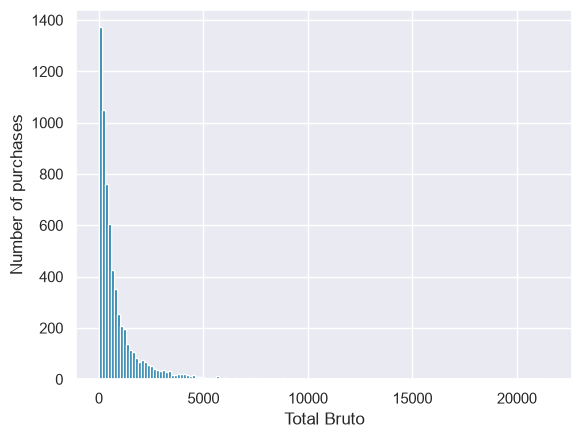

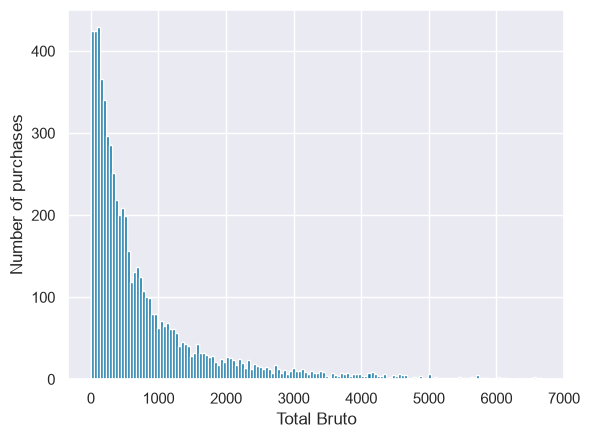

In [499]:
histograms_one_column("Total Bruto", train_raw, True)

With these histograms, we can confirm what we already suspected in the describe(), why the mean and the median where so different, we see that most of the values of Total Bruto, happens in the purchases with the fewer Total Bruto, but because there are some purchases with so big Total Bruto, our mean increases a lot. Even though that we detect a great asimetry in the histogram, we will not transorm anything at the moment

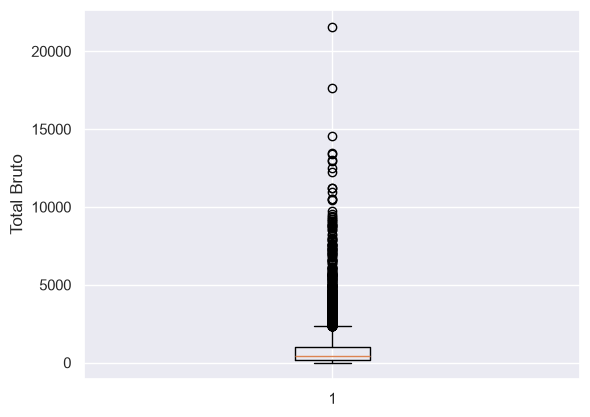

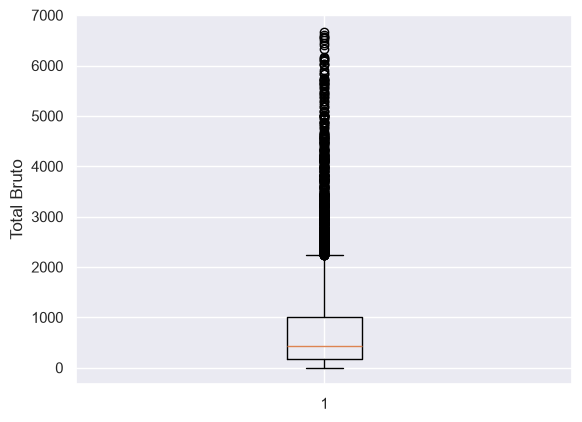

In [502]:
boxplot_one_column("Total Bruto", train_raw, True)

In [501]:
outliers_one_column("Total Bruto", train_raw)

Upper bound: 2328.14
Lower bound: -1115.70
Number of upper outliers: 584
Number of lower outliers: 0
Total number of outliers: 584
Percentatge of outliers in our data: 8.94%


With this analysis we can confirm what we did know before, we have the outliers in the upper part, as the most of the records are in the lower side, we have a count of 584 outliers, taht represent a 8.94% of the data, later on we will decide how to deal with them, at the moment we just flagged it


### Total a Pagar

In [613]:
descrive_monetary("Total a Pagar", train_raw)

Total a Pagar describe:
count     6469.00
mean       925.56
std       1335.00
min          0.93
25%        188.92
50%        476.74
75%       1087.67
max      22297.21
Name: Total a Pagar, dtype: float64

Missing values: 65

Unique values: 6122

Zero values: 0

Negative values: 0

Total a Pagar top 10 maximum:
          customer_id  Total a Pagar
ID                                  
10001077       227020       22297.21
10003479       227020       18146.78
10005415       755628       17257.99
10003822       227020       14433.41
10004393       588588       12961.99
10006444       864223       12905.74
10006123       227020       11461.94
10004243       781977       11457.01
10003225       755628       11250.72
10007062       942149       11031.74

The top 10 represent the: 2.39% of the column Total a Pagar


At the moment, we can see what we already knew, we have 65 NaNs that are from the 65 records that has no information, they just report the ID, customer_id and purchase_date, looking at the descrive, we can expect to have very similar plots from Total Bruto, as we have a much bigger mean than median, and the records will concentrate at the lower end. We also have checked if it's a similar list the top 10 of total a pagar and total bruto, and 5 of the purchases are in both of the top 10. We will not flagged any issue, as it's normal that both lists are similar, but changes can happen, as it may vary because of fields like Total Liquido, Total Imp_, Total Portes, Total Desc_ Global, Total Desc_ Linha...

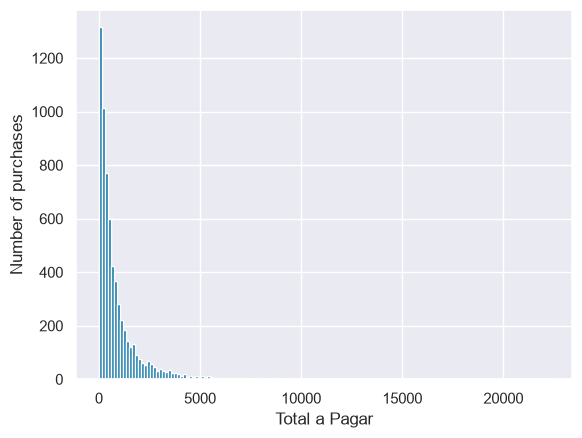

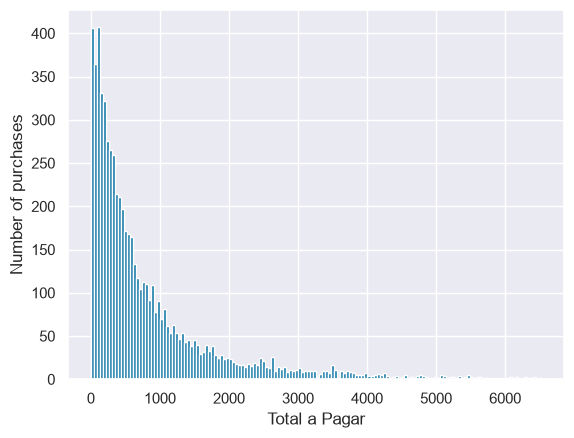

In [504]:
histograms_one_column("Total a Pagar", train_raw, True)

With these histograms, we can confirm what we already suspected in the describe(), why the mean and the median where so different, we see that most of the values of Total a Pagar, happens in the purchases with the fewer Total a Pagar, but because there are some purchases with so big Total a pagar, our mean increases a lot. Even though that we detect a great asimetry in the histogram, we will not transorm anything at the moment. Follows a very similar pattern as Total Bruto

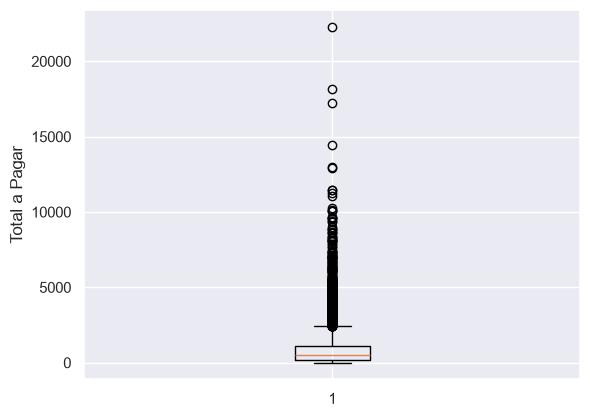

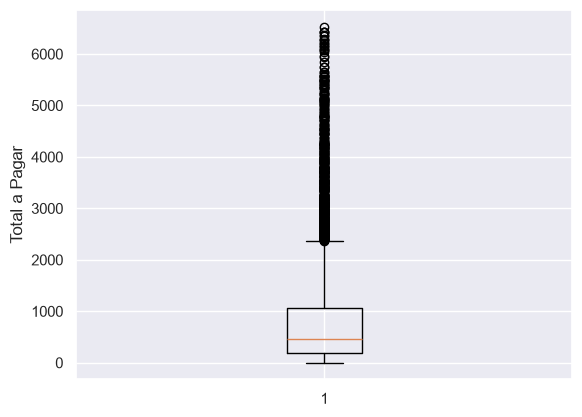

In [505]:
boxplot_one_column("Total a Pagar", train_raw, filter_data = True)

In [506]:
outliers_one_column("Total a Pagar", train_raw)

Upper bound: 2435.80
Lower bound: -1159.21
Number of upper outliers: 592
Number of lower outliers: 0
Total number of outliers: 592
Percentatge of outliers in our data: 9.06%


With this analysis we can confirm what we did know before, we have the outliers in the upper part, as the most of the records are in the lower side, we have a count of 592 outliers, taht represent a 9.06% of the data, later on we will decide how to deal with them, at the moment we just flagged it

### Total Liquido

In [614]:
descrive_monetary("Total Liquido", train_raw)

Total Liquido describe:
count     6469.00
mean       773.34
std       1136.36
min          0.76
25%        154.38
50%        389.91
75%        903.37
max      18127.81
Name: Total Liquido, dtype: float64

Missing values: 65

Unique values: 6093

Zero values: 0

Negative values: 0

Total Liquido top 10 maximum:
          customer_id  Total Liquido
ID                                  
10001077       227020       18127.81
10003479       227020       14753.48
10005415       755628       14030.89
10003822       227020       11734.48
10004393       588588       10538.20
10006444       864223       10492.47
10005016       807493       10082.56
10007062       942149        9762.60
10003996       807493        9576.98
10006123       227020        9318.65

The top 10 represent the: 2.37% of the column Total Liquido


As we have being seeing in the other Total fields, it seems that is going to be very right skweded histogram, we see that there's a lot of difference between the mean and the median (even though it's less than the other Totals that we have being seeing). Also, we see that there are common purchases Total a Pagar and Total Bruto.

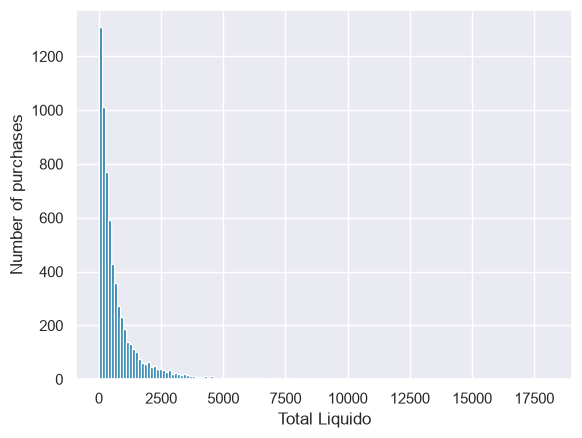

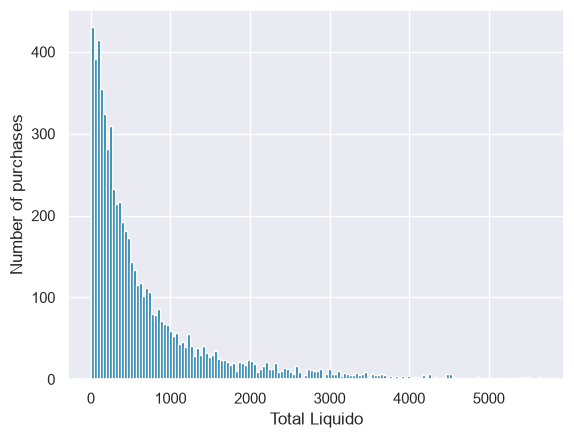

In [390]:
histograms_one_column("Total Liquido", train_raw, True)

With these histograms, we can confirm what we already suspected in the describe(), why the mean and the median where so different, we see that most of the values of Total Liquido, happens in the purchases with the fewer Total Liquido, but because there are some purchases with so big Total Liquido, our mean increases a lot. Even though that we detect a great asimetry in the histogram, we will not transorm anything at the moment. Follows a very similar pattern as Total Bruto

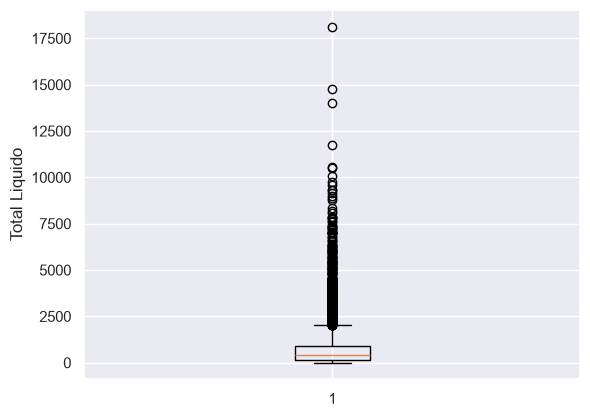

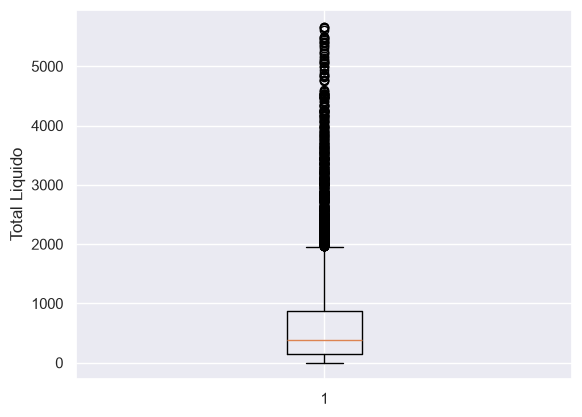

In [413]:
boxplot_one_column("Total Liquido", train_raw, filter_data = True)

In [507]:
outliers_one_column("Total Liquido", train_raw)

Upper bound: 2026.86
Lower bound: -969.11
Number of upper outliers: 587
Number of lower outliers: 0
Total number of outliers: 587
Percentatge of outliers in our data: 8.98%


With this analysis we can confirm what we did know before, we have the outliers in the upper part, as the most of the records are in the lower side, we have a count of 587 outliers, taht represent a 8.98% of the data, later on we will decide how to deal with them, at the moment we just flagged it

### Total Imp_ 

In [615]:
descrive_monetary("Total Imp_", train_raw)

Total Imp_ describe:
count    6469.00
mean      152.22
std       225.26
min         0.00
25%        29.93
50%        79.74
75%       184.84
max      4169.40
Name: Total Imp_, dtype: float64

Missing values: 65

Unique values: 5407

Zero values: 213

Negative values: 0

Total Imp_ top 10 maximum:
          customer_id  Total Imp_
ID                               
10001077       227020     4169.40
10003479       227020     3393.30
10005415       755628     3227.10
10003822       227020     2698.93
10004393       588588     2423.79
10006444       864223     2413.27
10006123       227020     2143.29
10004243       781977     2142.38
10003225       755628     2103.79
10006504       227020     1925.46

The top 10 represent the: 2.71% of the column Total Imp_


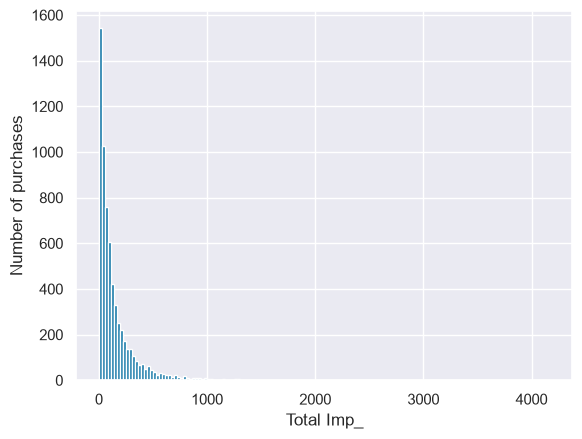

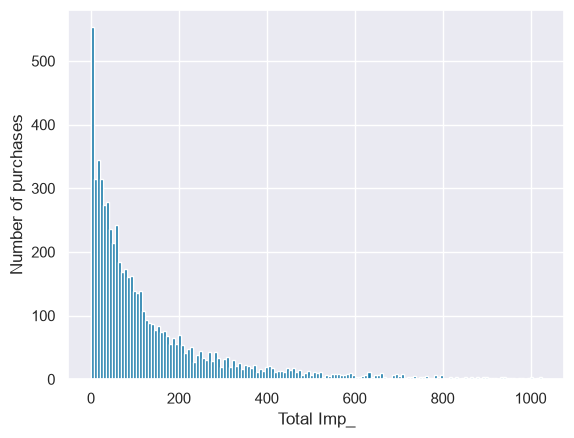

In [509]:
histograms_one_column("Total Imp_", train_raw, True)

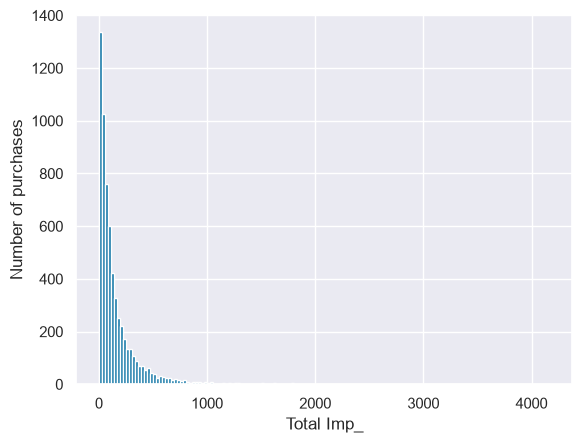

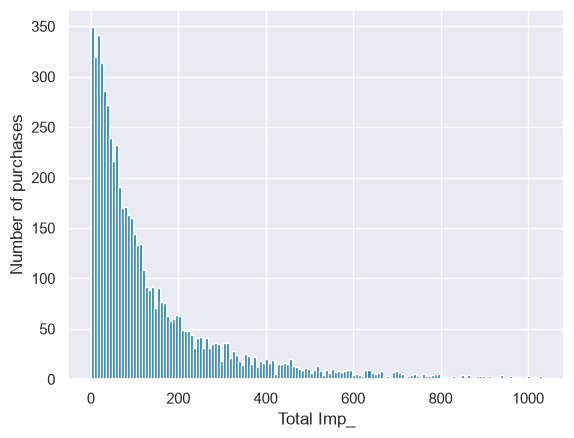

In [723]:
histograms_one_column_excluding_zeros_negative("Total Imp_", train_raw, True)

A partir de ahora no hago comparar los totales, al final, haré las comprovaciones de los top 10, para ver cuales son más comunes + pequeña explicacion


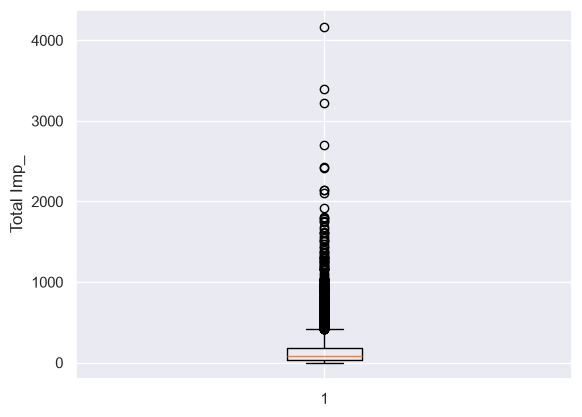

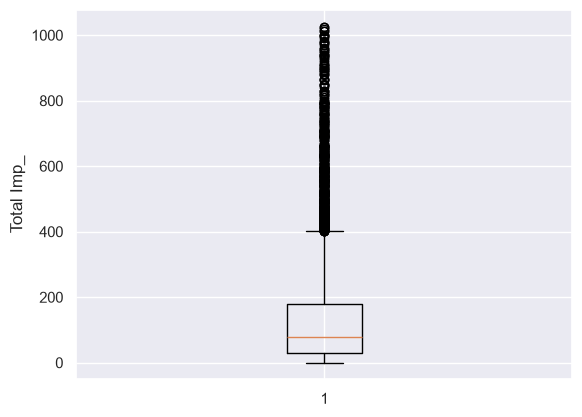

In [511]:
boxplot_one_column("Total Imp_", train_raw, filter_data = True)

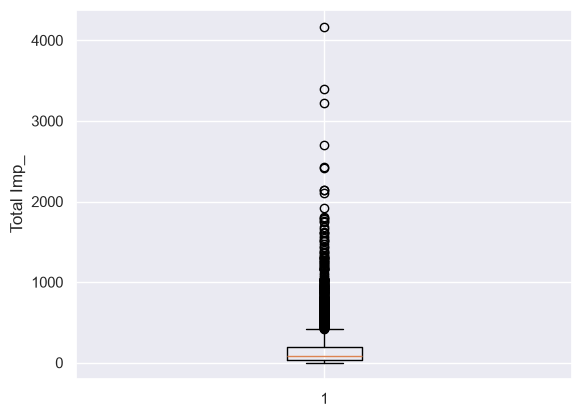

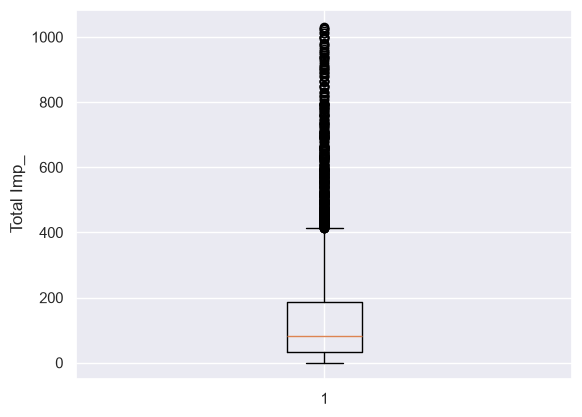

In [741]:
boxplot_one_column_excluding_zeros_negative("Total Imp_", train_raw, filter_data = True)

In [513]:
outliers_one_column("Total Imp_", train_raw)

Upper bound: 417.21
Lower bound: -202.44
Number of upper outliers: 533
Number of lower outliers: 0
Total number of outliers: 533
Percentatge of outliers in our data: 8.16%


### Total Portes

In [616]:
descrive_monetary("Total Portes", train_raw)

Total Portes describe:
count    6469.00
mean        1.15
std         5.84
min         0.00
25%         0.00
50%         0.00
75%         0.00
max       181.06
Name: Total Portes, dtype: float64

Missing values: 65

Unique values: 215

Zero values: 5416

Negative values: 0

Total Portes top 10 maximum:
          customer_id  Total Portes
ID                                 
10006514       849644        181.06
10000776       717242        159.73
10005170       630646        150.00
10005654       117553        150.00
10003236       761979        142.00
10002586       400536        140.00
10000465       816330        100.00
10002107       400536        100.00
10001065       744659         69.00
10001922       717242         65.00

The top 10 represent the: 16.87% of the column Total Portes


mismos mnissings, ya se puede ver en el describe que más del 75% de los registros son 0, además, viendo que el 16.87% del total de portes viene solo de 10 registros, esto también nos dice mucho

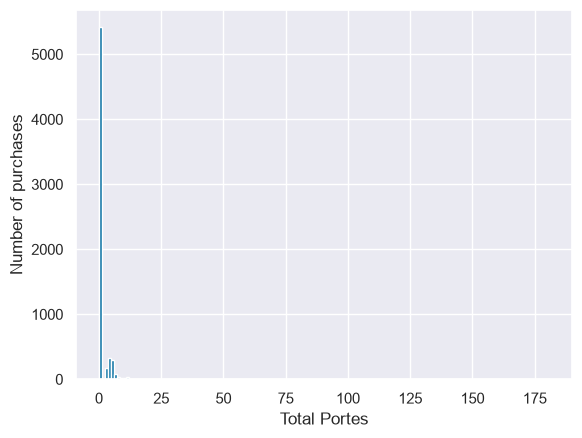

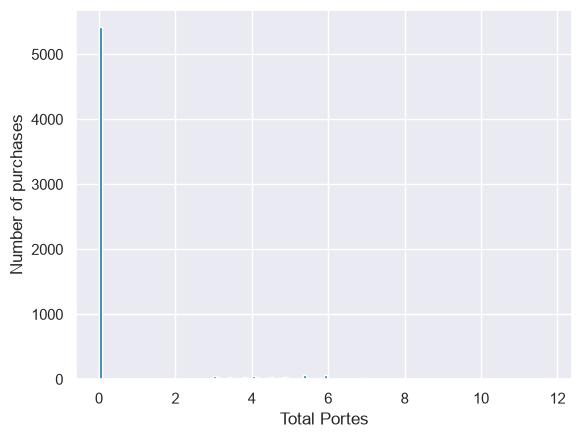

In [515]:
histograms_one_column("Total Portes", train_raw, True)

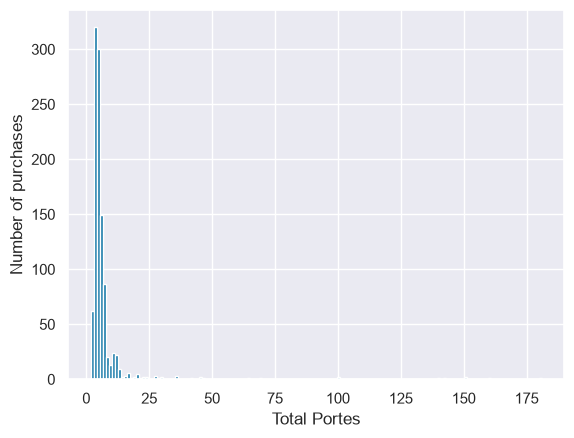

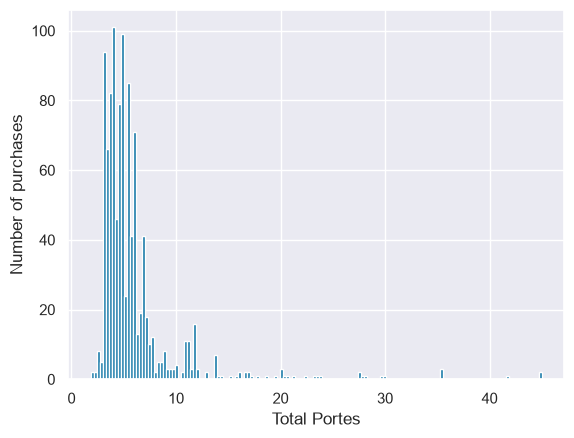

In [724]:
histograms_one_column_excluding_zeros_negative("Total Portes", train_raw, True)

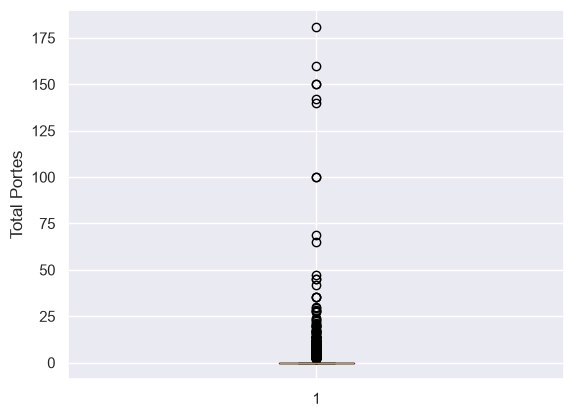

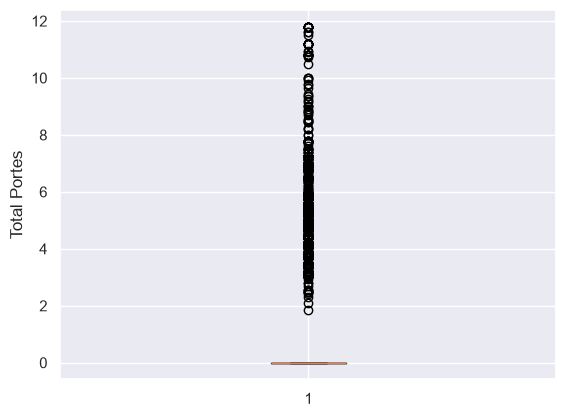

In [517]:
boxplot_one_column("Total Portes", train_raw, True)

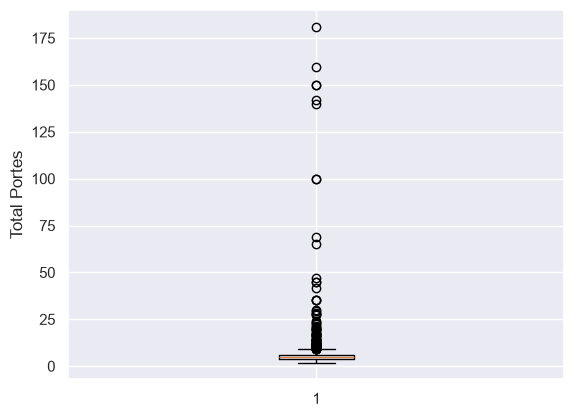

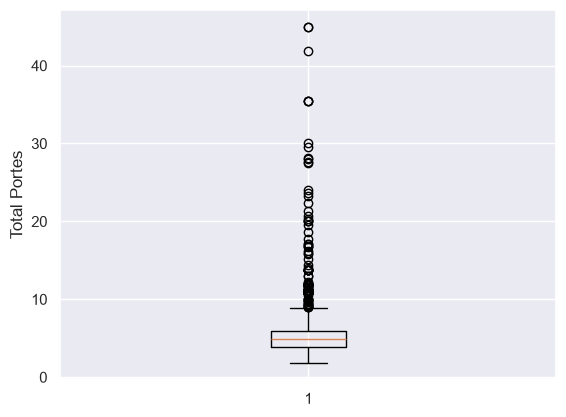

In [742]:
boxplot_one_column_excluding_zeros_negative("Total Portes", train_raw, True)

In [519]:
outliers_one_column("Total Portes", train_raw)

Upper bound: 0.00
Lower bound: 0.00
Number of upper outliers: 1053
Number of lower outliers: 0
Total number of outliers: 1053
Percentatge of outliers in our data: 16.12%


In [587]:
outliers_one_column_excluding_zeros("Total Portes", train_raw)

Upper bound: 9.04
Lower bound: 0.80
Number of upper outliers: 115
Number of lower outliers: 0
Total number of outliers: 115
Percentatge of outliers in our data: 1.76%


Later on we will decide what we do with this field, what we have seen here, is that most of the purchases are with 0 total portes, being every value that is no 0 an outlier

### Total Desc_ Global

In [617]:
descrive_monetary("Total Desc_ Global", train_raw)

Total Desc_ Global describe:
count    6469.00
mean        0.35
std         5.12
min         0.00
25%         0.00
50%         0.00
75%         0.00
max       218.49
Name: Total Desc_ Global, dtype: float64

Missing values: 65

Unique values: 109

Zero values: 6359

Negative values: 0

Total Desc_ Global top 10 maximum:
          customer_id  Total Desc_ Global
ID                                       
10007082       113110              218.49
10004096       529466              184.40
10001765       529466              135.72
10000690       952237              115.88
10002919       473647               97.14
10005523       666120               89.62
10002808       667800               65.68
10006205       248016               57.62
10003711       847373               56.12
10007040       181764               53.84

The top 10 represent the: 47.47% of the column Total Desc_ Global


Más o menos lo mismo que en portes, pero hasta más, siendo el 47.47% de las compras del top 10!

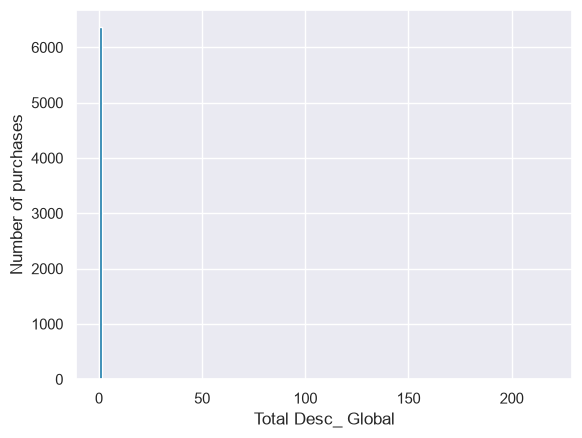

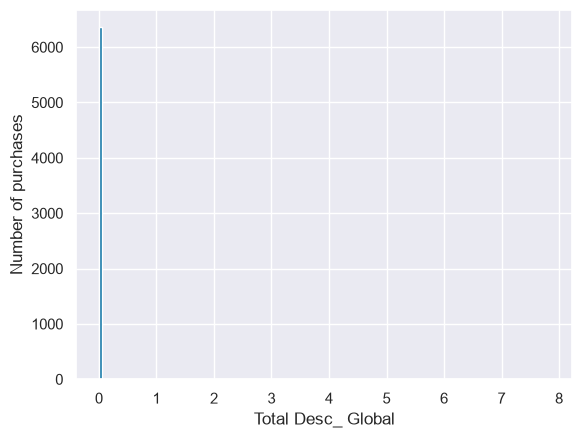

In [521]:
histograms_one_column("Total Desc_ Global", train_raw, True)

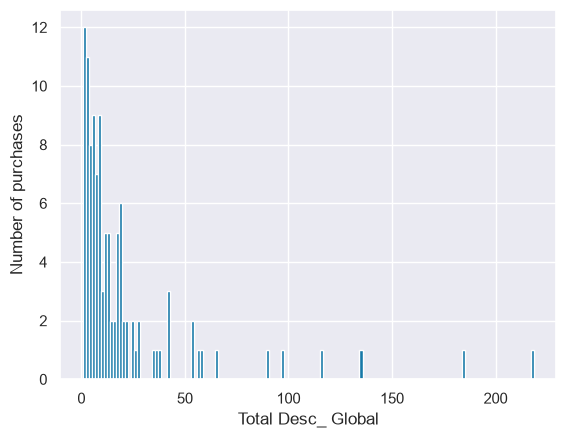

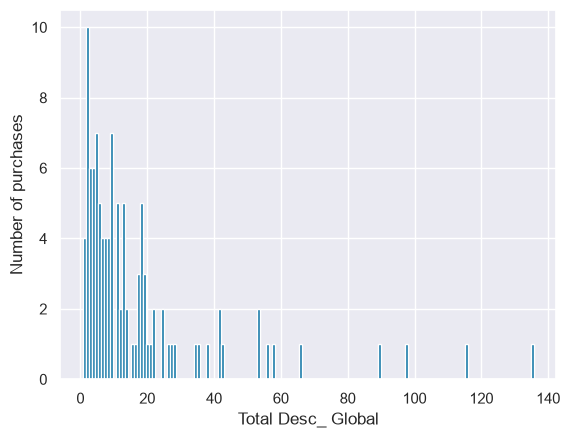

In [725]:
histograms_one_column_excluding_zeros_negative("Total Desc_ Global", train_raw, True)

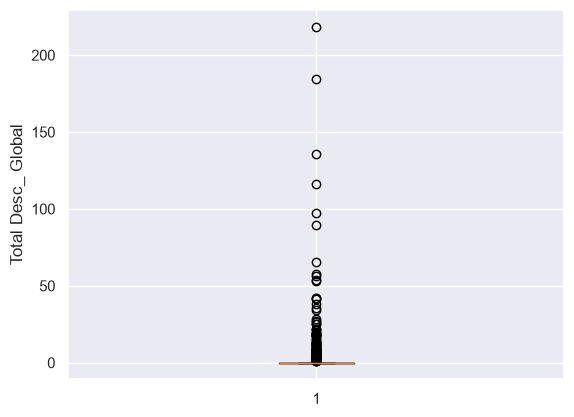

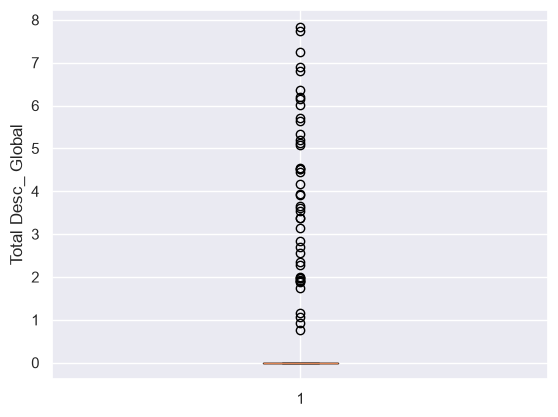

In [523]:
boxplot_one_column("Total Desc_ Global", train_raw, True)

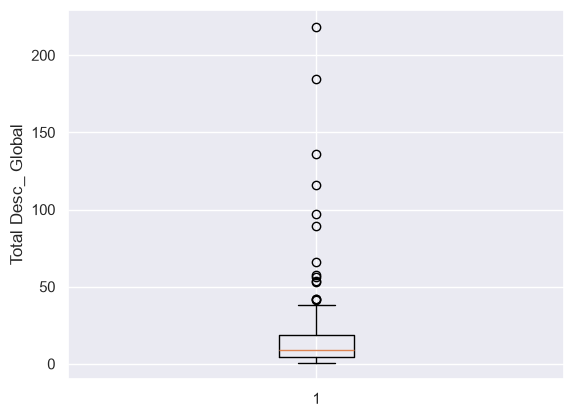

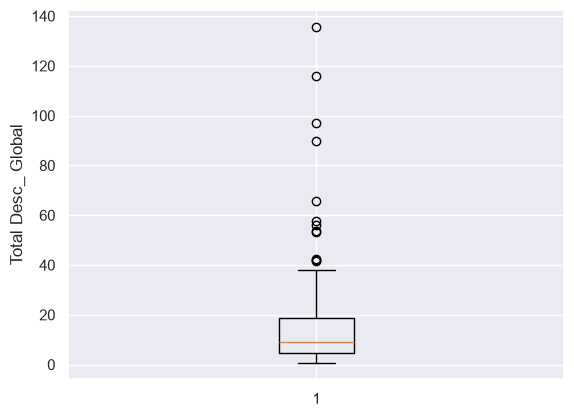

In [743]:
boxplot_one_column_excluding_zeros_negative("Total Desc_ Global", train_raw, True)

In [525]:
outliers_one_column("Total Desc_ Global", train_raw)

Upper bound: 0.00
Lower bound: 0.00
Number of upper outliers: 110
Number of lower outliers: 0
Total number of outliers: 110
Percentatge of outliers in our data: 1.68%


In [588]:
outliers_one_column_excluding_zeros("Total Desc_ Global", train_raw)

Upper bound: 40.48
Lower bound: -17.05
Number of upper outliers: 14
Number of lower outliers: 0
Total number of outliers: 14
Percentatge of outliers in our data: 0.21%


Later on we will decide what we do with this field, what we have seen here, is that most of the purchases are with 0 total Desc_ Global, being every value that is no 0 an outlier

### Total Desc_ Linha

In [618]:
descrive_monetary("Total Desc_ Linha", train_raw)

Total Desc_ Linha describe:
count    6469.00
mean      112.47
std       289.99
min         0.00
25%         0.00
50%        13.13
75%        92.28
max      4103.44
Name: Total Desc_ Linha, dtype: float64

Missing values: 65

Unique values: 3520

Zero values: 2441

Negative values: 0

Total Desc_ Linha top 10 maximum:
          customer_id  Total Desc_ Linha
ID                                      
10001172       531725            4103.44
10003996       807493            3794.51
10002107       400536            3720.00
10004460       770941            3704.89
10004243       781977            3622.51
10001077       227020            3450.47
10002779       531725            3434.18
10006514       849644            3386.82
10002580       531725            3235.74
10002416       531725            3193.40

The top 10 represent the: 4.90% of the column Total Desc_ Linha


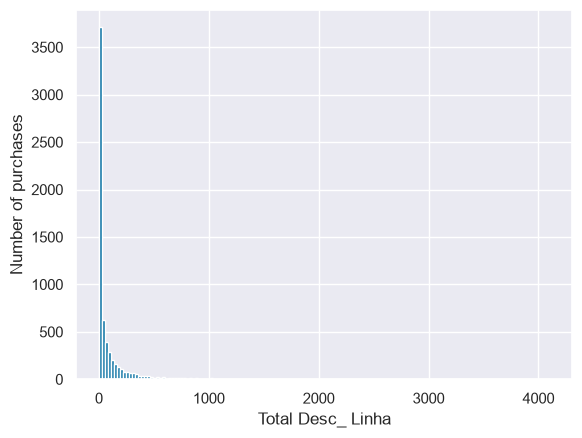

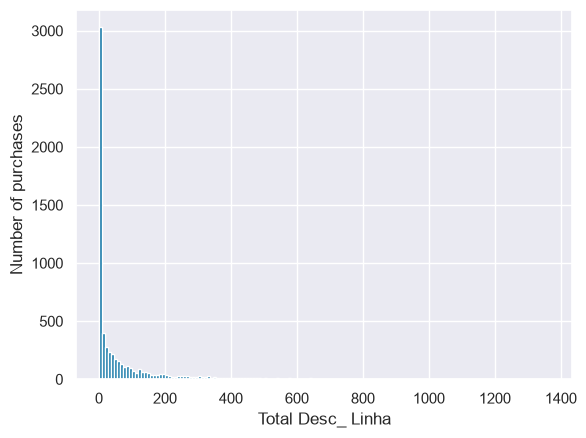

In [527]:
histograms_one_column("Total Desc_ Linha", train_raw, True)

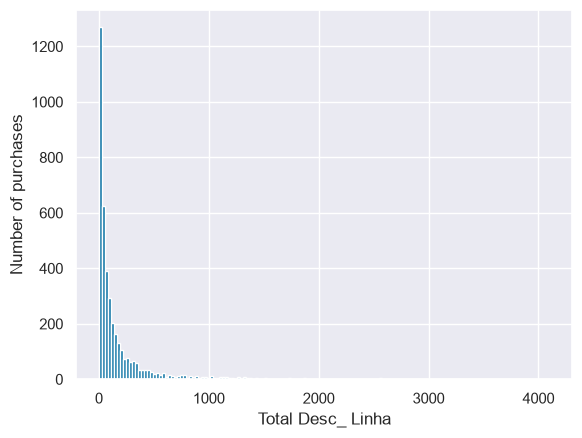

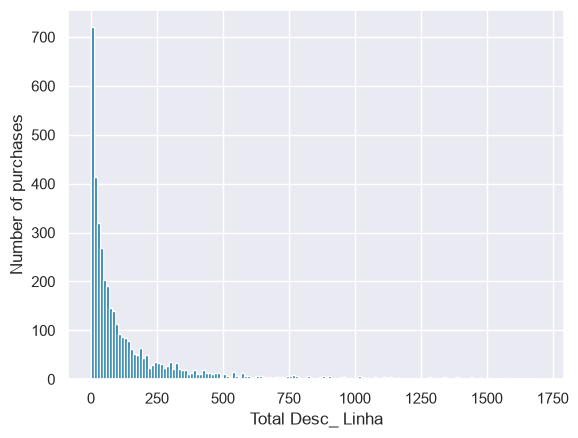

In [726]:
histograms_one_column_excluding_zeros_negative("Total Desc_ Linha", train_raw, True)

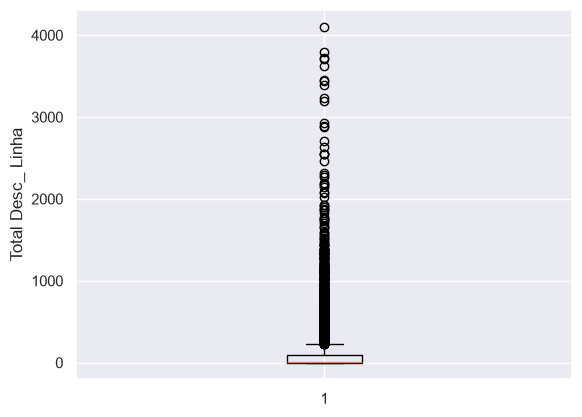

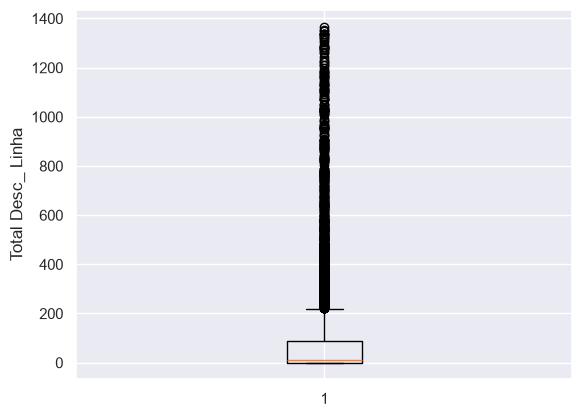

In [529]:
boxplot_one_column("Total Desc_ Linha", train_raw, True)

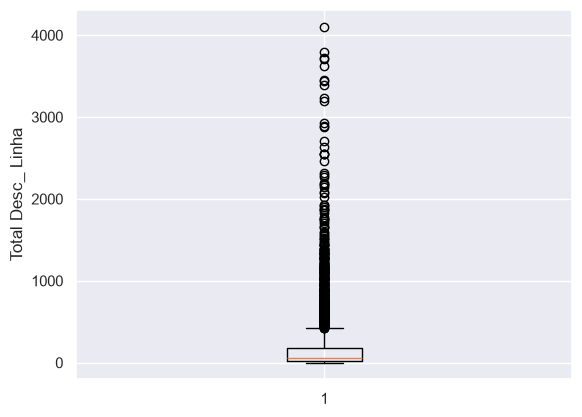

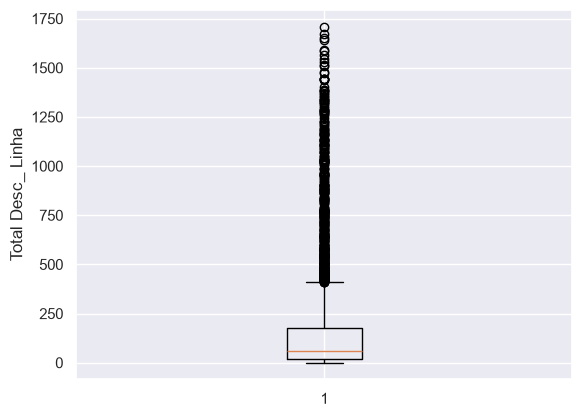

In [744]:
boxplot_one_column_excluding_zeros_negative("Total Desc_ Linha", train_raw, True)

In [531]:
outliers_one_column("Total Desc_ Linha", train_raw)

Upper bound: 230.70
Lower bound: -138.42
Number of upper outliers: 822
Number of lower outliers: 0
Total number of outliers: 822
Percentatge of outliers in our data: 12.58%


In [589]:
outliers_one_column_excluding_zeros("Total Desc_ Linha", train_raw)

Upper bound: 427.88
Lower bound: -226.42
Number of upper outliers: 426
Number of lower outliers: 0
Total number of outliers: 426
Percentatge of outliers in our data: 6.52%


### N_ Detalhes

In [619]:
descrive_monetary("N_ Detalhes", train_raw)

N_ Detalhes describe:
count    6469.00
mean       21.52
std        27.71
min         1.00
25%         4.00
50%        11.00
75%        29.00
max       423.00
Name: N_ Detalhes, dtype: float64

Missing values: 65

Unique values: 171

Zero values: 0

Negative values: 0

N_ Detalhes top 10 maximum:
          customer_id  N_ Detalhes
ID                                
10006855       488020        423.0
10002061       488020        309.0
10001077       227020        268.0
10003996       807493        243.0
10002202       229396        233.0
10005415       755628        221.0
10003479       227020        199.0
10003698       488020        199.0
10005016       807493        198.0
10007219       508217        197.0

The top 10 represent the: 1.79% of the column N_ Detalhes


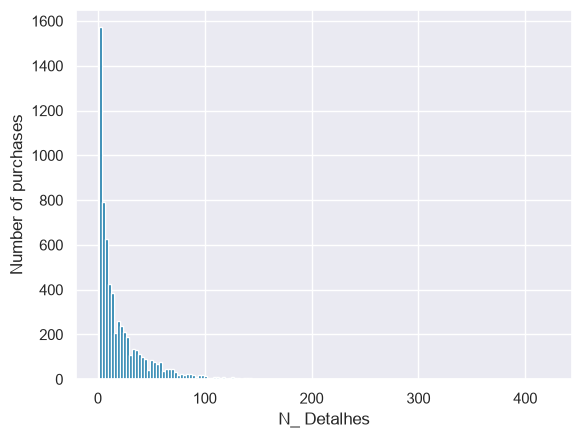

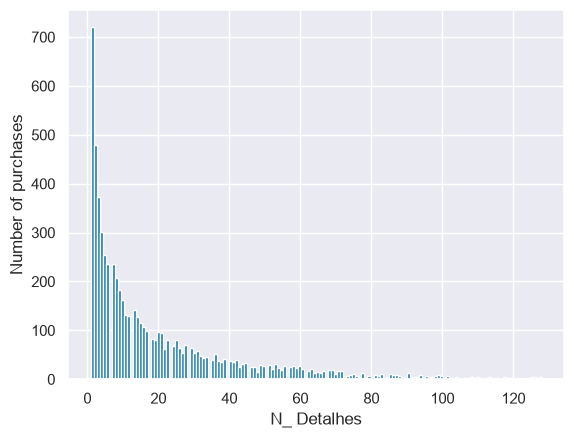

In [533]:
histograms_one_column("N_ Detalhes", train_raw, True)

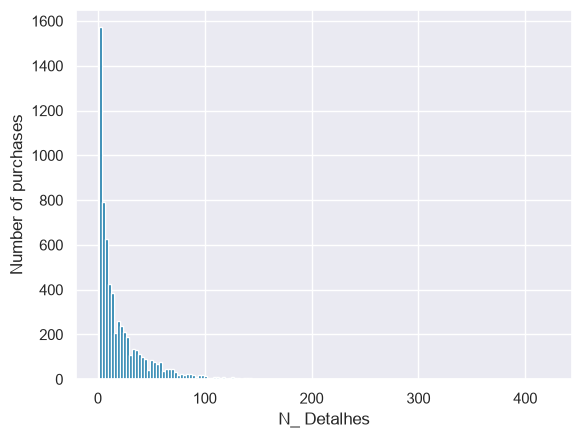

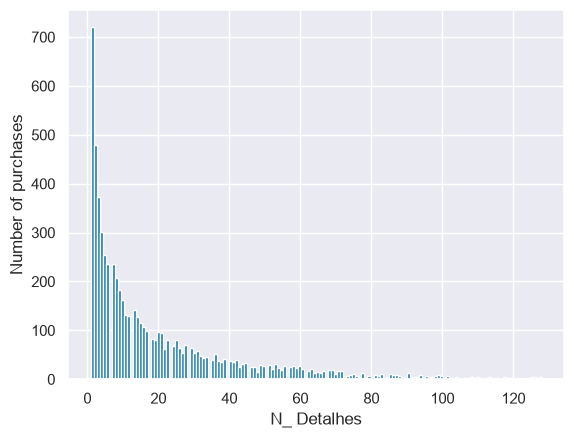

In [727]:
histograms_one_column_excluding_zeros_negative("N_ Detalhes", train_raw, True)

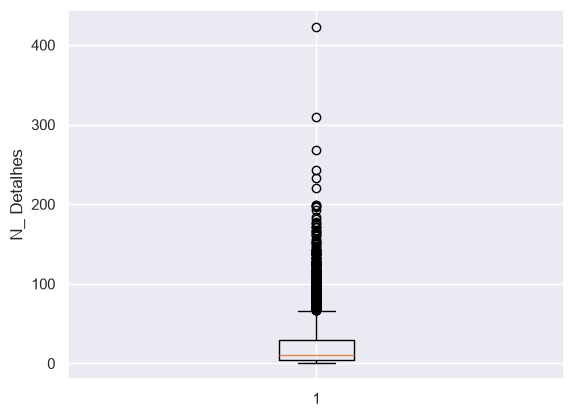

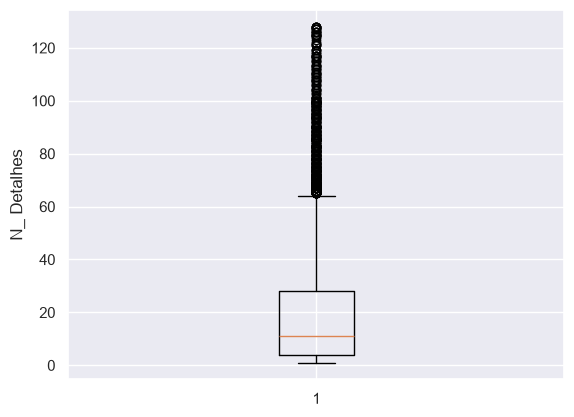

In [535]:
boxplot_one_column("N_ Detalhes", train_raw, True)

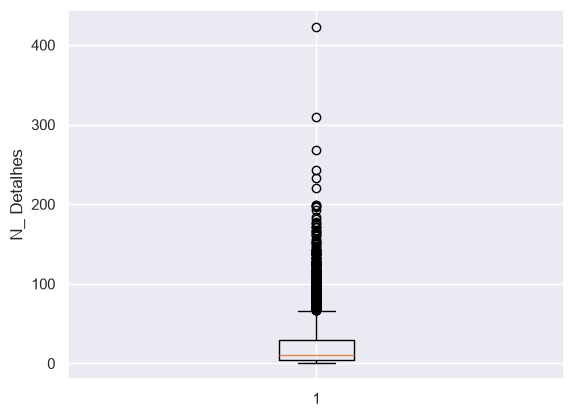

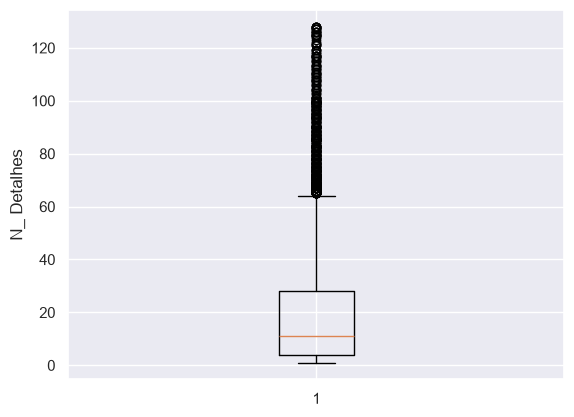

In [745]:
boxplot_one_column_excluding_zeros_negative("N_ Detalhes", train_raw, True)

In [538]:
outliers_one_column("N_ Detalhes", train_raw)

Upper bound: 66.50
Lower bound: -33.50
Number of upper outliers: 436
Number of lower outliers: 0
Total number of outliers: 436
Percentatge of outliers in our data: 6.67%


In [590]:
outliers_one_column_excluding_zeros("N_ Detalhes", train_raw)

Upper bound: 66.50
Lower bound: -33.50
Number of upper outliers: 436
Number of lower outliers: 0
Total number of outliers: 436
Percentatge of outliers in our data: 6.67%


### Custo

In [620]:
descrive_monetary("Custo", train_raw)

Custo describe:
count    6469.00
mean      328.17
std       519.51
min         0.00
25%        49.05
50%       152.54
75%       396.06
max      7427.40
Name: Custo, dtype: float64

Missing values: 65

Unique values: 5740

Zero values: 486

Negative values: 0

Custo top 10 maximum:
          customer_id        Custo
ID                                
10005415       755628  7427.400583
10001077       227020  7052.209816
10006444       864223  6972.197732
10004243       781977  6897.230661
10005853       942149  6111.300000
10003479       227020  5368.567443
10004681       942149  5305.200000
10005875       864223  4924.760864
10001024       781977  4854.694749
10003225       755628  4756.185354

The top 10 represent the: 2.81% of the column Custo


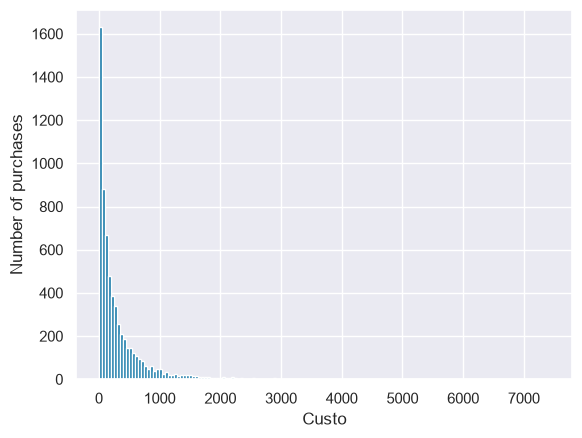

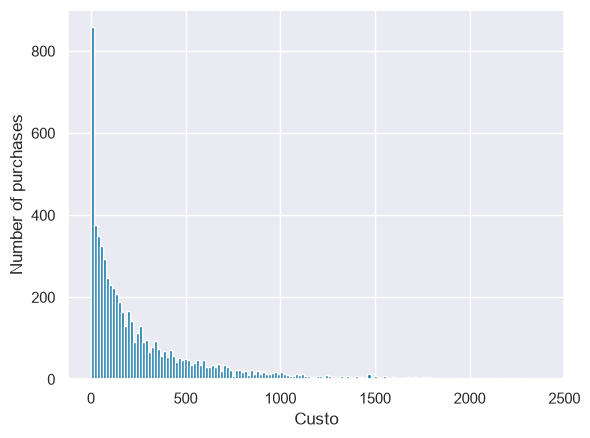

In [540]:
histograms_one_column("Custo", train_raw, True)

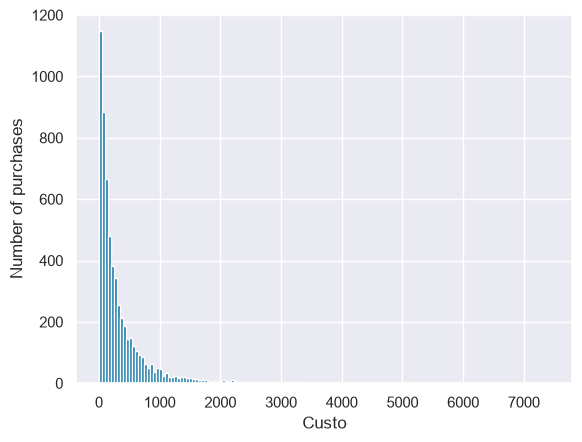

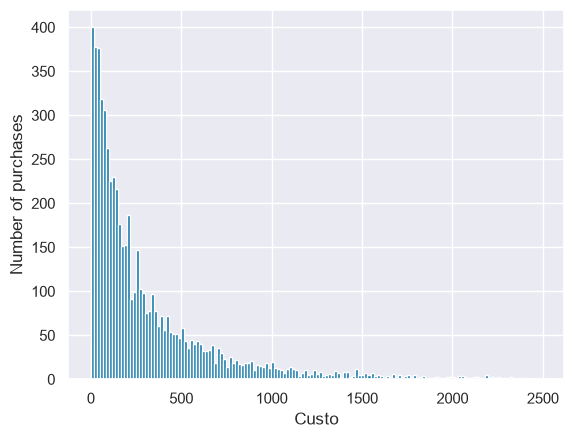

In [728]:
histograms_one_column_excluding_zeros_negative("Custo", train_raw, True)

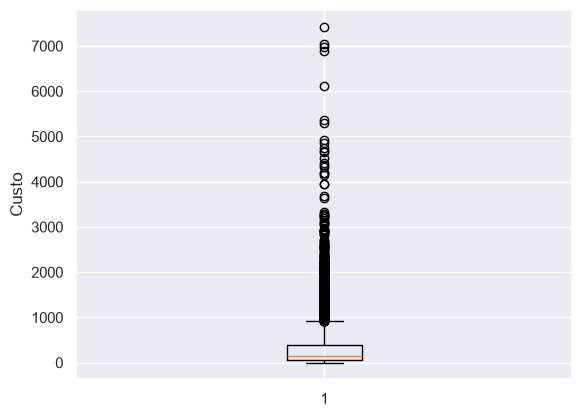

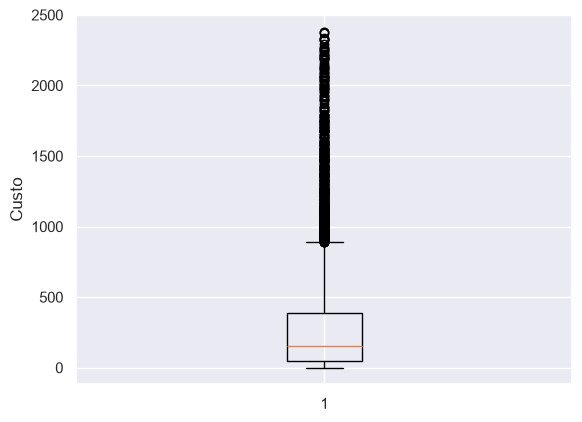

In [542]:
boxplot_one_column("Custo", train_raw, True)

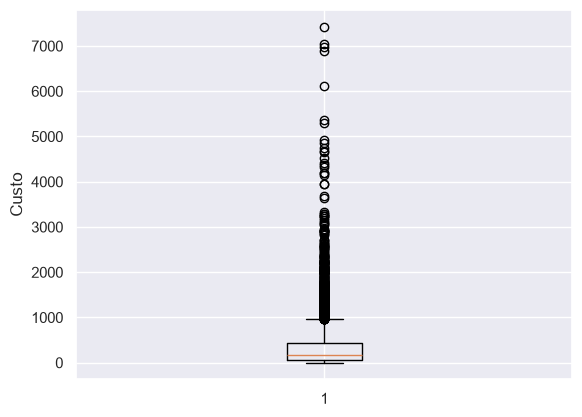

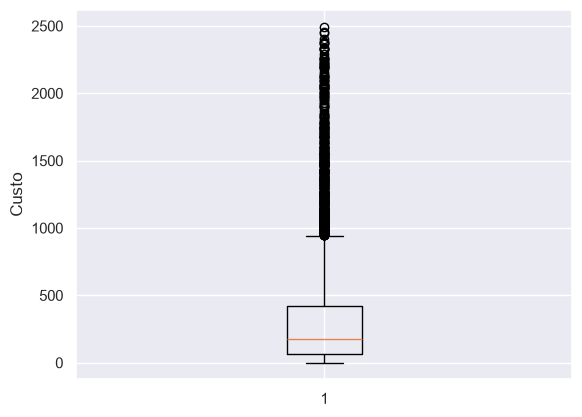

In [746]:
boxplot_one_column_excluding_zeros_negative("Custo", train_raw, True)

In [544]:
outliers_one_column("Custo", train_raw)

Upper bound: 916.58
Lower bound: -471.47
Number of upper outliers: 539
Number of lower outliers: 0
Total number of outliers: 539
Percentatge of outliers in our data: 8.25%


In [591]:
outliers_one_column_excluding_zeros("Custo", train_raw)

Upper bound: 966.73
Lower bound: -470.86
Number of upper outliers: 494
Number of lower outliers: 0
Total number of outliers: 494
Percentatge of outliers in our data: 7.56%


### prior_total_spend

In [621]:
descrive_monetary("prior_total_spend", train_raw)

prior_total_spend describe:
count      6469.00
mean      18908.35
std       31130.87
min           0.00
25%        1505.55
50%        6754.31
75%       21642.32
max      247865.10
Name: prior_total_spend, dtype: float64

Missing values: 65

Unique values: 5864

Zero values: 603

Negative values: 0

prior_total_spend top 10 maximum:
          customer_id  prior_total_spend
ID                                      
10006088       227020          247865.10
10004615       227020          247855.26
10007284       227020          243617.08
10001496       227020          235767.16
10005583       942149          230354.06
10003976       942149          227088.13
10001620       942149          223060.81
10002427       942149          220769.51
10003479       227020          217620.38
10000259       227020          216669.81

The top 10 represent the: 1.89% of the column prior_total_spend


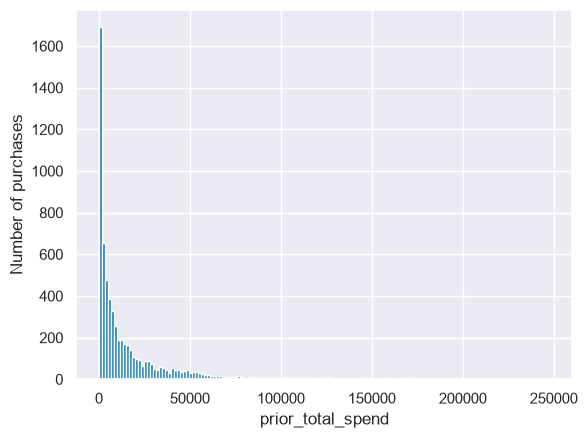

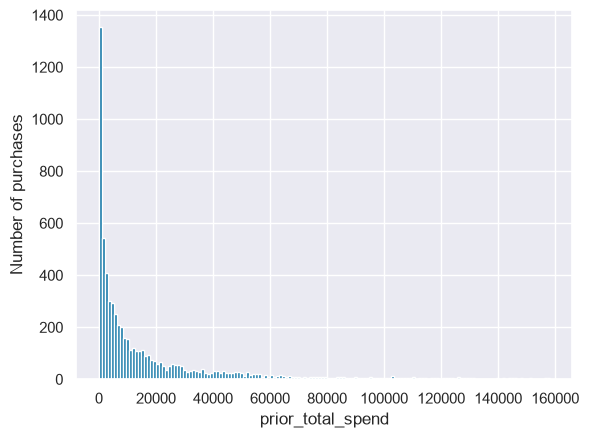

In [546]:
histograms_one_column("prior_total_spend", train_raw, True)

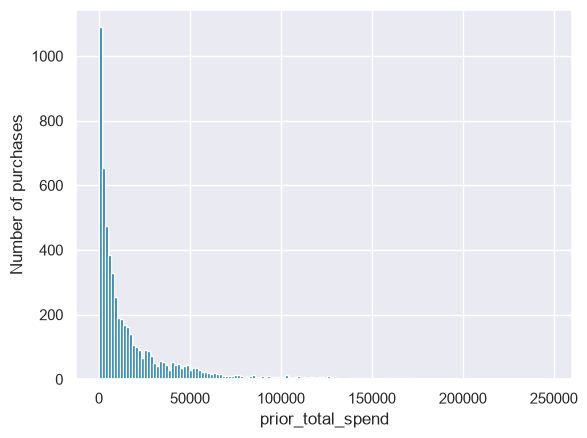

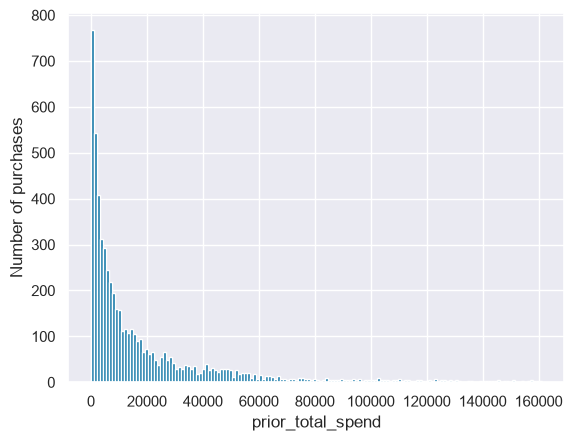

In [729]:
histograms_one_column_excluding_zeros_negative("prior_total_spend", train_raw, True)

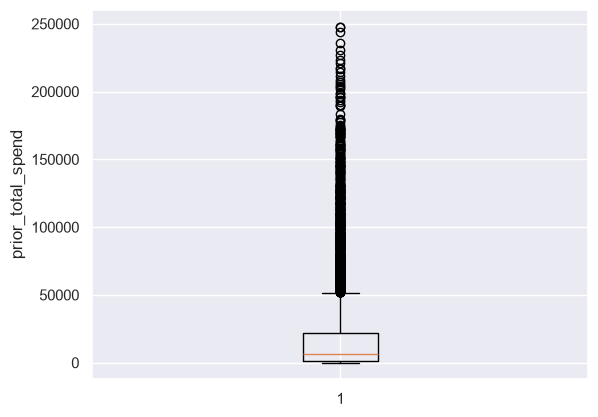

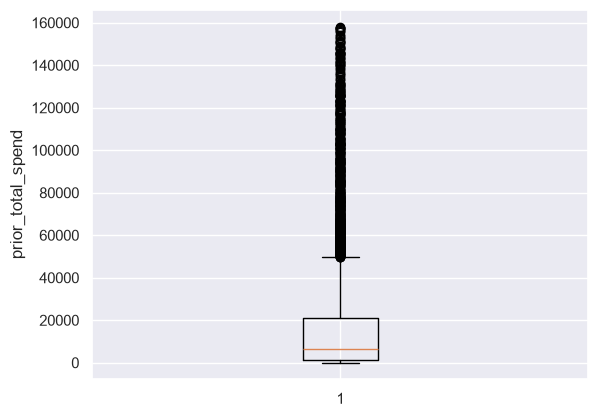

In [548]:
boxplot_one_column("prior_total_spend", train_raw, True)

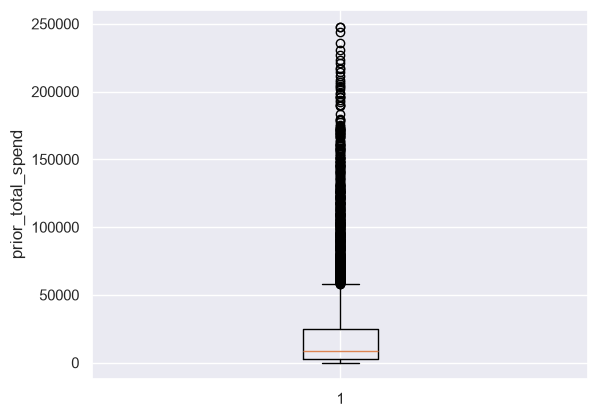

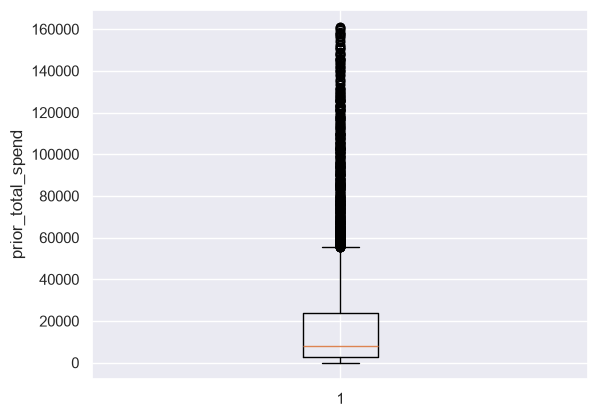

In [747]:
boxplot_one_column_excluding_zeros_negative("prior_total_spend", train_raw, True)

In [550]:
outliers_one_column("prior_total_spend", train_raw)

Upper bound: 51847.47
Lower bound: -28699.60
Number of upper outliers: 642
Number of lower outliers: 0
Total number of outliers: 642
Percentatge of outliers in our data: 9.83%


In [592]:
outliers_one_column_excluding_zeros("prior_total_spend", train_raw)

Upper bound: 58307.22
Lower bound: -30906.80
Number of upper outliers: 522
Number of lower outliers: 0
Total number of outliers: 522
Percentatge of outliers in our data: 7.99%


### invoice_count_current_purchase

In [622]:
descrive_discrete("invoice_count_current_purchase", train_raw)

invoice_count_current_purchase describe:
count    6469.00
mean        1.07
std         0.31
min         1.00
25%         1.00
50%         1.00
75%         1.00
max         5.00
Name: invoice_count_current_purchase, dtype: float64

invoice_count_current_purchase missings:
65

invoice_count_current_purchase number of unique values: 5



,Count,Percentage:
invoice_count_current_purchase,,
1.0,6116,93.60
2.0,312,4.78
3.0,14,0.21
4.0,21,0.32
5.0,6,0.09
NaN,65,0.99


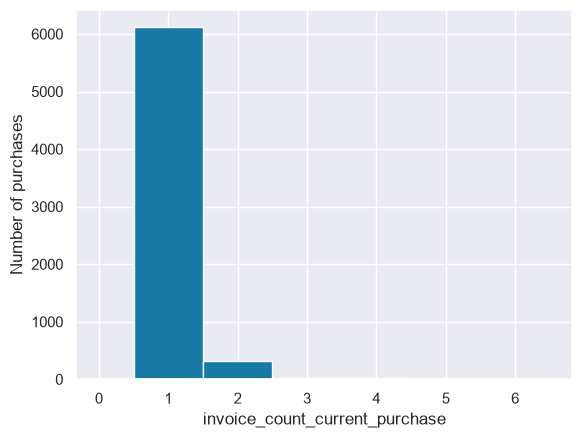

In [554]:
histograms_one_column("invoice_count_current_purchase", train_raw, False, bins = 6)

### purchase_count_90d

In [557]:
descrive_discrete("purchase_count_90d", train_raw)

purchase_count_90d describe:
count    6469.00
mean        1.63
std         2.98
min         0.00
25%         0.00
50%         1.00
75%         2.00
max        22.00
Name: purchase_count_90d, dtype: float64

purchase_count_90d missings:
65

purchase_count_90d number of unique values: 23



,Count,Percentage:
purchase_count_90d,,
0.0,2889,44.21
1.0,1714,26.23
2.0,787,12.04
3.0,328,5.02
4.0,149,2.28
5.0,100,1.53
6.0,81,1.24
7.0,88,1.35
8.0,57,0.87


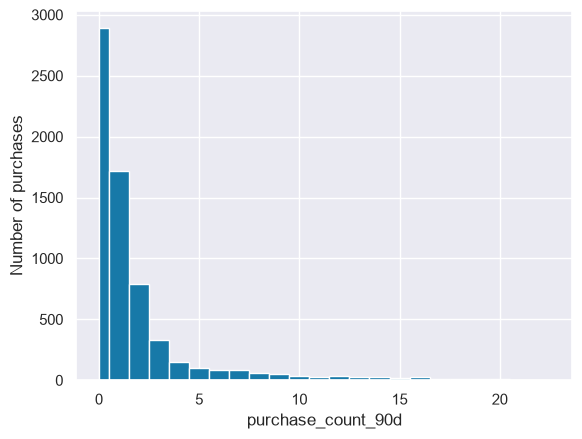

In [558]:
histograms_one_column("purchase_count_90d", train_raw, False, bins = 22)

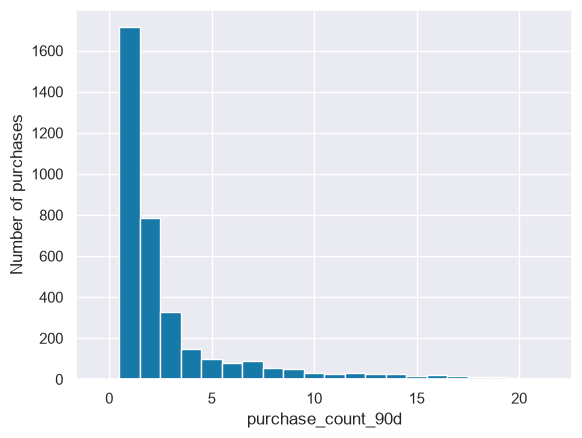

In [730]:
histograms_one_column_excluding_zeros_negative("purchase_count_90d", train_raw, False, bins = 22)

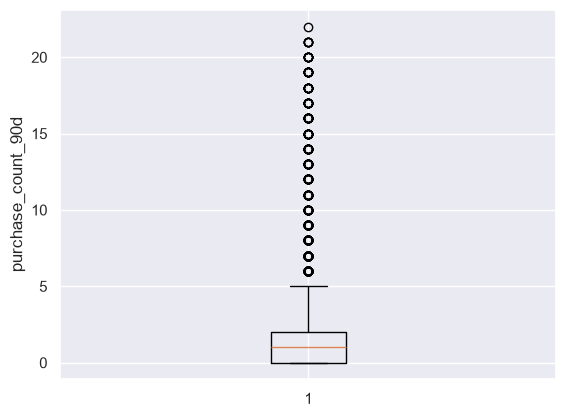

In [560]:
boxplot_one_column("purchase_count_90d", train_raw, False)

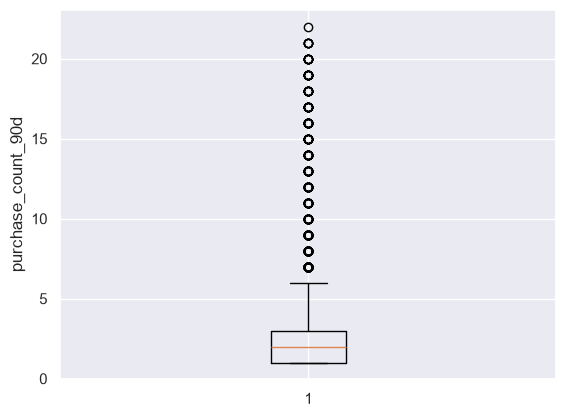

In [748]:
boxplot_one_column_excluding_zeros_negative("purchase_count_90d", train_raw, False)

Looking at the data, we find our usual 65 NaN records, also, we see that the mean is 1.63 and the median is 1, a strongly right skeked distribution, where the observations concentrate at low values, purchase in the 90 previous days, has 44.21% of the records being 0 and 82.48% have between 0 and 2 purchases. The maximum value is 22, which is a little wierd, going to purches every 4 days, but totally possible.

### purchase_count_180d

In [562]:
descrive_discrete("purchase_count_180d", train_raw)

purchase_count_180d describe:
count    6469.00
mean        3.37
std         5.46
min         0.00
25%         1.00
50%         2.00
75%         3.00
max        37.00
Name: purchase_count_180d, dtype: float64

purchase_count_180d missings:
65

purchase_count_180d number of unique values: 38



,Count,Percentage:
purchase_count_180d,,
0.0,1410,21.58
1.0,1591,24.35
2.0,1164,17.81
3.0,713,10.91
4.0,461,7.06
5.0,264,4.04
6.0,129,1.97
7.0,96,1.47
8.0,69,1.06


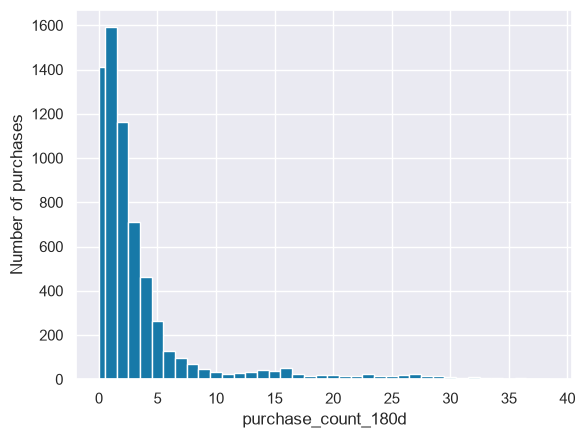

In [563]:
histograms_one_column("purchase_count_180d", train_raw, False, bins = 38)

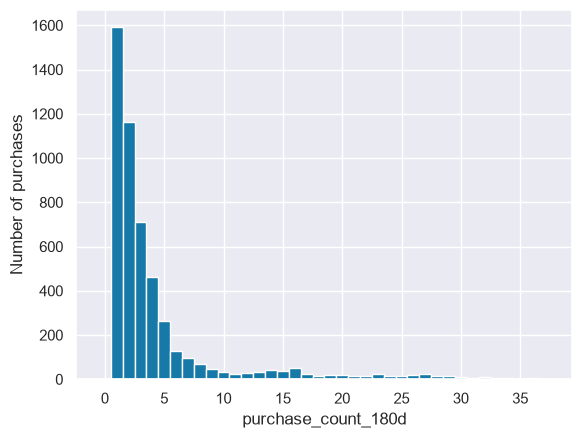

In [731]:
histograms_one_column_excluding_zeros_negative("purchase_count_180d", train_raw, False, bins = 38)

### purchase_count_365d

In [565]:
descrive_discrete("purchase_count_365d", train_raw)

purchase_count_365d describe:
count    6469.00
mean        6.56
std        10.33
min         0.00
25%         1.00
50%         3.00
75%         7.00
max        60.00
Name: purchase_count_365d, dtype: float64

purchase_count_365d missings:
65

purchase_count_365d number of unique values: 61



,Count,Percentage:
purchase_count_365d,,
0.0,843,12.90
1.0,789,12.08
2.0,845,12.93
3.0,785,12.01
4.0,667,10.21
...,...,...
57.0,10,0.15
58.0,8,0.12
59.0,3,0.05


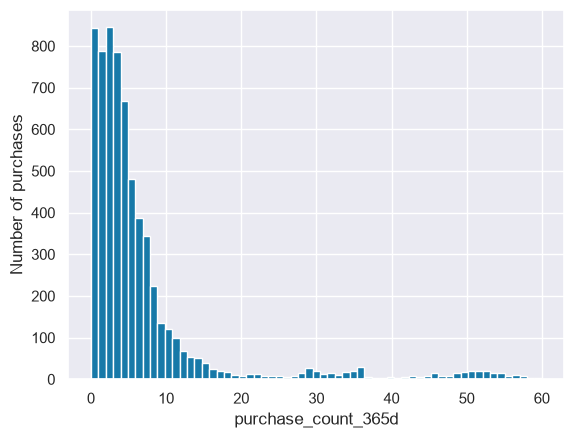

In [566]:
histograms_one_column("purchase_count_365d", train_raw, False, bins = 61)

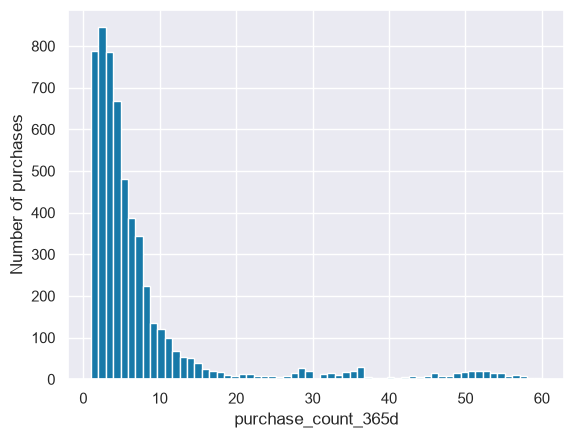

In [732]:
histograms_one_column_excluding_zeros_negative("purchase_count_365d", train_raw, False, bins = 61)

### spend_30d

In [623]:
descrive_monetary("spend_30d", train_raw)

spend_30d describe:
count     6469.00
mean       457.14
std       1191.23
min          0.00
25%          0.00
50%          0.00
75%        338.24
max      22297.21
Name: spend_30d, dtype: float64

Missing values: 65

Unique values: 2105

Zero values: 4342

Negative values: 0

spend_30d top 10 maximum:
          customer_id  spend_30d
ID                              
10001532       227020   22297.21
10005683       755628   17257.99
10004025       942149   16165.89
10006504       227020   13860.44
10005368       864223   11993.20
10000085       227020   11461.94
10000873       781977   11457.01
10004432       755628   11355.22
10007337       942149   11339.21
10002412       755628   11296.79

The top 10 represent the: 4.68% of the column spend_30d


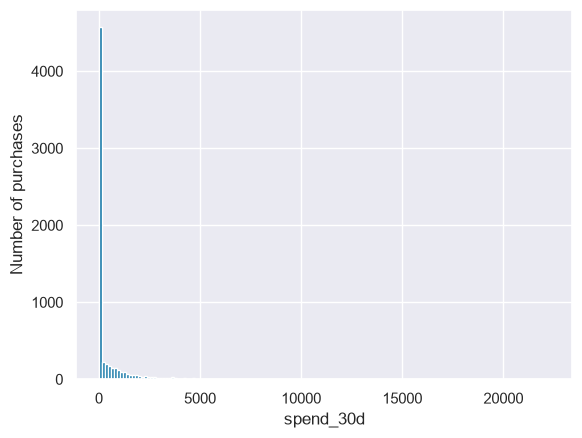

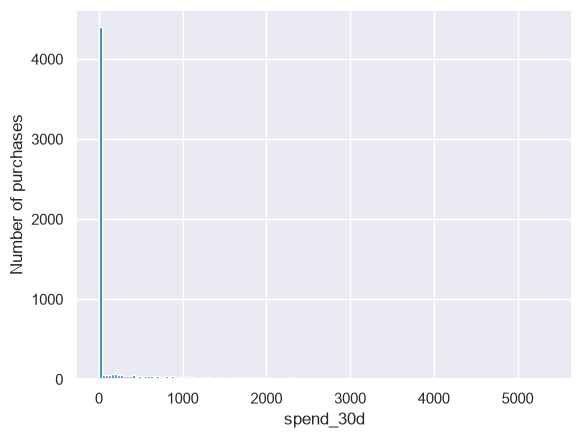

In [569]:
histograms_one_column("spend_30d", train_raw, True)

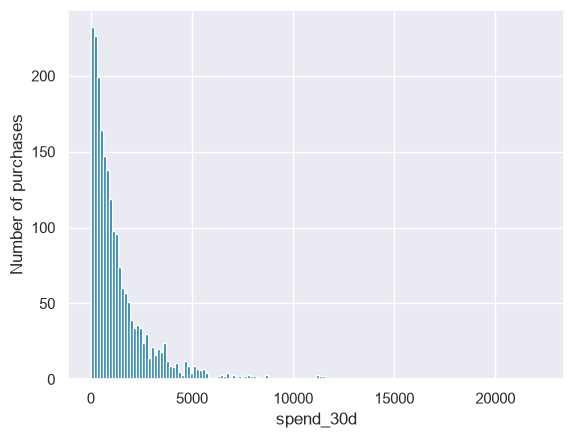

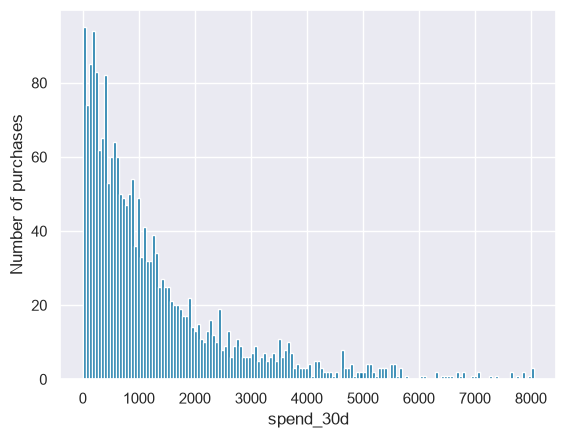

In [733]:
histograms_one_column_excluding_zeros_negative("spend_30d", train_raw, True)

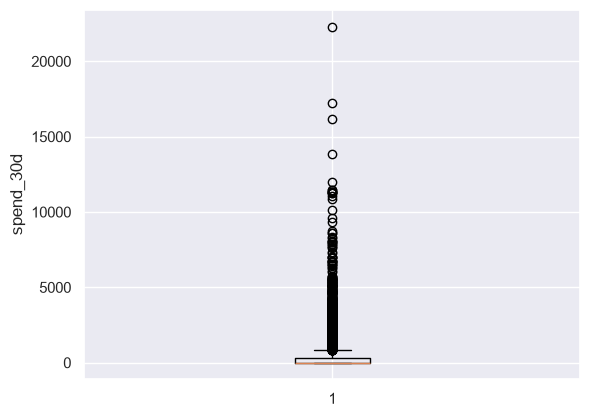

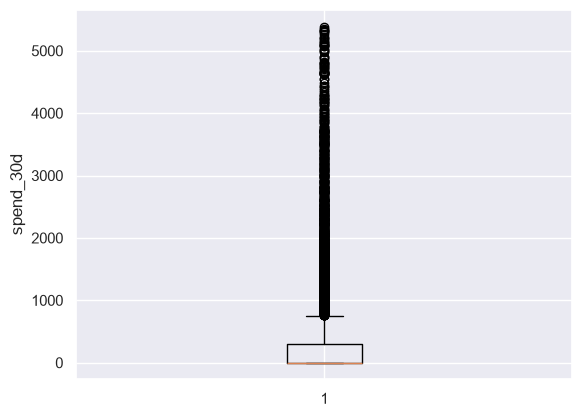

In [571]:
boxplot_one_column("spend_30d", train_raw, True)

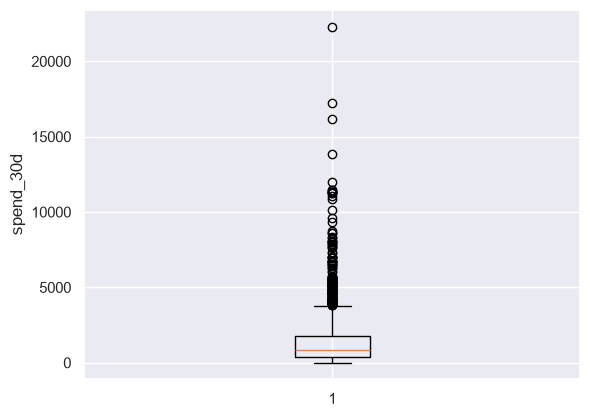

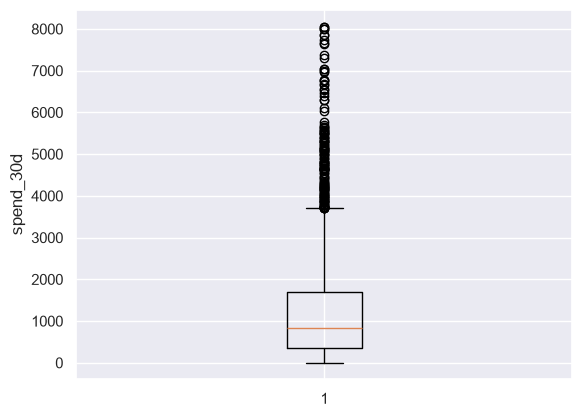

In [749]:
boxplot_one_column_excluding_zeros_negative("spend_30d", train_raw, True)

In [585]:
outliers_one_column("spend_30d", train_raw)

Upper bound: 845.60
Lower bound: -507.36
Number of upper outliers: 1060
Number of lower outliers: 0
Total number of outliers: 1060
Percentatge of outliers in our data: 16.22%


In [593]:
outliers_one_column_excluding_zeros("spend_30d", train_raw)

Upper bound: 3832.96
Lower bound: -1737.18
Number of upper outliers: 148
Number of lower outliers: 0
Total number of outliers: 148
Percentatge of outliers in our data: 2.27%


### spend_90d

In [624]:
descrive_monetary("spend_90d", train_raw)

spend_90d describe:
count     6469.00
mean      1253.53
std       2347.84
min          0.00
25%          0.00
50%        198.50
75%       1514.56
max      30234.88
Name: spend_90d, dtype: float64

Missing values: 65

Unique values: 3523

Zero values: 2889

Negative values: 0

spend_90d top 10 maximum:
          customer_id  spend_90d
ID                              
10004615       227020   30234.88
10007284       227020   25996.70
10003851       227020   25603.61
10003193       227020   25035.85
10006623       227020   24997.81
10001532       227020   24749.16
10005997       227020   24564.56
10007337       942149   18640.59
10001496       227020   18146.78
10005683       755628   17918.84

The top 10 represent the: 2.91% of the column spend_90d


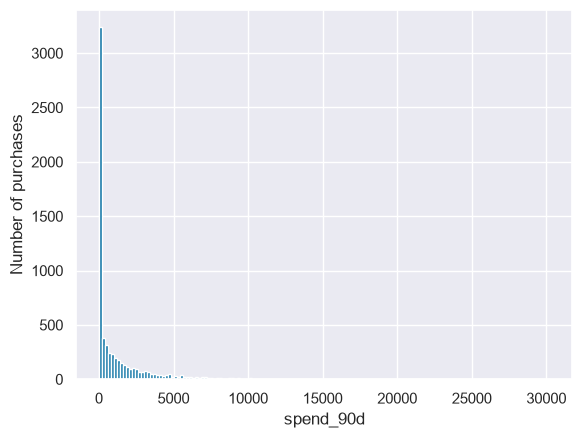

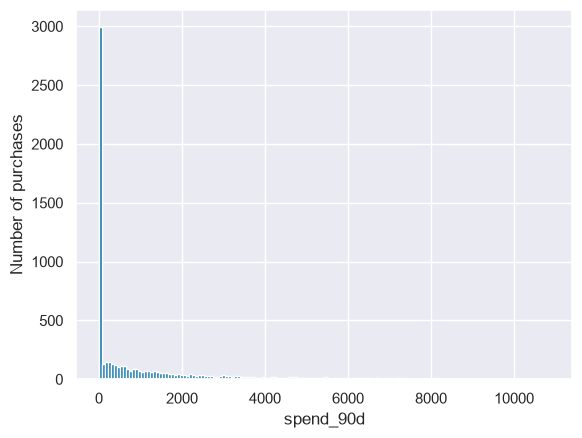

In [574]:
histograms_one_column("spend_90d", train_raw, True)

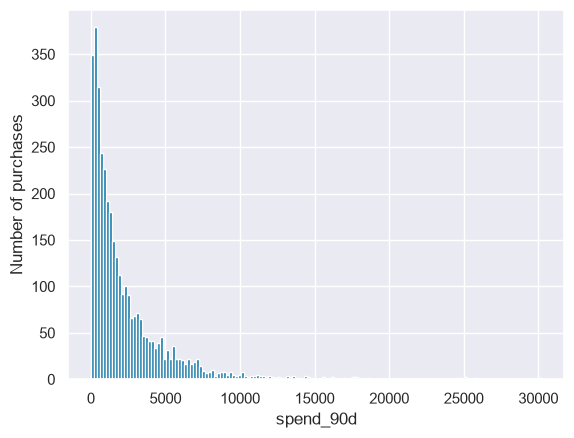

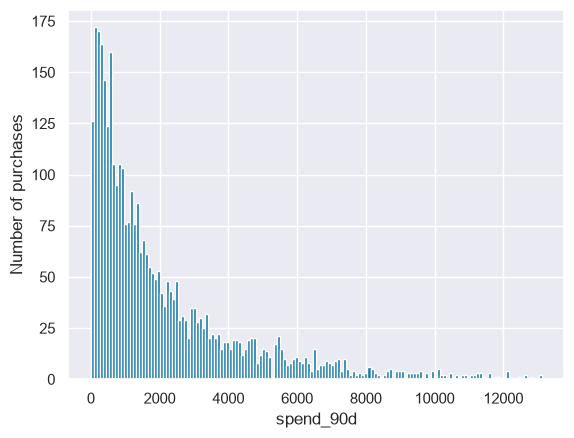

In [734]:
histograms_one_column_excluding_zeros_negative("spend_90d", train_raw, True)

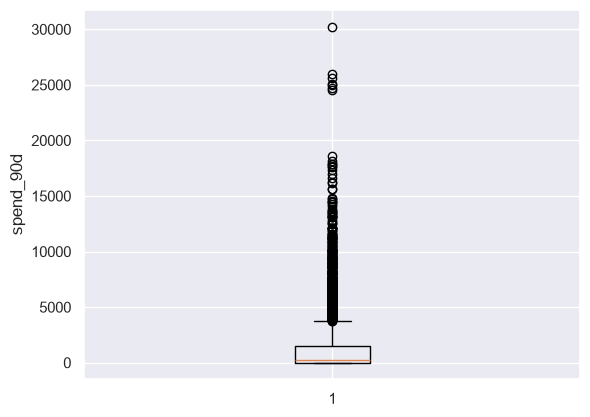

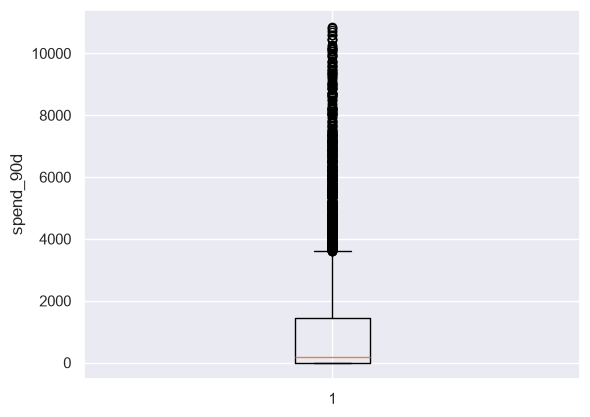

In [576]:
boxplot_one_column("spend_90d", train_raw, True)

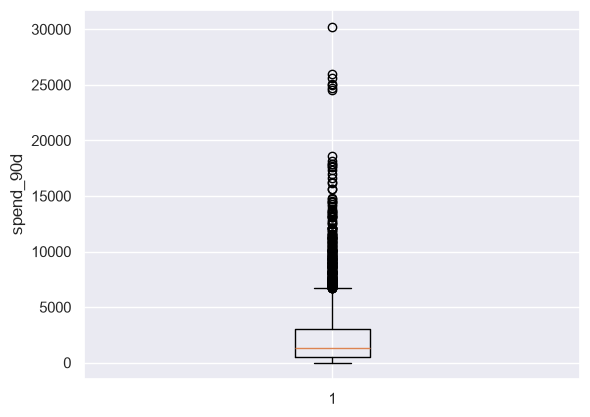

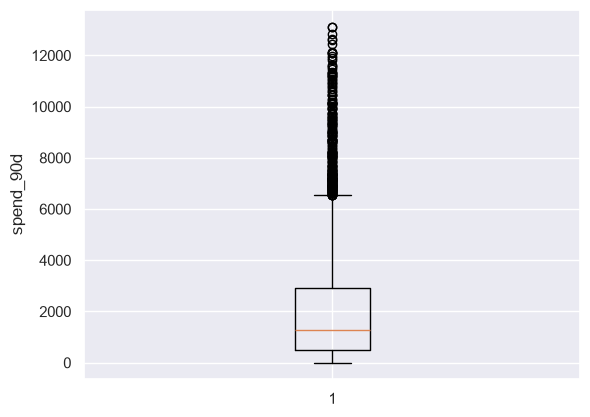

In [750]:
boxplot_one_column_excluding_zeros_negative("spend_90d", train_raw, True)

In [594]:
outliers_one_column("spend_90d", train_raw)

Upper bound: 3786.40
Lower bound: -2271.84
Number of upper outliers: 661
Number of lower outliers: 0
Total number of outliers: 661
Percentatge of outliers in our data: 10.12%


In [595]:
outliers_one_column_excluding_zeros("spend_90d", train_raw)

Upper bound: 6695.66
Lower bound: -3184.57
Number of upper outliers: 238
Number of lower outliers: 0
Total number of outliers: 238
Percentatge of outliers in our data: 3.64%


### spend_180d

In [625]:
descrive_monetary("spend_180d", train_raw)

spend_180d describe:
count     6469.00
mean      2650.60
std       4020.27
min          0.00
25%        149.16
50%       1117.68
75%       3404.44
max      49746.97
Name: spend_180d, dtype: float64

Missing values: 65

Unique values: 5021

Zero values: 1410

Negative values: 0

spend_180d top 10 maximum:
          customer_id  spend_180d
ID                               
10001532       227020    49746.97
10000259       227020    43209.47
10007284       227020    39435.41
10004614       227020    37692.11
10004615       227020    36702.81
10001496       227020    31585.49
10002845       227020    31339.81
10006088       227020    31195.29
10007337       942149    31166.64
10006623       227020    30460.32

The top 10 represent the: 2.11% of the column spend_180d


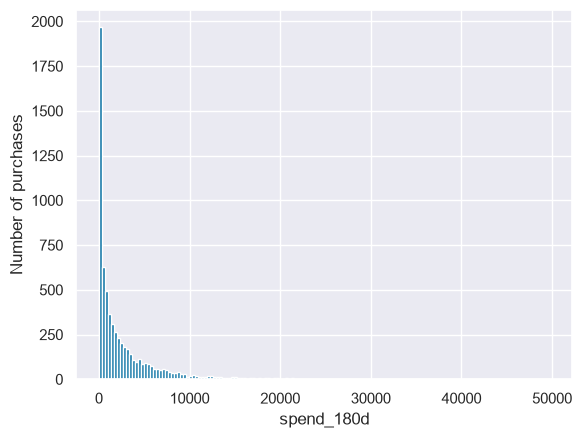

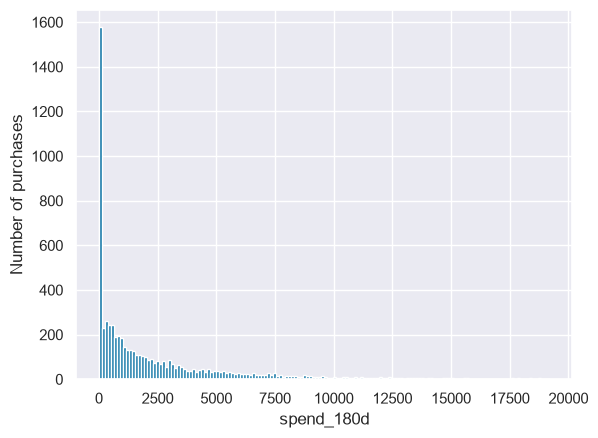

In [579]:
histograms_one_column("spend_180d", train_raw, True)

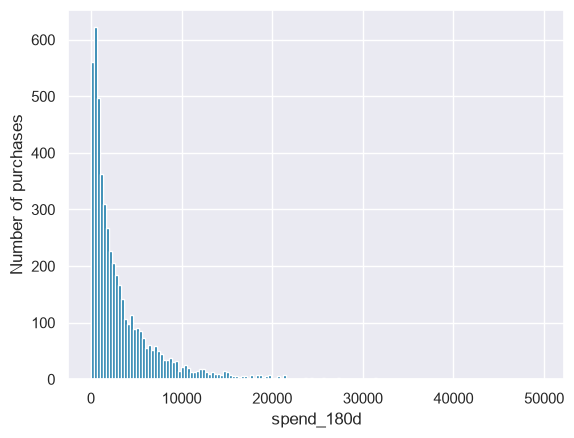

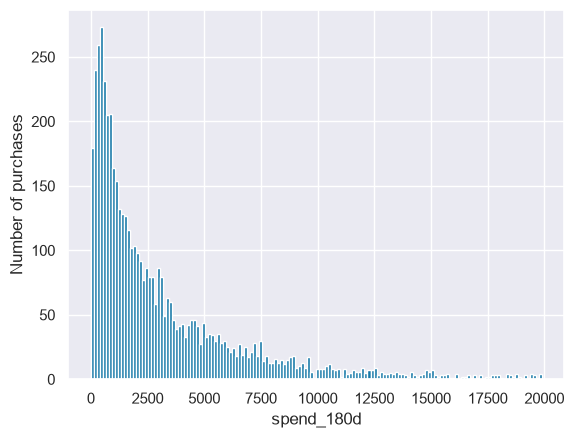

In [735]:
histograms_one_column_excluding_zeros_negative("spend_180d", train_raw, True)

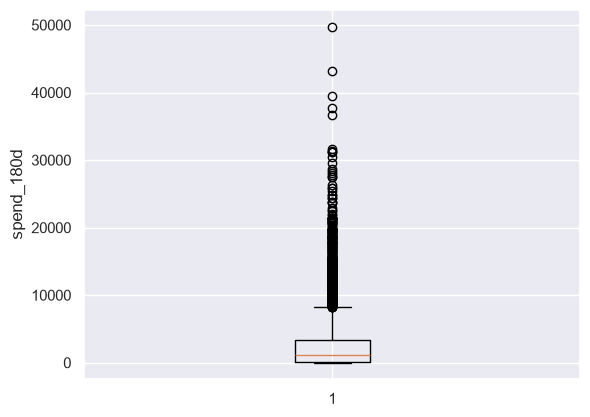

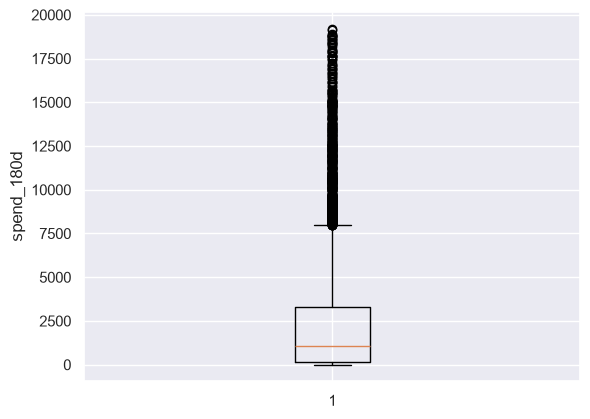

In [581]:
boxplot_one_column("spend_180d", train_raw, True)

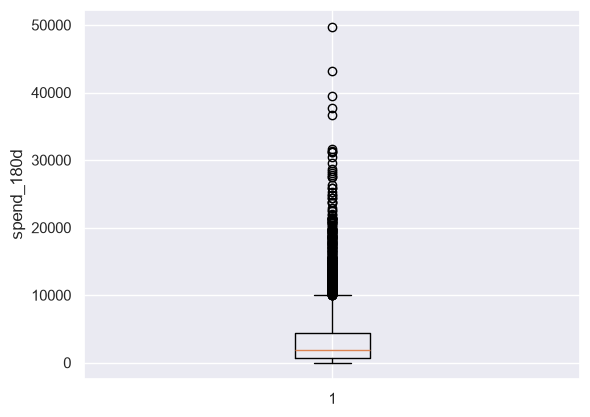

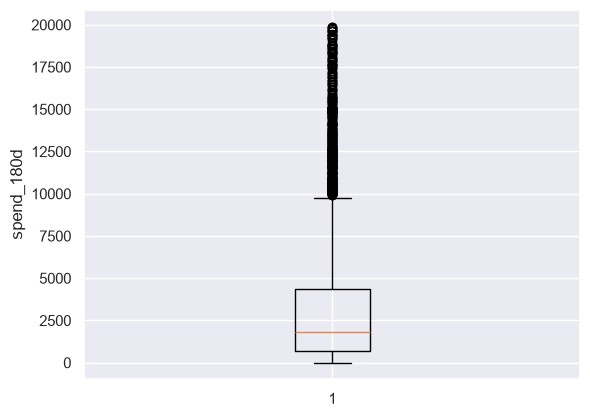

In [751]:
boxplot_one_column_excluding_zeros_negative("spend_180d", train_raw, True)

In [596]:
outliers_one_column("spend_180d", train_raw)

Upper bound: 8287.36
Lower bound: -4733.76
Number of upper outliers: 508
Number of lower outliers: 0
Total number of outliers: 508
Percentatge of outliers in our data: 7.77%


In [597]:
outliers_one_column_excluding_zeros("spend_180d", train_raw)

Upper bound: 10033.35
Lower bound: -4876.53
Number of upper outliers: 353
Number of lower outliers: 0
Total number of outliers: 353
Percentatge of outliers in our data: 5.40%


### spend_365d

In [626]:
descrive_monetary("spend_365d", train_raw)

spend_365d describe:
count    6.274000e+03
mean     2.396535e+06
std      4.884113e+07
min     -1.591152e+05
25%      6.377800e+02
50%      2.426600e+03
75%      7.045420e+03
max      1.000000e+09
Name: spend_365d, dtype: float64

Missing values: 260

Unique values: 5434

Zero values: 810

Negative values: 15

spend_365d top 10 maximum:
          customer_id    spend_365d
ID                                 
10001073       239651  1.000000e+09
10001200       258332  1.000000e+09
10001907       924977  1.000000e+09
10002274       688367  1.000000e+09
10002757       309223  1.000000e+09
10002770       475951  1.000000e+09
10003040       688367  1.000000e+09
10003894       239651  1.000000e+09
10004118       552734  1.000000e+09
10004883       703834  1.000000e+09

The top 10 represent the: 66.51% of the column spend_365d


In [495]:
print(f"Negative values in this columns: {(train_raw["spend_365d"] < 0).sum()}\n")

print(f"Examples of the rows with negative values: {train_raw.loc[train_raw["spend_365d"] < 0].T}\n\n")

print(f"Maximum values in this columns: {(train_raw["spend_365d"] == 1.000000e+09).sum()}\n")
print(f"Examples of the rows with the max: {train_raw.loc[train_raw["spend_365d"] == 1.000000e+09].T}")



Negative values in this columns: 15

Examples of the rows with negative values: ID                                                 10000300  \
Total a Pagar                                        322.65   
Total Bruto                                           276.7   
Total Liquido                                        262.32   
Total Imp_                                            60.33   
Total Portes                                            0.0   
Total Desc_ Global                                      0.0   
Total Desc_ Linha                                     14.38   
Custo                                            153.176416   
N_ Detalhes                                             6.0   
invoice_count_current_purchase                          1.0   
repeat_purchase_90d                                       1   
days_since_previous_purchase                          112.0   
customer_tenure_days                                  364.0   
prior_purchase_count                  

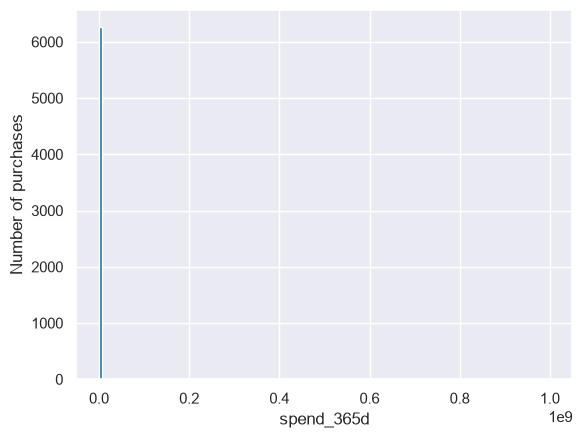

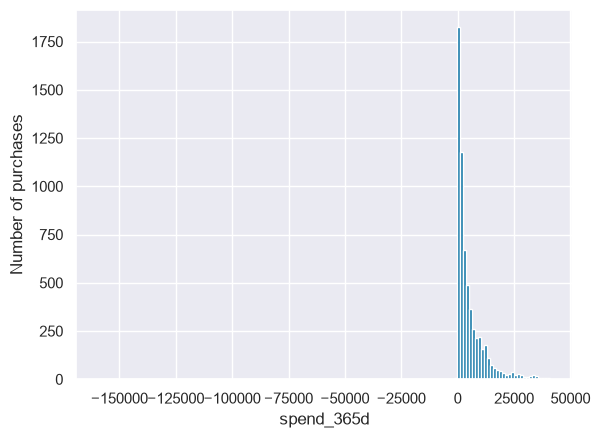

In [464]:
histograms_one_column("spend_365d", train_raw, True)

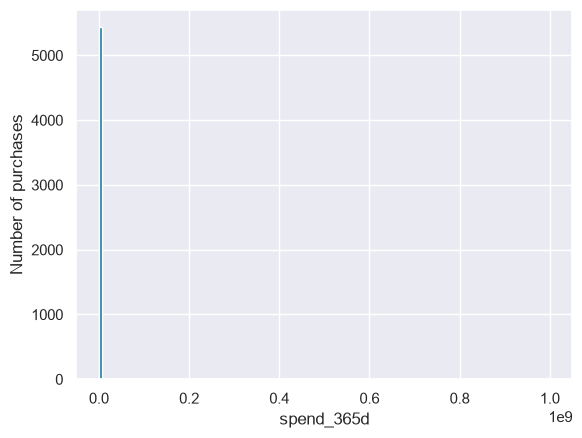

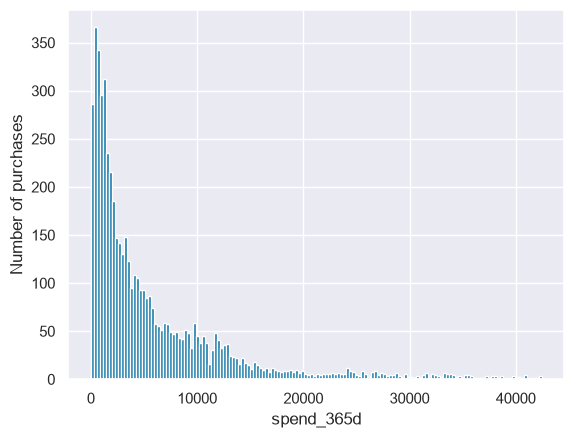

In [736]:
histograms_one_column_excluding_zeros_negative("spend_365d", train_raw, True)

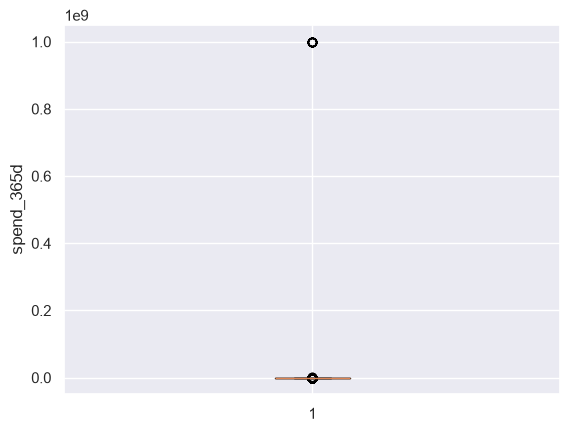

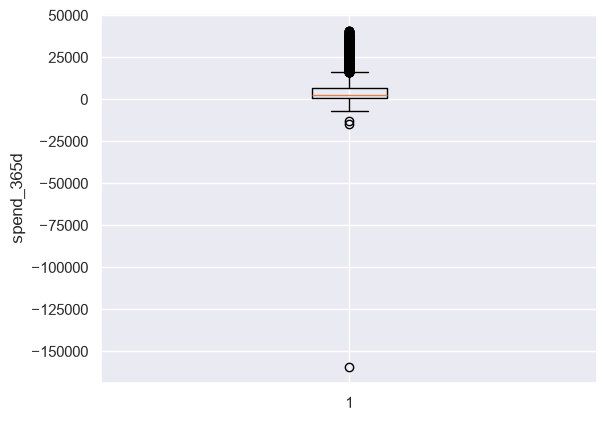

In [470]:
boxplot_one_column("spend_365d", train_raw, True)

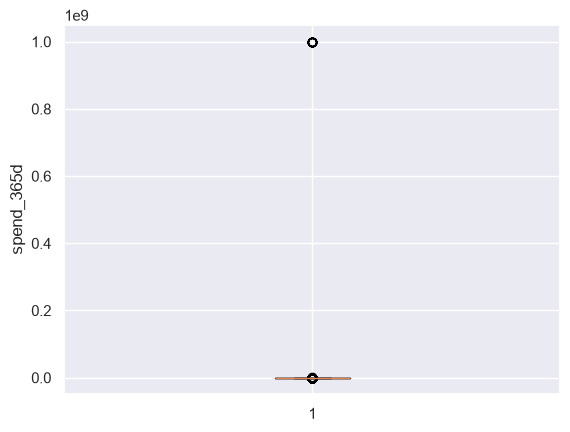

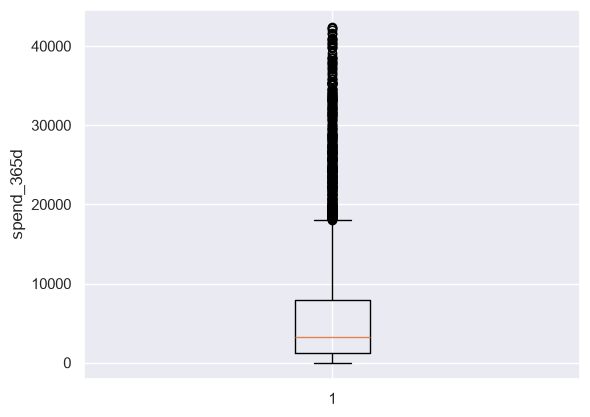

In [752]:
boxplot_one_column_excluding_zeros_negative("spend_365d", train_raw, True)

In [598]:
outliers_one_column("spend_365d", train_raw)

Upper bound: 16656.88
Lower bound: -8973.68
Number of upper outliers: 463
Number of lower outliers: 3
Total number of outliers: 466
Percentatge of outliers in our data: 7.09%


In [599]:
outliers_one_column_excluding_zeros("spend_365d", train_raw)

Upper bound: 18591.13
Lower bound: -9224.10
Number of upper outliers: 397
Number of lower outliers: 0
Total number of outliers: 397
Percentatge of outliers in our data: 6.08%


### days_since_previous_purchase

In [627]:
descrive_monetary("days_since_previous_purchase", train_raw)

days_since_previous_purchase describe:
count    5673.00
mean      101.53
std       165.70
min        -4.00
25%        17.00
50%        57.00
75%       119.00
max      3199.00
Name: days_since_previous_purchase, dtype: float64

Missing values: 861

Unique values: 495

Zero values: 0

Negative values: 16

days_since_previous_purchase top 10 maximum:
          customer_id  days_since_previous_purchase
ID                                                 
10000681       182819                        3199.0
10001452       424538                        3068.0
10001332       871761                        2324.0
10002408       847396                        2162.0
10006968       555330                        1932.0
10001954       519991                        1856.0
10000208       468881                        1799.0
10002177       971351                        1793.0
10000859       675269                        1781.0
10005257       764109                        1743.0

The top 10 represent the:

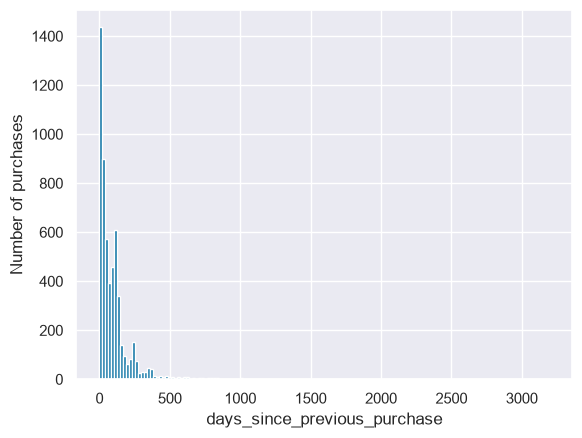

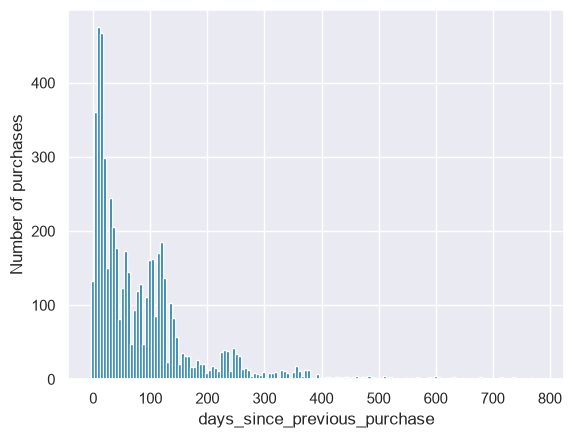

In [608]:
histograms_one_column("days_since_previous_purchase", train_raw, True)

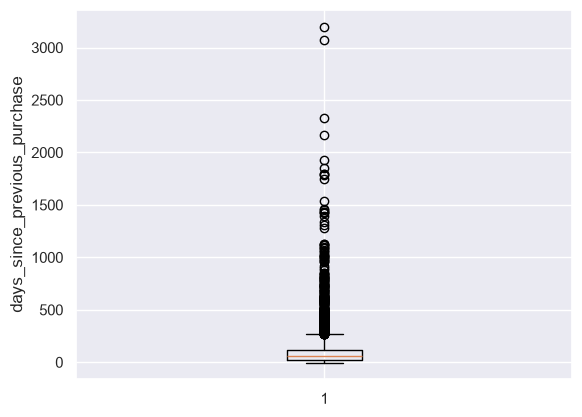

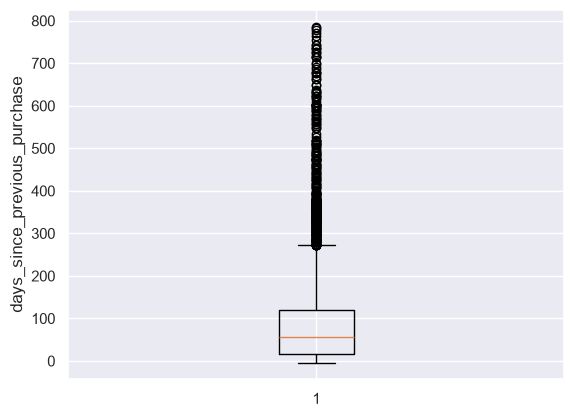

In [609]:
boxplot_one_column("days_since_previous_purchase", train_raw, True)

In [610]:
outliers_one_column("days_since_previous_purchase", train_raw)

Upper bound: 272.00
Lower bound: -136.00
Number of upper outliers: 377
Number of lower outliers: 0
Total number of outliers: 377
Percentatge of outliers in our data: 5.77%


### customer_tenure_days

In [628]:
descrive_monetary("customer_tenure_days", train_raw)

customer_tenure_days describe:
count    6469.00
mean     1111.38
std       923.19
min         0.00
25%       308.00
50%       918.00
75%      1759.00
max      3506.00
Name: customer_tenure_days, dtype: float64

Missing values: 65

Unique values: 2121

Zero values: 603

Negative values: 0

customer_tenure_days top 10 maximum:
          customer_id  customer_tenure_days
ID                                         
10000995       793475                3506.0
10005051       323406                3506.0
10007072       846138                3506.0
10002295       902830                3499.0
10002949       523922                3499.0
10005923       151492                3492.0
10006174       497930                3492.0
10002270       151492                3490.0
10006400       441324                3450.0
10000096       475951                3443.0

The top 10 represent the: 0.49% of the column customer_tenure_days


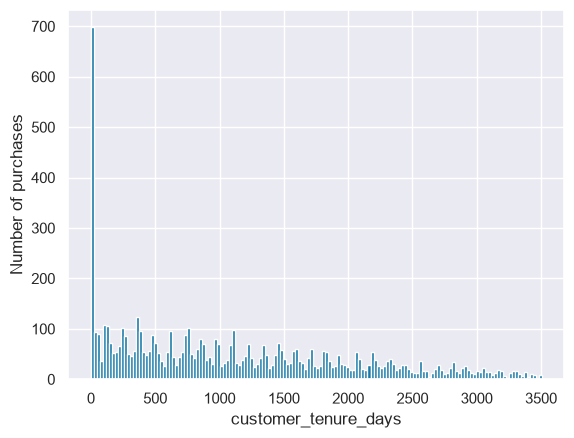

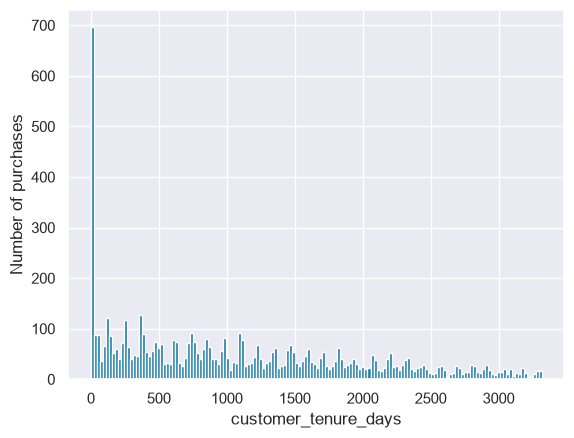

In [629]:
histograms_one_column("customer_tenure_days", train_raw, True)

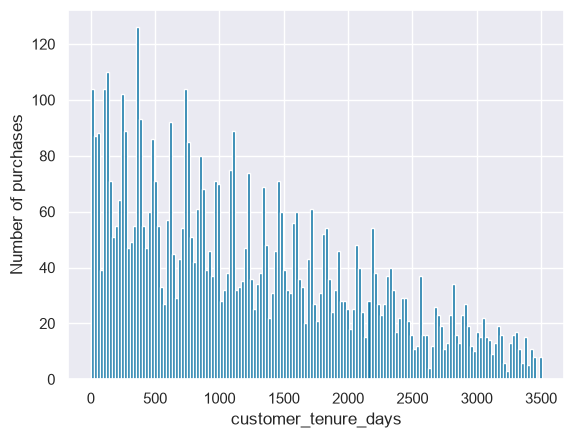

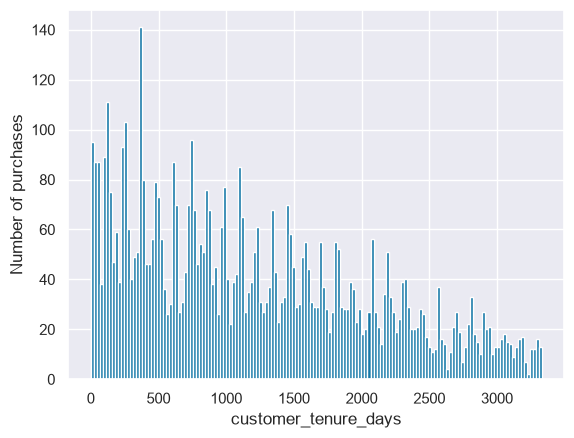

In [737]:
histograms_one_column_excluding_zeros_negative("customer_tenure_days", train_raw, True)

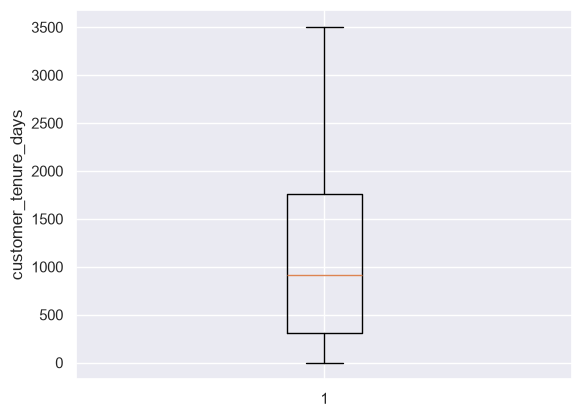

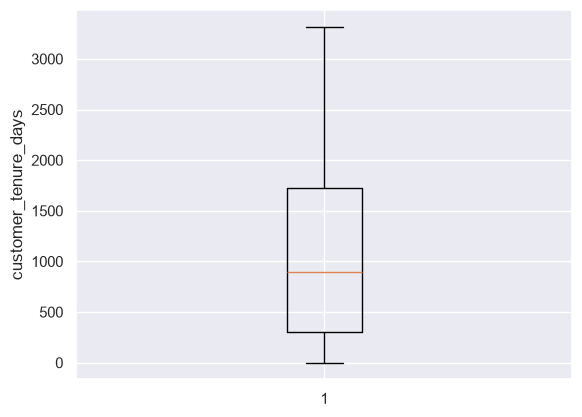

In [631]:
boxplot_one_column("customer_tenure_days", train_raw, True)

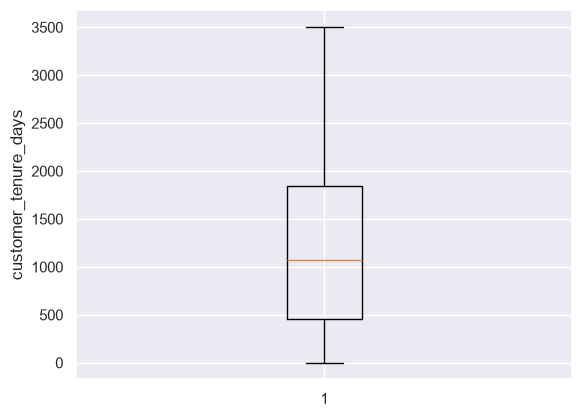

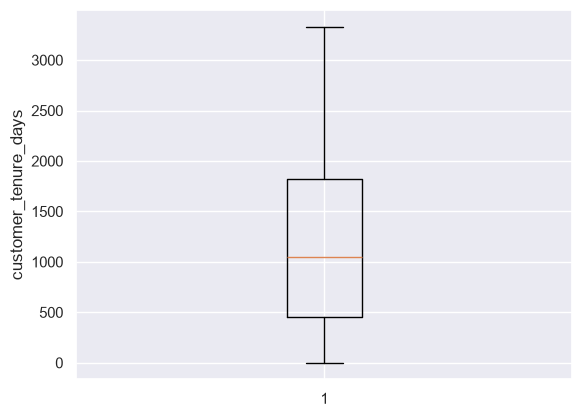

In [753]:
boxplot_one_column_excluding_zeros_negative("customer_tenure_days", train_raw, True)

In [633]:
outliers_one_column("customer_tenure_days", train_raw)

Upper bound: 3935.50
Lower bound: -1868.50
Number of upper outliers: 0
Number of lower outliers: 0
Total number of outliers: 0
Percentatge of outliers in our data: 0.00%


### prior_purchase_count

In [639]:
descrive_discrete("prior_purchase_count", train_raw)

prior_purchase_count describe:
count    6469.00
mean       23.46
std        38.34
min         0.00
25%         3.00
50%        11.00
75%        27.00
max       276.00
Name: prior_purchase_count, dtype: float64

prior_purchase_count missings:
65

prior_purchase_count number of unique values: 277



,Count,Percentage:
prior_purchase_count,,
0.0,603,9.23
1.0,445,6.81
2.0,365,5.59
3.0,319,4.88
4.0,270,4.13
...,...,...
273.0,1,0.02
274.0,1,0.02
275.0,1,0.02


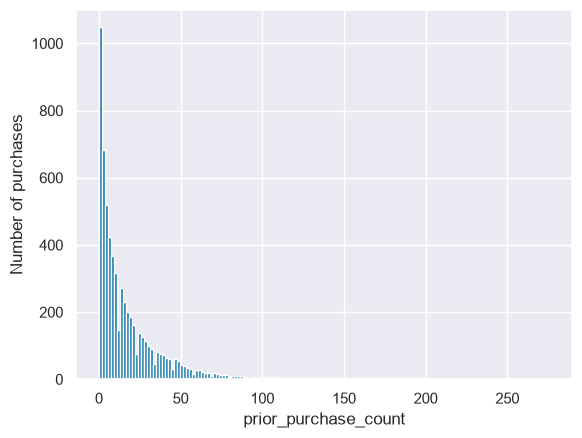

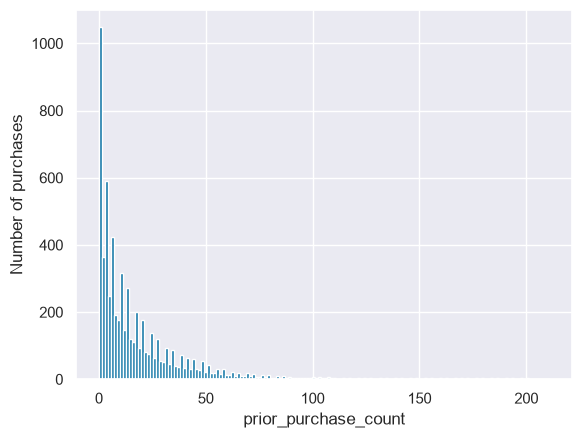

In [640]:
histograms_one_column("prior_purchase_count", train_raw, True)

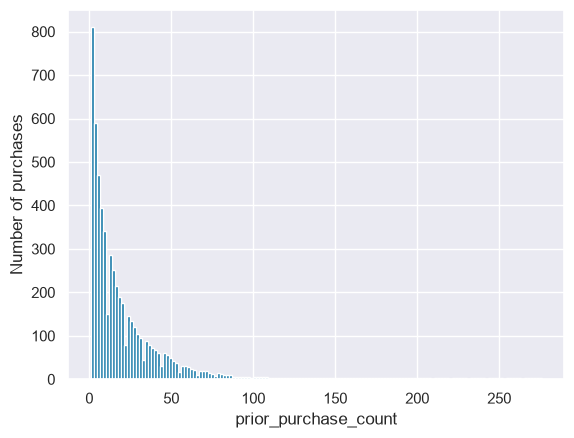

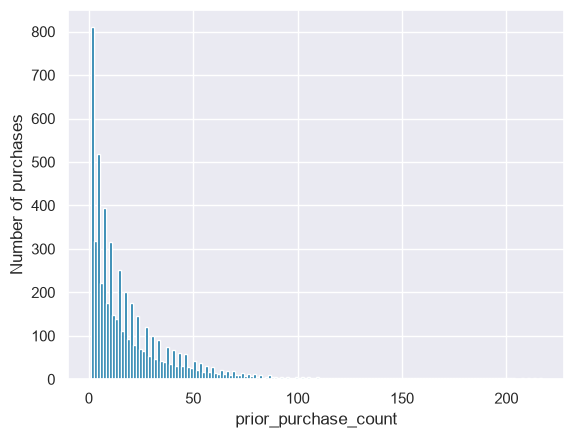

In [738]:
histograms_one_column_excluding_zeros_negative("prior_purchase_count", train_raw, True)

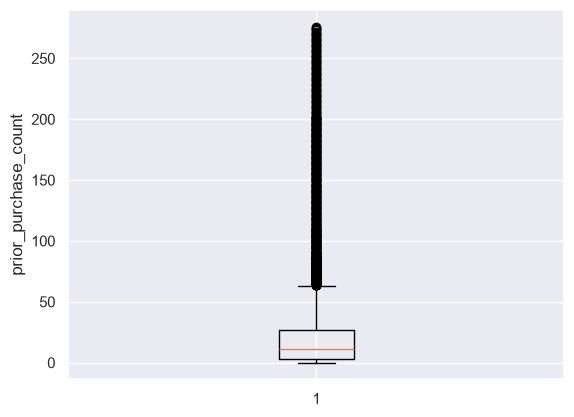

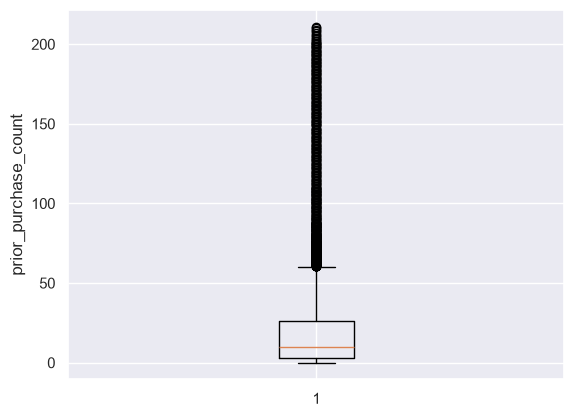

In [642]:
boxplot_one_column("prior_purchase_count", train_raw, True)

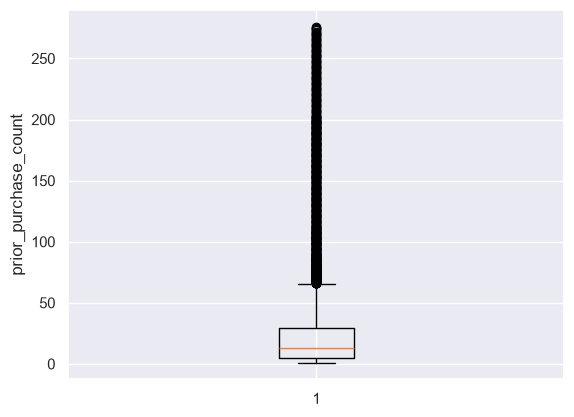

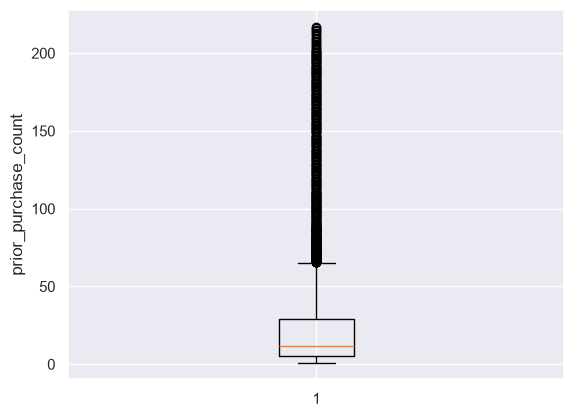

In [755]:
boxplot_one_column_excluding_zeros_negative("prior_purchase_count", train_raw, True)

In [644]:
outliers_one_column("prior_purchase_count", train_raw)

Upper bound: 63.00
Lower bound: -33.00
Number of upper outliers: 500
Number of lower outliers: 0
Total number of outliers: 500
Percentatge of outliers in our data: 7.65%


In [646]:
outliers_one_column_excluding_zeros("prior_purchase_count", train_raw)

Upper bound: 65.00
Lower bound: -31.00
Number of upper outliers: 478
Number of lower outliers: 0
Total number of outliers: 478
Percentatge of outliers in our data (no negative or 0s): 8.15%


### prior_mean_purchase_value

In [650]:
descrive_monetary("prior_mean_purchase_value", train_raw)

prior_mean_purchase_value describe:
count    5.672000e+03
mean     2.821825e+06
std      5.304157e+07
min     -2.478660e+03
25%      3.595600e+02
50%      7.249000e+02
75%      1.095890e+03
max      1.000000e+09
Name: prior_mean_purchase_value, dtype: float64

Missing values: 862

Unique values: 5652

Zero values: 0

Negative values: 16

prior_mean_purchase_value top 10 maximum:
          customer_id  prior_mean_purchase_value
ID                                              
10000226       112532               1.000000e+09
10000304       175924               1.000000e+09
10001890       856505               1.000000e+09
10002792       218902               1.000000e+09
10002865       258332               1.000000e+09
10003106       529840               1.000000e+09
10003702       180223               1.000000e+09
10004113       136125               1.000000e+09
10005563       871356               1.000000e+09
10006001       111068               1.000000e+09

The top 10 represent the: 62.

In [652]:
print(f"Negative values in this columns: {(train_raw["prior_mean_purchase_value"] < 0).sum()}\n")

print(f"Examples of the rows with negative values: {train_raw.loc[train_raw["prior_mean_purchase_value"] < 0].T}\n\n")

print(f"Maximum values in this columns: {(train_raw["prior_mean_purchase_value"] == 1.000000e+09).sum()}\n")
print(f"Examples of the rows with the max: {train_raw.loc[train_raw["prior_mean_purchase_value"] == 1.000000e+09].T}")



Negative values in this columns: 16

Examples of the rows with negative values: ID                                                 10000018  \
Total a Pagar                                        2460.0   
Total Bruto                                          2000.0   
Total Liquido                                        2000.0   
Total Imp_                                            460.0   
Total Portes                                            0.0   
Total Desc_ Global                                      0.0   
Total Desc_ Linha                                       0.0   
Custo                                                   0.0   
N_ Detalhes                                             1.0   
invoice_count_current_purchase                          1.0   
repeat_purchase_90d                                       1   
days_since_previous_purchase                           49.0   
customer_tenure_days                                 1277.0   
prior_purchase_count                  

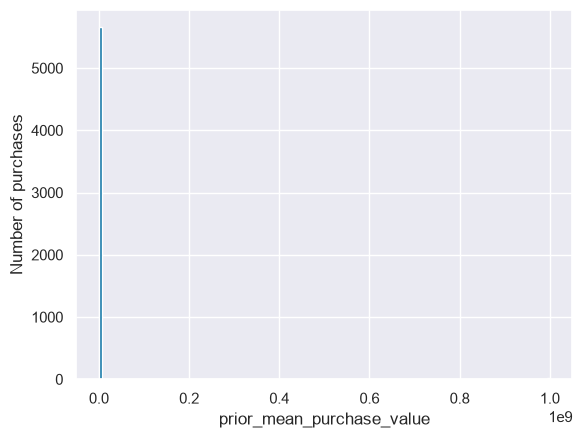

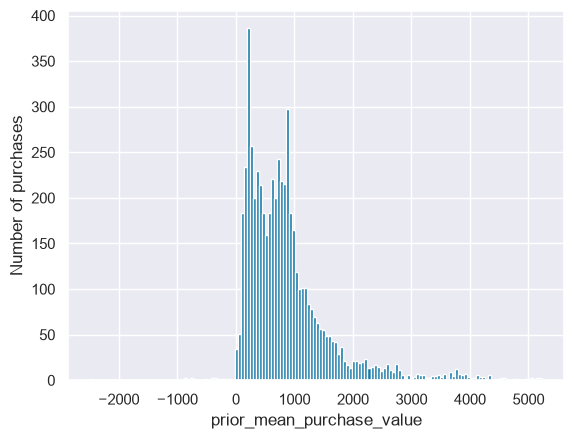

In [656]:
histograms_one_column("prior_mean_purchase_value", train_raw, True)

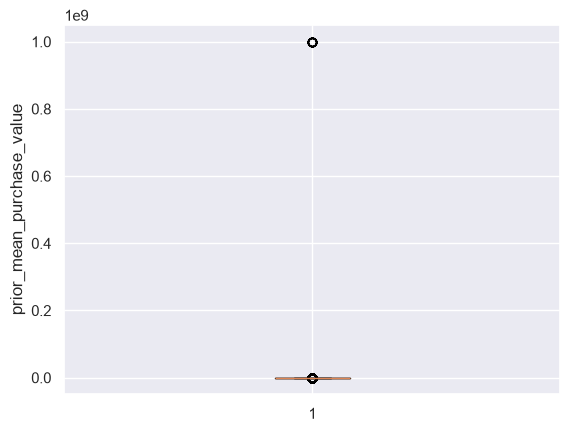

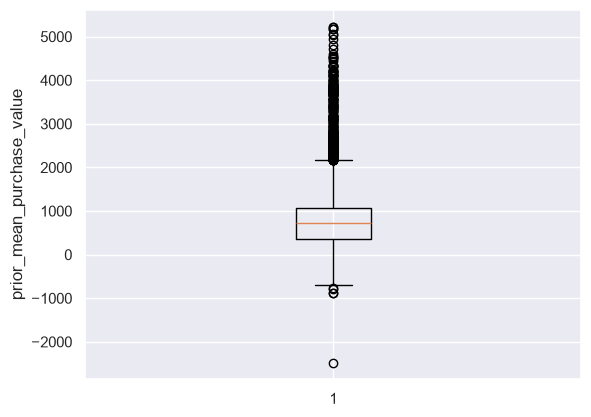

In [658]:
boxplot_one_column("prior_mean_purchase_value", train_raw, True)

In [659]:
outliers_one_column("prior_mean_purchase_value", train_raw)

Upper bound: 2200.38
Lower bound: -744.94
Number of upper outliers: 392
Number of lower outliers: 5
Total number of outliers: 397
Percentatge of outliers in our data: 7.00%


### prior_std_purchase_value

In [660]:
descrive_monetary("prior_std_purchase_value", train_raw)

prior_std_purchase_value describe:
count    5421.00
mean      737.47
std       666.26
min         0.00
25%       258.56
50%       569.08
75%       981.09
max      6770.22
Name: prior_std_purchase_value, dtype: float64

Missing values: 1113

Unique values: 5420

Zero values: 2

Negative values: 0

prior_std_purchase_value top 10 maximum:
          customer_id  prior_std_purchase_value
ID                                             
10004924       588588               6770.221342
10002320       588588               5901.600840
10007396       588588               5158.561997
10000325       588588               4755.554594
10002315       807493               4419.603101
10005395       588588               4386.907088
10006832       807493               4362.729909
10007284       227020               4289.976727
10001496       227020               4287.611482
10003565       588588               4262.684629

The top 10 represent the: 1.22% of the column prior_std_purchase_value


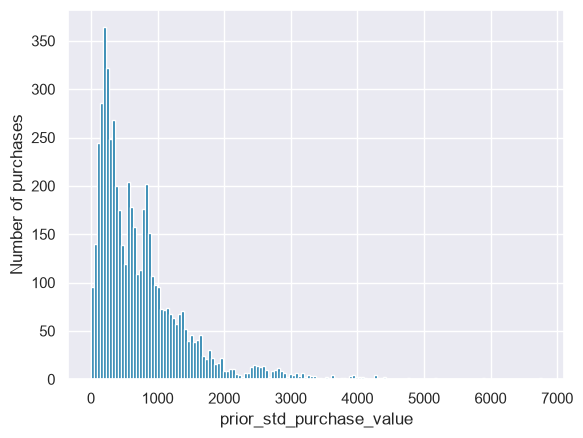

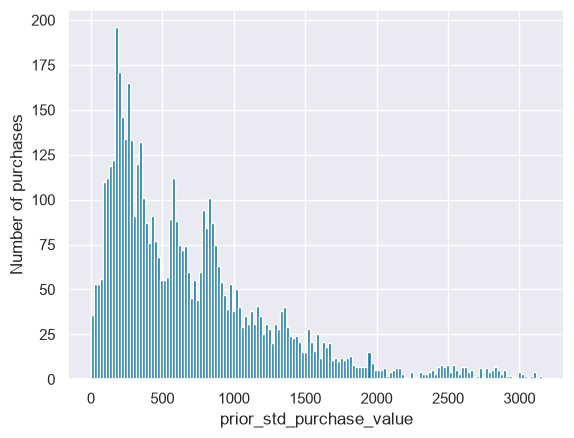

In [662]:
histograms_one_column("prior_std_purchase_value", train_raw, True)

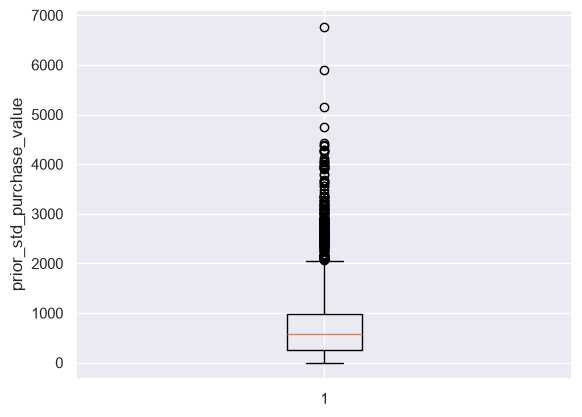

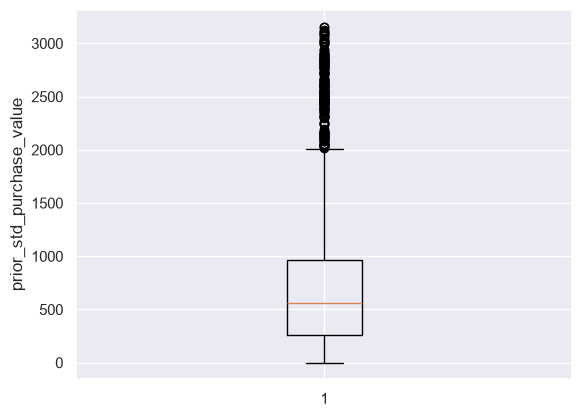

In [663]:
boxplot_one_column("prior_std_purchase_value", train_raw, True)

In [664]:
outliers_one_column("prior_std_purchase_value", train_raw)

Upper bound: 2064.89
Lower bound: -825.24
Number of upper outliers: 251
Number of lower outliers: 0
Total number of outliers: 251
Percentatge of outliers in our data: 4.63%


### prior_min_purchase_value

In [665]:
descrive_monetary("prior_min_purchase_value", train_raw)

prior_min_purchase_value describe:
count    5866.00
mean      185.46
std       408.40
min         0.93
25%        15.45
50%        64.34
75%       162.61
max      6298.98
Name: prior_min_purchase_value, dtype: float64

Missing values: 668

Unique values: 1157

Zero values: 0

Negative values: 0

prior_min_purchase_value top 10 maximum:
          customer_id  prior_min_purchase_value
ID                                             
10007217       652441                   6298.98
10005338       939092                   5575.28
10002626       823441                   5340.24
10003546       683049                   4935.79
10003466       161053                   4718.65
10006515       952237                   4608.71
10006581       322897                   4435.66
10001612       366666                   4229.91
10000791       322897                   4223.13
10006831       189146                   4222.15

The top 10 represent the: 4.47% of the column prior_min_purchase_value


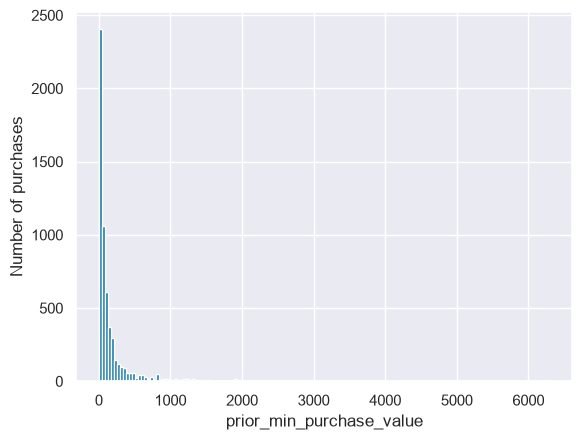

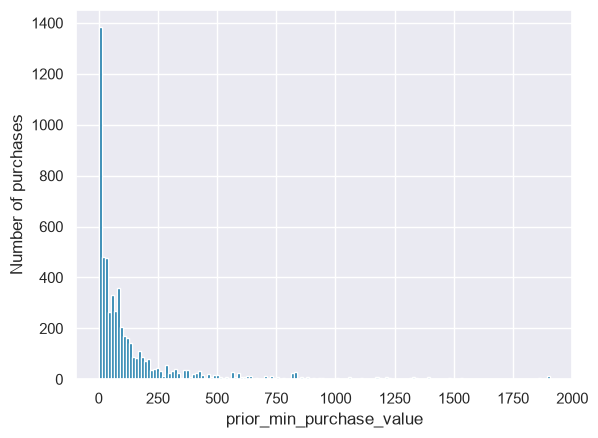

In [667]:
histograms_one_column("prior_min_purchase_value", train_raw, True)

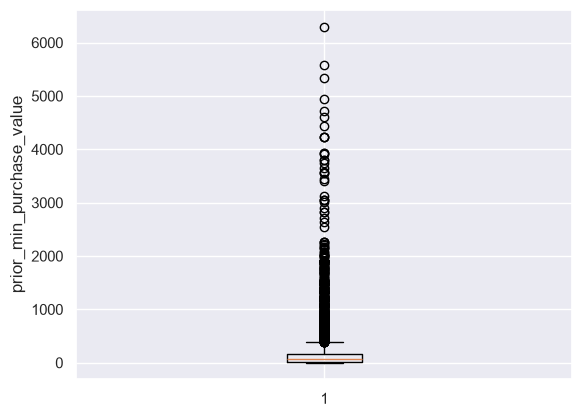

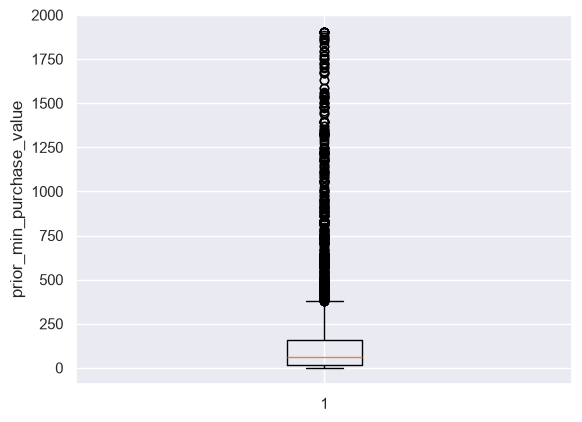

In [668]:
boxplot_one_column("prior_min_purchase_value", train_raw, True)

In [669]:
outliers_one_column("prior_min_purchase_value", train_raw)

Upper bound: 383.35
Lower bound: -205.29
Number of upper outliers: 671
Number of lower outliers: 0
Total number of outliers: 671
Percentatge of outliers in our data: 11.44%


### prior_max_purchase_value

In [670]:
descrive_monetary("prior_max_purchase_value", train_raw)

prior_max_purchase_value describe:
count      5866.00
mean       2946.38
std        5901.55
min           3.31
25%         834.53
50%        1783.24
75%        3504.42
max      267526.19
Name: prior_max_purchase_value, dtype: float64

Missing values: 668

Unique values: 1156

Zero values: 0

Negative values: 0

prior_max_purchase_value top 10 maximum:
          customer_id  prior_max_purchase_value
ID                                             
10003019       227020             267526.189924
10004717       703834             121251.531835
10003185       688367             104433.531682
10007558       227020             103081.258881
10003242       540086              82585.149715
10003597       703834              68355.226334
10002787       974136              66359.971189
10004001       755628              64707.618860
10002343       386654              60467.174676
10003480       800148              60220.054770

The top 10 represent the: 5.78% of the column prior_max_purchase_valu

In [671]:
train_raw.loc[
    train_raw["prior_purchase_count"] == 0,
    "prior_max_purchase_value"
].value_counts(dropna=False)

prior_max_purchase_value
NaN    603
Name: count, dtype: int64

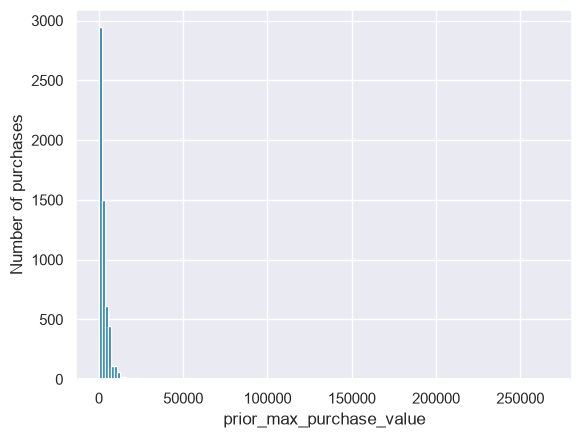

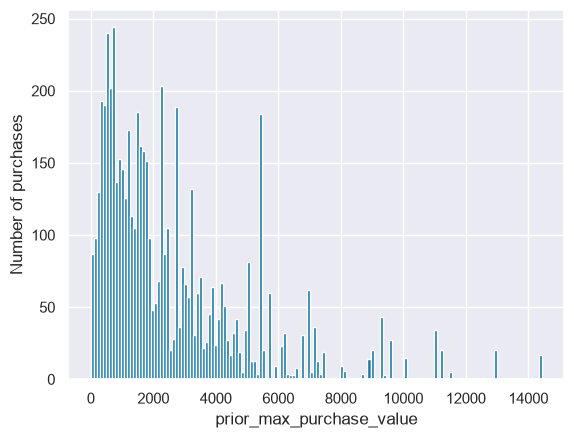

In [672]:
histograms_one_column("prior_max_purchase_value", train_raw, True)

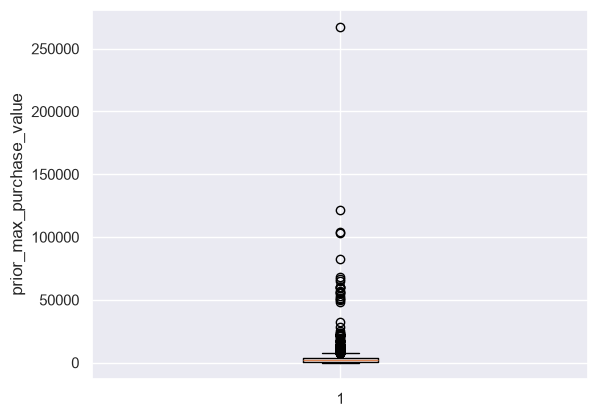

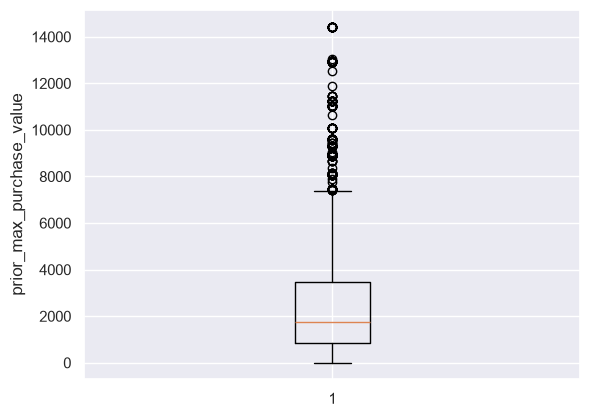

In [673]:
boxplot_one_column("prior_max_purchase_value", train_raw, True)

In [676]:
outliers_one_column("prior_max_purchase_value", train_raw)

Upper bound: 7509.26
Lower bound: -3170.31
Number of upper outliers: 299
Number of lower outliers: 0
Total number of outliers: 299
Percentatge of outliers in our data: 5.10%


### prior_mean_gap_days

In [677]:
descrive_monetary("prior_mean_gap_days", train_raw)

prior_mean_gap_days describe:
count    5226.00
mean       95.88
std       122.59
min        -4.00
25%        42.60
50%        68.44
75%       113.83
max      3199.00
Name: prior_mean_gap_days, dtype: float64

Missing values: 1308

Unique values: 3874

Zero values: 0

Negative values: 16

prior_mean_gap_days top 10 maximum:
          customer_id  prior_mean_gap_days
ID                                        
10002797       182819          3199.000000
10003595       223603          2524.000000
10004689       871761          2324.000000
10006574       971351          1793.000000
10004469       424538          1644.500000
10003815       182819          1634.500000
10004987       223603          1474.500000
10004715       495202          1435.000000
10006524       273298          1284.000000
10005419       424538          1110.333333

The top 10 represent the: 3.68% of the column prior_mean_gap_days


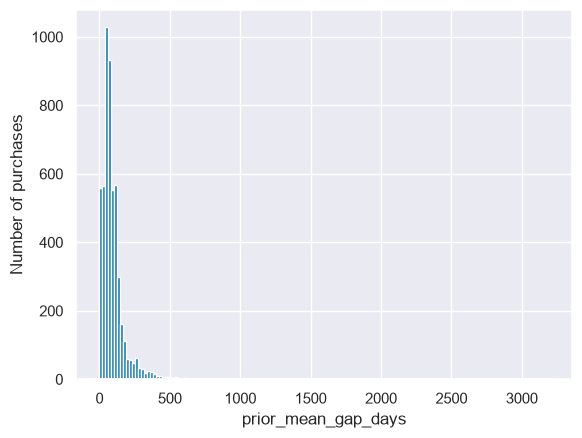

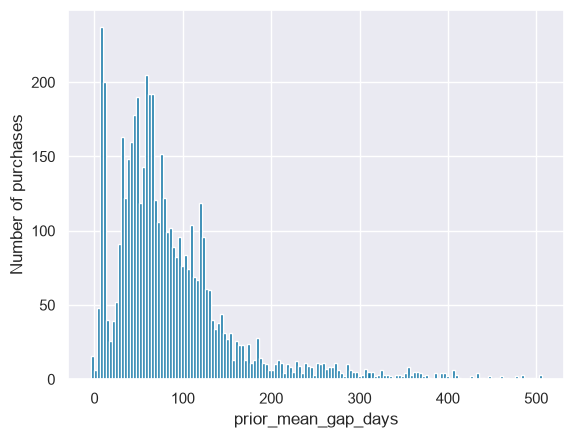

In [679]:
histograms_one_column("prior_mean_gap_days", train_raw, True)

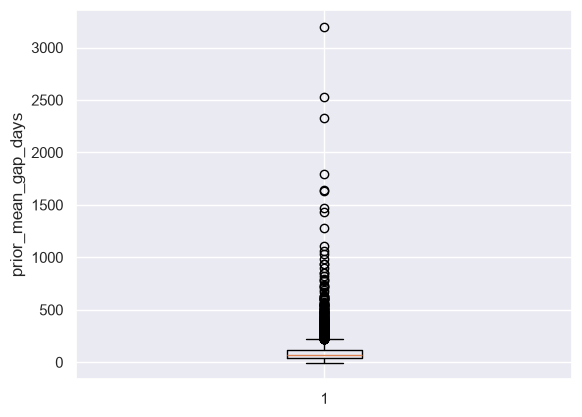

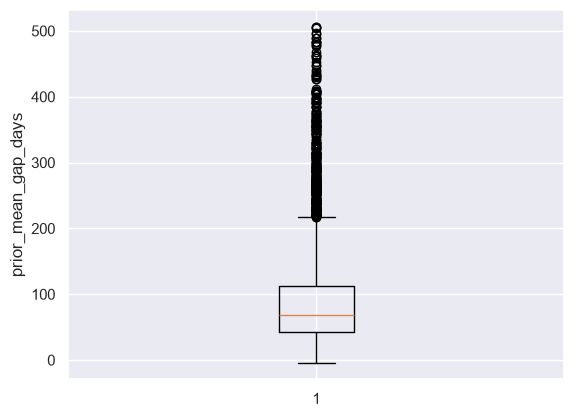

In [680]:
boxplot_one_column("prior_mean_gap_days", train_raw, True)

In [681]:
outliers_one_column("prior_mean_gap_days", train_raw)

Upper bound: 220.68
Lower bound: -64.26
Number of upper outliers: 366
Number of lower outliers: 0
Total number of outliers: 366
Percentatge of outliers in our data: 7.00%


### prior_std_gap_days

In [684]:
descrive_monetary("prior_std_gap_days", train_raw)

prior_std_gap_days describe:
count    5056.00
mean       74.14
std       101.82
min         0.00
25%        32.74
50%        50.64
75%        78.63
max      2212.54
Name: prior_std_gap_days, dtype: float64

Missing values: 1478

Unique values: 4911

Zero values: 1

Negative values: 0

prior_std_gap_days top 10 maximum:
          customer_id  prior_std_gap_days
ID                                       
10003815       182819         2212.537118
10004469       424538         2013.133006
10005419       424538         1697.749785
10004987       223603         1484.217134
10002879       519991         1303.197798
10003304       971351         1262.892711
10006575       519991         1065.792819
10000862       971351         1027.700994
10006464       161053         1013.284017
10004736       519991          915.749010

The top 10 represent the: 3.73% of the column prior_std_gap_days


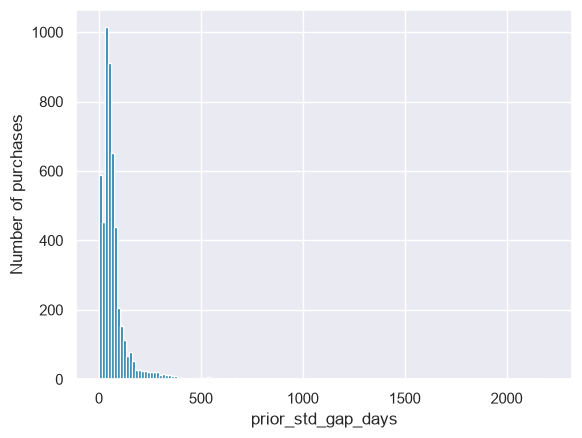

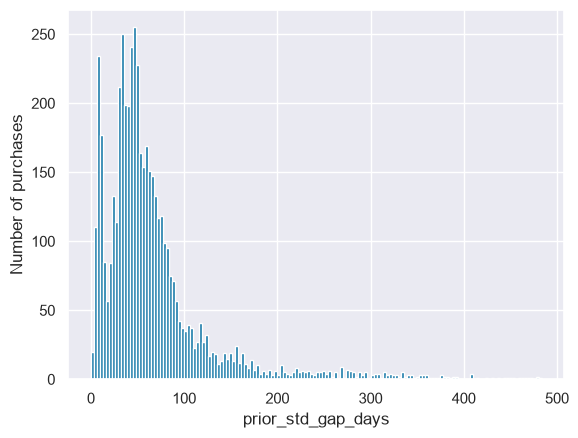

In [686]:
histograms_one_column("prior_std_gap_days", train_raw, True)

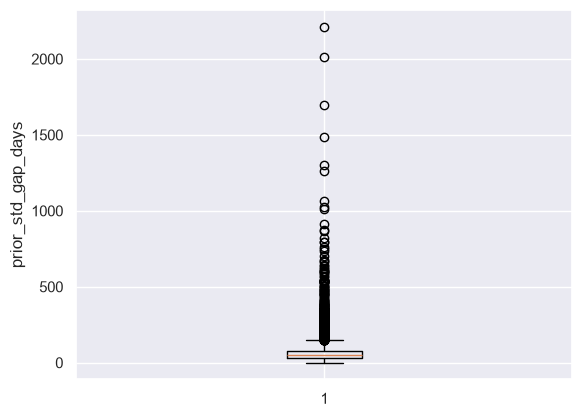

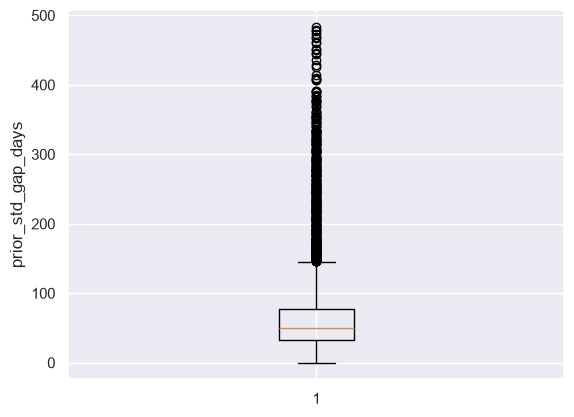

In [687]:
boxplot_one_column("prior_std_gap_days", train_raw, True)

In [688]:
outliers_one_column("prior_std_gap_days", train_raw)

Upper bound: 147.46
Lower bound: -36.10
Number of upper outliers: 461
Number of lower outliers: 0
Total number of outliers: 461
Percentatge of outliers in our data: 9.12%


### random_noise

In [693]:
train_raw["random_noise"].describe()

count    6469.000000
mean       -0.022140
std         1.001054
min        -3.529210
25%        -0.677770
50%        -0.045714
75%         0.641711
max         4.151241
Name: random_noise, dtype: float64

In [694]:
print("Missing values:", train_raw["random_noise"].isna().sum())
print("Unique values:", train_raw["random_noise"].nunique())
print("Zero values:", (train_raw["random_noise"] == 0).sum())
print("Negative values:", (train_raw["random_noise"] < 0).sum())

Missing values: 65
Unique values: 6469
Zero values: 0
Negative values: 3357


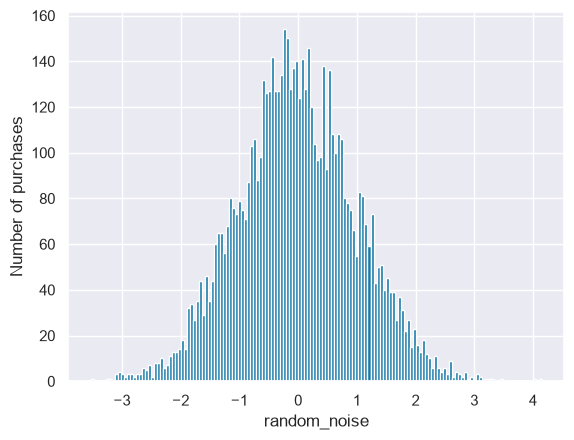

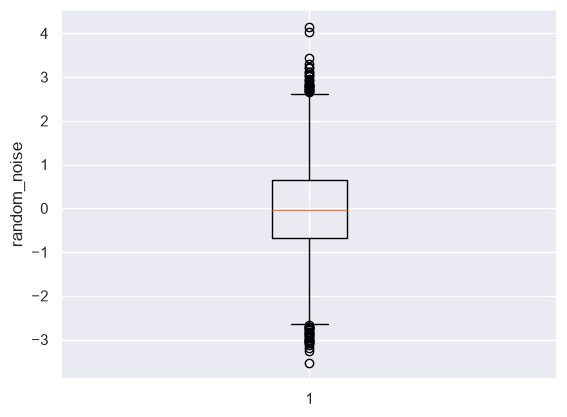

In [695]:
histograms_one_column("random_noise", train_raw, False)

boxplot_one_column("random_noise", train_raw, False)

### repeat_purchase_90d

In [690]:
print("Unique values:", train_raw["repeat_purchase_90d"].unique())
print("Missing values:", train_raw["repeat_purchase_90d"].isna().sum())

train_raw["repeat_purchase_90d"].value_counts(dropna=False)

Unique values: [1 0]
Missing values: 0


repeat_purchase_90d
1    3654
0    2880
Name: count, dtype: int64

In [691]:
train_raw["repeat_purchase_90d"].value_counts(
    normalize=True,
    dropna=False
) * 100

repeat_purchase_90d
1    55.922865
0    44.077135
Name: proportion, dtype: float64

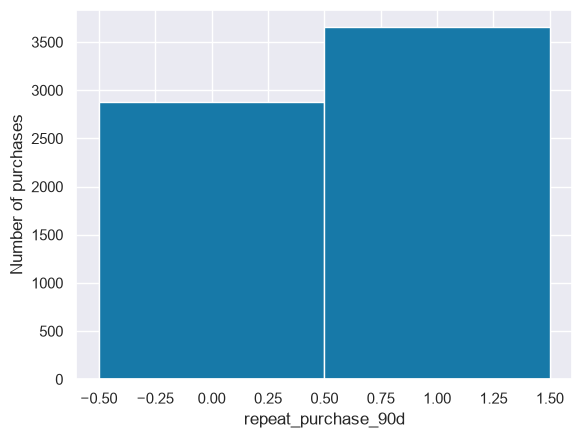

In [702]:
histograms_one_column("repeat_purchase_90d", train_raw, False, bins = 2)

# EDA of clientes

## General View

In [760]:
print(f"Number of rows: {clientes_raw.shape[0]}")
print(f"Number of columns: {clientes_raw.shape[1]}")
print(clientes_raw.info())

Number of rows: 1143
Number of columns: 12
<class 'pandas.DataFrame'>
Index: 1143 entries, 842570 to 312616
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country_or_region    1143 non-null   str    
 1   commercial_region    1029 non-null   str    
 2   island               565 non-null    str    
 3   municipality         984 non-null    str    
 4   city                 597 non-null    str    
 5   postal_area          1072 non-null   str    
 6   postal_code          973 non-null    str    
 7   street               545 non-null    str    
 8   address              1137 non-null   str    
 9   customer_type        0 non-null      float64
 10  company_name         1143 non-null   str    
 11  customer_since_year  1143 non-null   int64  
dtypes: float64(1), int64(1), str(10)
memory usage: 116.1 KB
None


In [770]:
print(f"Is customer_id unique: {clientes_raw.index.is_unique}")

Is customer_id unique: True


Every row is a different client

### Duplicated

In [771]:
print(f"Duplicated rows: {clientes_raw.duplicated().sum()}")

Duplicated rows: 0


### Cardinality

In [772]:
print(f"Unique values per column:\n{clientes_raw.nunique(dropna=False).sort_values()}")

Unique values per column:
customer_type             1
country_or_region        11
island                   11
customer_since_year      12
commercial_region        38
municipality            184
postal_area             272
city                    418
street                  512
postal_code             829
address                1121
company_name           1141
dtype: int64


### Missings

In [783]:
missing_values = clientes_raw.isna().sum()
missing_perc = (missing_values / len(clientes_raw)) * 100
print(f"Missing values per column: \n\n{missing_values}")
print(f"\n\nMissing values percentatge per column: \n\n{missing_perc}")

Missing values per column: 

country_or_region         0
commercial_region       114
island                  578
municipality            159
city                    546
postal_area              71
postal_code             170
street                  598
address                   6
customer_type          1143
company_name              0
customer_since_year       0
dtype: int64


Missing values percentatge per column: 

country_or_region        0.000000
commercial_region        9.973753
island                  50.568679
municipality            13.910761
city                    47.769029
postal_area              6.211724
postal_code             14.873141
street                  52.318460
address                  0.524934
customer_type          100.000000
company_name             0.000000
customer_since_year      0.000000
dtype: float64


### Train Test Customer

In [787]:
train_customers = train_raw["customer_id"].dropna().unique()
test_customers = test_raw["customer_id"].dropna().unique()

train_matched = pd.Index(train_customers).isin(clientes_raw.index)
test_matched = pd.Index(test_customers).isin(clientes_raw.index)

print("TRAIN")
print(f"Unique customers: {len(train_customers)}")
print(f"Customers found in clientes_raw: {train_matched.sum()}")
print(f"Coverage: {train_matched.mean() * 100:.2f}%")

print("\nTEST")
print(f"Unique customers: {len(test_customers)}")
print(f"Customers found in clientes_raw: {test_matched.sum()}")
print(f"Coverage: {test_matched.mean() * 100:.2f}%")

TRAIN
Unique customers: 610
Customers found in clientes_raw: 610
Coverage: 100.00%

TEST
Unique customers: 206
Customers found in clientes_raw: 206
Coverage: 100.00%


In [785]:
# Select auxiliary data for train and test customers
clientes_train = clientes_raw.loc[train_customers]
clientes_test = clientes_raw.loc[test_customers]

# Calculate missing percentages
missing_comparison = pd.DataFrame({
    "Train Missing (%)": clientes_train.isna().mean() * 100,
    "Test Missing (%)": clientes_test.isna().mean() * 100
})

display(missing_comparison.round(2))

,Train Missing (%),Test Missing (%)
country_or_region,0.00,0.00
commercial_region,1.97,0.97
island,46.89,43.69
municipality,6.72,9.71
city,38.69,34.95
postal_area,6.56,10.19
postal_code,3.28,2.43
street,54.10,54.37
address,0.00,0.00
customer_type,100.00,100.00


## Univariate Analysis

### country_or_region

In [801]:
column = "country_or_region"

print("Absolute frequencies:")
display(clientes_raw[column].value_counts(dropna=False))

print("\nRelative frequencies (%):")
display(
    (clientes_raw[column].value_counts(dropna=False, normalize=True) * 100)
    .round(2)
)

Absolute frequencies:


country_or_region
Country CT10: Land of The Final Version    1079
Country CT5: Land of The Final Version       49
Country CT4: Land of The Final Version        4
Country CT6: Land of The Final Version        3
Country CT7: Land of The Final Version        2
Country CT11: Land of The Final Version       1
Country CT9: Land of The Final Version        1
Country CT2: Land of The Final Version        1
Country CT1: Land of The Final Version        1
Country CT8: Land of The Final Version        1
Country CT3: Land of The Final Version        1
Name: count, dtype: int64


Relative frequencies (%):


country_or_region
Country CT10: Land of The Final Version    94.40
Country CT5: Land of The Final Version      4.29
Country CT4: Land of The Final Version      0.35
Country CT6: Land of The Final Version      0.26
Country CT7: Land of The Final Version      0.17
Country CT11: Land of The Final Version     0.09
Country CT9: Land of The Final Version      0.09
Country CT2: Land of The Final Version      0.09
Country CT1: Land of The Final Version      0.09
Country CT8: Land of The Final Version      0.09
Country CT3: Land of The Final Version      0.09
Name: proportion, dtype: float64

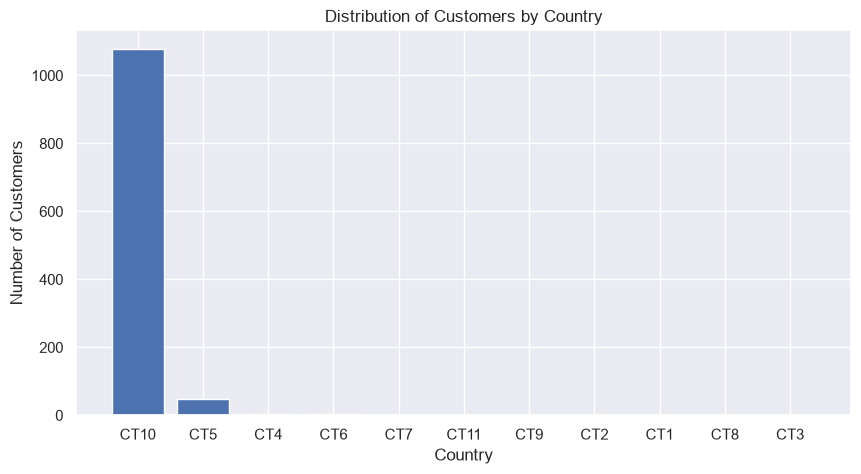

In [802]:
country_counts = clientes_raw["country_or_region"].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(
    country_counts.index.str.extract(r"(CT\d+)", expand=False),
    country_counts.values
)

plt.title("Distribution of Customers by Country")
plt.xlabel("Country")
plt.ylabel("Number of Customers")
plt.show()

### commercial_region

In [805]:
column_name = "commercial_region"

print(f"Missing values: {clientes_raw[column_name].isna().sum()}")
print(f"Unique values: {clientes_raw[column_name].nunique()}")
print(f"Frequencies:\n{clientes_raw[column_name].value_counts(dropna=False)}")

Missing values: 114
Unique values: 37
Frequencies:
commercial_region
Region RG17: We Will See Later    519
NaN                               114
Region RG23: We Will See Later     63
Region RG18: We Will See Later     59
Region RG29: We Will See Later     46
Region RG31: We Will See Later     41
Region RG27: We Will See Later     39
Region RG28: We Will See Later     36
Region RG32: We Will See Later     31
Region RG33: We Will See Later     27
Region RG20: We Will See Later     22
Region RG19: We Will See Later     21
Region RG9: We Will See Later      19
Region RG25: We Will See Later     18
Region RG34: We Will See Later     13
Region RG24: We Will See Later     11
Region RG21: We Will See Later     11
Region RG36: We Will See Later      9
Region RG35: We Will See Later      7
Region RG22: We Will See Later      6
Region RG12: We Will See Later      5
Region RG4: We Will See Later       4
Region RG30: We Will See Later      3
Region RG26: We Will See Later      2
Region RG7: We Will

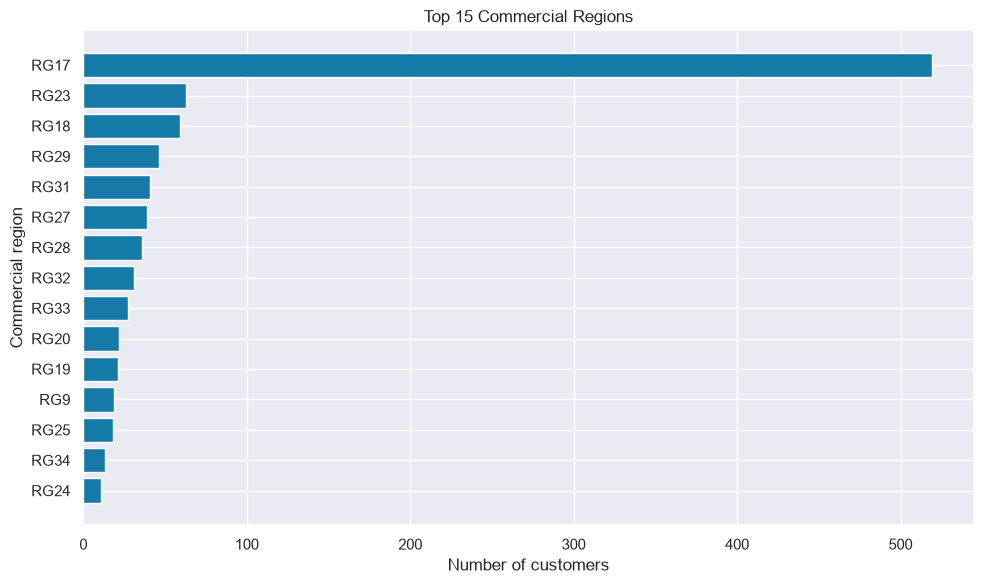

In [804]:
region_counts = clientes_raw["commercial_region"].value_counts().head(15)

region_labels = region_counts.index.str.extract(
    r"(RG\d+)", expand=False
)

plt.figure(figsize=(10, 6))

plt.barh(
    region_labels,
    region_counts.values,
    color=PLOT_BLUE
)

plt.xlabel("Number of customers")
plt.ylabel("Commercial region")
plt.title("Top 15 Commercial Regions")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### island

In [806]:
column = "island"

print(f"Missing values: {clientes_raw[column].isna().sum()}")
print(f"Unique values: {clientes_raw[column].nunique()}")

print("\nAbsolute frequencies:")
display(clientes_raw[column].value_counts(dropna=False))

print("\nRelative frequencies (%):")
display(
    (clientes_raw[column].value_counts(
        dropna=False,
        normalize=True
    ) * 100).round(2)
)

Missing values: 578
Unique values: 10

Absolute frequencies:


island
NaN                                   578
Island IS7: The Pivot Archipelago     133
Island IS8: The Pivot Archipelago      90
Island IS4: The Pivot Archipelago      88
Island IS6: The Pivot Archipelago      81
Island IS1: The Pivot Archipelago      43
Island IS9: The Pivot Archipelago      43
Island IS5: The Pivot Archipelago      37
Island IS2: The Pivot Archipelago      26
Island IS3: The Pivot Archipelago      21
Island IS10: The Pivot Archipelago      3
Name: count, dtype: int64


Relative frequencies (%):


island
NaN                                   50.57
Island IS7: The Pivot Archipelago     11.64
Island IS8: The Pivot Archipelago      7.87
Island IS4: The Pivot Archipelago      7.70
Island IS6: The Pivot Archipelago      7.09
Island IS1: The Pivot Archipelago      3.76
Island IS9: The Pivot Archipelago      3.76
Island IS5: The Pivot Archipelago      3.24
Island IS2: The Pivot Archipelago      2.27
Island IS3: The Pivot Archipelago      1.84
Island IS10: The Pivot Archipelago     0.26
Name: proportion, dtype: float64

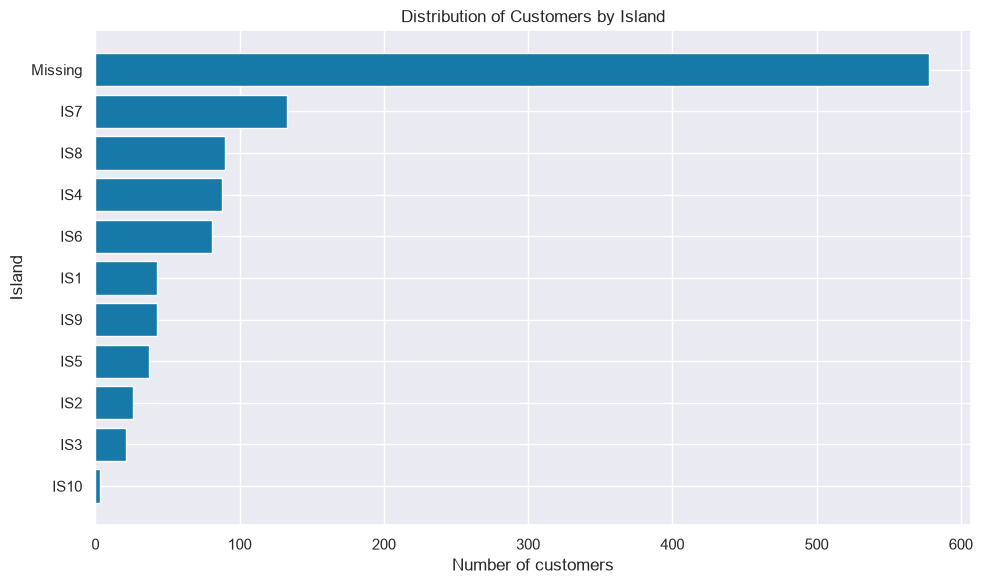

In [807]:
island_counts = clientes_raw["island"].value_counts(dropna=False)

island_labels = [
    "Missing" if pd.isna(value) else value.split(":")[0].replace("Island ", "")
    for value in island_counts.index
]

plt.figure(figsize=(10, 6))

plt.barh(
    island_labels,
    island_counts.values,
    color=PLOT_BLUE
)

plt.xlabel("Number of customers")
plt.ylabel("Island")
plt.title("Distribution of Customers by Island")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### municipality

In [808]:
column = "municipality"

print(f"Missing values: {clientes_raw[column].isna().sum()}")
print(f"Unique values: {clientes_raw[column].nunique()}")

print("\nTop 15 municipalities:")
display(clientes_raw[column].value_counts(dropna=False).head(15))

print("\nPercentage of customers in the top 15 municipalities:")
print(
    f"{clientes_raw[column].value_counts().head(15).sum() / len(clientes_raw) * 100:.2f}%"
)

Missing values: 159
Unique values: 183

Top 15 municipalities:


municipality
NaN                                                159
Municipality MU1: Council of Last Minute Edits      58
Municipality MU9: Council of Last Minute Edits      51
Municipality MU16: Council of Last Minute Edits     48
Municipality MU3: Council of Last Minute Edits      43
Municipality MU6: Council of Last Minute Edits      39
Municipality MU17: Council of Last Minute Edits     37
Municipality MU2: Council of Last Minute Edits      33
Municipality MU11: Council of Last Minute Edits     32
Municipality MU70: Council of Last Minute Edits     32
Municipality MU15: Council of Last Minute Edits     25
Municipality MU12: Council of Last Minute Edits     25
Municipality MU7: Council of Last Minute Edits      24
Municipality MU13: Council of Last Minute Edits     21
Municipality MU14: Council of Last Minute Edits     20
Name: count, dtype: int64


Percentage of customers in the top 15 municipalities:
44.44%


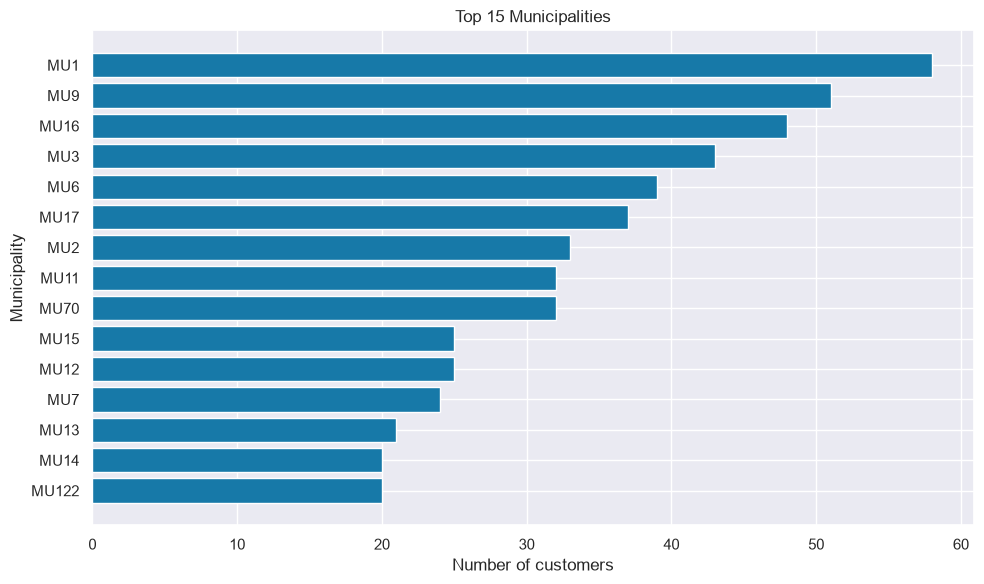

In [809]:
municipality_counts = clientes_raw["municipality"].value_counts().head(15)

municipality_labels = municipality_counts.index.str.extract(
    r"(MU\d+)", expand=False
)

plt.figure(figsize=(10, 6))

plt.barh(
    municipality_labels,
    municipality_counts.values,
    color=PLOT_BLUE
)

plt.xlabel("Number of customers")
plt.ylabel("Municipality")
plt.title("Top 15 Municipalities")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### city

In [810]:
column = "city"

city_counts = clientes_raw[column].value_counts()

print(f"Missing values: {clientes_raw[column].isna().sum()}")
print(f"Unique values: {clientes_raw[column].nunique()}")

print("\nTop 15 cities:")
display(city_counts.head(15))

print("\nCities appearing only once:")
print((city_counts == 1).sum())

print("\nPercentage of cities appearing only once:")
print(f"{(city_counts == 1).mean() * 100:.2f}%")

print("\nPercentage of customers in the top 15 cities:")
print(f"{city_counts.head(15).sum() / len(clientes_raw) * 100:.2f}%")

Missing values: 546
Unique values: 417

Top 15 cities:


city
City CY194: PowerPoint New Hills         14
City CY37: Conditional Format Borough    12
City CY151: Hidden Sheet Bay             10
City CY71: Spill Error Harbor             9
City CY185: Null Value Grove              9
City CY54: Final Final Harbor             9
City CY196: Pivot Table Hills             9
City CY69: Broken Formula Harbor          8
City CY190: Cached Result Grove           8
City CY147: VLOOKUP Bay                   8
City CY126: Final Final Crossing          8
City CY171: VLOOKUP Grove                 7
City CY163: Merged Cell Bay               6
City CY61: Conditional Format Harbor      6
City CY130: Unsorted Crossing             6
Name: count, dtype: int64


Cities appearing only once:
360

Percentage of cities appearing only once:
86.33%

Percentage of customers in the top 15 cities:
11.29%


### postal_area

In [811]:
column = "postal_area"

counts = clientes_raw[column].value_counts()

print(f"Missing values: {clientes_raw[column].isna().sum()}")
print(f"Unique values: {clientes_raw[column].nunique()}")

print("\nTop 15 postal areas:")
display(counts.head(15))

print("\nPostal areas appearing only once:")
print((counts == 1).sum())

print("\nPercentage of postal areas appearing only once:")
print(f"{(counts == 1).mean() * 100:.2f}%")

print("\nPercentage of customers in the top 15 postal areas:")
print(f"{counts.head(15).sum() / len(clientes_raw) * 100:.2f}%")

Missing values: 71
Unique values: 271

Top 15 postal areas:


postal_area
Postal area PA259: Hidden Sheet Sector    57
Postal area PA261: Hidden Sheet Sector    48
Postal area PA265: Hidden Sheet Sector    43
Postal area PA266: Hidden Sheet Sector    39
Postal area PA252: Hidden Sheet Sector    36
Postal area PA247: Hidden Sheet Sector    34
Postal area PA82: Hidden Sheet Sector     34
Postal area PA260: Hidden Sheet Sector    31
Postal area PA267: Hidden Sheet Sector    25
Postal area PA262: Hidden Sheet Sector    25
Postal area PA268: Hidden Sheet Sector    24
Postal area PA264: Hidden Sheet Sector    21
Postal area PA271: Hidden Sheet Sector    20
Postal area PA84: Hidden Sheet Sector     19
Postal area PA253: Hidden Sheet Sector    18
Name: count, dtype: int64


Postal areas appearing only once:
126

Percentage of postal areas appearing only once:
46.49%

Percentage of customers in the top 15 postal areas:
41.47%


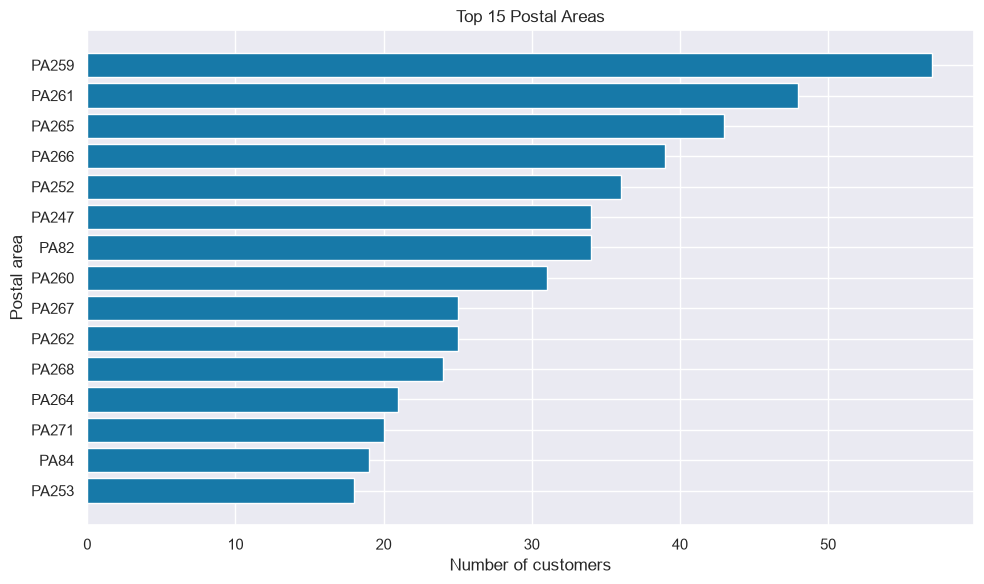

In [812]:
postal_counts = clientes_raw["postal_area"].value_counts().head(15)

postal_labels = postal_counts.index.str.extract(
    r"(PA\d+)", expand=False
)

plt.figure(figsize=(10, 6))

plt.barh(
    postal_labels,
    postal_counts.values,
    color=PLOT_BLUE
)

plt.xlabel("Number of customers")
plt.ylabel("Postal area")
plt.title("Top 15 Postal Areas")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### postal_code

In [814]:
column = "postal_code"

counts = clientes_raw[column].value_counts()

print(f"Missing values: {clientes_raw[column].isna().sum()}")
print(f"Unique values: {clientes_raw[column].nunique()}")

print("\nTop 15 postal codes:")
display(counts.head(15))

print("\nPostal codes appearing only once:")
print((counts == 1).sum())

print("\nPercentage of postal codes appearing only once:")
print(f"{(counts == 1).mean() * 100:.2f}%")

print("\nPercentage of customers in the top 15 postal codes:")
print(f"{counts.head(15).sum() / len(clientes_raw) * 100:.2f}%")

Missing values: 170
Unique values: 828

Top 15 postal codes:


postal_code
Postal code PC545: #REF! Delivery Route    6
Postal code PC676: #REF! Delivery Route    5
Postal code PC674: #REF! Delivery Route    5
Postal code PC603: #REF! Delivery Route    5
Postal code PC607: #REF! Delivery Route    4
Postal code PC568: #REF! Delivery Route    4
Postal code PC548: #REF! Delivery Route    4
Postal code PC540: #REF! Delivery Route    4
Postal code PC768: #REF! Delivery Route    3
Postal code PC766: #REF! Delivery Route    3
Postal code PC761: #REF! Delivery Route    3
Postal code PC758: #REF! Delivery Route    3
Postal code PC746: #REF! Delivery Route    3
Postal code PC745: #REF! Delivery Route    3
Postal code PC735: #REF! Delivery Route    3
Name: count, dtype: int64


Postal codes appearing only once:
721

Percentage of postal codes appearing only once:
87.08%

Percentage of customers in the top 15 postal codes:
5.07%


### street

In [815]:
column = "street"

counts = clientes_raw[column].value_counts()

print(f"Missing values: {clientes_raw[column].isna().sum()}")
print(f"Unique values: {clientes_raw[column].nunique()}")

print("\nTop 15 streets:")
display(counts.head(15))

print("\nStreets appearing only once:")
print((counts == 1).sum())

print("\nPercentage of streets appearing only once:")
print(f"{(counts == 1).mean() * 100:.2f}%")

print("\nPercentage of customers in the top 15 streets:")
print(f"{counts.head(15).sum() / len(clientes_raw) * 100:.2f}%")

Missing values: 598
Unique values: 511

Top 15 streets:


street
Street ST192: Last Save Walk              5
Street ST196: Pivot Table Drive           4
Street ST170: PowerPoint New Walk         3
Street ST59: AutoFill Avenue              3
Street ST98: PowerPoint New Crescent      3
Street ST167: Spill Error Way             2
Street ST169: Where-less Query Walk       2
Street ST83: AutoFill Road                2
Street ST173: Ctrl Z Walk                 2
Street ST69: Broken Formula Avenue        2
Street ST37: Conditional Format Lane      2
Street ST40: Nested IF Lane               2
Street ST48: Last Save Lane               2
Street ST162: Duplicate Row Way           2
Street ST128: Circular Reference Court    2
Name: count, dtype: int64


Streets appearing only once:
485

Percentage of streets appearing only once:
94.91%

Percentage of customers in the top 15 streets:
3.32%


### address

In [816]:
column = "address"

counts = clientes_raw[column].value_counts()

print(f"Missing values: {clientes_raw[column].isna().sum()}")
print(f"Unique values: {clientes_raw[column].nunique()}")

print("\nTop 15 addresses:")
display(counts.head(15))

print("\nAddresses appearing only once:")
print((counts == 1).sum())

print("\nPercentage of addresses appearing only once:")
print(f"{(counts == 1).mean() * 100:.2f}%")

print("\nPercentage of customers in the top 15 addresses:")
print(f"{counts.head(15).sum() / len(clientes_raw) * 100:.2f}%")

Missing values: 6
Unique values: 1120

Top 15 addresses:


address
Address AD489: Cell Without a Home    3
Address AD270: Cell Without a Home    2
Address AD461: Cell Without a Home    2
Address AD251: Cell Without a Home    2
Address AD433: Cell Without a Home    2
Address AD125: Cell Without a Home    2
Address AD484: Cell Without a Home    2
Address AD492: Cell Without a Home    2
Address AD506: Cell Without a Home    2
Address AD493: Cell Without a Home    2
Address AD373: Cell Without a Home    2
Address AD290: Cell Without a Home    2
Address AD414: Cell Without a Home    2
Address AD532: Cell Without a Home    2
Address AD726: Cell Without a Home    2
Name: count, dtype: int64


Addresses appearing only once:
1104

Percentage of addresses appearing only once:
98.57%

Percentage of customers in the top 15 addresses:
2.71%


### customer_type

All NaN values

### company_name

In [819]:
column = "company_name"

counts = clientes_raw[column].value_counts()

print(f"Missing values: {clientes_raw[column].isna().sum()}")
print(f"Unique values: {clientes_raw[column].nunique()}")

print("\nTop 10 companies:")
display(counts.head(10))

print("\nCompanies appearing only once:")
print((counts == 1).sum())

print("\nPercentage of companies appearing only once:")
print(f"{(counts == 1).mean() * 100:.2f}%")

Missing values: 0
Unique values: 1141

Top 10 companies:


company_name
Excel Is Not A Database Ltd 384     2
Excel Is Not A Database Ltd 664     2
Excel Is Not A Database Ltd 150     1
Excel Is Not A Database Ltd 1064    1
Excel Is Not A Database Ltd 113     1
Excel Is Not A Database Ltd 430     1
Excel Is Not A Database Ltd 673     1
Excel Is Not A Database Ltd 126     1
Excel Is Not A Database Ltd 125     1
Excel Is Not A Database Ltd 476     1
Name: count, dtype: int64


Companies appearing only once:
1139

Percentage of companies appearing only once:
99.82%


### customer_since_year

In [820]:
column = "customer_since_year"

print("Descriptive statistics:")
display(clientes_raw[column].describe())

print("\nAbsolute frequencies:")
display(clientes_raw[column].value_counts().sort_index())

print("\nRelative frequencies (%):")
display(
    (
        clientes_raw[column]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

Descriptive statistics:


count    1143.000000
mean     2016.999125
std         2.971405
min      2015.000000
25%      2015.000000
50%      2015.000000
75%      2018.000000
max      2026.000000
Name: customer_since_year, dtype: float64


Absolute frequencies:


customer_since_year
2015    664
2016     53
2017     82
2018     61
2019     47
2020     50
2021     52
2022     43
2023     29
2024     31
2025     18
2026     13
Name: count, dtype: int64


Relative frequencies (%):


customer_since_year
2015    58.09
2016     4.64
2017     7.17
2018     5.34
2019     4.11
2020     4.37
2021     4.55
2022     3.76
2023     2.54
2024     2.71
2025     1.57
2026     1.14
Name: proportion, dtype: float64

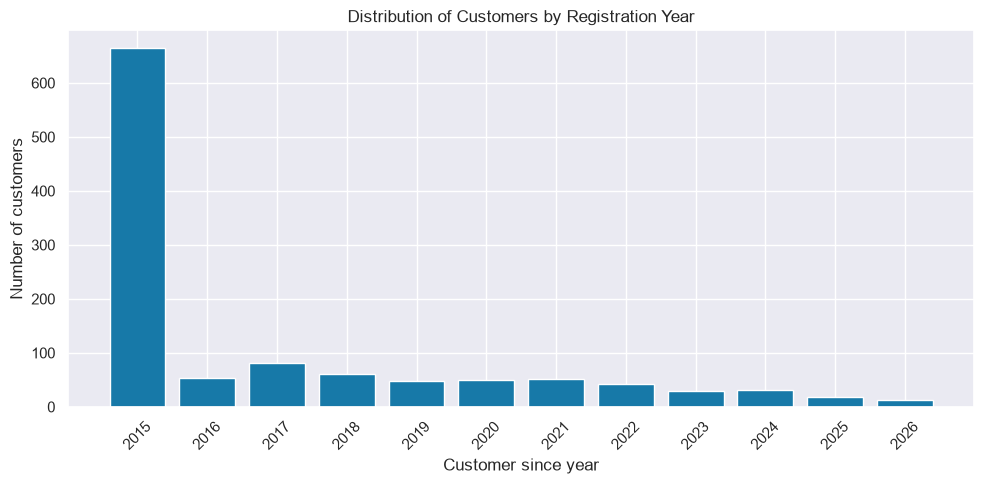

In [821]:
year_counts = clientes_raw["customer_since_year"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

plt.bar(
    year_counts.index,
    year_counts.values,
    color=PLOT_BLUE
)

plt.xlabel("Customer since year")
plt.ylabel("Number of customers")
plt.title("Distribution of Customers by Registration Year")

plt.xticks(year_counts.index, rotation=45)
plt.tight_layout()
plt.show()

## Multivariant Analisis clientes_raw

### postal_area vs commercial_region

In [823]:
region_counts = (
    clientes_raw
    .groupby("postal_area")["commercial_region"]
    .nunique()
)

print("Postal areas associated with multiple commercial regions:")
print((region_counts > 1).sum())

print("\nTotal postal areas analyzed:")
print(len(region_counts))

print("\nDistribution of commercial regions per postal area:")
display(region_counts.value_counts().sort_index())

Postal areas associated with multiple commercial regions:
0

Total postal areas analyzed:
271

Distribution of commercial regions per postal area:


commercial_region
0     19
1    252
Name: count, dtype: int64

In [824]:
postal_areas_per_region = (
    clientes_raw
    .groupby("commercial_region")["postal_area"]
    .nunique()
)

print("Commercial regions associated with multiple postal areas:")
print((postal_areas_per_region > 1).sum())

print("\nTotal commercial regions analyzed:")
print(len(postal_areas_per_region))

print("\nDescriptive statistics:")
display(postal_areas_per_region.describe())

print("\nTop 10 regions by number of postal areas:")
display(postal_areas_per_region.sort_values(ascending=False).head(10))

Commercial regions associated with multiple postal areas:
20

Total commercial regions analyzed:
37

Descriptive statistics:


count    37.000000
mean      6.810811
std       8.332793
min       0.000000
25%       0.000000
50%       3.000000
75%      13.000000
max      26.000000
Name: postal_area, dtype: float64


Top 10 regions by number of postal areas:


commercial_region
Region RG17: We Will See Later    26
Region RG28: We Will See Later    24
Region RG31: We Will See Later    22
Region RG18: We Will See Later    21
Region RG33: We Will See Later    18
Region RG27: We Will See Later    17
Region RG23: We Will See Later    17
Region RG32: We Will See Later    16
Region RG29: We Will See Later    13
Region RG19: We Will See Later    13
Name: postal_area, dtype: int64

### postal_code vs postal_area

In [826]:
areas_per_postal_code = (
    clientes_raw
    .groupby("postal_code")["postal_area"]
    .nunique()
)

print("Postal codes associated with multiple postal areas:")
print((areas_per_postal_code > 1).sum())

print("\nTotal postal codes analyzed:")
print(len(areas_per_postal_code))

print("\nDistribution of postal areas per postal code:")
display(areas_per_postal_code.value_counts().sort_index())

Postal codes associated with multiple postal areas:
0

Total postal codes analyzed:
828

Distribution of postal areas per postal code:


postal_area
0     57
1    771
Name: count, dtype: int64

In [827]:
postal_codes_per_area = (
    clientes_raw
    .groupby("postal_area")["postal_code"]
    .nunique()
)

print("Postal areas associated with multiple postal codes:")
print((postal_codes_per_area > 1).sum())

print("\nTotal postal areas analyzed:")
print(len(postal_codes_per_area))

print("\nDescriptive statistics:")
display(postal_codes_per_area.describe())

print("\nTop 10 postal areas by number of postal codes:")
display(postal_codes_per_area.sort_values(ascending=False).head(10))

Postal areas associated with multiple postal codes:
121

Total postal areas analyzed:
271

Descriptive statistics:


count    271.000000
mean       2.845018
std        4.716202
min        0.000000
25%        1.000000
50%        1.000000
75%        3.000000
max       37.000000
Name: postal_code, dtype: float64


Top 10 postal areas by number of postal codes:


postal_area
Postal area PA259: Hidden Sheet Sector    37
Postal area PA261: Hidden Sheet Sector    27
Postal area PA247: Hidden Sheet Sector    26
Postal area PA260: Hidden Sheet Sector    25
Postal area PA265: Hidden Sheet Sector    21
Postal area PA266: Hidden Sheet Sector    21
Postal area PA267: Hidden Sheet Sector    20
Postal area PA268: Hidden Sheet Sector    19
Postal area PA262: Hidden Sheet Sector    18
Postal area PA264: Hidden Sheet Sector    18
Name: postal_code, dtype: int64

Hierarchy:

postal_code -> postal_area -> commercial region

### Is it possible to retrive postal_area missings?

In [830]:
missing_area = clientes_raw["postal_area"].isna()

print("Total missing postal_area:")
print(missing_area.sum())

print("\nMissing postal_area with postal_code available:")
print(
    (
        missing_area
        & clientes_raw["postal_code"].notna()
    ).sum()
)

print("\nMissing postal_area with postal_code also missing:")
print(
    (
        missing_area
        & clientes_raw["postal_code"].isna()
    ).sum()
)

Total missing postal_area:
71

Missing postal_area with postal_code available:
60

Missing postal_area with postal_code also missing:
11


In [831]:
# Build a mapping using known postal codes and postal areas
postal_mapping = (
    clientes_raw
    .dropna(subset=["postal_code", "postal_area"])
    .drop_duplicates(subset=["postal_code"])
    .set_index("postal_code")["postal_area"]
)

# Identify customers with missing postal_area
missing_area = clientes_raw["postal_area"].isna()

# Find their corresponding postal areas using the mapping
recoverable_areas = (
    clientes_raw.loc[missing_area, "postal_code"]
    .map(postal_mapping)
)

print("Total missing postal_area:")
print(missing_area.sum())

print("\nMissing values potentially recoverable:")
print(recoverable_areas.notna().sum())

print("\nMissing values not recoverable:")
print(recoverable_areas.isna().sum())

Total missing postal_area:
71

Missing values potentially recoverable:
0

Missing values not recoverable:
71


### Is it possible to retrive commercial_region missings?

In [832]:
# Build a mapping from postal_area to commercial_region
region_mapping = (
    clientes_raw
    .dropna(subset=["postal_area", "commercial_region"])
    .drop_duplicates(subset=["postal_area"])
    .set_index("postal_area")["commercial_region"]
)

# Identify missing commercial regions
missing_region = clientes_raw["commercial_region"].isna()

# Try to recover missing regions
recoverable_regions = (
    clientes_raw.loc[missing_region, "postal_area"]
    .map(region_mapping)
)

print("Total missing commercial_region:")
print(missing_region.sum())

print("\nMissing values potentially recoverable:")
print(recoverable_regions.notna().sum())

print("\nMissing values not recoverable:")
print(recoverable_regions.isna().sum())

Total missing commercial_region:
114

Missing values potentially recoverable:
69

Missing values not recoverable:
45


In [833]:
# Identify missing regions that could not be recovered
not_recoverable = recoverable_regions.isna()

unresolved_clients = clientes_raw.loc[
    recoverable_regions.index[not_recoverable]
]

print("Total unresolved commercial regions:")
print(len(unresolved_clients))

print("\nWith postal_area missing:")
print(unresolved_clients["postal_area"].isna().sum())

print("\nWith postal_area available but no mapping:")
print(unresolved_clients["postal_area"].notna().sum())

Total unresolved commercial regions:
45

With postal_area missing:
24

With postal_area available but no mapping:
21


### Geographic consistency and missing value recovery

The analysis identified a hierarchical relationship between geographic variables:

`postal_code` → `postal_area` → `commercial_region`

Each postal code maps to at most one postal area, and each postal area maps to at most one commercial region in the observed data.

However, the usefulness of these relationships for missing value imputation differs:

- **postal_area:** None of the 71 missing values could be recovered using postal codes.
- **commercial_region:** 69 of the 114 missing values (60.53%) could potentially be recovered using postal areas.
- Of the remaining 45 missing commercial regions, 24 have no postal area and 21 have a postal area without a known region mapping.

These findings suggest that geographic relationships could support missing value imputation during preprocessing. Any mapping used for model development must be fitted without using validation data.

### municipality vs commercial_region

In [834]:
regions_per_municipality = (
    clientes_raw
    .groupby("municipality")["commercial_region"]
    .nunique()
)

print("Municipalities associated with multiple commercial regions:")
print((regions_per_municipality > 1).sum())

print("\nTotal municipalities analyzed:")
print(len(regions_per_municipality))

print("\nDistribution of commercial regions per municipality:")
display(regions_per_municipality.value_counts().sort_index())

Municipalities associated with multiple commercial regions:
0

Total municipalities analyzed:
183

Distribution of commercial regions per municipality:


commercial_region
1    183
Name: count, dtype: int64

In [835]:
# Build municipality → commercial_region mapping
municipality_mapping = (
    clientes_raw
    .dropna(subset=["municipality", "commercial_region"])
    .drop_duplicates(subset=["municipality"])
    .set_index("municipality")["commercial_region"]
)

# Identify the 45 missing regions not recoverable through postal_area
unresolved_index = recoverable_regions[
    recoverable_regions.isna()
].index

# Try recovering them using municipality
recoverable_by_municipality = (
    clientes_raw.loc[unresolved_index, "municipality"]
    .map(municipality_mapping)
)

print("Previously unresolved commercial regions:")
print(len(unresolved_index))

print("\nAdditional values recoverable using municipality:")
print(recoverable_by_municipality.notna().sum())

print("\nStill unresolved:")
print(recoverable_by_municipality.isna().sum())

Previously unresolved commercial regions:
45

Additional values recoverable using municipality:
0

Still unresolved:
45


### municipality vs postal_area

In [837]:
areas_per_municipality = (
    clientes_raw
    .groupby("municipality")["postal_area"]
    .nunique()
)

print("Municipalities associated with multiple postal areas:")
print((areas_per_municipality > 1).sum())

print("\nTotal municipalities analyzed:")
print(len(areas_per_municipality))

print("\nDistribution of postal areas per municipality:")
display(areas_per_municipality.value_counts().sort_index())

Municipalities associated with multiple postal areas:
46

Total municipalities analyzed:
183

Distribution of postal areas per municipality:


postal_area
1    137
2     25
3     12
4      9
Name: count, dtype: int64

In [838]:
municipalities_per_area = (
    clientes_raw
    .groupby("postal_area")["municipality"]
    .nunique()
)

print("Postal areas associated with multiple municipalities:")
print((municipalities_per_area > 1).sum())

print("\nTotal postal areas analyzed:")
print(len(municipalities_per_area))

print("\nDistribution of municipalities per postal area:")
display(municipalities_per_area.value_counts().sort_index())

Postal areas associated with multiple municipalities:
6

Total postal areas analyzed:
271

Distribution of municipalities per postal area:


municipality
0     19
1    246
2      5
3      1
Name: count, dtype: int64

In [839]:
# Select postal areas associated with multiple municipalities
multi_municipality_areas = municipalities_per_area[
    municipalities_per_area > 1
].index

# Inspect their geographic relationships
geographic_consistency = (
    clientes_raw[
        clientes_raw["postal_area"].isin(multi_municipality_areas)
    ]
    .groupby("postal_area")
    .agg(
        municipalities=("municipality", "nunique"),
        commercial_regions=("commercial_region", "nunique")
    )
)

display(geographic_consistency)

,municipalities,commercial_regions
postal_area,,
Postal area PA106: Hidden Sheet Sector,2,1
Postal area PA119: Hidden Sheet Sector,2,1
Postal area PA30: Hidden Sheet Sector,3,1
Postal area PA39: Hidden Sheet Sector,2,1
Postal area PA61: Hidden Sheet Sector,2,1
Postal area PA84: Hidden Sheet Sector,2,1


### island vs commercial_region

In [840]:
regions_per_island = (
    clientes_raw
    .groupby("island")["commercial_region"]
    .nunique()
)

print("Islands associated with multiple commercial regions:")
print((regions_per_island > 1).sum())

print("\nTotal islands analyzed:")
print(len(regions_per_island))

print("\nDistribution of commercial regions per island:")
display(regions_per_island.value_counts().sort_index())

print("\nCommercial regions per island:")
display(regions_per_island.sort_values(ascending=False))

Islands associated with multiple commercial regions:
0

Total islands analyzed:
10

Distribution of commercial regions per island:


commercial_region
1    10
Name: count, dtype: int64


Commercial regions per island:


island
Island IS10: The Pivot Archipelago    1
Island IS1: The Pivot Archipelago     1
Island IS2: The Pivot Archipelago     1
Island IS3: The Pivot Archipelago     1
Island IS4: The Pivot Archipelago     1
Island IS5: The Pivot Archipelago     1
Island IS6: The Pivot Archipelago     1
Island IS7: The Pivot Archipelago     1
Island IS8: The Pivot Archipelago     1
Island IS9: The Pivot Archipelago     1
Name: commercial_region, dtype: int64

In [841]:
# Build island → commercial_region mapping
island_mapping = (
    clientes_raw
    .dropna(subset=["island", "commercial_region"])
    .drop_duplicates(subset=["island"])
    .set_index("island")["commercial_region"]
)

# Identify the 45 previously unresolved customers
unresolved_index = recoverable_regions[
    recoverable_regions.isna()
].index

# Try recovering their commercial regions using island
recoverable_by_island = (
    clientes_raw.loc[unresolved_index, "island"]
    .map(island_mapping)
)

print("Previously unresolved commercial regions:")
print(len(unresolved_index))

print("\nAdditional values recoverable using island:")
print(recoverable_by_island.notna().sum())

print("\nStill unresolved:")
print(recoverable_by_island.isna().sum())

Previously unresolved commercial regions:
45

Additional values recoverable using island:
0

Still unresolved:
45


In [842]:
islands_per_region = (
    clientes_raw
    .groupby("commercial_region")["island"]
    .nunique()
)

print("Commercial regions associated with multiple islands:")
print((islands_per_region > 1).sum())

print("\nTotal commercial regions analyzed:")
print(len(islands_per_region))

print("\nDistribution of islands per commercial region:")
display(islands_per_region.value_counts().sort_index())

print("\nCommercial regions with islands:")
display(islands_per_region[islands_per_region > 0])

Commercial regions associated with multiple islands:
2

Total commercial regions analyzed:
37

Distribution of islands per commercial region:


island
0    35
2     1
8     1
Name: count, dtype: int64


Commercial regions with islands:


commercial_region
Region RG17: We Will See Later    8
Region RG29: We Will See Later    2
Name: island, dtype: int64

In [843]:
island_missing_by_region = (
    clientes_raw
    .assign(island_missing=clientes_raw["island"].isna())
    .groupby("commercial_region", dropna=False)
    .agg(
        total_customers=("island_missing", "size"),
        missing_island=("island_missing", "sum"),
        missing_percentage=("island_missing", lambda x: x.mean() * 100)
    )
)

display(
    island_missing_by_region
    .sort_values("total_customers", ascending=False)
    .round(2)
)

,total_customers,missing_island,missing_percentage
commercial_region,,,
Region RG17: We Will See Later,519,0,0.0
NaN,114,114,100.0
Region RG23: We Will See Later,63,63,100.0
Region RG18: We Will See Later,59,59,100.0
Region RG29: We Will See Later,46,0,0.0
Region RG31: We Will See Later,41,41,100.0
Region RG27: We Will See Later,39,39,100.0
Region RG28: We Will See Later,36,36,100.0
Region RG32: We Will See Later,31,31,100.0


### Missingness pattern in island

The missingness of `island` is strongly associated with `commercial_region`.

- All 519 customers in RG17 have a recorded island.
- All 46 customers in RG29 have a recorded island.
- All 464 customers belonging to the other 35 commercial regions have missing island values.
- All 114 customers with an unknown commercial region also have missing island values.

This suggests that `island` may only be applicable to specific geographic regions.

Missing values should therefore not automatically be treated as random. A distinction between potentially non-applicable values and genuinely unknown geographic information may be useful during preprocessing.

### island vs country_or_region

In [844]:
island_by_country = (
    clientes_raw
    .assign(island_available=clientes_raw["island"].notna())
    .groupby("country_or_region")
    .agg(
        total_customers=("island_available", "size"),
        island_available=("island_available", "sum"),
        island_missing=("island_available", lambda x: (~x).sum()),
        available_percentage=("island_available", lambda x: x.mean() * 100)
    )
)

display(
    island_by_country
    .sort_values("total_customers", ascending=False)
    .round(2)
)

,total_customers,island_available,island_missing,available_percentage
country_or_region,,,,
Country CT10: Land of The Final Version,1079,565,514,52.36
Country CT5: Land of The Final Version,49,0,49,0.00
Country CT4: Land of The Final Version,4,0,4,0.00
Country CT6: Land of The Final Version,3,0,3,0.00
Country CT7: Land of The Final Version,2,0,2,0.00
Country CT11: Land of The Final Version,1,0,1,0.00
Country CT1: Land of The Final Version,1,0,1,0.00
Country CT2: Land of The Final Version,1,0,1,0.00
Country CT3: Land of The Final Version,1,0,1,0.00


### Relationship between country_or_region and island

All 565 customers with a recorded island belong to CT10.

However, CT10 contains both customers with an island (565) and customers without one (514). The remaining 10 countries have no recorded island values.

Therefore, `country_or_region` alone does not determine whether `island` is populated.

In contrast, `commercial_region` shows a deterministic missingness pattern in the observed data: only RG17 and RG29 have recorded island values.

### country_or_region vs commercial_region

In [846]:
countries_per_region = (
    clientes_raw
    .groupby("commercial_region")["country_or_region"]
    .nunique()
)

print("Commercial regions associated with multiple countries:")
print((countries_per_region > 1).sum())

print("\nTotal commercial regions analyzed:")
print(len(countries_per_region))

print("\nDistribution of countries per commercial region:")
display(countries_per_region.value_counts().sort_index())

Commercial regions associated with multiple countries:
0

Total commercial regions analyzed:
37

Distribution of countries per commercial region:


country_or_region
1    37
Name: count, dtype: int64

In [847]:
regions_per_country = (
    clientes_raw
    .groupby("country_or_region")["commercial_region"]
    .nunique()
)

print("Countries associated with multiple commercial regions:")
print((regions_per_country > 1).sum())

print("\nTotal countries analyzed:")
print(len(regions_per_country))

print("\nCommercial regions per country:")
display(regions_per_country.sort_values(ascending=False))

Countries associated with multiple commercial regions:
3

Total countries analyzed:
11

Commercial regions per country:


country_or_region
Country CT10: Land of The Final Version    20
Country CT5: Land of The Final Version     13
Country CT6: Land of The Final Version      2
Country CT11: Land of The Final Version     1
Country CT2: Land of The Final Version      1
Country CT1: Land of The Final Version      0
Country CT3: Land of The Final Version      0
Country CT4: Land of The Final Version      0
Country CT7: Land of The Final Version      0
Country CT8: Land of The Final Version      0
Country CT9: Land of The Final Version      0
Name: commercial_region, dtype: int64

## Multivariant Analysis train_raw

In [703]:
def comparission_of_top10(columns_name: list, dataframe):
    top10s = {}
    for column in columns_name:
        top10s[column] = set(dataframe.nlargest(10, column).index)
    
    common_purchases = {}

    for column_i in columns_name:
        common_purchases[column_i] = {}
        for column_j in columns_name:
            if column_i != column_j:
                common_purchases[column_i][column_j] = len(top10s[column_i].intersection(top10s[column_j]))


    for column_i in columns_name:  
        print(f"\nColumn {column_i} have the following top10 in common with:")
        for column_j in columns_name:
            if column_i != column_j:
                print(f"     Column {column_j}: {common_purchases[column_i][column_j]}")

### Comparision Totales

In [704]:
list_of_columns = ["Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Total Portes", "Total Desc_ Global", "Total Desc_ Linha", "Custo", "N_ Detalhes", "prior_total_spend"]


comparission_of_top10(list_of_columns, train_raw)


Column Total a Pagar have the following top10 in common with:
     Column Total Bruto: 5
     Column Total Liquido: 8
     Column Total Imp_: 9
     Column Total Portes: 0
     Column Total Desc_ Global: 0
     Column Total Desc_ Linha: 2
     Column Custo: 6
     Column N_ Detalhes: 3
     Column prior_total_spend: 1

Column Total Bruto have the following top10 in common with:
     Column Total a Pagar: 5
     Column Total Liquido: 6
     Column Total Imp_: 5
     Column Total Portes: 1
     Column Total Desc_ Global: 0
     Column Total Desc_ Linha: 6
     Column Custo: 4
     Column N_ Detalhes: 5
     Column prior_total_spend: 1

Column Total Liquido have the following top10 in common with:
     Column Total a Pagar: 8
     Column Total Bruto: 6
     Column Total Imp_: 7
     Column Total Portes: 0
     Column Total Desc_ Global: 0
     Column Total Desc_ Linha: 2
     Column Custo: 4
     Column N_ Detalhes: 5
     Column prior_total_spend: 1

Column Total Imp_ have the following

In [705]:
train_raw.loc[train_raw["invoice_count_current_purchase"] > 1].sort_values(["customer_id", "purchase_date"]).T


ID,10002365,10001196,10003556,10005386,10004528,10002086,10000594,10001316,10006642,10004146,...,10004813,10006455,10000462,10007328,10000766,10004428,10005729,10003931,10005096,10005837
Total a Pagar,526.3,100.44,459.94,185.38,226.53,719.18,141.15,109.32,10.92,274.17,...,8267.87,6637.62,6207.37,4047.97,1372.35,154.72,631.33,352.32,1001.39,1015.52
Total Bruto,752.3,168.5,618.7,222.96,245.26,993.3,191.25,133.5,14.8,331.57,...,7316.7,5874.0,6978.2,4645.44,1121.44,127.8,525.25,287.54,995.26,825.62
Total Liquido,427.88,81.66,373.94,150.71,184.17,584.7,114.75,88.88,8.88,222.9,...,7316.7,5874.0,5046.64,3291.04,1121.44,127.8,513.27,287.54,814.14,825.62
Total Imp_,98.42,18.78,86.0,34.67,42.36,134.48,26.4,20.44,2.04,51.27,...,951.17,763.62,1160.73,756.93,250.91,26.92,118.06,64.78,187.25,189.9
Total Portes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,10.8,0.0,5.9,0.0,0.0
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0,11.28,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Total Desc_ Linha,324.42,86.84,244.76,72.25,61.09,397.32,76.5,44.62,5.92,108.67,...,0.0,0.0,1931.56,1354.4,0.0,0.0,11.98,0.0,181.12,0.0
Custo,203.25,33.85,146.834,83.756848,96.936044,20.2,56.814,9.2,0.0,150.91,...,0.0,0.0,3063.043372,2332.642681,653.791087,36.0,210.502093,0.0,345.540612,462.120457
N_ Detalhes,9.0,11.0,22.0,5.0,2.0,18.0,10.0,2.0,2.0,8.0,...,5.0,5.0,97.0,63.0,67.0,2.0,16.0,7.0,32.0,97.0
invoice_count_current_purchase,3.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0


In [706]:
dataset_invoice_no_nans = train_raw.dropna(subset=["invoice_count_current_purchase"])
customers_multiple_purchases = dataset_invoice_no_nans["customer_id"].value_counts()
customers_multiple_purchases = customers_multiple_purchases[customers_multiple_purchases > 1]
print(f"Number of customers that have recorded only 1 purchase (not including purchases recorded with invoice_count_current_purchase NaN): {len(dataset_invoice_no_nans["customer_id"].value_counts())- len(customers_multiple_purchases)}")
print(f"Total of customers with more than 1 purchase in the dataset (not including records that invoice_count_current_purchase is NaN): {len(customers_multiple_purchases)}")
variablity_invoice_pur = dataset_invoice_no_nans[dataset_invoice_no_nans["customer_id"].isin(customers_multiple_purchases.index)].groupby("customer_id")["invoice_count_current_purchase"].nunique()

print(f"Customers with 1 invoice count: {(variablity_invoice_pur == 1).sum()}, represent the {((variablity_invoice_pur == 1).sum() / len(customers_multiple_purchases) * 100):.2f}% of the different clients not including the ones with only one purchase recorded")
print(f"Customers with 2 invoice count: {(variablity_invoice_pur == 2).sum()}, represent the {((variablity_invoice_pur == 2).sum() / len(customers_multiple_purchases) * 100):.2f}% of the different clients not including the ones with only one purchase recorded")
print(f"Customers with 3 invoice count: {(variablity_invoice_pur == 3).sum()}, represent the {((variablity_invoice_pur == 3).sum() / len(customers_multiple_purchases) * 100):.2f}% of the different clients not including the ones with only one purchase recorded")
print(f"Customers with 4 invoice count: {(variablity_invoice_pur == 4).sum()}, represent the {((variablity_invoice_pur == 4).sum() / len(customers_multiple_purchases) * 100):.2f}% of the different clients not including the ones with only one purchase recorded")
print(f"Customers with 5 invoice count: {(variablity_invoice_pur == 5).sum()}, represent the {((variablity_invoice_pur == 5).sum() / len(customers_multiple_purchases) * 100):.2f}% of the different clients not including the ones with only one purchase recorded")


Number of customers that have recorded only 1 purchase (not including purchases recorded with invoice_count_current_purchase NaN): 157
Total of customers with more than 1 purchase in the dataset (not including records that invoice_count_current_purchase is NaN): 450
Customers with 1 invoice count: 337, represent the 74.89% of the different clients not including the ones with only one purchase recorded
Customers with 2 invoice count: 97, represent the 21.56% of the different clients not including the ones with only one purchase recorded
Customers with 3 invoice count: 15, represent the 3.33% of the different clients not including the ones with only one purchase recorded
Customers with 4 invoice count: 1, represent the 0.22% of the different clients not including the ones with only one purchase recorded
Customers with 5 invoice count: 0, represent the 0.00% of the different clients not including the ones with only one purchase recorded


After this, we see that invoice_count_current_purchase most of the values are 1, representing 93.60% of that column, then, we wanted to know more about this field, we took a look of all the records that had more than 1 invoice_count_current_purchase, to see if they had something in common, but weren't able to detect anything, later on, we wanted to check if it might be that the same customer always have the same invoice_count_current_purchase to see if it might be related, and we observed the following, from the 610 unique customer_id, 607 had at least one valid invoice count in the dataframe, after excluding missing values, 157 records have only one valid purchase, and the number of customers with two or more valid purchases are 450 customers, from these the 74.89% they always use the same invoice_count_current_purchase, 21.56% have 2 invoice count, 3.33% have 3, and finally only 4 has 0.22%, which means that usually the same customers use the same invoice, not really usual to change them

In [707]:
train_raw.loc[train_raw["customer_tenure_days"] == 0, "days_since_previous_purchase"].describe()

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: days_since_previous_purchase, dtype: float64

In [708]:
train_raw.loc[train_raw["customer_tenure_days"] == 0, "days_since_previous_purchase"].isna().sum()

np.int64(603)

From the 861 missing values from days_since_previous_purchase, we know that 603, are because if customer_tenure_days = 0 is that is the first purchase, and that's why days_since_previous_purchase is NaN, but, we still have 861 - 603 = 258 that we can't explain yet

In [709]:
mask_prior_zero = train_raw["prior_purchase_count"] == 0
mask_tenure_zero = train_raw["customer_tenure_days"] == 0

print("Both equal zero:", (mask_prior_zero & mask_tenure_zero).sum())
print("Prior zero, tenure not zero:", (mask_prior_zero & ~mask_tenure_zero).sum())
print("Tenure zero, prior not zero:", (~mask_prior_zero & mask_tenure_zero).sum())

Both equal zero: 603
Prior zero, tenure not zero: 0
Tenure zero, prior not zero: 0


In [710]:
train_raw.loc[
    train_raw["prior_purchase_count"] == 0,
    "prior_mean_purchase_value"
].value_counts(dropna=False)

prior_mean_purchase_value
NaN    603
Name: count, dtype: int64

In [711]:
mask = (
    train_raw["prior_mean_purchase_value"].isna()
    & (train_raw["prior_purchase_count"] > 0)
)

print("Missing values with previous purchases:", mask.sum())

Missing values with previous purchases: 194


In [712]:
inconsistent_mask = valid_mask & ~np.isclose(
    train_raw["prior_mean_purchase_value"],
    expected_mean,
    atol=0.01
)

print("Number of inconsistent values:", inconsistent_mask.sum())

train_raw.loc[
    inconsistent_mask,
    [
        "customer_id",
        "prior_total_spend",
        "prior_purchase_count",
        "prior_mean_purchase_value"
    ]
]

Number of inconsistent values: 46


,customer_id,prior_total_spend,prior_purchase_count,prior_mean_purchase_value
ID,,,,
10000556,795676,11589.56,9.0,13325.783819
10000712,120503,7390.05,16.0,11142.309979
10000733,258332,150673.10,173.0,11047.015485
10000746,469322,727.53,4.0,3903.726570
10000792,568558,2108.85,5.0,10256.010317
10000867,969767,1374.31,6.0,4490.771262
10001118,209685,2837.99,7.0,4009.048479
10001280,258332,145716.62,168.0,15228.223787
10001317,781977,19765.19,8.0,30448.603306


In [713]:
train_raw.loc[
    train_raw["prior_purchase_count"] == 0,
    "prior_min_purchase_value"
].value_counts(dropna=False)

prior_min_purchase_value
NaN    603
Name: count, dtype: int64

In [714]:
expected_mean = train_raw["prior_total_spend"] / train_raw["prior_purchase_count"]

valid_mask = (
    (train_raw["prior_purchase_count"] > 0)
    & train_raw["prior_mean_purchase_value"].notna()
    & (train_raw["prior_mean_purchase_value"] > 0)
    & (train_raw["prior_mean_purchase_value"] != 1e9)
)

np.isclose(
    train_raw.loc[valid_mask, "prior_mean_purchase_value"],
    expected_mean.loc[valid_mask],
    atol=0.01
).mean() * 100

np.float64(99.18439716312056)

In [715]:
train_raw.loc[
    train_raw["prior_purchase_count"].isin([0, 1]),
    ["prior_purchase_count", "prior_std_purchase_value"]
].groupby("prior_purchase_count", dropna=False)["prior_std_purchase_value"].agg(
    ["count", "size", "min", "max"]
)

,count,size,min,max
prior_purchase_count,,,,
0.0,0,603,NaN,NaN
1.0,0,445,NaN,NaN


In [716]:
train_raw.loc[
    train_raw["prior_purchase_count"].isin([0, 1]),
    ["prior_purchase_count", "prior_mean_gap_days"]
].groupby("prior_purchase_count")["prior_mean_gap_days"].agg(
    ["count", "size", "min", "max"]
)

,count,size,min,max
prior_purchase_count,,,,
0.0,0,603,NaN,NaN
1.0,0,445,NaN,NaN


In [717]:
mask_gap = train_raw["prior_mean_gap_days"] < 0
mask_previous = train_raw["days_since_previous_purchase"] < 0

print("Both negative:", (mask_gap & mask_previous).sum())
print("Only prior_mean_gap_days negative:", (mask_gap & ~mask_previous).sum())
print("Only days_since_previous_purchase negative:", (~mask_gap & mask_previous).sum())

Both negative: 0
Only prior_mean_gap_days negative: 16
Only days_since_previous_purchase negative: 16


In [718]:
train_raw.loc[
    train_raw["prior_purchase_count"].isin([0, 1, 2]),
    ["prior_purchase_count", "prior_std_gap_days"]
].groupby("prior_purchase_count")["prior_std_gap_days"].agg(
    ["count", "size", "min", "max"]
)

,count,size,min,max
prior_purchase_count,,,,
0.0,0,603,NaN,NaN
1.0,0,445,NaN,NaN
2.0,0,365,NaN,NaN


In [719]:
mask = (
    train_raw["prior_mean_gap_days"].isna()
    & (train_raw["prior_purchase_count"] >= 2)
)

print("Missing values with at least 2 previous purchases:", mask.sum())

Missing values with at least 2 previous purchases: 195


### Correlation Analysis

In [852]:
numeric_features = (
    train_raw
    .select_dtypes(include="number")
    .drop(columns=[TARGET, "customer_id"], errors="ignore")
)

correlation_matrix = numeric_features.corr()

correlation_matrix = numeric_features.corr()

print("Number of numerical features:", numeric_features.shape[1])

with pd.option_context("display.max_columns", None):
    display(correlation_matrix.round(2))

Number of numerical features: 29


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,random_noise
Total a Pagar,1.00,0.97,1.00,0.90,0.00,0.04,0.56,0.82,0.61,0.16,0.02,0.16,0.02,0.36,-0.01,0.49,0.11,0.22,-0.07,-0.08,-0.15,0.02,-0.12,0.09,-0.09,0.24,-0.06,-0.01,0.02
Total Bruto,0.97,1.00,0.98,0.81,0.05,0.03,0.72,0.79,0.62,0.16,0.02,0.14,0.03,0.34,-0.01,0.49,0.14,0.22,-0.07,-0.07,-0.12,0.02,-0.09,0.10,-0.07,0.23,-0.04,-0.01,0.01
Total Liquido,1.00,0.98,1.00,0.86,0.01,0.03,0.59,0.80,0.60,0.15,0.02,0.15,0.02,0.35,-0.01,0.50,0.13,0.22,-0.07,-0.07,-0.15,0.01,-0.12,0.09,-0.09,0.23,-0.07,-0.01,0.02
Total Imp_,0.90,0.81,0.86,1.00,-0.06,0.04,0.35,0.80,0.59,0.17,0.00,0.19,0.05,0.35,-0.00,0.41,-0.01,0.20,-0.09,-0.09,-0.13,0.03,-0.09,0.09,-0.07,0.25,-0.04,-0.01,0.02
Total Portes,0.00,0.05,0.01,-0.06,1.00,-0.00,0.17,-0.02,-0.02,0.05,0.03,-0.07,-0.00,0.01,-0.01,-0.02,0.03,-0.02,0.01,0.03,0.01,0.02,0.02,0.04,0.01,0.03,0.01,-0.00,-0.01
Total Desc_ Global,0.04,0.03,0.03,0.04,-0.00,1.00,0.01,0.05,0.02,0.00,0.02,-0.02,-0.03,-0.02,-0.00,-0.00,0.01,-0.01,0.02,0.04,-0.03,-0.02,-0.03,-0.03,-0.03,-0.03,-0.03,-0.00,-0.01
Total Desc_ Linha,0.56,0.72,0.59,0.35,0.17,0.01,1.00,0.49,0.49,0.14,0.00,0.04,0.09,0.19,-0.01,0.27,0.13,0.12,-0.05,-0.04,0.02,0.03,0.06,0.11,0.06,0.17,0.07,0.00,0.00
Custo,0.82,0.79,0.80,0.80,-0.02,0.05,0.49,1.00,0.66,0.19,0.02,0.14,0.00,0.22,-0.00,0.35,0.07,0.16,-0.05,-0.06,-0.14,0.00,-0.12,0.05,-0.09,0.18,-0.07,-0.01,0.02
N_ Detalhes,0.61,0.62,0.60,0.59,-0.02,0.02,0.49,0.66,1.00,0.18,0.08,0.06,-0.01,0.13,-0.00,0.20,0.07,0.09,-0.04,-0.05,-0.13,-0.04,-0.11,-0.02,-0.08,0.08,-0.06,-0.00,0.02
invoice_count_current_purchase,0.16,0.16,0.15,0.17,0.05,0.00,0.14,0.19,0.18,1.00,-0.03,0.01,0.05,0.10,-0.00,0.10,-0.01,0.05,-0.06,-0.05,0.03,0.06,0.05,0.09,0.05,0.11,0.05,0.00,0.02


In [853]:
spend_columns = [
    "spend_30d",
    "spend_90d",
    "spend_180d",
    "spend_365d"
]

display(
    train_raw[spend_columns]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
spend_30d,6469.0,4.571410e+02,1.191231e+03,0.000000,0.0000,0.000,338.2400,2.229721e+04
spend_90d,6469.0,1.253528e+03,2.347842e+03,0.000000,0.0000,198.500,1514.5600,3.023488e+04
spend_180d,6469.0,2.650600e+03,4.020267e+03,0.000000,149.1600,1117.680,3404.4400,4.974697e+04
spend_365d,6274.0,2.396535e+06,4.884113e+07,-159115.175535,637.7825,2426.605,7045.4225,1.000000e+09


In [857]:
spend_features = [
    "spend_30d",
    "spend_90d",
    "spend_180d",
    "spend_365d"
]

original_corr = train_raw[spend_features].corr()

valid_spend = train_raw.loc[
    train_raw["spend_365d"] != 1e9,
    spend_features
]

filtered_corr = valid_spend.corr()

comparison = pd.DataFrame({
    "Original Pearson": original_corr["spend_365d"],
    "Without 1e9": filtered_corr["spend_365d"]
})

display(comparison.round(3))

,Original Pearson,Without 1e9
spend_30d,0.000,0.312
spend_90d,-0.007,0.468
spend_180d,0.002,0.553
spend_365d,1.000,1.000


#### Impact of Outliers on Correlation

The initial Pearson correlation matrix showed almost no linear relationship between `spend_365d` and the shorter spending windows.

However, after temporarily excluding observations where `spend_365d = 1e9`, the correlations increased substantially:

- `spend_30d`: 0.312
- `spend_90d`: 0.468
- `spend_180d`: 0.553

This indicates that extreme artificial values were heavily distorting the original Pearson correlations.

The results also show that spending variables with longer overlapping time windows tend to exhibit stronger positive relationships.

No observations were permanently removed during this analysis.

In [858]:
# Extract the upper triangle of the correlation matrix
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

# Convert correlations into a table
correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Variable 1",
    "Variable 2",
    "Correlation"
]

# Calculate absolute correlation
correlation_pairs["Absolute correlation"] = (
    correlation_pairs["Correlation"].abs()
)

# Display the 20 strongest correlations
display(
    correlation_pairs
    .sort_values("Absolute correlation", ascending=False)
    .head(20)
    .round(3)
)

,Variable 1,Variable 2,Correlation,Absolute correlation
2,Total a Pagar,Total Liquido,0.996,0.996
31,Total Bruto,Total Liquido,0.984,0.984
1,Total a Pagar,Total Bruto,0.975,0.975
722,purchase_count_180d,purchase_count_365d,0.954,0.954
662,purchase_count_90d,purchase_count_180d,0.935,0.935
3,Total a Pagar,Total Imp_,0.901,0.901
664,purchase_count_90d,purchase_count_365d,0.883,0.883
541,prior_mean_gap_days,prior_std_gap_days,0.872,0.872
61,Total Liquido,Total Imp_,0.860,0.860
692,spend_90d,spend_180d,0.856,0.856


In [859]:
pearson_corr = numeric_features.corr(method="pearson")
spearman_corr = numeric_features.corr(method="spearman")

comparison = pd.DataFrame({
    "Pearson": pearson_corr["spend_365d"],
    "Spearman": spearman_corr["spend_365d"]
})

display(comparison.round(3))

,Pearson,Spearman
Total a Pagar,-0.014,0.245
Total Bruto,-0.011,0.267
Total Liquido,-0.013,0.244
Total Imp_,-0.013,0.235
Total Portes,-0.004,-0.094
Total Desc_ Global,-0.003,-0.120
Total Desc_ Linha,0.000,0.202
Custo,-0.008,0.152
N_ Detalhes,-0.005,0.048
invoice_count_current_purchase,0.000,0.115


#### Pearson vs. Spearman Correlation Analysis

A comparison between Pearson and Spearman correlations revealed substantial differences in the relationships involving `spend_365d`.

While Pearson correlations were close to zero for most variables, Spearman identified several strong monotonic associations:

- `spend_180d`: 0.888
- `prior_total_spend`: 0.865
- `purchase_count_365d`: 0.815
- `prior_max_purchase_value`: 0.773
- `prior_purchase_count`: 0.727

Negative associations were also observed with purchase frequency indicators:

- `prior_mean_gap_days`: -0.560
- `prior_std_gap_days`: -0.522
- `days_since_previous_purchase`: -0.472

These findings suggest that extreme values in `spend_365d` substantially distort Pearson correlations.

Spearman correlation provides a complementary perspective by identifying monotonic relationships while being less sensitive to extreme magnitudes.

However, the presence of anomalous observations must still be considered when interpreting these results.

No data cleaning or permanent modifications were performed.

In [860]:
# Select numerical features and the target
numeric_data = train_raw.select_dtypes(include="number")

# Exclude customer identifier
numeric_data = numeric_data.drop(
    columns=["customer_id"],
    errors="ignore"
)

# Calculate Spearman correlations with the target
target_correlations = (
    numeric_data
    .corr(method="spearman")[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
)

display(target_correlations.to_frame("Spearman correlation").round(3))

,Spearman correlation
purchase_count_365d,0.437
prior_mean_gap_days,-0.417
purchase_count_180d,0.406
purchase_count_90d,0.393
spend_365d,0.386
spend_180d,0.370
spend_90d,0.359
prior_purchase_count,0.346
prior_total_spend,0.332
prior_std_gap_days,-0.315


#### Numerical Features vs. Target Variable

Spearman correlations were calculated to explore associations between numerical features and `repeat_purchase_90d`.

**Key findings:**

1. **Purchase frequency shows the strongest positive associations.**
   - `purchase_count_365d`: 0.437
   - `purchase_count_180d`: 0.406
   - `purchase_count_90d`: 0.393

2. **Purchase intervals show negative associations.**
   - `prior_mean_gap_days`: -0.417
   - `prior_std_gap_days`: -0.315
   - `days_since_previous_purchase`: -0.311

3. **Historical spending is positively associated with repeat purchases.**
   - `spend_365d`: 0.386
   - `spend_180d`: 0.370
   - `spend_90d`: 0.359

4. **Current transaction amounts show weak individual associations.**
   - `Total Bruto`: 0.078
   - `Total a Pagar`: 0.053
   - `Total Liquido`: 0.050

5. **The random noise feature shows almost no association with the target.**
   - `random_noise`: -0.008

Overall, historical purchasing behavior appears more strongly associated with repeat purchases than current transaction value.

These are univariate associations and do not establish causality or predictive importance.

Correlations involving missing values are calculated using available observations, and known data anomalies may still influence the results.

In [861]:
# Define purchase frequency groups
purchase_bins = [-1, 0, 1, 2, 5, 10, 20, np.inf]

purchase_labels = [
    "0",
    "1",
    "2",
    "3-5",
    "6-10",
    "11-20",
    "21+"
]

# Create a temporary DataFrame
frequency_analysis = train_raw[
    ["purchase_count_365d", TARGET]
].copy()

# Group observations by historical purchase frequency
frequency_analysis["purchase_frequency_group"] = pd.cut(
    frequency_analysis["purchase_count_365d"],
    bins=purchase_bins,
    labels=purchase_labels
)

# Calculate repeat purchase rates
frequency_summary = (
    frequency_analysis
    .groupby("purchase_frequency_group", observed=True)[TARGET]
    .agg(
        observations="count",
        repeat_purchase_rate="mean"
    )
)

frequency_summary["repeat_purchase_rate"] *= 100

display(frequency_summary.round(2))

,observations,repeat_purchase_rate
purchase_frequency_group,,
0,843,32.03
1,789,34.73
2,845,36.45
3-5,1933,52.04
6-10,1212,78.05
11-20,393,93.13
21+,454,99.34


#### Historical Purchase Frequency and Repeat Purchase Rate

A grouped analysis was performed to examine how the repeat purchase rate varies with `purchase_count_365d`.

**Key findings:**

- Observations with 0–2 purchases in the previous year show relatively similar repeat purchase rates (32–36%).
- The repeat purchase rate increases to 52.04% for observations with 3–5 previous purchases.
- Observations with 6–10 previous purchases show a substantially higher repeat purchase rate (78.05%).
- The highest-frequency groups reach 93.13% (11–20 purchases) and 99.34% (21+ purchases).

These results reveal a strong, non-linear association between historical purchase frequency and repeat purchasing.

The analysis supports the positive Spearman correlation previously observed (0.437).

**Important considerations:**

- Rates are calculated at the observation level, not the unique-customer level.
- Customers may contribute multiple observations.
- The historical purchase counts must be verified to ensure that they only include transactions occurring before each observation date.

No causal relationship or predictive performance is established by this analysis.

In [862]:
# Inspect purchase dates and customer coverage
dates = pd.to_datetime(train_raw["purchase_date"], errors="coerce")

print("Earliest purchase:", dates.min())
print("Latest purchase:", dates.max())
print("Invalid or missing dates:", dates.isna().sum())

print("\nUnique customers:", train_raw["customer_id"].nunique())

print(
    "\nCustomers with multiple observations:",
    (train_raw.groupby("customer_id").size() > 1).sum()
)

print(
    "\nCustomer-date combinations with multiple observations:",
    train_raw.assign(purchase_date=dates)
    .groupby(["customer_id", "purchase_date"])
    .size()
    .gt(1)
    .sum()
)

Earliest purchase: 2015-07-11 00:00:00
Latest purchase: 2025-02-15 00:00:00
Invalid or missing dates: 65

Unique customers: 610

Customers with multiple observations: 453

Customer-date combinations with multiple observations: 0


In [863]:
# Create a temporary DataFrame for temporal validation
temporal_check = train_raw[
    ["customer_id", "purchase_date", "purchase_count_365d"]
].copy()

# Convert dates to datetime
temporal_check["purchase_date"] = pd.to_datetime(
    temporal_check["purchase_date"],
    errors="coerce"
)

# Exclude observations without valid dates
temporal_check = temporal_check.dropna(subset=["purchase_date"])

# Sort purchases chronologically within each customer
temporal_check = temporal_check.sort_values(
    ["customer_id", "purchase_date"]
)

# Reconstruct the number of observed purchases in the previous 365 days
temporal_check["observed_count_365d"] = (
    temporal_check
    .groupby("customer_id")
    .rolling("365D", on="purchase_date", closed="left")["purchase_count_365d"]
    .count()
    .reset_index(level=0, drop=True)
    .to_numpy()
)

# Compare the reconstructed count with the original feature
temporal_check["difference"] = (
    temporal_check["purchase_count_365d"]
    - temporal_check["observed_count_365d"]
)

print("Total observations:", len(temporal_check))

print(
    "Exact matches:",
    (temporal_check["difference"] == 0).sum()
)

print(
    "Original count greater than observed:",
    (temporal_check["difference"] > 0).sum()
)

print(
    "Original count smaller than observed:",
    (temporal_check["difference"] < 0).sum()
)

display(temporal_check["difference"].describe())

Total observations: 6469
Exact matches: 5285
Original count greater than observed: 338
Original count smaller than observed: 0


count    5623.000000
mean        0.069536
std         0.294565
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         3.000000
Name: difference, dtype: float64

In [864]:
# Create a temporary dataset
temporal_check = train_raw[
    ["customer_id", "purchase_date", "purchase_count_365d"]
].copy()

temporal_check["purchase_date"] = pd.to_datetime(
    temporal_check["purchase_date"],
    errors="coerce"
)

temporal_check = temporal_check.dropna(
    subset=["customer_id", "purchase_date"]
)

temporal_check = temporal_check.sort_values(
    ["customer_id", "purchase_date"]
)

# Reconstruct historical purchase counts
def count_previous_purchases(group):
    dates = group["purchase_date"]

    return pd.Series(
        [
            ((dates < date) &
             (dates >= date - pd.Timedelta(days=365))).sum()
            for date in dates
        ],
        index=group.index
    )

temporal_check["observed_count_365d"] = (
    temporal_check
    .groupby("customer_id", group_keys=False)
    .apply(
        count_previous_purchases,
        include_groups=False
    )
)

# Compare original and reconstructed counts
temporal_check["difference"] = (
    temporal_check["purchase_count_365d"]
    - temporal_check["observed_count_365d"]
)

print("Total observations:", len(temporal_check))

print(
    "Missing original counts:",
    temporal_check["purchase_count_365d"].isna().sum()
)

print(
    "Missing reconstructed counts:",
    temporal_check["observed_count_365d"].isna().sum()
)

print("\nComparison results:")
display(
    temporal_check["difference"]
    .value_counts(dropna=False)
    .sort_index()
)

Total observations: 6469
Missing original counts: 0
Missing reconstructed counts: 0

Comparison results:


difference
0.0    6128
1.0     297
2.0      35
3.0       9
Name: count, dtype: int64

#### Temporal Consistency of `purchase_count_365d`

To assess temporal consistency, the number of purchases observed in the 365 days preceding each transaction was reconstructed using `customer_id` and `purchase_date`.

The reconstructed counts were compared with the original `purchase_count_365d` feature.

**Results:**

- 6,128 observations (94.73%) matched exactly.
- 297 observations (4.59%) had one additional purchase in the original feature.
- 35 observations (0.54%) had two additional purchases.
- 9 observations (0.14%) had three additional purchases.
- No observations had fewer purchases in the original feature than in the reconstructed history.

These findings indicate a high degree of temporal consistency.

The small positive differences may reflect historical transactions not included in `train_raw`.

However, this analysis does not conclusively establish that the feature was calculated without future information.

In [865]:
# Assign chronological purchase order within each customer
temporal_check["purchase_order"] = (
    temporal_check
    .groupby("customer_id")
    .cumcount() + 1
)

# Compare discrepancies by purchase order
discrepancy_by_order = (
    temporal_check
    .assign(
        has_discrepancy=temporal_check["difference"] > 0
    )
    .groupby("purchase_order")
    .agg(
        observations=("has_discrepancy", "size"),
        discrepancies=("has_discrepancy", "sum"),
        discrepancy_rate=("has_discrepancy", "mean")
    )
)

discrepancy_by_order["discrepancy_rate"] *= 100

display(discrepancy_by_order.head(15).round(2))

,observations,discrepancies,discrepancy_rate
purchase_order,,,
1,607,1,0.16
2,450,4,0.89
3,365,6,1.64
4,318,5,1.57
5,271,6,2.21
6,249,6,2.41
7,224,8,3.57
8,204,8,3.92
9,193,8,4.15


In [866]:
# Analyze discrepancies at the customer level
customer_discrepancies = (
    temporal_check
    .assign(has_discrepancy=temporal_check["difference"] > 0)
    .groupby("customer_id")
    .agg(
        observations=("has_discrepancy", "size"),
        discrepancies=("has_discrepancy", "sum")
    )
)

print("Customers analyzed:", len(customer_discrepancies))

print(
    "Customers with at least one discrepancy:",
    (customer_discrepancies["discrepancies"] > 0).sum()
)

print(
    "Customers without discrepancies:",
    (customer_discrepancies["discrepancies"] == 0).sum()
)

print("\nCustomers with the most discrepancies:")

display(
    customer_discrepancies
    .sort_values("discrepancies", ascending=False)
    .head(10)
)

Customers analyzed: 607
Customers with at least one discrepancy: 41
Customers without discrepancies: 566

Customers with the most discrepancies:


,observations,discrepancies
customer_id,,
258332,200,61
103940,276,46
755628,107,45
239651,79,16
334782,61,12
427118,49,12
151492,88,12
475032,37,10
497930,72,9


#### Customer-Level Analysis of Temporal Discrepancies

A customer-level analysis was conducted to investigate whether discrepancies in `purchase_count_365d` were concentrated among specific customers.

**Results:**

- 607 customers were included in the temporal analysis.
- 566 customers (93.25%) showed no discrepancies.
- 41 customers (6.75%) had at least one discrepancy.
- The three customers with the highest discrepancy counts accounted for 152 of the 341 discrepant observations (44.57%).

Discrepancies were concentrated among a relatively small subset of customers, particularly those with extensive transaction histories.

Combined with the observation-level analysis, these results indicate a high degree of consistency between `purchase_count_365d` and the transaction history available in the dataset.

The remaining positive differences may be explained by transactions that were used to calculate the historical features but are not present in `train_raw`.

**Conclusion:** No direct evidence of temporal leakage was identified. However, the available data does not allow the original feature-generation process to be fully verified.

In [867]:
# Analyze repeat purchase rate by time since previous purchase

recency_bins = [-np.inf, 0, 7, 30, 60, 90, 180, 365, np.inf]

recency_labels = [
    "<= 0 days",
    "1-7 days",
    "8-30 days",
    "31-60 days",
    "61-90 days",
    "91-180 days",
    "181-365 days",
    "365+ days"
]

recency_analysis = train_raw[
    ["days_since_previous_purchase", TARGET]
].copy()

# Group observations into recency intervals
recency_analysis["recency_group"] = pd.cut(
    recency_analysis["days_since_previous_purchase"],
    bins=recency_bins,
    labels=recency_labels
)

# Calculate repeat purchase rate for each interval
recency_summary = (
    recency_analysis
    .groupby("recency_group", observed=True)[TARGET]
    .agg(
        observations="count",
        repeat_purchase_rate="mean"
    )
)

recency_summary["repeat_purchase_rate"] *= 100

display(recency_summary.round(2))

,observations,repeat_purchase_rate
recency_group,,
<= 0 days,16,31.25
1-7 days,702,79.49
8-30 days,1355,69.08
31-60 days,832,68.99
61-90 days,564,66.13
91-180 days,1430,41.68
181-365 days,547,36.93
365+ days,227,29.07


#### Time Since Previous Purchase and Repeat Purchase Rate

The relationship between `days_since_previous_purchase` and `repeat_purchase_90d` was examined by grouping observations into time intervals.

**Key findings:**

- Observations with a previous purchase within 1–7 days show the highest repeat purchase rate (79.49%).
- Repeat purchase rates remain relatively stable between 8 and 90 days, ranging from 66.13% to 69.08%.
- A substantial decline is observed between the 61–90 day group (66.13%) and the 91–180 day group (41.68%).
- Observations with more than 365 days since the previous purchase show the lowest rate among valid positive intervals (29.07%).

These findings support the negative Spearman correlation previously observed (-0.311).

The relationship appears non-linear, with a particularly pronounced difference between intervals below and above 90 days.

However, the grouped analysis does not establish an exact threshold at 90 days.

Observations with non-positive intervals were retained as a separate group due to previously identified data quality issues. Missing values were excluded from this analysis.

All rates are calculated at the purchase-observation level rather than the unique-customer level.

In [868]:
# Analyze the joint relationship between frequency, recency and the target

interaction_analysis = train_raw[
    ["purchase_count_365d", "days_since_previous_purchase", TARGET]
].copy()

# Define frequency groups
interaction_analysis["frequency_group"] = pd.cut(
    interaction_analysis["purchase_count_365d"],
    bins=[-1, 2, 5, 10, np.inf],
    labels=["0-2", "3-5", "6-10", "11+"]
)

# Define recency groups
interaction_analysis["recency_group"] = pd.cut(
    interaction_analysis["days_since_previous_purchase"],
    bins=[0, 30, 90, 180, np.inf],
    labels=["1-30 days", "31-90 days", "91-180 days", "180+ days"]
)

# Calculate repeat purchase rates
interaction_rates = pd.pivot_table(
    interaction_analysis,
    index="frequency_group",
    columns="recency_group",
    values=TARGET,
    aggfunc="mean",
    observed=True
) * 100

# Calculate observation counts
interaction_counts = pd.pivot_table(
    interaction_analysis,
    index="frequency_group",
    columns="recency_group",
    values=TARGET,
    aggfunc="count",
    observed=True
)

print("Repeat purchase rate (%):")
display(interaction_rates.round(2))

print("\nNumber of observations:")
display(interaction_counts)

Repeat purchase rate (%):


recency_group,1-30 days,31-90 days,91-180 days,180+ days
frequency_group,,,,
0-2,42.18,45.20,31.07,30.65
3-5,53.04,62.88,42.32,60.64
6-10,75.97,81.38,73.51,62.50
11+,97.70,90.83,83.33,NaN



Number of observations:


recency_group,1-30 days,31-90 days,91-180 days,180+ days
frequency_group,,,,
0-2,294.0,281.0,544.0,672.0
3-5,526.0,528.0,723.0,94.0
6-10,541.0,478.0,151.0,8.0
11+,696.0,109.0,12.0,NaN


#### Interaction Between Purchase Frequency and Recency

A joint analysis was conducted to examine how historical purchase frequency (`purchase_count_365d`) and time since the previous purchase (`days_since_previous_purchase`) relate to the target variable.

**Key findings:**

- Historical purchase frequency shows a strong positive association with repeat purchasing across comparable recency groups.
- For observations with a previous purchase within 1–30 days, repeat purchase rates increase from 42.18% (0–2 historical purchases) to 97.70% (11+ historical purchases).
- The association between recency and repeat purchasing varies across frequency groups.
- Among observations with 0–2 historical purchases, repeat purchase rates decline from approximately 42–45% within 90 days to approximately 31% beyond 90 days.
- High-frequency and long-recency combinations contain very few observations, making their estimated repeat purchase rates less reliable.

**Conclusion:**

Historical purchase frequency and recency appear to provide complementary information about repeat purchasing behavior.

However, the observed patterns do not establish a statistically significant interaction or independent predictive contributions.

The analysis is descriptive, and all rates are calculated at the purchase-observation level.

In [869]:
# Analyze repeat purchase rate by historical spending

spending_analysis = train_raw[
    ["spend_365d", TARGET]
].copy()

# Identify observations with non-positive spending
spending_analysis["spending_group"] = "Non-positive"

# Temporarily exclude known anomalous values from quantile calculation
valid_spending = (
    spending_analysis["spend_365d"].notna()
    & (spending_analysis["spend_365d"] > 0)
    & (spending_analysis["spend_365d"] < 1e9)
)

# Create spending quartiles
spending_analysis.loc[
    valid_spending, "spending_group"
] = pd.qcut(
    spending_analysis.loc[valid_spending, "spend_365d"],
    q=4,
    labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"]
).astype(str)

# Keep missing and extreme values in separate groups
spending_analysis.loc[
    spending_analysis["spend_365d"].isna(),
    "spending_group"
] = "Missing"

spending_analysis.loc[
    spending_analysis["spend_365d"] >= 1e9,
    "spending_group"
] = "Extreme (>= 1e9)"

# Calculate repeat purchase rates
spending_summary = (
    spending_analysis
    .groupby("spending_group")[TARGET]
    .agg(
        observations="count",
        repeat_purchase_rate="mean"
    )
)

spending_summary["repeat_purchase_rate"] *= 100

display(spending_summary.round(2))

,observations,repeat_purchase_rate
spending_group,,
Extreme (>= 1e9),15,66.67
Missing,260,55.00
Non-positive,825,32.36
Q1 (Lowest),1359,36.42
Q2,1358,49.56
Q3,1358,67.30
Q4 (Highest),1359,84.77


#### Historical Spending and Repeat Purchase Rate

The relationship between `spend_365d` and `repeat_purchase_90d` was examined using spending quartiles.

Positive spending values below the known anomalous threshold (`1e9`) were divided into four approximately equally sized groups. Non-positive, missing, and extreme values were analyzed separately.

**Key findings:**

- Repeat purchase rates increase consistently across spending quartiles:
  - Q1: 36.42%
  - Q2: 49.56%
  - Q3: 67.30%
  - Q4: 84.77%
- The difference between the lowest and highest spending quartiles is 48.35 percentage points.
- Non-positive spending observations show a relatively low repeat purchase rate (32.36%).
- Extreme spending values (`>= 1e9`) were analyzed separately due to previously identified data quality issues.

These results support the positive Spearman association between historical spending and repeat purchasing (0.386).

**Interpretation:**

Higher historical spending is associated with higher observed repeat purchase rates.

However, historical spending is also related to purchase frequency. Therefore, this analysis does not establish whether spending provides additional information beyond historical purchase counts.

All results are descriptive and calculated at the purchase-observation level.

In [870]:
# Analyze the joint relationship between purchase frequency and spending

frequency_spending = train_raw[
    ["purchase_count_365d", "spend_365d", TARGET]
].copy()

# Keep positive, non-extreme spending values for this analysis
valid_spending = (
    frequency_spending["spend_365d"].notna()
    & (frequency_spending["spend_365d"] > 0)
    & (frequency_spending["spend_365d"] < 1e9)
)

frequency_spending = frequency_spending.loc[valid_spending].copy()

# Create frequency groups
frequency_spending["frequency_group"] = pd.cut(
    frequency_spending["purchase_count_365d"],
    bins=[-1, 2, 5, 10, np.inf],
    labels=["0-2", "3-5", "6-10", "11+"]
)

# Create global spending quartiles
frequency_spending["spending_group"] = pd.qcut(
    frequency_spending["spend_365d"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

# Calculate repeat purchase rates
frequency_spending_rates = pd.pivot_table(
    frequency_spending,
    index="frequency_group",
    columns="spending_group",
    values=TARGET,
    aggfunc="mean",
    observed=True
) * 100

# Calculate observation counts
frequency_spending_counts = pd.pivot_table(
    frequency_spending,
    index="frequency_group",
    columns="spending_group",
    values=TARGET,
    aggfunc="count",
    observed=True
)

print("Repeat purchase rate (%):")
display(frequency_spending_rates.round(2))

print("\nNumber of observations:")
display(frequency_spending_counts)

Repeat purchase rate (%):


spending_group,Q1,Q2,Q3,Q4
frequency_group,,,,
0-2,32.78,37.79,46.58,42.42
3-5,39.31,48.80,57.49,66.23
6-10,72.41,69.23,76.97,81.57
11+,100.00,90.00,96.32,97.11



Number of observations:


spending_group,Q1,Q2,Q3,Q4
frequency_group,,,,
0-2,961,434,146,33
3-5,346,711,581,228
6-10,29,143,495,510
11+,23,70,136,588


#### Interaction Between Purchase Frequency and Historical Spending

A joint analysis was conducted to investigate whether historical spending is associated with repeat purchasing within different purchase frequency groups.

**Key findings:**

- Among observations with 3–5 historical purchases, repeat purchase rates increase consistently across spending quartiles, from 39.31% (Q1) to 66.23% (Q4).
- Among observations with 0–2 purchases, the relationship is less consistent, particularly because the highest spending quartile contains only 33 observations.
- Observations with 6–10 historical purchases show relatively high repeat purchase rates across spending groups, ranging from 69.23% to 81.57%.
- Observations with 11 or more historical purchases show repeat purchase rates above 90% across all spending quartiles, although some combinations contain few observations.
- Higher purchase frequency groups are increasingly concentrated in higher spending quartiles.

**Conclusion:**

Historical spending remains positively associated with repeat purchasing within some frequency groups, particularly among observations with 3–5 historical purchases.

However, purchase frequency and historical spending are strongly related, and their independent predictive contributions cannot be established through descriptive analysis alone.

Sparse combinations should be interpreted cautiously.

All rates are calculated at the purchase-observation level.

In [871]:
# Analyze repeat purchase rate over time

temporal_target = train_raw[
    ["purchase_date", TARGET]
].copy()

# Convert purchase dates to datetime
temporal_target["purchase_date"] = pd.to_datetime(
    temporal_target["purchase_date"],
    errors="coerce"
)

# Extract purchase year
temporal_target["purchase_year"] = (
    temporal_target["purchase_date"].dt.year
)

# Calculate yearly repeat purchase rates
yearly_target_summary = (
    temporal_target
    .groupby("purchase_year")[TARGET]
    .agg(
        observations="count",
        repeat_purchase_rate="mean"
    )
)

yearly_target_summary["repeat_purchase_rate"] *= 100

display(yearly_target_summary.round(2))

,observations,repeat_purchase_rate
purchase_year,,
2015.0,335,53.43
2016.0,420,51.43
2017.0,670,63.28
2018.0,716,53.77
2019.0,646,52.17
2020.0,670,59.40
2021.0,782,54.86
2022.0,628,48.09
2023.0,767,58.15


#### Temporal Evolution of Repeat Purchase Rates

The yearly evolution of `repeat_purchase_90d` was analyzed using the purchase date.

**Key findings:**

- Repeat purchase rates fluctuate across years without a clear long-term increasing or decreasing trend.
- Between 2015 and 2024, yearly rates range from 48.09% (2022) to 63.28% (2017).
- The lowest observed annual rate occurs in 2022 (48.09%).
- The highest rate among years with substantial observations occurs in 2017 (63.28%).
- The 2025 observations show a repeat purchase rate of 62.82%, but this estimate is based on only 78 observations and covers a partial year.

**Interpretation:**

The target distribution exhibits temporal variability, although no consistent long-term trend is evident.

The partial coverage of 2025 requires caution when interpreting its repeat purchase rate.

Because the target represents a 90-day future outcome, the availability of sufficient follow-up data should be verified.

**Modeling implications:**

Temporal ordering, repeated customer observations, and the 90-day prediction horizon should be considered when designing the validation strategy.

In [872]:
# Analyze monthly repeat purchase rates in the most recent years

monthly_target = temporal_target.copy()

# Keep observations from 2023 onwards
monthly_target = monthly_target[
    monthly_target["purchase_date"] >= "2023-01-01"
].copy()

# Extract year-month period
monthly_target["purchase_month"] = (
    monthly_target["purchase_date"].dt.to_period("M")
)

# Calculate monthly repeat purchase rates
monthly_target_summary = (
    monthly_target
    .groupby("purchase_month")[TARGET]
    .agg(
        observations="count",
        repeat_purchase_rate="mean"
    )
)

monthly_target_summary["repeat_purchase_rate"] *= 100

display(monthly_target_summary.round(2))

,observations,repeat_purchase_rate
purchase_month,,
2023-01,67,59.70
2023-02,29,44.83
2023-03,91,54.95
2023-04,78,48.72
2023-05,20,90.00
2023-06,56,58.93
2023-07,87,43.68
2023-08,58,67.24
2023-09,48,75.00


#### Monthly Target Stability and Potential Temporal Censoring

Monthly repeat purchase rates were examined from January 2023 to February 2025 to assess temporal variability and identify potential signs of incomplete target observation near the end of the dataset.

**Key findings:**

- Monthly repeat purchase rates fluctuate substantially throughout the period.
- No systematic decline is observed near the end of the available purchase dates.
- January 2025 and February 2025 show repeat purchase rates of 64.58% and 60.00%, respectively.
- Some months contain relatively few observations, making their estimated rates less stable.

**Conclusion:**

The analysis does not reveal an obvious pattern of target deterioration near the end of the dataset.

This is consistent with the possibility that target labels were generated using transaction information extending beyond the latest purchase date available in `train_raw`.

However, the complete 90-day follow-up window cannot be verified from the available observations alone.

Potential temporal censoring should be revisited when defining the model validation strategy.

In [875]:
# Identify categorical features in the training dataset

categorical_features = train_raw.select_dtypes(
    include=["str", "object", "category", "bool"]
).drop(columns=["purchase_date"], errors="ignore")

categorical_summary = pd.DataFrame({
    "dtype": categorical_features.dtypes,
    "unique_values": categorical_features.nunique(),
    "missing_values": categorical_features.isna().sum()
})

display(categorical_summary)

,dtype,unique_values,missing_values
payment_type,str,9,260
salesperson,str,9,259
commercial_zone,str,5,65
transport_method,str,80,261
warehouse,str,2,260
document_series,str,3,65


In [876]:
# Analyze repeat purchase rate by payment type

payment_analysis = (
    train_raw
    .groupby("payment_type", dropna=False)[TARGET]
    .agg(
        observations="count",
        repeat_purchase_rate="mean"
    )
    .sort_values("observations", ascending=False)
)

payment_analysis["repeat_purchase_rate"] *= 100

display(payment_analysis.round(2))

,observations,repeat_purchase_rate
payment_type,,
Maybe Tomorrow Payment 7,4565,52.73
Maybe Tomorrow Payment 12,991,54.29
Maybe Tomorrow Payment 9,502,95.02
NaN,260,55.00
Maybe Tomorrow Payment 10,134,40.30
Maybe Tomorrow Payment 8,40,32.50
Maybe Tomorrow Payment 2,21,52.38
Maybe Tomorrow Payment 4,9,44.44
Maybe Tomorrow Payment 11,8,62.50


#### Payment Type and Repeat Purchase Rate

Repeat purchase rates were compared across payment methods, including missing values.

**Key findings:**

- `Maybe Tomorrow Payment 7` is the most common category, with 4,565 observations and a repeat purchase rate of 52.73%.
- `Maybe Tomorrow Payment 12` has 991 observations and a similar repeat purchase rate of 54.29%.
- `Maybe Tomorrow Payment 9` stands out with a substantially higher repeat purchase rate of 95.02% across 502 observations.
- `Maybe Tomorrow Payment 10` has a lower repeat purchase rate of 40.30% across 134 observations.
- Several payment categories contain very few observations, making their estimated rates unreliable.

**Interpretation:**

Payment type is associated with substantial differences in observed repeat purchase rates, particularly for `Maybe Tomorrow Payment 9`.

However, these differences may reflect underlying customer characteristics or purchasing behavior rather than an independent effect of payment type.

Further analysis is needed to investigate whether the unusually high repeat purchase rate of Payment 9 is related to historical purchase frequency.

All rates are calculated at the purchase-observation level.

In [877]:
# Compare historical purchase frequency across major payment types

main_payment_types = [
    "Maybe Tomorrow Payment 7",
    "Maybe Tomorrow Payment 9",
    "Maybe Tomorrow Payment 10",
    "Maybe Tomorrow Payment 12"
]

payment_frequency = train_raw[
    train_raw["payment_type"].isin(main_payment_types)
].copy()

# Create frequency groups
payment_frequency["frequency_group"] = pd.cut(
    payment_frequency["purchase_count_365d"],
    bins=[-1, 2, 5, 10, np.inf],
    labels=["0-2", "3-5", "6-10", "11+"]
)

# Calculate distribution of purchase frequency within each payment type
frequency_distribution = pd.crosstab(
    payment_frequency["payment_type"],
    payment_frequency["frequency_group"],
    normalize="index"
) * 100

display(frequency_distribution.round(2))

frequency_group,0-2,3-5,6-10,11+
payment_type,,,,
Maybe Tomorrow Payment 10,63.43,36.57,0.00,0.00
Maybe Tomorrow Payment 12,54.89,17.26,8.07,19.78
Maybe Tomorrow Payment 7,37.74,34.46,23.04,4.75
Maybe Tomorrow Payment 9,3.59,5.78,9.96,80.68


#### Payment Type and Historical Purchase Frequency

The distribution of historical purchase frequency was examined across the main payment types to investigate the unusually high repeat purchase rate associated with `Maybe Tomorrow Payment 9`.

**Key findings:**

- 80.68% of Payment 9 observations belong to the highest frequency group (11+ purchases).
- In contrast, only 4.75% of Payment 7 observations belong to this group.
- Payment 10 observations are exclusively concentrated in the two lowest frequency groups (0–2 and 3–5 purchases).
- Payment 7 shows a more balanced distribution across frequency groups.

**Interpretation:**

The exceptionally high repeat purchase rate of Payment 9 (95.02%) may be largely explained by its strong concentration among highly frequent purchasers.

Similarly, the relatively low repeat purchase rate of Payment 10 may be associated with its concentration among less frequent purchasers.

These results suggest potential confounding between payment type and historical purchase frequency.

However, the analysis does not establish whether payment type provides independent predictive information after controlling for purchase frequency.

This question should be addressed during model development and validation.

In [878]:
# Analyze repeat purchase rate by salesperson

salesperson_analysis = (
    train_raw
    .groupby("salesperson", dropna=False)[TARGET]
    .agg(
        observations="count",
        repeat_purchase_rate="mean"
    )
    .sort_values("observations", ascending=False)
)

salesperson_analysis["repeat_purchase_rate"] *= 100

display(salesperson_analysis.round(2))

,observations,repeat_purchase_rate
salesperson,,
VLOOKUP Master 1,4054,62.43
VLOOKUP Master 4,1461,39.43
VLOOKUP Master 9,384,54.69
NaN,259,57.53
VLOOKUP Master 7,201,48.26
VLOOKUP Master 2,123,60.16
VLOOKUP Master 3,30,36.67
VLOOKUP Master 6,12,0.00
VLOOKUP Master 5,7,42.86


#### Salesperson and Repeat Purchase Rate

Repeat purchase rates were compared across salesperson categories, including missing values.

**Key findings:**

- `VLOOKUP Master 1` is the most frequent salesperson category, with 4,054 observations and a repeat purchase rate of 62.43%.
- `VLOOKUP Master 4` is the second most frequent category, with 1,461 observations and a substantially lower repeat purchase rate of 39.43%.
- Together, these two categories account for approximately 84.4% of the dataset.
- The difference in repeat purchase rates between Master 1 and Master 4 is 23 percentage points.
- Other salesperson categories show varying repeat purchase rates, but several have very small sample sizes.

**Interpretation:**

Salesperson categories are associated with meaningful differences in observed repeat purchase rates.

However, these differences may reflect variations in customer portfolios, historical purchasing behavior, or other underlying characteristics.

The results should not be interpreted as evidence of individual salesperson performance.

Further analysis is needed to determine whether the differences between the two main salesperson categories are related to historical purchase frequency.

All rates are calculated at the purchase-observation level.

In [879]:
# Compare historical purchase frequency between the two main salespersons

main_salespersons = [
    "VLOOKUP Master 1",
    "VLOOKUP Master 4"
]

salesperson_frequency = train_raw[
    train_raw["salesperson"].isin(main_salespersons)
].copy()

# Create frequency groups
salesperson_frequency["frequency_group"] = pd.cut(
    salesperson_frequency["purchase_count_365d"],
    bins=[-1, 2, 5, 10, np.inf],
    labels=["0-2", "3-5", "6-10", "11+"]
)

# Calculate frequency distribution within each salesperson
frequency_distribution = pd.crosstab(
    salesperson_frequency["salesperson"],
    salesperson_frequency["frequency_group"],
    normalize="index"
) * 100

display(frequency_distribution.round(2))

frequency_group,0-2,3-5,6-10,11+
salesperson,,,,
VLOOKUP Master 1,30.74,28.07,21.88,19.31
VLOOKUP Master 4,48.73,37.65,11.70,1.92


#### Salesperson and Historical Purchase Frequency

The historical purchase frequency distribution was compared between the two most common salesperson categories.

**Key findings:**

- 41.19% of observations associated with `VLOOKUP Master 1` have six or more historical purchases.
- Only 13.62% of observations associated with `VLOOKUP Master 4` belong to these higher-frequency groups.
- Conversely, 86.38% of Master 4 observations have five or fewer historical purchases, compared with 58.81% for Master 1.
- Master 1 has a substantially higher overall repeat purchase rate (62.43%) than Master 4 (39.43%).

**Interpretation:**

The two salesperson categories have markedly different historical purchase frequency distributions.

The higher proportion of frequent purchasers associated with Master 1 may partially explain its higher observed repeat purchase rate.

These findings suggest potential confounding between salesperson and historical purchase frequency.

However, the analysis does not establish whether salesperson provides additional predictive information after controlling for purchase frequency.

All results are calculated at the purchase-observation level.

In [880]:
# Analyze repeat purchase rate by commercial zone

zone_analysis = (
    train_raw
    .groupby("commercial_zone", dropna=False)[TARGET]
    .agg(
        observations="count",
        repeat_purchase_rate="mean"
    )
    .sort_values("observations", ascending=False)
)

zone_analysis["repeat_purchase_rate"] *= 100

display(zone_analysis.round(2))

,observations,repeat_purchase_rate
commercial_zone,,
Decorative Dashboard Zone 4,6260,56.53
Decorative Dashboard Zone 2,151,41.06
NaN,65,50.77
Decorative Dashboard Zone 3,56,35.71
Decorative Dashboard Zone 6,1,0.00
Decorative Dashboard Zone 7,1,0.00


#### Commercial Zone and Repeat Purchase Rate

Repeat purchase rates were compared across commercial zones, including missing values.

**Key findings:**

- `Decorative Dashboard Zone 4` dominates the dataset, accounting for 6,260 observations (95.81%) and showing a repeat purchase rate of 56.53%.
- `Decorative Dashboard Zone 2` contains 151 observations, with a repeat purchase rate of 41.06%.
- `Decorative Dashboard Zone 3` contains 56 observations, with a repeat purchase rate of 35.71%.
- Zones 6 and 7 contain only one observation each, making their repeat purchase rates uninterpretable.

**Interpretation:**

Commercial zone is highly imbalanced, with almost all observations belonging to a single category.

Although repeat purchase rates differ across zones, the small sample sizes of minority categories limit the reliability of these comparisons.

The low variability of this feature may limit its predictive usefulness, but its contribution should be assessed during model development rather than assuming it is irrelevant.

All results are calculated at the purchase-observation level.

In [881]:
# Analyze repeat purchase rate by warehouse

warehouse_analysis = (
    train_raw
    .groupby("warehouse", dropna=False)[TARGET]
    .agg(
        observations="count",
        repeat_purchase_rate="mean"
    )
    .sort_values("observations", ascending=False)
)

warehouse_analysis["repeat_purchase_rate"] *= 100

display(warehouse_analysis.round(2))

,observations,repeat_purchase_rate
warehouse,,
Final Excel Warehouse 1,6253,55.65
NaN,260,60.38
Final Excel Warehouse 3,21,80.95


#### Warehouse and Repeat Purchase Rate

Repeat purchase rates were compared across warehouse categories, including missing values.

**Key findings:**

- `Final Excel Warehouse 1` accounts for 6,253 observations (95.70% of the dataset), with a repeat purchase rate of 55.65%.
- `Final Excel Warehouse 3` contains only 21 observations, with a repeat purchase rate of 80.95%.
- Missing warehouse values account for 260 observations, with a repeat purchase rate of 60.38%.

**Interpretation:**

The warehouse variable is highly imbalanced, with almost all observations belonging to Warehouse 1.

Although Warehouse 3 shows a substantially higher repeat purchase rate, its small sample size prevents reliable conclusions.

The limited variability of this feature may restrict its predictive usefulness, but this should be evaluated during model development.

All results are calculated at the purchase-observation level.

In [882]:
# Analyze repeat purchase rate by document series

document_series_analysis = (
    train_raw
    .groupby("document_series", dropna=False)[TARGET]
    .agg(
        observations="count",
        repeat_purchase_rate="mean"
    )
    .sort_values("observations", ascending=False)
)

document_series_analysis["repeat_purchase_rate"] *= 100

display(document_series_analysis.round(2))

,observations,repeat_purchase_rate
document_series,,
Ctrl Z Series 2,2738,55.81
Ctrl Z Series 3,1903,56.07
Ctrl Z Series 1,1828,56.13
NaN,65,50.77


#### Document Series and Repeat Purchase Rate

Repeat purchase rates were compared across document series, including missing values.

**Key findings:**

- `Ctrl Z Series 2` contains 2,738 observations, with a repeat purchase rate of 55.81%.
- `Ctrl Z Series 3` contains 1,903 observations, with a repeat purchase rate of 56.07%.
- `Ctrl Z Series 1` contains 1,828 observations, with a repeat purchase rate of 56.13%.
- The maximum difference in repeat purchase rates across the three main categories is only 0.32 percentage points.
- Missing values account for 65 observations, with a repeat purchase rate of 50.77%.

**Interpretation:**

The three document series show nearly identical repeat purchase rates despite having substantial sample sizes.

This suggests that `document_series` has very limited marginal association with the target.

However, its potential contribution in combination with other features cannot be ruled out through univariate target comparisons alone.

Its predictive usefulness should be evaluated during model development.

In [883]:
# Analyze repeat purchase rate for the 10 most common transport methods

transport_analysis = (
    train_raw
    .groupby("transport_method", dropna=False)[TARGET]
    .agg(
        observations="count",
        repeat_purchase_rate="mean"
    )
    .sort_values("observations", ascending=False)
)

transport_analysis["repeat_purchase_rate"] *= 100

display(transport_analysis.head(10).round(2))

,observations,repeat_purchase_rate
transport_method,,
Maybe Tomorrow Delivery 72,1119,49.33
Maybe Tomorrow Delivery 61,627,60.13
Maybe Tomorrow Delivery 73,445,49.44
Maybe Tomorrow Delivery 59,373,49.33
Maybe Tomorrow Delivery 80,319,64.58
Maybe Tomorrow Delivery 71,301,54.49
NaN,261,54.02
Maybe Tomorrow Delivery 40,257,53.31
Maybe Tomorrow Delivery 11,253,98.02


#### Transport Method and Repeat Purchase Rate

Repeat purchase rates were examined for the 10 most frequent transport method groups, including missing values.

**Key findings:**

- `Maybe Tomorrow Delivery 72` is the most frequent transport method, with 1,119 observations and a repeat purchase rate of 49.33%.
- Other common methods show varying repeat purchase rates, including Delivery 61 (60.13%), Delivery 73 (49.44%), and Delivery 80 (64.58%).
- `Maybe Tomorrow Delivery 11` stands out with a repeat purchase rate of 98.02% across 253 observations.
- The 10 displayed groups account for approximately 64.3% of the dataset.
- The remaining observations are distributed across less frequent transport methods.

**Interpretation:**

Transport method is associated with substantial differences in observed repeat purchase rates.

Delivery 11 exhibits an exceptionally high repeat purchase rate, which may reflect underlying customer characteristics or purchasing behavior.

Given the high cardinality of this feature, additional attention will be needed during preprocessing to handle infrequent categories appropriately.

Further analysis is warranted to investigate whether the unusually high repeat purchase rate of Delivery 11 is related to historical purchase frequency.

All rates are calculated at the purchase-observation level.

In [884]:
# Compare historical purchase frequency between Delivery 11 and Delivery 72

main_transport_methods = [
    "Maybe Tomorrow Delivery 11",
    "Maybe Tomorrow Delivery 72"
]

transport_frequency = train_raw[
    train_raw["transport_method"].isin(main_transport_methods)
].copy()

# Create frequency groups
transport_frequency["frequency_group"] = pd.cut(
    transport_frequency["purchase_count_365d"],
    bins=[-1, 2, 5, 10, np.inf],
    labels=["0-2", "3-5", "6-10", "11+"]
)

# Calculate frequency distribution within each transport method
frequency_distribution = pd.crosstab(
    transport_frequency["transport_method"],
    transport_frequency["frequency_group"],
    normalize="index"
) * 100

display(frequency_distribution.round(2))

frequency_group,0-2,3-5,6-10,11+
transport_method,,,,
Maybe Tomorrow Delivery 11,2.37,3.16,3.56,90.91
Maybe Tomorrow Delivery 72,40.30,32.35,19.84,7.51


#### Transport Method and Historical Purchase Frequency

The historical purchase frequency distribution was compared between `Maybe Tomorrow Delivery 11` and `Maybe Tomorrow Delivery 72`.

**Key findings:**

- 90.91% of Delivery 11 observations belong to the highest historical purchase frequency group (11+ purchases).
- Only 7.51% of Delivery 72 observations belong to this group.
- Conversely, 72.65% of Delivery 72 observations have five or fewer historical purchases, compared with only 5.53% for Delivery 11.
- Delivery 11 has a substantially higher overall repeat purchase rate (98.02%) than Delivery 72 (49.33%).

**Interpretation:**

The two transport methods are associated with markedly different historical purchasing profiles.

The exceptionally high repeat purchase rate of Delivery 11 may be largely explained by its concentration among highly frequent purchasers.

This pattern is similar to the relationship previously observed between Payment 9 and historical purchase frequency.

However, these descriptive results do not establish whether transport method provides additional predictive information after controlling for purchase frequency.

All results are calculated at the purchase-observation level.

In [889]:
# Merge purchase data with customer information

train_merged = train_raw.merge(
    clientes_raw,
    left_on="customer_id",
    right_index=True,
    how="left",
    validate="many_to_one"
)

test_merged = test_raw.merge(
    clientes_raw,
    left_on="customer_id",
    right_index=True,
    how="left",
    validate="many_to_one"
)

print("Train shape:", train_merged.shape)
print("Test shape:", test_merged.shape)

Train shape: (6534, 50)
Test shape: (986, 49)


### Dataset Integration

Customer-level information was merged into the training and test datasets using `customer_id`.

A left join with `many_to_one` validation was applied to preserve purchase-level observations and prevent unintended row duplication.

**Results:**
- Training dataset: 6,534 observations and 50 columns.
- Test dataset: 986 observations and 49 columns.
- Both datasets gained 12 customer-level features.
- The target variable (`repeat_purchase_90d`) is present only in the training dataset.

The original datasets were preserved, and the merged datasets will be used for subsequent preprocessing.

In [890]:
# Count observations and unique customers by year

temporal_distribution = (
    train_merged
    .assign(
        year=pd.to_datetime(
            train_merged["purchase_date"],
            errors="coerce"
        ).dt.year
    )
    .groupby("year")
    .agg(
        observations=("customer_id", "size"),
        unique_customers=("customer_id", "nunique")
    )
)

display(temporal_distribution)

,observations,unique_customers
year,,
2015.0,335,161
2016.0,420,138
2017.0,670,193
2018.0,716,224
2019.0,646,193
2020.0,670,199
2021.0,782,228
2022.0,628,218
2023.0,767,221


In [891]:
# Analyze customer overlap between historical data and 2024

purchase_dates = pd.to_datetime(
    train_merged["purchase_date"],
    errors="coerce"
)

historical_customers = set(
    train_merged.loc[
        purchase_dates < "2024-01-01",
        "customer_id"
    ]
)

validation_2024 = train_merged.loc[
    (purchase_dates >= "2024-01-01") &
    (purchase_dates < "2025-01-01")
]

validation_customers = set(
    validation_2024["customer_id"]
)

existing_customers = validation_customers & historical_customers
new_customers = validation_customers - historical_customers

print("Total validation customers:", len(validation_customers))
print("Previously observed customers:", len(existing_customers))
print("New customers:", len(new_customers))

print(
    "Percentage of previously observed customers:",
    round(len(existing_customers) / len(validation_customers) * 100, 2),
    "%"
)

print(
    "Validation purchases from new customers:",
    validation_2024["customer_id"].isin(new_customers).sum()
)

Total validation customers: 209
Previously observed customers: 186
New customers: 23
Percentage of previously observed customers: 89.0 %
Validation purchases from new customers: 40


In [892]:
# Monthly distribution of purchases and customers in 2024

validation_monthly = (
    train_merged
    .assign(
        purchase_month=pd.to_datetime(
            train_merged["purchase_date"],
            errors="coerce"
        ).dt.to_period("M")
    )
    .loc[lambda df: df["purchase_month"].dt.year == 2024]
    .groupby("purchase_month")
    .agg(
        observations=("customer_id", "size"),
        unique_customers=("customer_id", "nunique")
    )
)

display(validation_monthly)

,observations,unique_customers
purchase_month,,
2024-01,55,48
2024-02,68,55
2024-03,102,84
2024-04,40,35
2024-05,25,21
2024-06,63,57
2024-07,85,75
2024-08,49,41
2024-09,42,36


In [893]:
# Examine target distribution near the end of the observed period

target_by_month = (
    train_merged
    .assign(
        purchase_month=pd.to_datetime(
            train_merged["purchase_date"],
            errors="coerce"
        ).dt.to_period("M")
    )
    .loc[lambda df: df["purchase_month"] >= "2024-09"]
    .groupby("purchase_month")
    .agg(
        observations=("repeat_purchase_90d", "size"),
        repeat_purchase_rate=("repeat_purchase_90d", "mean")
    )
)

target_by_month["repeat_purchase_rate"] *= 100

display(target_by_month.round(2))

,observations,repeat_purchase_rate
purchase_month,,
2024-09,42,73.81
2024-10,69,76.81
2024-11,87,42.53
2024-12,72,58.33
2025-01,48,64.58
2025-02,30,60.00


In [894]:
# Create a temporal train-validation split

purchase_dates = pd.to_datetime(
    train_merged["purchase_date"],
    errors="coerce"
)

train_mask = purchase_dates < "2023-10-03"

validation_mask = (
    (purchase_dates >= "2024-01-01") &
    (purchase_dates < "2025-01-01")
)

train_temporal = train_merged.loc[train_mask].copy()
validation_temporal = train_merged.loc[validation_mask].copy()

print("Training observations:", len(train_temporal))
print("Validation observations:", len(validation_temporal))

print("\nTraining date range:")
print(
    purchase_dates.loc[train_mask].min(),
    purchase_dates.loc[train_mask].max()
)

print("\nValidation date range:")
print(
    purchase_dates.loc[validation_mask].min(),
    purchase_dates.loc[validation_mask].max()
)

Training observations: 5403
Validation observations: 757

Training date range:
2015-07-11 00:00:00 2023-10-02 00:00:00

Validation date range:
2024-01-01 00:00:00 2024-12-31 00:00:00


### Model Assessment Strategy

A temporal holdout strategy was selected to evaluate the model's ability to predict future repeat purchases.

The dataset was divided chronologically:

- **Training:** Purchases before October 3, 2023 (5,403 observations).
- **Validation:** Purchases from January 1 to December 31, 2024 (757 observations).
- **Temporal gap:** Approximately 90 days between the training and validation periods.

This gap accounts for the 90-day prediction horizon and reduces the risk of using training labels that depend on events occurring during the validation period.

Observations outside these periods were excluded from the initial model assessment.

A complementary customer-grouped temporal evaluation is planned to assess generalization to customers not included in model training.

The provided target labels are assumed to be valid, as the dataset documentation does not specify the complete observation window used to construct them.

In [895]:
# Separate features and target

TARGET = "repeat_purchase_90d"

X_train = train_temporal.drop(columns=[TARGET])
y_train = train_temporal[TARGET]

X_val = validation_temporal.drop(columns=[TARGET])
y_val = validation_temporal[TARGET]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (5403, 49)
y_train: (5403,)

X_val: (757, 49)
y_val: (757,)


In [896]:
# Reconstruct historical spending using three candidate monetary variables

amount_columns = [
    "Total a Pagar",
    "Total Liquido",
    "Total Bruto"
]

spending_check = train_raw[
    [
        "customer_id",
        "purchase_date",
        "spend_365d",
        *amount_columns
    ]
].copy()

spending_check["purchase_date"] = pd.to_datetime(
    spending_check["purchase_date"],
    errors="coerce"
)

spending_check = spending_check.dropna(
    subset=["customer_id", "purchase_date"]
)

spending_check = spending_check.sort_values(
    ["customer_id", "purchase_date"]
)

# Calculate historical spending within the previous 365 days
for amount_col in amount_columns:

    reconstructed_col = f"reconstructed_{amount_col}"

    spending_check[reconstructed_col] = (
        spending_check
        .groupby("customer_id")
        .apply(
            lambda group: pd.Series(
                [
                    group.loc[
                        (group["purchase_date"] < date)
                        & (
                            group["purchase_date"]
                            >= date - pd.Timedelta(days=365)
                        ),
                        amount_col
                    ].sum(min_count=1)
                    for date in group["purchase_date"]
                ],
                index=group.index
            ),
            include_groups=False
        )
        .droplevel(0)
        .reindex(spending_check.index)
    )

# Reuse the historical purchase-count consistency check
spending_check["count_difference"] = temporal_check["difference"]

# Compare only observations with consistent historical counts
# and valid, non-extreme original spending values
valid_comparison = (
    spending_check["count_difference"].eq(0)
    & spending_check["spend_365d"].notna()
    & spending_check["spend_365d"].ne(1e9)
)

comparison_results = []

for amount_col in amount_columns:

    reconstructed_col = f"reconstructed_{amount_col}"

    comparison = spending_check.loc[
        valid_comparison,
        ["spend_365d", reconstructed_col]
    ].dropna()

    errors = (
        comparison[reconstructed_col]
        - comparison["spend_365d"]
    ).abs()

    comparison_results.append({
        "amount_column": amount_col,
        "observations": len(comparison),
        "MAE": errors.mean(),
        "median_absolute_error": errors.median(),
        "exact_matches_pct": (errors < 0.01).mean() * 100
    })

comparison_summary = pd.DataFrame(comparison_results)

display(comparison_summary.round(2))

,amount_column,observations,MAE,median_absolute_error,exact_matches_pct
0,Total a Pagar,5118,629.87,0.00,98.98
1,Total Liquido,5118,1582.30,524.49,3.05
2,Total Bruto,5118,1498.54,331.29,0.00


#### Reconstructing Historical Spending

To investigate whether anomalous values in `spend_365d` could be recovered, historical spending was reconstructed using three candidate monetary variables: `Total a Pagar`, `Total Liquido`, and `Total Bruto`.

For each purchase, the reconstruction summed the corresponding monetary values from the same customer's purchases during the preceding 365 days, excluding the current transaction.

The comparison was restricted to observations with consistent historical purchase counts and valid, non-extreme original spending values.

**Key findings:**

- `Total a Pagar` reproduced the original `spend_365d` values within 0.01 monetary units for 98.98% of the 5,118 observations compared.
- The median absolute reconstruction error was 0.00.
- `Total Liquido` and `Total Bruto` showed substantially lower agreement.
- A small number of large discrepancies increased the mean absolute error despite the high exact-match rate.

**Interpretation:**

The results strongly suggest that `spend_365d` was calculated using historical `Total a Pagar` amounts.

This provides a potential method for reconstructing anomalous or missing values when sufficient historical transaction information is available.

However, reconstruction should only be considered reliable when the available transaction history is consistent with the recorded historical purchase counts.

In [897]:
# Inspect reconstruction reliability for artificial spend_365d values

extreme_spending = spending_check.loc[
    spending_check["spend_365d"] == 1e9,
    [
        "customer_id",
        "purchase_date",
        "spend_365d",
        "reconstructed_Total a Pagar",
        "count_difference"
    ]
].copy()

extreme_spending["count_consistent"] = (
    extreme_spending["count_difference"] == 0
)

display(extreme_spending)

print(
    "\nExtreme values with consistent historical counts:",
    extreme_spending["count_consistent"].sum()
)

print(
    "Total extreme values:",
    len(extreme_spending)
)

,customer_id,purchase_date,spend_365d,reconstructed_Total a Pagar,count_difference,count_consistent
ID,,,,,,
10003894,239651,2022-12-07,1.000000e+09,958.31,0.0,True
10001073,239651,2023-11-25,1.000000e+09,1347.90,0.0,True
10001200,258332,2022-05-31,1.000000e+09,32640.05,1.0,False
10006869,287353,2022-12-18,1.000000e+09,4406.20,0.0,True
10002757,309223,2023-11-25,1.000000e+09,1741.18,0.0,True
10005159,418683,2015-10-31,1.000000e+09,977.42,0.0,True
10005561,468881,2017-01-10,1.000000e+09,1171.45,0.0,True
10002770,475951,2024-02-17,1.000000e+09,11043.33,1.0,False
10004118,552734,2016-03-11,1.000000e+09,1847.78,0.0,True



Extreme values with consistent historical counts: 13
Total extreme values: 15


In [898]:
# Investigate anomalous spending values that cannot be reliably reconstructed

problematic_spending = extreme_spending.loc[
    (~extreme_spending["count_consistent"])
    | (extreme_spending["reconstructed_Total a Pagar"].isna())
]

problematic_ids = problematic_spending.index

columns_to_inspect = [
    "customer_id",
    "purchase_date",
    "purchase_count_365d",
    "spend_365d",
    "spend_180d",
    "spend_90d",
    "spend_30d",
    "prior_total_spend",
    "prior_purchase_count",
    "prior_mean_purchase_value",
    "Total a Pagar"
]

display(
    train_raw.loc[
        problematic_ids,
        columns_to_inspect
    ]
)

,customer_id,purchase_date,purchase_count_365d,spend_365d,spend_180d,spend_90d,spend_30d,prior_total_spend,prior_purchase_count,prior_mean_purchase_value,Total a Pagar
ID,,,,,,,,,,,
10001200,258332,2022-05-31,34.0,1.000000e+09,15709.98,2411.42,0.00,102909.17,114.0,902.712018,441.78
10002770,475951,2024-02-17,8.0,1.000000e+09,4832.85,2038.75,2038.75,118404.68,56.0,2114.369286,2124.49
10001907,924977,2017-03-12,0.0,1.000000e+09,0.00,0.00,0.00,0.00,0.0,NaN,205.31


In [899]:
# Check the distribution of artificial spending values across the temporal split

extreme_ids = extreme_spending.index

print(
    "Training:",
    X_train.index.isin(extreme_ids).sum()
)

print(
    "Validation:",
    X_val.index.isin(extreme_ids).sum()
)

print(
    "Outside the temporal split:",
    (~train_merged.index.isin(
        X_train.index.union(X_val.index)
    ) & train_merged.index.isin(extreme_ids)).sum()
)

Training: 11
Validation: 2
Outside the temporal split: 2


In [900]:
# Recover anomalous historical spending values

def recover_spend_365d(X, reconstruction):
    X = X.copy()

    reconstructed = reconstruction.reindex(X.index)

    anomalous = X["spend_365d"].eq(1e9)

    reliable = (
        reconstructed["count_difference"].eq(0)
        & reconstructed["reconstructed_Total a Pagar"].notna()
        & np.isfinite(reconstructed["reconstructed_Total a Pagar"])
    )

    # Customers with no previous purchases have zero historical spending
    no_previous_purchases = (
        reconstructed["count_difference"].eq(0)
        & X["purchase_count_365d"].eq(0)
    )

    recoverable = anomalous & (reliable | no_previous_purchases)

    recovered_values = reconstructed["reconstructed_Total a Pagar"].copy()
    recovered_values.loc[no_previous_purchases] = 0

    X.loc[recoverable, "spend_365d"] = recovered_values.loc[recoverable]

    # Mark remaining artificial values as missing
    X.loc[X["spend_365d"].eq(1e9), "spend_365d"] = np.nan

    print("Recovered values:", recoverable.sum())
    print("Unrecoverable artificial values:", (anomalous & ~recoverable).sum())

    return X


X_train = recover_spend_365d(X_train, spending_check)
X_val = recover_spend_365d(X_val, spending_check)

Recovered values: 10
Unrecoverable artificial values: 1
Recovered values: 1
Unrecoverable artificial values: 1


#### Handling Artificial Values in `spend_365d`

The exploratory analysis identified 15 observations with an artificial spending value of `1e9`.

Rather than immediately replacing these values with missing values, historical spending was reconstructed from previous transactions using `Total a Pagar`.

This approach reproduced 98.98% of the valid reference values within a tolerance of 0.01 monetary units.

For the temporal training and validation subsets:

- **Training:** 10 anomalous values were reconstructed; 1 remained unrecoverable.
- **Validation:** 1 anomalous value was reconstructed; 1 remained unrecoverable.
- **Overall:** 11 of 13 anomalous values were recovered.

Reconstruction was restricted to observations with consistent historical purchase counts. Observations with no previous purchases were assigned zero historical spending.

The two unrecoverable values were marked as missing and will be handled during the subsequent preprocessing stage.

Reconstructed values are estimates based on the available transaction history rather than independently verified original values.

In [901]:
# Check whether negative historical spending values can be reconstructed

negative_spending = spending_check.loc[
    spending_check["spend_365d"] < 0,
    [
        "customer_id",
        "purchase_date",
        "spend_365d",
        "reconstructed_Total a Pagar",
        "count_difference"
    ]
].copy()

negative_spending["reconstruction_error"] = (
    negative_spending["spend_365d"]
    - negative_spending["reconstructed_Total a Pagar"]
).abs()

display(negative_spending)

print("\nTotal negative values:", len(negative_spending))

print(
    "Exact reconstructions:",
    (negative_spending["reconstruction_error"] < 0.01).sum()
)

,customer_id,purchase_date,spend_365d,reconstructed_Total a Pagar,count_difference,reconstruction_error
ID,,,,,,
10004848,103940,2021-12-19,-159115.175535,9740.61,0.0,168855.785535
10004327,119885,2020-03-21,-5133.040000,5133.04,0.0,10266.080000
10007587,151492,2022-03-26,-12638.050000,12638.05,0.0,25276.100000
10002022,449027,2018-01-27,-1230.720000,1230.72,0.0,2461.440000
10004321,468881,2018-01-02,-1443.640000,1443.64,0.0,2887.280000
10004511,540086,2021-12-18,-14740.290000,14740.29,0.0,29480.580000
10004606,543949,2019-04-06,-1620.830000,1620.83,0.0,3241.660000
10006280,573234,2019-03-09,-295.380000,295.38,0.0,590.760000
10004610,846138,2022-03-26,-6795.470000,6795.47,0.0,13590.940000



Total negative values: 15
Exact reconstructions: 0


In [902]:
# Check whether negative spending values match reconstructed magnitudes

negative_spending["absolute_error"] = (
    negative_spending["spend_365d"].abs()
    - negative_spending["reconstructed_Total a Pagar"].abs()
).abs()

negative_spending["sign_reversal_match"] = (
    negative_spending["absolute_error"] < 0.01
)

display(
    negative_spending[
        [
            "spend_365d",
            "reconstructed_Total a Pagar",
            "count_difference",
            "absolute_error",
            "sign_reversal_match"
        ]
    ]
)

print(
    "\nMatching absolute values:",
    negative_spending["sign_reversal_match"].sum()
)

print(
    "Non-matching absolute values:",
    (~negative_spending["sign_reversal_match"]).sum()
)

,spend_365d,reconstructed_Total a Pagar,count_difference,absolute_error,sign_reversal_match
ID,,,,,
10004848,-159115.175535,9740.61,0.0,1.493746e+05,False
10004327,-5133.040000,5133.04,0.0,0.000000e+00,True
10007587,-12638.050000,12638.05,0.0,0.000000e+00,True
10002022,-1230.720000,1230.72,0.0,0.000000e+00,True
10004321,-1443.640000,1443.64,0.0,2.273737e-13,True
10004511,-14740.290000,14740.29,0.0,1.818989e-12,True
10004606,-1620.830000,1620.83,0.0,0.000000e+00,True
10006280,-295.380000,295.38,0.0,0.000000e+00,True
10004610,-6795.470000,6795.47,0.0,0.000000e+00,True



Matching absolute values: 14
Non-matching absolute values: 1


In [903]:
# Inspect the historical transaction amounts behind negative spend_365d values

negative_ids = negative_spending.index

historical_amounts = []

for row_id in negative_ids:

    row = spending_check.loc[row_id]

    history = spending_check.loc[
        (spending_check["customer_id"] == row["customer_id"])
        & (spending_check["purchase_date"] < row["purchase_date"])
        & (
            spending_check["purchase_date"]
            >= row["purchase_date"] - pd.Timedelta(days=365)
        )
    ]

    historical_amounts.append({
        "ID": row_id,
        "historical_transactions": len(history),
        "negative_amounts": (history["Total a Pagar"] < 0).sum(),
        "zero_amounts": (history["Total a Pagar"] == 0).sum(),
        "positive_amounts": (history["Total a Pagar"] > 0).sum(),
        "historical_amount_sum": history["Total a Pagar"].sum()
    })

historical_amounts_summary = pd.DataFrame(historical_amounts)

display(historical_amounts_summary)

,ID,historical_transactions,negative_amounts,zero_amounts,positive_amounts,historical_amount_sum
0,10004848,52,0,0,52,9740.61
1,10004327,3,0,0,3,5133.04
2,10007587,10,0,0,10,12638.05
3,10002022,4,0,0,4,1230.72
4,10004321,15,0,0,15,1443.64
5,10004511,8,0,0,8,14740.29
6,10004606,3,0,0,3,1620.83
7,10006280,1,0,0,1,295.38
8,10004610,8,0,0,8,6795.47
9,10002452,4,0,0,4,2648.44


In [904]:
# Correct verified sign anomalies in spend_365d

verified_sign_ids = negative_spending.index[
    negative_spending["sign_reversal_match"]
    & negative_spending["count_difference"].eq(0)
]

for X in [X_train, X_val]:

    ids_to_correct = X.index.intersection(verified_sign_ids)

    X.loc[ids_to_correct, "spend_365d"] = (
        spending_check.loc[
            ids_to_correct,
            "reconstructed_Total a Pagar"
        ]
    )

    print("Corrected sign anomalies:", len(ids_to_correct))

Corrected sign anomalies: 13
Corrected sign anomalies: 1


In [905]:
# Inspect the remaining unexplained negative spending anomaly

row_id = 10004848

columns = [
    "customer_id",
    "purchase_date",
    "purchase_count_365d",
    "spend_365d",
    "spend_180d",
    "spend_90d",
    "spend_30d",
    "prior_total_spend",
    "prior_purchase_count",
    "prior_mean_purchase_value"
]

display(train_raw.loc[[row_id], columns])

print(
    "\nReconstructed annual spending:",
    spending_check.loc[row_id, "reconstructed_Total a Pagar"]
)

,customer_id,purchase_date,purchase_count_365d,spend_365d,spend_180d,spend_90d,spend_30d,prior_total_spend,prior_purchase_count,prior_mean_purchase_value
ID,,,,,,,,,,
10004848,103940,2021-12-19,52.0,-159115.175535,5631.64,2859.02,1219.89,49328.65,231.0,213.543939



Reconstructed annual spending: 9740.609999999999


In [906]:
# Reset feature matrices before building the preprocessing pipeline

X_train = train_temporal.drop(columns=["repeat_purchase_90d"]).copy()
X_val = validation_temporal.drop(columns=["repeat_purchase_90d"]).copy()

y_train = train_temporal["repeat_purchase_90d"].copy()
y_val = validation_temporal["repeat_purchase_90d"].copy()

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

print("\nArtificial values in training:",
      X_train["spend_365d"].eq(1e9).sum())

print("Artificial values in validation:",
      X_val["spend_365d"].eq(1e9).sum())

print("\nNegative values in training:",
      X_train["spend_365d"].lt(0).sum())

print("Negative values in validation:",
      X_val["spend_365d"].lt(0).sum())

Training: (5403, 49)
Validation: (757, 49)

Artificial values in training: 11
Artificial values in validation: 2

Negative values in training: 14
Negative values in validation: 1


In [907]:
# Reconstruct spend_180d from historical transactions

def calculate_historical_spending(group, window_days):
    return pd.Series(
        [
            group.loc[
                (group["purchase_date"] < date)
                & (
                    group["purchase_date"]
                    >= date - pd.Timedelta(days=window_days)
                ),
                "Total a Pagar"
            ].sum()
            for date in group["purchase_date"]
        ],
        index=group.index
    )


spending_check["reconstructed_spend_180d"] = (
    spending_check
    .groupby("customer_id")
    .apply(
        lambda group: calculate_historical_spending(group, 180),
        include_groups=False
    )
    .droplevel(0)
    .reindex(spending_check.index)
)

# Compare reconstructed values with the original column
spending_check["spend_180d"] = train_raw["spend_180d"]

comparison_180d = spending_check[
    ["spend_180d", "reconstructed_spend_180d"]
].dropna()

errors_180d = (
    comparison_180d["spend_180d"]
    - comparison_180d["reconstructed_spend_180d"]
).abs()

print("Observations compared:", len(comparison_180d))
print("Exact matches (%):", round((errors_180d < 0.01).mean() * 100, 2))
print("Median absolute error:", round(errors_180d.median(), 2))
print("Mean absolute error:", round(errors_180d.mean(), 2))

Observations compared: 6469
Exact matches (%): 97.31
Median absolute error: 0.0
Mean absolute error: 33.35


In [908]:
# Summarize potential anomalies in spend_180d

col = train_raw["spend_180d"]

print("Missing values:", col.isna().sum())
print("Negative values:", col.lt(0).sum())
print("Values equal to 1e9:", col.eq(1e9).sum())
print("Zero values:", col.eq(0).sum())

print("\nMinimum:", col.min())
print("Maximum:", col.max())

Missing values: 65
Negative values: 0
Values equal to 1e9: 0
Zero values: 1410

Minimum: 0.0
Maximum: 49746.97


In [909]:
# Check whether missing spend_180d values coincide with missing purchase dates

missing_spend = train_raw["spend_180d"].isna()

missing_dates = pd.to_datetime(
    train_raw["purchase_date"],
    errors="coerce"
).isna()

print("Missing spend_180d:", missing_spend.sum())
print("Missing purchase_date:", missing_dates.sum())

print(
    "Missing in both:",
    (missing_spend & missing_dates).sum()
)

print(
    "Missing spend_180d with valid purchase_date:",
    (missing_spend & ~missing_dates).sum()
)

Missing spend_180d: 65
Missing purchase_date: 65
Missing in both: 65
Missing spend_180d with valid purchase_date: 0


In [910]:
# Summarize potential anomalies in spend_90d

col = train_raw["spend_90d"]

print("Missing values:", col.isna().sum())
print("Negative values:", col.lt(0).sum())
print("Values equal to 1e9:", col.eq(1e9).sum())
print("Zero values:", col.eq(0).sum())

print("\nMinimum:", col.min())
print("Maximum:", col.max())

# Check whether missing values coincide with missing purchase dates
missing_spend = col.isna()
missing_dates = pd.to_datetime(
    train_raw["purchase_date"], errors="coerce"
).isna()

print("\nMissing spend_90d with valid purchase_date:",
      (missing_spend & ~missing_dates).sum())

Missing values: 65
Negative values: 0
Values equal to 1e9: 0
Zero values: 2889

Minimum: 0.0
Maximum: 30234.879999999997

Missing spend_90d with valid purchase_date: 0


In [911]:
# Summarize potential anomalies in spend_30d

col = train_raw["spend_30d"]

print("Missing values:", col.isna().sum())
print("Negative values:", col.lt(0).sum())
print("Values equal to 1e9:", col.eq(1e9).sum())
print("Zero values:", col.eq(0).sum())

print("\nMinimum:", col.min())
print("Maximum:", col.max())

# Check whether missing values coincide with missing purchase dates
missing_spend = col.isna()
missing_dates = pd.to_datetime(
    train_raw["purchase_date"], errors="coerce"
).isna()

print(
    "\nMissing spend_30d with valid purchase_date:",
    (missing_spend & ~missing_dates).sum()
)

Missing values: 65
Negative values: 0
Values equal to 1e9: 0
Zero values: 4342

Minimum: 0.0
Maximum: 22297.21

Missing spend_30d with valid purchase_date: 0


In [912]:
# Investigate missing values in spend_365d

missing_spend = train_raw["spend_365d"].isna()

missing_dates = pd.to_datetime(
    train_raw["purchase_date"],
    errors="coerce"
).isna()

print("Total missing spend_365d:", missing_spend.sum())

print(
    "Missing spend_365d and missing purchase_date:",
    (missing_spend & missing_dates).sum()
)

print(
    "Missing spend_365d with valid purchase_date:",
    (missing_spend & ~missing_dates).sum()
)

print(
    "Missing spend_365d in training:",
    X_train["spend_365d"].isna().sum()
)

print(
    "Missing spend_365d in validation:",
    X_val["spend_365d"].isna().sum()
)

Total missing spend_365d: 260
Missing spend_365d and missing purchase_date: 65
Missing spend_365d with valid purchase_date: 195
Missing spend_365d in training: 164
Missing spend_365d in validation: 24


In [913]:
# Evaluate recoverability of missing spend_365d values

missing_ids = train_raw.index[
    train_raw["spend_365d"].isna()
    & pd.to_datetime(
        train_raw["purchase_date"], errors="coerce"
    ).notna()
]

missing_check = spending_check.loc[
    missing_ids,
    [
        "customer_id",
        "purchase_date",
        "reconstructed_Total a Pagar",
        "count_difference"
    ]
].copy()

missing_check["purchase_count_365d"] = (
    train_raw.loc[missing_ids, "purchase_count_365d"]
)

# A reconstruction is reliable when historical purchase counts match
# and the reconstructed amount is available.
# If no previous purchases exist, historical spending is zero.

missing_check["recoverable"] = (
    missing_check["count_difference"].eq(0)
    & (
        missing_check["reconstructed_Total a Pagar"].notna()
        | missing_check["purchase_count_365d"].eq(0)
    )
)

print("Missing values with valid purchase date:", len(missing_check))

print(
    "Potentially recoverable:",
    missing_check["recoverable"].sum()
)

print(
    "Not reliably recoverable:",
    (~missing_check["recoverable"]).sum()
)

print("\nPurchase count differences:")
print(missing_check["count_difference"].value_counts(dropna=False))

Missing values with valid purchase date: 195
Potentially recoverable: 187
Not reliably recoverable: 8

Purchase count differences:
count_difference
0.0    187
1.0      8
Name: count, dtype: int64


In [914]:
# Check recoverable missing values by dataset split

train_missing = missing_check.loc[
    missing_check.index.intersection(X_train.index)
]

val_missing = missing_check.loc[
    missing_check.index.intersection(X_val.index)
]

print("TRAINING")
print("Missing values:", len(train_missing))
print("Recoverable:", train_missing["recoverable"].sum())
print("Not recoverable:", (~train_missing["recoverable"]).sum())

print("\nVALIDATION")
print("Missing values:", len(val_missing))
print("Recoverable:", val_missing["recoverable"].sum())
print("Not recoverable:", (~val_missing["recoverable"]).sum())

TRAINING
Missing values: 164
Recoverable: 158
Not recoverable: 6

VALIDATION
Missing values: 24
Recoverable: 22
Not recoverable: 2


In [915]:
# Identify features with missing values in training and validation

missing_summary = pd.DataFrame({
    "train_missing": X_train.isna().sum(),
    "val_missing": X_val.isna().sum()
})

missing_summary["train_missing_pct"] = (
    missing_summary["train_missing"] / len(X_train) * 100
).round(2)

missing_summary["val_missing_pct"] = (
    missing_summary["val_missing"] / len(X_val) * 100
).round(2)

missing_summary = missing_summary[
    (missing_summary["train_missing"] > 0)
    | (missing_summary["val_missing"] > 0)
].sort_values("train_missing", ascending=False)

display(missing_summary)

,train_missing,val_missing,train_missing_pct,val_missing_pct
customer_type,5403,757,100.00,100.00
street,3176,445,58.78,58.78
island,1777,294,32.89,38.84
city,1728,282,31.98,37.25
prior_std_gap_days,1310,61,24.25,8.06
prior_mean_gap_days,1141,61,21.12,8.06
prior_std_purchase_value,977,42,18.08,5.55
prior_mean_purchase_value,736,37,13.62,4.89
days_since_previous_purchase,729,46,13.49,6.08
prior_max_purchase_value,568,22,10.51,2.91


In [917]:
# Investigate missing values in prior_mean_gap_days

missing_gap = X_train["prior_mean_gap_days"].isna()

print("Missing values:", missing_gap.sum())

print("\nPrior purchase count for missing values:")
print(
    X_train.loc[missing_gap, "prior_purchase_count"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nMissing values with at least 2 prior purchases:")
print(
    (
        missing_gap
        & X_train["prior_purchase_count"].ge(2)
    ).sum()
)

Missing values: 1141

Prior purchase count for missing values:
prior_purchase_count
0.0      568
1.0      409
2.0       20
3.0       17
4.0        7
        ... 
230.0      1
235.0      1
245.0      1
260.0      1
261.0      1
Name: count, Length: 61, dtype: int64

Missing values with at least 2 prior purchases:
164


In [918]:
# Investigate missing prior_mean_gap_days with sufficient purchase history

suspicious_gap = X_train.loc[
    X_train["prior_mean_gap_days"].isna()
    & X_train["prior_purchase_count"].ge(2)
].copy()

print("Affected observations:", len(suspicious_gap))
print("Affected customers:", suspicious_gap["customer_id"].nunique())

print("\nPrior purchase count distribution:")
print(
    suspicious_gap["prior_purchase_count"]
    .describe()
)

print("\nCustomers with the most affected observations:")
print(
    suspicious_gap["customer_id"]
    .value_counts()
    .head(10)
)

Affected observations: 164
Affected customers: 101

Prior purchase count distribution:
count    164.000000
mean      29.280488
std       51.078377
min        2.000000
25%        4.000000
50%       11.000000
75%       28.250000
max      261.000000
Name: prior_purchase_count, dtype: float64

Customers with the most affected observations:
customer_id
103940    14
258332     6
755628     5
597661     4
846138     4
552585     4
239651     3
227020     3
441324     3
438652     3
Name: count, dtype: int64


In [919]:
# Check historical date availability for missing purchase gaps

history = train_raw[["customer_id", "purchase_date"]].copy()

history["purchase_date"] = pd.to_datetime(
    history["purchase_date"],
    errors="coerce"
)

history = history.dropna(subset=["purchase_date"])

available_prior_dates = []

for _, row in suspicious_gap.iterrows():

    prior_dates = history.loc[
        (history["customer_id"] == row["customer_id"])
        & (history["purchase_date"] < pd.to_datetime(row["purchase_date"])),
        "purchase_date"
    ]

    available_prior_dates.append(len(prior_dates))

suspicious_gap["available_prior_dates"] = available_prior_dates

print("Affected observations:", len(suspicious_gap))

print(
    "At least 2 available prior dates:",
    suspicious_gap["available_prior_dates"].ge(2).sum()
)

print(
    "Fewer than 2 available prior dates:",
    suspicious_gap["available_prior_dates"].lt(2).sum()
)

print("\nAvailable historical dates:")
print(suspicious_gap["available_prior_dates"].describe())

Affected observations: 164
At least 2 available prior dates: 164
Fewer than 2 available prior dates: 0

Available historical dates:
count    164.000000
mean      29.054878
std       50.772711
min        2.000000
25%        4.000000
50%       11.000000
75%       28.250000
max      260.000000
Name: available_prior_dates, dtype: float64


In [920]:
# Reconstruct the mean gap between consecutive prior purchases

history = train_raw[["customer_id", "purchase_date"]].copy()

history["purchase_date"] = pd.to_datetime(
    history["purchase_date"],
    errors="coerce"
)

history = history.dropna(subset=["purchase_date"])

reconstructed_gaps = {}

for row_id, row in X_train.iterrows():

    prior_dates = (
        history.loc[
            (history["customer_id"] == row["customer_id"])
            & (history["purchase_date"] < pd.to_datetime(row["purchase_date"])),
            "purchase_date"
        ]
        .sort_values()
    )

    if len(prior_dates) >= 2:
        gaps = prior_dates.diff().dropna().dt.days
        reconstructed_gaps[row_id] = gaps.mean()

    else:
        reconstructed_gaps[row_id] = np.nan

reconstructed_gaps = pd.Series(
    reconstructed_gaps,
    name="reconstructed_mean_gap"
)

# Compare only observations with an existing original value

comparison = pd.DataFrame({
    "original": X_train["prior_mean_gap_days"],
    "reconstructed": reconstructed_gaps
}).dropna()

errors = (comparison["original"] - comparison["reconstructed"]).abs()

print("Observations compared:", len(comparison))
print("Exact matches (%):", round((errors < 0.01).mean() * 100, 2))
print("Median absolute error:", round(errors.median(), 2))
print("Mean absolute error:", round(errors.mean(), 2))

Observations compared: 4256
Exact matches (%): 80.4
Median absolute error: 0.0
Mean absolute error: 1.04


In [921]:
# Analyze reconstruction errors for prior_mean_gap_days

print("Error distribution:")
print(
    errors.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nMatches within different tolerances:")
for tolerance in [0.01, 0.1, 0.5, 1, 2, 5]:
    matches = (errors <= tolerance).mean() * 100
    print(f"Within {tolerance} days: {matches:.2f}%")

print("\nLargest discrepancies:")
display(
    comparison.assign(absolute_error=errors)
    .sort_values("absolute_error", ascending=False)
    .head(10)
)

Error distribution:
count    4.256000e+03
mean     1.035374e+00
std      6.362284e+00
min      0.000000e+00
50%      0.000000e+00
75%      8.881784e-15
90%      1.459634e+00
95%      4.432242e+00
99%      1.870500e+01
max      1.300000e+02
dtype: float64

Matches within different tolerances:
Within 0.01 days: 80.40%
Within 0.1 days: 83.04%
Within 0.5 days: 85.10%
Within 1 days: 87.36%
Within 2 days: 91.85%
Within 5 days: 95.42%

Largest discrepancies:


,original,reconstructed,absolute_error
10000847,130.000000,260.000000,130.000000
10001202,126.000000,252.000000,126.000000
10003849,-4.000000,120.750000,124.750000
10003747,-4.000000,111.000000,115.000000
10006706,-4.000000,109.222222,113.222222
10006564,108.500000,217.000000,108.500000
10003780,-4.000000,104.066667,108.066667
10002068,-4.000000,99.687500,103.687500
10003639,124.000000,186.000000,62.000000
10002254,123.666667,185.500000,61.833333


In [922]:
# Investigate systematic discrepancies in prior_mean_gap_days

valid_comparison = comparison.loc[
    comparison["original"].ge(0)
    & comparison["reconstructed"].notna()
].copy()

double_pattern = np.isclose(
    valid_comparison["reconstructed"],
    2 * valid_comparison["original"],
    atol=0.01
)

double_pattern &= (
    ~np.isclose(
        valid_comparison["reconstructed"],
        valid_comparison["original"],
        atol=0.01
    )
)

print("Non-negative observations compared:", len(valid_comparison))
print("Cases where reconstructed = 2 × original:", double_pattern.sum())

print("\nOriginal values equal to -4:")
print((X_train["prior_mean_gap_days"] == -4).sum())

print("\nPrior purchase counts for the 2× pattern:")
pattern_ids = valid_comparison.index[double_pattern]

print(
    X_train.loc[pattern_ids, "prior_purchase_count"]
    .value_counts()
    .sort_index()
)

Non-negative observations compared: 4244
Cases where reconstructed = 2 × original: 3

Original values equal to -4:
12

Prior purchase counts for the 2× pattern:
prior_purchase_count
3.0    3
Name: count, dtype: int64


In [923]:
# Inspect records with sentinel-like values in prior_mean_gap_days

negative_gap = X_train.loc[
    X_train["prior_mean_gap_days"].eq(-4),
    [
        "customer_id",
        "purchase_date",
        "prior_purchase_count",
        "prior_mean_gap_days",
        "prior_std_gap_days",
        "days_since_previous_purchase"
    ]
]

display(negative_gap)

print("\nNegative values in related features:")

for col in [
    "prior_mean_gap_days",
    "prior_std_gap_days",
    "days_since_previous_purchase"
]:
    print(f"{col}: {(X_train[col] < 0).sum()}")

,customer_id,purchase_date,prior_purchase_count,prior_mean_gap_days,prior_std_gap_days,days_since_previous_purchase
ID,,,,,,
10000646,441324,2016-01-24,2.0,-4.0,NaN,86.0
10000961,554016,2019-04-14,2.0,-4.0,NaN,8.0
10001526,438652,2023-04-11,45.0,-4.0,37.720872,10.0
10002068,274962,2020-03-28,17.0,-4.0,45.272094,NaN
10003747,274962,2016-03-20,2.0,-4.0,NaN,141.0
10003780,543949,2023-04-01,16.0,-4.0,61.808999,NaN
10003849,944110,2022-10-22,13.0,-4.0,51.709196,119.0
10004918,103940,2019-12-22,136.0,-4.0,6.652082,5.0
10005032,755628,2020-07-25,55.0,-4.0,31.591979,63.0



Negative values in related features:
prior_mean_gap_days: 12
prior_std_gap_days: 0
days_since_previous_purchase: 13


In [924]:
# Check same-day purchases among records with reconstruction discrepancies

discrepant_ids = errors.index[errors > 0.01]

same_day_counts = (
    train_raw
    .groupby(["customer_id", "purchase_date"])
    .size()
    .rename("same_day_purchase_count")
)

discrepant_rows = X_train.loc[
    discrepant_ids,
    ["customer_id", "purchase_date"]
].copy()

discrepant_rows["same_day_purchase_count"] = (
    discrepant_rows
    .set_index(["customer_id", "purchase_date"])
    .index
    .map(same_day_counts)
)

print("Observations with reconstruction discrepancies:", len(discrepant_rows))

print(
    "Discrepancies involving multiple same-day purchases:",
    discrepant_rows["same_day_purchase_count"].gt(1).sum()
)

print(
    "\nSame-day purchase count distribution:"
)

print(
    discrepant_rows["same_day_purchase_count"]
    .value_counts(dropna=False)
    .sort_index()
)

Observations with reconstruction discrepancies: 834
Discrepancies involving multiple same-day purchases: 0

Same-day purchase count distribution:
same_day_purchase_count
1    834
Name: count, dtype: int64


In [925]:
# Check same-day purchases among records with reconstruction discrepancies

discrepant_ids = errors.index[errors > 0.01]

same_day_counts = (
    train_raw
    .groupby(["customer_id", "purchase_date"])
    .size()
    .rename("same_day_purchase_count")
)

discrepant_rows = X_train.loc[
    discrepant_ids,
    ["customer_id", "purchase_date"]
].copy()

discrepant_rows["same_day_purchase_count"] = (
    discrepant_rows
    .set_index(["customer_id", "purchase_date"])
    .index
    .map(same_day_counts)
)

print("Observations with reconstruction discrepancies:", len(discrepant_rows))

print(
    "Discrepancies involving multiple same-day purchases:",
    discrepant_rows["same_day_purchase_count"].gt(1).sum()
)

print(
    "\nSame-day purchase count distribution:"
)

print(
    discrepant_rows["same_day_purchase_count"]
    .value_counts(dropna=False)
    .sort_index()
)

Observations with reconstruction discrepancies: 834
Discrepancies involving multiple same-day purchases: 0

Same-day purchase count distribution:
same_day_purchase_count
1    834
Name: count, dtype: int64


In [926]:
# Check whether reconstruction errors are associated with incomplete history

history_counts = pd.Series(
    {
        row_id: (
            (history["customer_id"] == row["customer_id"])
            & (history["purchase_date"] < pd.to_datetime(row["purchase_date"]))
        ).sum()
        for row_id, row in X_train.iterrows()
    },
    name="available_prior_count"
)

history_check = pd.DataFrame({
    "declared_prior_count": X_train["prior_purchase_count"],
    "available_prior_count": history_counts,
    "reconstruction_error": errors
})

history_check["count_matches"] = (
    history_check["declared_prior_count"]
    == history_check["available_prior_count"]
)

print("Observations with matching purchase counts:")
print(history_check["count_matches"].value_counts(dropna=False))

print("\nReconstruction accuracy by history completeness:")

for matches, group in history_check.dropna(
    subset=["reconstruction_error"]
).groupby("count_matches"):

    print(f"\nCount matches: {matches}")
    print("Observations:", len(group))
    print(
        "Exact matches (%):",
        round((group["reconstruction_error"] < 0.01).mean() * 100, 2)
    )
    print(
        "Mean absolute error:",
        round(group["reconstruction_error"].mean(), 2)
    )

Observations with matching purchase counts:
count_matches
True     4547
False     856
Name: count, dtype: int64

Reconstruction accuracy by history completeness:

Count matches: False
Observations: 823
Exact matches (%): 0.0
Mean absolute error: 4.41

Count matches: True
Observations: 3433
Exact matches (%): 99.68
Mean absolute error: 0.23


In [927]:
# Assess recoverability of missing prior_mean_gap_days

missing_gap_check = suspicious_gap[
    ["customer_id", "purchase_date", "prior_purchase_count"]
].copy()

missing_gap_check["available_prior_count"] = (
    history_counts.reindex(missing_gap_check.index)
)

missing_gap_check["count_matches"] = (
    missing_gap_check["prior_purchase_count"]
    == missing_gap_check["available_prior_count"]
)

print("Missing values with at least 2 prior purchases:",
      len(missing_gap_check))

print("\nHistorical purchase count consistency:")
print(missing_gap_check["count_matches"].value_counts())

print("\nPotentially recoverable:",
      missing_gap_check["count_matches"].sum())

print("Not reliably recoverable:",
      (~missing_gap_check["count_matches"]).sum())

Missing values with at least 2 prior purchases: 164

Historical purchase count consistency:
count_matches
True     139
False     25
Name: count, dtype: int64

Potentially recoverable: 139
Not reliably recoverable: 25


In [928]:
# Assess recoverability of negative prior_mean_gap_days values

negative_gap_ids = X_train.index[
    X_train["prior_mean_gap_days"].eq(-4)
]

negative_gap_check = X_train.loc[
    negative_gap_ids,
    ["prior_purchase_count", "prior_mean_gap_days"]
].copy()

negative_gap_check["available_prior_count"] = (
    history_counts.reindex(negative_gap_ids)
)

negative_gap_check["reconstructed_mean_gap"] = (
    reconstructed_gaps.reindex(negative_gap_ids)
)

negative_gap_check["count_matches"] = (
    negative_gap_check["prior_purchase_count"]
    == negative_gap_check["available_prior_count"]
)

display(negative_gap_check)

print("\nNegative values:", len(negative_gap_check))

print(
    "Potentially recoverable:",
    (
        negative_gap_check["count_matches"]
        & negative_gap_check["reconstructed_mean_gap"].notna()
    ).sum()
)

,prior_purchase_count,prior_mean_gap_days,available_prior_count,reconstructed_mean_gap,count_matches
ID,,,,,
10000646,2.0,-4.0,2,54.000000,True
10000961,2.0,-4.0,2,20.000000,True
10001526,45.0,-4.0,45,48.295455,True
10002068,17.0,-4.0,17,99.687500,True
10003747,2.0,-4.0,2,111.000000,True
10003780,16.0,-4.0,16,104.066667,True
10003849,13.0,-4.0,13,120.750000,True
10004918,136.0,-4.0,136,6.540741,True
10005032,55.0,-4.0,53,32.038462,False



Negative values: 12
Potentially recoverable: 11


In [929]:
# Investigate missing values in prior_std_gap_days

missing_std = X_train["prior_std_gap_days"].isna()

print("Total missing values:", missing_std.sum())

print("\nMissing values by prior purchase count:")

print(
    pd.Series({
        "0 prior purchases": (
            missing_std & X_train["prior_purchase_count"].eq(0)
        ).sum(),

        "1 prior purchase": (
            missing_std & X_train["prior_purchase_count"].eq(1)
        ).sum(),

        "2 prior purchases": (
            missing_std & X_train["prior_purchase_count"].eq(2)
        ).sum(),

        "3+ prior purchases": (
            missing_std & X_train["prior_purchase_count"].ge(3)
        ).sum()
    })
)

print("\nNon-missing standard deviations with exactly 2 prior purchases:")

print(
    X_train.loc[
        X_train["prior_purchase_count"].eq(2),
        "prior_std_gap_days"
    ].dropna().describe()
)

Total missing values: 1310

Missing values by prior purchase count:
0 prior purchases     568
1 prior purchase      409
2 prior purchases     333
3+ prior purchases      0
dtype: int64

Non-missing standard deviations with exactly 2 prior purchases:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: prior_std_gap_days, dtype: float64


In [930]:
# Check potential anomalies in prior_std_gap_days

col = X_train["prior_std_gap_days"]

print("Negative values:", col.lt(0).sum())
print("Infinite values:", np.isinf(col.dropna()).sum())
print("Zero values:", col.eq(0).sum())

print("\nMinimum:", col.min())
print("Maximum:", col.max())

print("\nPercentiles:")
print(col.quantile([0.50, 0.90, 0.95, 0.99]))

Negative values: 0
Infinite values: 0
Zero values: 1

Minimum: 0.0
Maximum: 1303.197797726807

Percentiles:
0.50     48.162522
0.90    127.127552
0.95    193.591444
0.99    449.868528
Name: prior_std_gap_days, dtype: float64


In [931]:
# Investigate missing values in prior_mean_purchase_value

col = "prior_mean_purchase_value"
missing = X_train[col].isna()

print("Total missing values:", missing.sum())

print("\nMissing values by prior purchase count:")

print(
    pd.Series({
        "0 prior purchases": (
            missing & X_train["prior_purchase_count"].eq(0)
        ).sum(),

        "1 prior purchase": (
            missing & X_train["prior_purchase_count"].eq(1)
        ).sum(),

        "2+ prior purchases": (
            missing & X_train["prior_purchase_count"].ge(2)
        ).sum()
    })
)

print("\nNon-missing values with 0 prior purchases:")

print(
    X_train.loc[
        X_train["prior_purchase_count"].eq(0),
        col
    ].notna().sum()
)

Total missing values: 736

Missing values by prior purchase count:
0 prior purchases     568
1 prior purchase       19
2+ prior purchases    149
dtype: int64

Non-missing values with 0 prior purchases:
0


In [932]:
# Assess historical coverage for missing prior_mean_purchase_value

missing_mean_value = X_train.loc[
    X_train["prior_mean_purchase_value"].isna()
    & X_train["prior_purchase_count"].ge(1),
    ["customer_id", "purchase_date", "prior_purchase_count"]
].copy()

missing_mean_value["available_prior_count"] = (
    history_counts.reindex(missing_mean_value.index)
)

missing_mean_value["count_matches"] = (
    missing_mean_value["prior_purchase_count"]
    == missing_mean_value["available_prior_count"]
)

print("Missing values with at least 1 prior purchase:",
      len(missing_mean_value))

print("\nHistorical purchase count consistency:")
print(missing_mean_value["count_matches"].value_counts())

print("\nBreakdown by number of prior purchases:")
print(
    pd.crosstab(
        missing_mean_value["prior_purchase_count"].eq(1)
            .map({True: "1 purchase", False: "2+ purchases"}),
        missing_mean_value["count_matches"]
    )
)

Missing values with at least 1 prior purchase: 168

Historical purchase count consistency:
count_matches
True     138
False     30
Name: count, dtype: int64

Breakdown by number of prior purchases:
count_matches         False  True 
prior_purchase_count              
1 purchase                0     19
2+ purchases             30    119


In [933]:
# Validate the reconstruction formula for prior_mean_purchase_value

history_value = train_raw.copy()
history_value["purchase_date"] = pd.to_datetime(
    history_value["purchase_date"], errors="coerce"
)

history_value = history_value.sort_values("purchase_date")

reconstructed_mean_values = pd.Series(
    {
        row_id: history_value.loc[
            (history_value["customer_id"] == row["customer_id"])
            & (history_value["purchase_date"] < pd.to_datetime(row["purchase_date"])),
            "Total a Pagar"
        ].mean()
        for row_id, row in X_train.iterrows()
    },
    name="reconstructed_mean_purchase_value"
)

mean_value_comparison = pd.DataFrame({
    "original": X_train["prior_mean_purchase_value"],
    "reconstructed": reconstructed_mean_values,
    "count_matches": (
        X_train["prior_purchase_count"] == history_counts
    )
})

mean_value_comparison = mean_value_comparison.loc[
    mean_value_comparison["count_matches"]
].dropna(subset=["original", "reconstructed"])

mean_value_errors = (
    mean_value_comparison["original"]
    - mean_value_comparison["reconstructed"]
).abs()

print("Comparable observations:", len(mean_value_comparison))

print(
    "Exact matches (%):",
    round((mean_value_errors < 0.01).mean() * 100, 2)
)

print("Median absolute error:", mean_value_errors.median())
print("Mean absolute error:", mean_value_errors.mean())

print("\nLargest discrepancies:")
display(
    mean_value_comparison.assign(
        abs_error=mean_value_errors
    ).sort_values("abs_error", ascending=False).head(10)
)

Comparable observations: 3841
Exact matches (%): 98.78
Median absolute error: 0.0
Mean absolute error: 2343223.862763316

Largest discrepancies:


,original,reconstructed,count_matches,abs_error
10004113,1.000000e+09,390.010000,True,9.999996e+08
10003106,1.000000e+09,485.810000,True,9.999995e+08
10000304,1.000000e+09,541.456875,True,9.999995e+08
10005563,1.000000e+09,583.412727,True,9.999994e+08
10006668,1.000000e+09,876.617143,True,9.999991e+08
10006258,1.000000e+09,1006.281282,True,9.999990e+08
10001890,1.000000e+09,1147.097778,True,9.999989e+08
10000226,1.000000e+09,1373.875556,True,9.999986e+08
10006049,1.000000e+09,1957.228125,True,9.999980e+08
10002779,7.293716e+04,4566.617500,True,6.837055e+04


In [934]:
# Examine reconstruction discrepancies excluding the 1e9 anomaly

valid_comparison = mean_value_comparison.loc[
    mean_value_comparison["original"].ne(1e9)
].copy()

valid_errors = (
    valid_comparison["original"]
    - valid_comparison["reconstructed"]
).abs()

print("Observations excluding 1e9:", len(valid_comparison))

print(
    "Exact matches (%):",
    round(valid_errors.lt(0.01).mean() * 100, 2)
)

print("Median absolute error:", valid_errors.median())
print("Mean absolute error:", valid_errors.mean())

print("\nDiscrepancies greater than 0.01:")
print(valid_errors.gt(0.01).sum())

print("\nLargest remaining discrepancies:")

display(
    valid_comparison.assign(abs_error=valid_errors)
    .sort_values("abs_error", ascending=False)
    .head(15)
)

Observations excluding 1e9: 3832
Exact matches (%): 99.01
Median absolute error: 0.0
Mean absolute error: 86.43493303229015

Discrepancies greater than 0.01:
38

Largest remaining discrepancies:


,original,reconstructed,count_matches,abs_error
10002779,72937.163128,4566.617500,True,68370.545628
10001317,30448.603306,2470.648750,True,27977.954556
10007108,24706.130477,1327.919000,True,23378.211477
10002609,21953.496666,951.166842,True,21002.329824
10002941,20069.887357,2009.952414,True,18059.934943
10007275,18664.584371,860.931290,True,17803.653081
10004979,16645.797555,697.350000,True,15948.447555
10000556,13325.783819,1287.728889,True,12038.054930
10000792,10256.010317,421.770000,True,9834.240317
10004723,8562.524948,402.458333,True,8160.066615


In [935]:
# Investigate multiplicative patterns in reconstruction discrepancies

discrepant_values = valid_comparison.loc[
    valid_errors > 0.01
].copy()

discrepant_values["ratio"] = (
    discrepant_values["original"]
    / discrepant_values["reconstructed"]
)

discrepant_values["abs_error"] = valid_errors.loc[
    discrepant_values.index
]

print("Total discrepancies:", len(discrepant_values))

print("\nRatio distribution:")
print(discrepant_values["ratio"].describe())

print("\nRatios rounded to nearest integer:")
print(
    discrepant_values["ratio"]
    .round()
    .value_counts()
    .head(15)
)

print("\nLargest discrepancies:")
display(
    discrepant_values
    .sort_values("abs_error", ascending=False)
    .head(20)
)

Total discrepancies: 38

Ratio distribution:
count    38.000000
mean     13.163807
std       8.328691
min      -1.000000
25%       9.411753
50%      14.031989
75%      19.654933
max      24.813802
Name: ratio, dtype: float64

Ratios rounded to nearest integer:
ratio
-1.0     7
 10.0    4
 16.0    4
 21.0    3
 24.0    3
 12.0    3
 18.0    3
 9.0     3
 20.0    2
 11.0    2
 23.0    1
 25.0    1
 19.0    1
 22.0    1
Name: count, dtype: int64

Largest discrepancies:


,original,reconstructed,count_matches,ratio,abs_error
10002779,72937.163128,4566.617500,True,15.971814,68370.545628
10001317,30448.603306,2470.648750,True,12.324133,27977.954556
10007108,24706.130477,1327.919000,True,18.605149,23378.211477
10002609,21953.496666,951.166842,True,23.080595,21002.329824
10002941,20069.887357,2009.952414,True,9.985255,18059.934943
10007275,18664.584371,860.931290,True,21.679528,17803.653081
10004979,16645.797555,697.350000,True,23.870076,15948.447555
10000556,13325.783819,1287.728889,True,10.348284,12038.054930
10000792,10256.010317,421.770000,True,24.316595,9834.240317
10004723,8562.524948,402.458333,True,21.275556,8160.066615


In [936]:
# Verify whether negative ratios correspond to exact sign inversions

negative_ratio_cases = discrepant_values.loc[
    discrepant_values["ratio"] < 0
].copy()

negative_ratio_cases["sign_inversion_error"] = (
    negative_ratio_cases["original"]
    + negative_ratio_cases["reconstructed"]
).abs()

display(
    negative_ratio_cases[
        [
            "original",
            "reconstructed",
            "ratio",
            "sign_inversion_error"
        ]
    ]
)

print("Negative ratio cases:", len(negative_ratio_cases))

print(
    "Exact sign inversions:",
    negative_ratio_cases["sign_inversion_error"].lt(0.01).sum()
)

,original,reconstructed,ratio,sign_inversion_error
10000519,-409.791667,409.791667,-1.0,0.000000e+00
10001157,-417.917143,417.917143,-1.0,1.136868e-13
10001375,-779.030000,779.030000,-1.0,0.000000e+00
10002281,-366.120000,366.120000,-1.0,0.000000e+00
10003383,-757.480000,757.480000,-1.0,1.136868e-13
10003794,-305.930000,305.930000,-1.0,0.000000e+00
10006217,-883.510000,883.510000,-1.0,0.000000e+00


Negative ratio cases: 7
Exact sign inversions: 7


In [937]:
# Check historical purchase amounts for recoverable missing values

recoverable_ids = missing_mean_value.index[
    missing_mean_value["count_matches"]
]

recoverable_check = missing_mean_value.loc[
    recoverable_ids
].copy()

recoverable_check["missing_historical_amounts"] = [
    history_value.loc[
        (history_value["customer_id"] == row["customer_id"])
        & (history_value["purchase_date"] < pd.to_datetime(row["purchase_date"])),
        "Total a Pagar"
    ].isna().sum()
    for _, row in recoverable_check.iterrows()
]

recoverable_check["reconstructed_mean"] = (
    reconstructed_mean_values.reindex(recoverable_ids)
)

print("Candidates for reconstruction:", len(recoverable_check))

print("\nMissing historical amounts:")
print(
    recoverable_check["missing_historical_amounts"]
    .value_counts()
    .sort_index()
)

print("\nCandidates with complete amounts:")
print(
    (
        recoverable_check["missing_historical_amounts"].eq(0)
        & recoverable_check["reconstructed_mean"].notna()
    ).sum()
)

Candidates for reconstruction: 138

Missing historical amounts:
missing_historical_amounts
0    138
Name: count, dtype: int64

Candidates with complete amounts:
138


In [938]:
# Summarize anomalies in prior_mean_purchase_value

col = X_train["prior_mean_purchase_value"]

print("Total observations:", len(col))
print("Missing values:", col.isna().sum())

print("\nPotential anomalies:")
print("Negative values:", col.lt(0).sum())
print("Values equal to 1e9:", col.eq(1e9).sum())

print("\nDistribution excluding missing values and 1e9:")
print(
    col.loc[col.notna() & col.ne(1e9)]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
)

Total observations: 5403
Missing values: 736

Potential anomalies:
Negative values: 13
Values equal to 1e9: 12

Distribution excluding missing values and 1e9:
count     4655.000000
mean       910.500449
std       1567.215146
min       -885.097111
50%        703.667143
90%       1687.366869
95%       2361.083576
99%       4147.763683
max      72937.163128
Name: prior_mean_purchase_value, dtype: float64


In [939]:
# Inspect negative and 1e9 values not included in the validated comparison

anomaly_mask = (
    X_train["prior_mean_purchase_value"].lt(0)
    | X_train["prior_mean_purchase_value"].eq(1e9)
)

anomaly_check = X_train.loc[
    anomaly_mask,
    ["customer_id", "purchase_date",
     "prior_purchase_count", "prior_mean_purchase_value"]
].copy()

anomaly_check["available_prior_count"] = (
    history_counts.reindex(anomaly_check.index)
)

anomaly_check["count_matches"] = (
    anomaly_check["prior_purchase_count"]
    == anomaly_check["available_prior_count"]
)

anomaly_check["reconstructed"] = (
    reconstructed_mean_values.reindex(anomaly_check.index)
)

pending_anomalies = anomaly_check.loc[
    ~anomaly_check["count_matches"]
]

display(pending_anomalies)

print("Pending anomalies:", len(pending_anomalies))
print("Negative values:", pending_anomalies["prior_mean_purchase_value"].lt(0).sum())
print("Values equal to 1e9:", pending_anomalies["prior_mean_purchase_value"].eq(1e9).sum())

,customer_id,purchase_date,prior_purchase_count,prior_mean_purchase_value,available_prior_count,count_matches,reconstructed
ID,,,,,,,
10000018,239651,2021-09-24,31.0,-1.101471e+02,29,False,114.586207
10000536,103940,2021-04-03,194.0,-2.182664e+02,193,False,218.828342
10001461,103940,2021-08-22,209.0,-2.123606e+02,208,False,212.853654
10002865,258332,2022-04-29,112.0,1.000000e+09,109,False,915.192110
10005413,334782,2020-11-21,40.0,-3.571938e+02,39,False,360.633590
10006099,248523,2020-03-28,26.0,-1.624823e+02,25,False,155.501600
10006219,258332,2021-10-04,90.0,-8.850971e+02,88,False,885.039545
10007157,103940,2021-10-02,220.0,1.000000e+09,219,False,214.263516
10007199,427118,2018-03-30,11.0,1.000000e+09,10,False,762.404000


Pending anomalies: 9
Negative values: 6
Values equal to 1e9: 3


In [940]:
# Check whether inflated values are related to prior purchase counts

inflated_cases = discrepant_values.loc[
    discrepant_values["ratio"] > 1
].copy()

inflated_cases["prior_purchase_count"] = (
    X_train.loc[inflated_cases.index, "prior_purchase_count"]
)

inflated_cases["ratio_minus_count"] = (
    inflated_cases["ratio"]
    - inflated_cases["prior_purchase_count"]
).abs()

print("Inflated cases:", len(inflated_cases))

print("\nCorrelation between ratio and prior purchase count:")
print(
    inflated_cases["ratio"]
    .corr(inflated_cases["prior_purchase_count"])
)

print("\nCases where ratio approximately equals prior purchase count:")
print(inflated_cases["ratio_minus_count"].lt(0.01).sum())

print("\nComparison:")
display(
    inflated_cases[
        [
            "original",
            "reconstructed",
            "ratio",
            "prior_purchase_count",
            "ratio_minus_count"
        ]
    ].head(15)
)

Inflated cases: 31

Correlation between ratio and prior purchase count:
-0.022404116708176595

Cases where ratio approximately equals prior purchase count:
0

Comparison:


,original,reconstructed,ratio,prior_purchase_count,ratio_minus_count
10000556,13325.783819,1287.728889,10.348284,9.0,1.348284
10000746,3903.726570,181.882500,21.462904,4.0,17.462904
10000792,10256.010317,421.770000,24.316595,5.0,19.316595
10000867,4490.771262,229.051667,19.605931,6.0,13.605931
10001118,4009.048479,405.427143,9.888456,7.0,2.888456
10001317,30448.603306,2470.648750,12.324133,8.0,4.324133
10001465,7661.223496,643.580000,11.904073,3.0,8.904073
10002246,5616.143732,461.180000,12.177769,1.0,11.177769
10002380,4346.411757,184.495979,23.558301,97.0,73.441699
10002609,21953.496666,951.166842,23.080595,19.0,4.080595


In [941]:
# Check historical amount validity for reconstruction candidates

correction_ids = (
    missing_mean_value.index[missing_mean_value["count_matches"]]
    .union(mean_value_comparison.index[
        mean_value_comparison["original"].eq(1e9)
        | mean_value_comparison["original"].lt(0)
    ])
    .union(inflated_cases.index)
)

historical_amount_check = pd.DataFrame(index=correction_ids)

historical_amount_check["invalid_historical_amounts"] = [
    (
        history_value.loc[
            (history_value["customer_id"] == X_train.loc[row_id, "customer_id"])
            & (
                history_value["purchase_date"]
                < pd.to_datetime(X_train.loc[row_id, "purchase_date"])
            ),
            "Total a Pagar"
        ].isna().sum()
    )
    for row_id in correction_ids
]

print("Correction candidates:", len(historical_amount_check))

print("\nMissing historical amounts:")
print(
    historical_amount_check["invalid_historical_amounts"]
    .value_counts()
    .sort_index()
)

Correction candidates: 185

Missing historical amounts:
invalid_historical_amounts
0    185
Name: count, dtype: int64


In [942]:
# Investigate missing values in prior_std_purchase_value

col = "prior_std_purchase_value"
missing = X_train[col].isna()

print("Total missing values:", missing.sum())

print("\nMissing values by prior purchase count:")

print(
    pd.Series({
        "0 prior purchases": (
            missing & X_train["prior_purchase_count"].eq(0)
        ).sum(),

        "1 prior purchase": (
            missing & X_train["prior_purchase_count"].eq(1)
        ).sum(),

        "2+ prior purchases": (
            missing & X_train["prior_purchase_count"].ge(2)
        ).sum()
    })
)

print("\nNon-missing values with fewer than 2 prior purchases:")

print(
    X_train.loc[
        X_train["prior_purchase_count"].lt(2),
        col
    ].notna().sum()
)

Total missing values: 977

Missing values by prior purchase count:
0 prior purchases     568
1 prior purchase      409
2+ prior purchases      0
dtype: int64

Non-missing values with fewer than 2 prior purchases:
0


In [943]:
# Check potential anomalies in prior_std_purchase_value

col = X_train["prior_std_purchase_value"]

print("Negative values:", col.lt(0).sum())
print("Infinite values:", np.isinf(col.dropna()).sum())
print("Zero values:", col.eq(0).sum())
print("Values equal to 1e9:", col.eq(1e9).sum())

print("\nDistribution:")
print(
    col.describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)

Negative values: 0
Infinite values: 0
Zero values: 1
Values equal to 1e9: 0

Distribution:
count    4426.000000
mean      711.552866
std       642.094413
min         0.000000
50%       549.437559
90%      1493.337531
95%      1869.200289
99%      3016.479449
max      6770.221342
Name: prior_std_purchase_value, dtype: float64


In [944]:
# Investigate missing values in days_since_previous_purchase

col = "days_since_previous_purchase"
missing = X_train[col].isna()

print("Total missing values:", missing.sum())

print("\nMissing values by prior purchase count:")

print(
    pd.Series({
        "0 prior purchases": (
            missing & X_train["prior_purchase_count"].eq(0)
        ).sum(),

        "1 prior purchase": (
            missing & X_train["prior_purchase_count"].eq(1)
        ).sum(),

        "2+ prior purchases": (
            missing & X_train["prior_purchase_count"].ge(2)
        ).sum()
    })
)

print("\nNon-missing values with 0 prior purchases:")

print(
    X_train.loc[
        X_train["prior_purchase_count"].eq(0),
        col
    ].notna().sum()
)

Total missing values: 729

Missing values by prior purchase count:
0 prior purchases     568
1 prior purchase       18
2+ prior purchases    143
dtype: int64

Non-missing values with 0 prior purchases:
0


In [945]:
# Validate the formula for days_since_previous_purchase

purchase_history = history_value[
    ["customer_id", "purchase_date"]
].dropna().sort_values("purchase_date").copy()

# Previous distinct purchase date for each customer
previous_dates = (
    purchase_history
    .drop_duplicates(["customer_id", "purchase_date"])
    .assign(
        previous_purchase_date=lambda df: (
            df.groupby("customer_id")["purchase_date"].shift(1)
        )
    )
)

previous_dates["reconstructed_days"] = (
    previous_dates["purchase_date"]
    - previous_dates["previous_purchase_date"]
).dt.days

# Match reconstructed values to training observations
days_reconstructed = X_train[
    ["customer_id", "purchase_date"]
].copy()

days_reconstructed["purchase_date"] = pd.to_datetime(
    days_reconstructed["purchase_date"], errors="coerce"
)

days_reconstructed = days_reconstructed.merge(
    previous_dates[
        ["customer_id", "purchase_date", "reconstructed_days"]
    ],
    on=["customer_id", "purchase_date"],
    how="left",
    validate="many_to_one"
)

days_reconstructed.index = X_train.index

# Compare only observations with consistent historical counts
days_comparison = pd.DataFrame({
    "original": X_train["days_since_previous_purchase"],
    "reconstructed": days_reconstructed["reconstructed_days"],
    "count_matches": X_train["prior_purchase_count"].eq(history_counts)
})

days_comparison = days_comparison.loc[
    days_comparison["count_matches"]
].dropna(subset=["original", "reconstructed"])

days_errors = (
    days_comparison["original"]
    - days_comparison["reconstructed"]
).abs()

print("Comparable observations:", len(days_comparison))
print("Exact matches (%):", round(days_errors.lt(0.01).mean() * 100, 2))
print("Median absolute error:", days_errors.median())
print("Mean absolute error:", days_errors.mean())

print("\nLargest discrepancies:")
display(
    days_comparison.assign(abs_error=days_errors)
    .sort_values("abs_error", ascending=False)
    .head(10)
)

Comparable observations: 3844
Exact matches (%): 99.74
Median absolute error: 0.0
Mean absolute error: 0.3244016649323621

Largest discrepancies:


,original,reconstructed,count_matches,abs_error
ID,,,,
10006240,-4.0,350.0,True,354.0
10002597,-4.0,279.0,True,283.0
10000799,-4.0,231.0,True,235.0
10001748,-4.0,111.0,True,115.0
10006861,-4.0,105.0,True,109.0
10005692,-4.0,47.0,True,51.0
10002523,-4.0,35.0,True,39.0
10007510,-4.0,25.0,True,29.0
10000732,-4.0,21.0,True,25.0


In [946]:
# Assess recoverability of missing and negative days_since_previous_purchase

problem_mask = (
    X_train["days_since_previous_purchase"].isna()
    & X_train["prior_purchase_count"].ge(1)
) | X_train["days_since_previous_purchase"].lt(0)

days_recovery = X_train.loc[
    problem_mask,
    ["prior_purchase_count", "days_since_previous_purchase"]
].copy()

days_recovery["available_prior_count"] = (
    history_counts.reindex(days_recovery.index)
)

days_recovery["count_matches"] = (
    days_recovery["prior_purchase_count"]
    == days_recovery["available_prior_count"]
)

days_recovery["reconstructed"] = (
    days_reconstructed["reconstructed_days"]
    .reindex(days_recovery.index)
)

days_recovery["problem_type"] = np.where(
    days_recovery["days_since_previous_purchase"].isna(),
    "Missing",
    "Negative"
)

print("Recovery assessment:")

print(
    pd.crosstab(
        days_recovery["problem_type"],
        days_recovery["count_matches"]
    )
)

print("\nRecoverable observations:")

print(
    (
        days_recovery["count_matches"]
        & days_recovery["reconstructed"].notna()
    ).sum()
)

print("\nObservations without reliable reconstruction:")

print(
    (
        ~days_recovery["count_matches"]
        | days_recovery["reconstructed"].isna()
    ).sum()
)

Recovery assessment:
count_matches  False  True 
problem_type               
Missing           26    135
Negative           3     10

Recoverable observations:
145

Observations without reliable reconstruction:
29


In [947]:
# Investigate missing values in prior_max_purchase_value

col = "prior_max_purchase_value"
missing = X_train[col].isna()

print("Total missing values:", missing.sum())

print("\nMissing values by prior purchase count:")

print(
    pd.Series({
        "0 prior purchases": (
            missing & X_train["prior_purchase_count"].eq(0)
        ).sum(),

        "1+ prior purchases": (
            missing & X_train["prior_purchase_count"].ge(1)
        ).sum()
    })
)

print("\nNon-missing values with 0 prior purchases:")

print(
    X_train.loc[
        X_train["prior_purchase_count"].eq(0),
        col
    ].notna().sum()
)

Total missing values: 568

Missing values by prior purchase count:
0 prior purchases     568
1+ prior purchases      0
dtype: int64

Non-missing values with 0 prior purchases:
0


In [948]:
# Check potential anomalies in prior_max_purchase_value

col = X_train["prior_max_purchase_value"]

print("Negative values:", col.lt(0).sum())
print("Infinite values:", np.isinf(col.dropna()).sum())
print("Zero values:", col.eq(0).sum())
print("Values equal to 1e9:", col.eq(1e9).sum())

print("\nDistribution:")
print(
    col.describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)

Negative values: 0
Infinite values: 0
Zero values: 0
Values equal to 1e9: 0

Distribution:
count      4835.000000
mean       2756.701251
std        5839.492547
min           3.310000
50%        1702.440000
90%        5475.140000
95%        7139.600000
99%       12961.990000
max      267526.189924
Name: prior_max_purchase_value, dtype: float64


In [949]:
# Validate prior_max_purchase_value against historical transactions

reconstructed_max_values = pd.Series(
    {
        row_id: history_value.loc[
            (history_value["customer_id"] == row["customer_id"])
            & (
                history_value["purchase_date"]
                < pd.to_datetime(row["purchase_date"])
            ),
            "Total a Pagar"
        ].max()
        for row_id, row in X_train.iterrows()
    },
    name="reconstructed_max_purchase_value"
)

max_comparison = pd.DataFrame({
    "original": X_train["prior_max_purchase_value"],
    "reconstructed": reconstructed_max_values,
    "count_matches": X_train["prior_purchase_count"].eq(history_counts)
})

max_comparison = max_comparison.loc[
    max_comparison["count_matches"]
].dropna(subset=["original", "reconstructed"])

max_errors = (
    max_comparison["original"]
    - max_comparison["reconstructed"]
).abs()

print("Comparable observations:", len(max_comparison))
print("Exact matches (%):", round(max_errors.lt(0.01).mean() * 100, 2))
print("Median absolute error:", max_errors.median())
print("Mean absolute error:", max_errors.mean())

print("\nDiscrepancies greater than 0.01:", max_errors.gt(0.01).sum())

print("\nLargest discrepancies:")
display(
    max_comparison.assign(abs_error=max_errors)
    .sort_values("abs_error", ascending=False)
    .head(10)
)

Comparable observations: 3979
Exact matches (%): 99.2
Median absolute error: 0.0
Mean absolute error: 243.97532922163555

Discrepancies greater than 0.01: 32

Largest discrepancies:


,original,reconstructed,count_matches,abs_error
10004717,121251.531835,9591.33,True,111660.201835
10007558,103081.258881,7478.22,True,95603.038881
10003597,68355.226334,2775.08,True,65580.146334
10002787,66359.971189,3882.36,True,62477.611189
10003480,60220.054770,2773.43,True,57446.624770
10002180,56025.000233,2812.26,True,53212.740233
10001102,55269.483555,3492.41,True,51777.073555
10000853,55316.611919,5054.40,True,50262.211919
10001998,53468.794434,3368.67,True,50100.124434
10001639,51464.751274,3882.36,True,47582.391274


In [950]:
# Investigate discrepancies in prior_max_purchase_value

max_discrepancies = max_comparison.loc[
    max_errors.gt(0.01)
].copy()

max_discrepancies["ratio"] = (
    max_discrepancies["original"]
    / max_discrepancies["reconstructed"]
)

print("Total discrepancies:", len(max_discrepancies))

print("\nDiscrepancy types:")
print(
    pd.Series({
        "Original greater than reconstructed": (
            max_discrepancies["original"]
            > max_discrepancies["reconstructed"]
        ).sum(),
        "Original smaller than reconstructed": (
            max_discrepancies["original"]
            < max_discrepancies["reconstructed"]
        ).sum()
    })
)

print("\nRatio distribution:")
print(max_discrepancies["ratio"].describe())

print("\nAll discrepancies:")
display(
    max_discrepancies.sort_values(
        "ratio", ascending=False
    )
)

print("\nGlobal maximum:")
display(
    max_comparison.loc[
        max_comparison["original"].idxmax()
    ]
)

Total discrepancies: 32

Discrepancy types:
Original greater than reconstructed    32
Original smaller than reconstructed     0
dtype: int64

Ratio distribution:
count    32.000000
mean     16.491446
std       4.997188
min       9.201987
25%      12.627234
50%      16.191570
75%      20.029223
max      24.873069
Name: ratio, dtype: float64

All discrepancies:


,original,reconstructed,count_matches,ratio
10003307,14412.202288,579.43,True,24.873069
10003597,68355.226334,2775.08,True,24.631804
10006963,17613.636284,724.67,True,24.305734
10004999,20001.190732,836.19,True,23.919433
10005354,5549.794793,248.73,True,22.312527
10004212,13059.607705,593.84,True,21.991795
10003480,60220.054770,2773.43,True,21.713205
10007114,12549.118247,616.61,True,20.351792
10002180,56025.000233,2812.26,True,19.921700
10007002,28284.970190,1441.49,True,19.622037



Global maximum:


original         121251.531835
reconstructed          9591.33
count_matches             True
Name: 10004717, dtype: object

In [951]:
# Investigate the largest prior_max_purchase_value

max_id = X_train["prior_max_purchase_value"].idxmax()

row = X_train.loc[max_id]

customer_history = history_value.loc[
    (history_value["customer_id"] == row["customer_id"])
    & (
        history_value["purchase_date"]
        < pd.to_datetime(row["purchase_date"])
    )
]

print("Observation ID:", max_id)
print("Customer ID:", row["customer_id"])
print("Purchase date:", row["purchase_date"])

print("\nOriginal maximum:", row["prior_max_purchase_value"])
print("Declared prior purchases:", row["prior_purchase_count"])
print("Available prior purchases:", len(customer_history))

print("\nReconstructed maximum:")
print(customer_history["Total a Pagar"].max())

print("\nHistorical purchase values:")
display(
    customer_history[
        ["purchase_date", "Total a Pagar"]
    ].sort_values("Total a Pagar", ascending=False).head(10)
)

Observation ID: 10003019
Customer ID: 227020
Purchase date: 2023-04-01

Original maximum: 267526.18992400443
Declared prior purchases: 48.0
Available prior purchases: 47

Reconstructed maximum:
14433.41

Historical purchase values:


,purchase_date,Total a Pagar
ID,,
10003822,2022-11-12,14433.41
10002691,2022-03-26,9428.64
10005018,2022-07-16,8129.93
10001758,2021-06-26,8050.33
10003799,2019-08-03,7478.22
10002838,2020-07-25,6753.78
10006580,2019-10-19,6433.76
10002564,2022-03-05,5354.94
10006003,2021-03-27,5331.66


In [952]:
# Inspect large prior_max_purchase_value values with incomplete history

incomplete_history = (
    X_train["prior_purchase_count"] != history_counts
)

suspicious_max = X_train.loc[
    incomplete_history
    & X_train["prior_max_purchase_value"].gt(25000),
    [
        "customer_id",
        "purchase_date",
        "prior_purchase_count",
        "prior_max_purchase_value"
    ]
].copy()

suspicious_max["available_prior_count"] = (
    history_counts.reindex(suspicious_max.index)
)

print("Observations found:", len(suspicious_max))

display(
    suspicious_max.sort_values(
        "prior_max_purchase_value",
        ascending=False
    )
)

Observations found: 6


,customer_id,purchase_date,prior_purchase_count,prior_max_purchase_value,available_prior_count
ID,,,,,
10003019,227020,2023-04-01,48.0,267526.189924,47
10004001,755628,2020-05-23,54.0,64707.618860,52
10003729,103940,2022-05-02,254.0,57037.970501,253
10005298,103940,2021-03-29,193.0,50499.378404,192
10007627,239651,2022-07-13,41.0,47951.661830,39
10001474,475032,2022-02-26,21.0,25095.641836,19


In [953]:
# Compare suspicious maximum values against available purchase history

suspicious_max["reconstructed_max"] = (
    reconstructed_max_values.reindex(suspicious_max.index)
)

suspicious_max["inflation_ratio"] = (
    suspicious_max["prior_max_purchase_value"]
    / suspicious_max["reconstructed_max"]
)

print("Suspicious observations:")
display(
    suspicious_max[
        [
            "prior_purchase_count",
            "available_prior_count",
            "prior_max_purchase_value",
            "reconstructed_max",
            "inflation_ratio"
        ]
    ].sort_values("inflation_ratio", ascending=False)
)

Suspicious observations:


,prior_purchase_count,available_prior_count,prior_max_purchase_value,reconstructed_max,inflation_ratio
ID,,,,,
10003729,254.0,253,57037.970501,2306.25,24.731911
10005298,193.0,192,50499.378404,2306.25,21.896749
10007627,41.0,39,47951.661830,2460.00,19.492545
10003019,48.0,47,267526.189924,14433.41,18.535203
10004001,54.0,52,64707.618860,4043.03,16.004734
10001474,21.0,19,25095.641836,2383.36,10.529522


In [954]:
# Investigate missing values and anomalies in prior_min_purchase_value

col = X_train["prior_min_purchase_value"]
missing = col.isna()

print("Total missing values:", missing.sum())

print("\nMissing values by prior purchase count:")
print(
    pd.Series({
        "0 prior purchases": (
            missing & X_train["prior_purchase_count"].eq(0)
        ).sum(),
        "1+ prior purchases": (
            missing & X_train["prior_purchase_count"].ge(1)
        ).sum()
    })
)

print("\nNon-missing values with 0 prior purchases:")
print(
    X_train.loc[
        X_train["prior_purchase_count"].eq(0),
        "prior_min_purchase_value"
    ].notna().sum()
)

print("\nPotential anomalies:")
print("Negative values:", col.lt(0).sum())
print("Infinite values:", np.isinf(col.dropna()).sum())
print("Zero values:", col.eq(0).sum())
print("Values equal to 1e9:", col.eq(1e9).sum())

print("\nDistribution:")
print(col.describe(percentiles=[0.50, 0.90, 0.95, 0.99]))

Total missing values: 568

Missing values by prior purchase count:
0 prior purchases     568
1+ prior purchases      0
dtype: int64

Non-missing values with 0 prior purchases:
0

Potential anomalies:
Negative values: 0
Infinite values: 0
Zero values: 0
Values equal to 1e9: 0

Distribution:
count    4835.000000
mean      192.523444
std       415.343349
min         0.930000
50%        69.030000
90%       451.290000
95%       830.550000
99%      1905.350000
max      6298.980000
Name: prior_min_purchase_value, dtype: float64


In [955]:
# Validate prior_min_purchase_value against historical transactions

reconstructed_min_values = pd.Series(
    {
        row_id: history_value.loc[
            (history_value["customer_id"] == row["customer_id"])
            & (
                history_value["purchase_date"]
                < pd.to_datetime(row["purchase_date"])
            ),
            "Total a Pagar"
        ].min()
        for row_id, row in X_train.iterrows()
    },
    name="reconstructed_min_purchase_value"
)

min_comparison = pd.DataFrame({
    "original": X_train["prior_min_purchase_value"],
    "reconstructed": reconstructed_min_values,
    "count_matches": X_train["prior_purchase_count"].eq(history_counts)
})

min_comparison = min_comparison.loc[
    min_comparison["count_matches"]
].dropna(subset=["original", "reconstructed"])

min_errors = (
    min_comparison["original"]
    - min_comparison["reconstructed"]
).abs()

print("Comparable observations:", len(min_comparison))
print("Exact matches (%):", round(min_errors.lt(0.01).mean() * 100, 2))
print("Median absolute error:", min_errors.median())
print("Mean absolute error:", min_errors.mean())

print("\nDiscrepancies greater than 0.01:", min_errors.gt(0.01).sum())

print("\nLargest discrepancies:")
display(
    min_comparison.assign(abs_error=min_errors)
    .sort_values("abs_error", ascending=False)
    .head(10)
)

Comparable observations: 3979
Exact matches (%): 100.0
Median absolute error: 0.0
Mean absolute error: 0.0

Discrepancies greater than 0.01: 0

Largest discrepancies:


,original,reconstructed,count_matches,abs_error
10000001,84.38,84.38,True,0.0
10005100,81.45,81.45,True,0.0
10005071,104.42,104.42,True,0.0
10005072,27.58,27.58,True,0.0
10005076,2.34,2.34,True,0.0
10005078,121.33,121.33,True,0.0
10005082,19.68,19.68,True,0.0
10005084,11.37,11.37,True,0.0
10005085,2.72,2.72,True,0.0
10005088,168.68,168.68,True,0.0


In [956]:
# Investigate consistency of prior_purchase_count

count_comparison = pd.DataFrame({
    "original": X_train["prior_purchase_count"],
    "reconstructed": history_counts.reindex(X_train.index)
})

count_comparison["difference"] = (
    count_comparison["original"]
    - count_comparison["reconstructed"]
)

print("Total observations:", len(count_comparison))

print(
    "Exact matches:",
    count_comparison["difference"].eq(0).sum()
)

print(
    "Discrepancies:",
    count_comparison["difference"].ne(0).sum()
)

print("\nDifference distribution:")
print(
    count_comparison["difference"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nLargest discrepancies:")
display(
    count_comparison.loc[
        count_comparison["difference"].ne(0)
    ].sort_values("difference", ascending=False).head(10)
)

Total observations: 5403
Exact matches: 4547
Discrepancies: 856

Difference distribution:
difference
0.0    4547
1.0     636
2.0     122
3.0      98
Name: count, dtype: int64

Largest discrepancies:


,original,reconstructed,difference
ID,,,
10007672,78.0,75,3.0
10000541,134.0,131,3.0
10003453,70.0,67,3.0
10004823,128.0,125,3.0
10000850,148.0,145,3.0
10003382,132.0,129,3.0
10007106,110.0,107,3.0
10000835,139.0,136,3.0
10001878,153.0,150,3.0


In [957]:
# Analyze prior_purchase_count discrepancies at customer level

customer_count_check = count_comparison.join(
    X_train[["customer_id"]]
)

customer_summary = (
    customer_count_check
    .groupby("customer_id")["difference"]
    .agg(
        observations="count",
        min_difference="min",
        max_difference="max",
        unique_differences="nunique"
    )
)

print("Total customers:", len(customer_summary))

print("\nCustomers by number of distinct differences:")
print(
    customer_summary["unique_differences"]
    .value_counts()
    .sort_index()
)

print("\nCustomers with a constant positive difference:")
print(
    (
        (customer_summary["unique_differences"] == 1)
        & (customer_summary["min_difference"] > 0)
    ).sum()
)

print("\nCustomers with changing differences:")
print(
    (customer_summary["unique_differences"] > 1).sum()
)

print("\nExamples of customers with changing differences:")
display(
    customer_summary.loc[
        customer_summary["unique_differences"] > 1
    ].head(10)
)

Total customers: 570

Customers by number of distinct differences:
unique_differences
1    533
2     30
3      5
4      2
Name: count, dtype: int64

Customers with a constant positive difference:
2

Customers with changing differences:
37

Examples of customers with changing differences:


,observations,min_difference,max_difference,unique_differences
customer_id,,,,
103940,266,0.0,1.0,2
122356,30,0.0,1.0,2
131189,15,0.0,1.0,2
146476,21,0.0,1.0,2
151492,74,0.0,1.0,2
175924,27,0.0,1.0,2
185502,12,0.0,1.0,2
227020,57,0.0,1.0,2
230585,12,0.0,1.0,2


In [958]:
# Check whether purchase count discrepancies are cumulative over time

count_timeline = count_comparison.join(
    X_train[["customer_id", "purchase_date"]]
).copy()

count_timeline["purchase_date"] = pd.to_datetime(
    count_timeline["purchase_date"],
    errors="coerce"
)

count_timeline = count_timeline.sort_values(
    ["customer_id", "purchase_date"]
)

count_timeline["previous_difference"] = (
    count_timeline
    .groupby("customer_id")["difference"]
    .shift(1)
)

count_timeline["difference_change"] = (
    count_timeline["difference"]
    - count_timeline["previous_difference"]
)

print("Difference transitions:")

print(
    pd.Series({
        "Increases": count_timeline["difference_change"].gt(0).sum(),
        "Decreases": count_timeline["difference_change"].lt(0).sum(),
        "Unchanged": count_timeline["difference_change"].eq(0).sum()
    })
)

print("\nCustomers with at least one decrease:")

print(
    count_timeline.loc[
        count_timeline["difference_change"].lt(0),
        "customer_id"
    ].nunique()
)

print("\nExamples of decreasing differences:")

display(
    count_timeline.loc[
        count_timeline["difference_change"].lt(0),
        [
            "customer_id",
            "purchase_date",
            "difference",
            "previous_difference",
            "difference_change"
        ]
    ].head(10)
)

Difference transitions:
Increases      46
Decreases       0
Unchanged    4787
dtype: int64

Customers with at least one decrease:
0

Examples of decreasing differences:


,customer_id,purchase_date,difference,previous_difference,difference_change
ID,,,,,


In [959]:
# Validate prior_std_purchase_value against historical transactions

reconstructed_std_values = pd.Series(
    {
        row_id: history_value.loc[
            (history_value["customer_id"] == row["customer_id"])
            & (
                history_value["purchase_date"]
                < pd.to_datetime(row["purchase_date"])
            ),
            "Total a Pagar"
        ].std(ddof=1)
        for row_id, row in X_train.iterrows()
    },
    name="reconstructed_std_purchase_value"
)

std_comparison = pd.DataFrame({
    "original": X_train["prior_std_purchase_value"],
    "reconstructed": reconstructed_std_values,
    "count_matches": X_train["prior_purchase_count"].eq(history_counts)
})

std_comparison = std_comparison.loc[
    std_comparison["count_matches"]
].dropna(subset=["original", "reconstructed"])

std_errors = (
    std_comparison["original"]
    - std_comparison["reconstructed"]
).abs()

print("Comparable observations:", len(std_comparison))
print("Exact matches (%):", round(std_errors.lt(0.01).mean() * 100, 2))
print("Median absolute error:", std_errors.median())
print("Mean absolute error:", std_errors.mean())

print("\nDiscrepancies greater than 0.01:", std_errors.gt(0.01).sum())

print("\nLargest discrepancies:")
display(
    std_comparison.assign(abs_error=std_errors)
    .sort_values("abs_error", ascending=False)
    .head(10)
)

Comparable observations: 3572
Exact matches (%): 100.0
Median absolute error: 0.0
Mean absolute error: 5.717594961625898e-14

Discrepancies greater than 0.01: 0

Largest discrepancies:


,original,reconstructed,count_matches,abs_error
10000874,1484.376472,1484.376472,True,9.094947e-13
10000182,3025.453308,3025.453308,True,9.094947e-13
10003516,1637.233871,1637.233871,True,9.094947e-13
10001001,1658.021667,1658.021667,True,9.094947e-13
10002320,5901.600840,5901.600840,True,9.094947e-13
10006604,2373.385485,2373.385485,True,9.094947e-13
10002456,3623.972575,3623.972575,True,9.094947e-13
10000359,3773.200713,3773.200713,True,9.094947e-13
10000958,1784.078302,1784.078302,True,6.821210e-13
10005341,1456.159102,1456.159102,True,6.821210e-13


In [960]:
# Validate prior_std_gap_days against historical purchase dates

reconstructed_std_gaps = pd.Series(
    {
        row_id: (
            history_value.loc[
                (history_value["customer_id"] == row["customer_id"])
                & (
                    history_value["purchase_date"]
                    < pd.to_datetime(row["purchase_date"])
                ),
                "purchase_date"
            ]
            .sort_values()
            .diff()
            .dt.days
            .std(ddof=1)
        )
        for row_id, row in X_train.iterrows()
    },
    name="reconstructed_std_gap_days"
)

std_gap_comparison = pd.DataFrame({
    "original": X_train["prior_std_gap_days"],
    "reconstructed": reconstructed_std_gaps,
    "count_matches": X_train["prior_purchase_count"].eq(history_counts)
})

std_gap_comparison = std_gap_comparison.loc[
    std_gap_comparison["count_matches"]
].dropna(subset=["original", "reconstructed"])

std_gap_errors = (
    std_gap_comparison["original"]
    - std_gap_comparison["reconstructed"]
).abs()

print("Comparable observations:", len(std_gap_comparison))
print("Exact matches (%):", round(std_gap_errors.lt(0.01).mean() * 100, 2))
print("Median absolute error:", std_gap_errors.median())
print("Mean absolute error:", std_gap_errors.mean())

print("\nDiscrepancies greater than 0.01:", std_gap_errors.gt(0.01).sum())

print("\nLargest discrepancies:")
display(
    std_gap_comparison.assign(abs_error=std_gap_errors)
    .sort_values("abs_error", ascending=False)
    .head(10)
)

Comparable observations: 3245
Exact matches (%): 100.0
Median absolute error: 0.0
Mean absolute error: 3.834700063051981e-15

Discrepancies greater than 0.01: 0

Largest discrepancies:


,original,reconstructed,count_matches,abs_error
10004736,915.749010,915.749010,True,1.136868e-13
10002486,645.171221,645.171221,True,1.136868e-13
10005851,305.149690,305.149690,True,5.684342e-14
10000940,307.284504,307.284504,True,5.684342e-14
10002161,180.918424,180.918424,True,5.684342e-14
10003259,331.857776,331.857776,True,5.684342e-14
10000117,425.678282,425.678282,True,5.684342e-14
10000261,268.948288,268.948288,True,5.684342e-14
10004277,234.377473,234.377473,True,5.684342e-14
10002083,303.008801,303.008801,True,5.684342e-14


In [961]:
# Inspect remaining discrepancies in prior_mean_gap_days

mean_gap_check = pd.DataFrame({
    "original": X_train["prior_mean_gap_days"],
    "reconstructed": reconstructed_gaps.reindex(X_train.index),
    "count_matches": X_train["prior_purchase_count"].eq(history_counts)
})

mean_gap_check = mean_gap_check.loc[
    mean_gap_check["count_matches"]
].dropna(subset=["original", "reconstructed"])

mean_gap_check["abs_error"] = (
    mean_gap_check["original"]
    - mean_gap_check["reconstructed"]
).abs()

remaining_gap_errors = mean_gap_check.loc[
    mean_gap_check["abs_error"].gt(0.01)
    & mean_gap_check["original"].ne(-4)
]

print("Remaining unexplained discrepancies:", len(remaining_gap_errors))

display(
    remaining_gap_errors.sort_values(
        "abs_error", ascending=False
    )
)

Remaining unexplained discrepancies: 0


,original,reconstructed,count_matches,abs_error
ID,,,,


In [962]:
# Inspect the distribution of prior_purchase_count

col = X_train["prior_purchase_count"]

print("Missing values:", col.isna().sum())
print("Negative values:", col.lt(0).sum())
print("Zero values:", col.eq(0).sum())
print("Non-integer values:", (col.dropna() % 1 != 0).sum())

print("\nDistribution:")
print(col.describe(percentiles=[0.50, 0.90, 0.95, 0.99]))

Missing values: 0
Negative values: 0
Zero values: 568
Non-integer values: 0

Distribution:
count    5403.000000
mean       21.076254
std        36.517544
min         0.000000
50%         9.000000
90%        47.000000
95%        83.000000
99%       211.980000
max       266.000000
Name: prior_purchase_count, dtype: float64


In [963]:
# Inspect payment_type categories and missing values

col = X_train["payment_type"]

print("Data type:", col.dtype)
print("Missing values:", col.isna().sum())
print("Unique categories:", col.nunique(dropna=True))

print("\nCategory frequencies:")
display(
    col.value_counts(dropna=False).to_frame("count")
)

print("\nCategory percentages:")
display(
    (
        col.value_counts(dropna=False, normalize=True) * 100
    ).round(2).to_frame("percentage")
)

Data type: str
Missing values: 164
Unique categories: 9

Category frequencies:


,count
payment_type,
Maybe Tomorrow Payment 7,3835
Maybe Tomorrow Payment 12,834
Maybe Tomorrow Payment 9,429
NaN,164
Maybe Tomorrow Payment 10,98
Maybe Tomorrow Payment 8,29
Maybe Tomorrow Payment 11,6
Maybe Tomorrow Payment 2,3
Maybe Tomorrow Payment 4,3



Category percentages:


,percentage
payment_type,
Maybe Tomorrow Payment 7,70.98
Maybe Tomorrow Payment 12,15.44
Maybe Tomorrow Payment 9,7.94
NaN,3.04
Maybe Tomorrow Payment 10,1.81
Maybe Tomorrow Payment 8,0.54
Maybe Tomorrow Payment 11,0.11
Maybe Tomorrow Payment 2,0.06
Maybe Tomorrow Payment 4,0.06


In [964]:
# Investigate payment_type missing values by customer

payment_missing = X_train["payment_type"].isna()

customer_payment = (
    X_train
    .assign(payment_missing=payment_missing)
    .groupby("customer_id")
    .agg(
        total_purchases=("payment_missing", "size"),
        missing_payments=("payment_missing", "sum")
    )
)

customers_with_missing = customer_payment.loc[
    customer_payment["missing_payments"] > 0
].copy()

print("Total customers:", len(customer_payment))
print("Customers with missing payment_type:", len(customers_with_missing))

print("\nCustomers with all payments missing:")
print(
    (
        customers_with_missing["missing_payments"]
        == customers_with_missing["total_purchases"]
    ).sum()
)

print("\nCustomers with partially missing payments:")
print(
    (
        customers_with_missing["missing_payments"]
        < customers_with_missing["total_purchases"]
    ).sum()
)

print("\nCustomers with the most missing payments:")
display(
    customers_with_missing.sort_values(
        "missing_payments", ascending=False
    ).head(10)
)

Total customers: 570
Customers with missing payment_type: 110

Customers with all payments missing:
7

Customers with partially missing payments:
103

Customers with the most missing payments:


,total_purchases,missing_payments
customer_id,,
103940,266,8
755628,93,6
974136,48,4
942149,50,4
258332,157,4
846138,49,3
540086,63,3
441324,38,3
757183,28,3


In [965]:
# Check payment_type missing rates over time

payment_time = pd.DataFrame({
    "purchase_date": pd.to_datetime(
        X_train["purchase_date"], errors="coerce"
    ),
    "payment_missing": X_train["payment_type"].isna()
})

payment_time["year"] = payment_time["purchase_date"].dt.year

payment_missing_by_year = (
    payment_time
    .groupby("year")
    .agg(
        total_purchases=("payment_missing", "size"),
        missing_payments=("payment_missing", "sum"),
        missing_rate=("payment_missing", "mean")
    )
)

payment_missing_by_year["missing_rate"] *= 100

display(payment_missing_by_year.round(2))

print("\nValidation missing rate (%):")
print(round(X_val["payment_type"].isna().mean() * 100, 2))

,total_purchases,missing_payments,missing_rate
year,,,
2015,335,6,1.79
2016,420,12,2.86
2017,670,18,2.69
2018,716,21,2.93
2019,646,23,3.56
2020,670,22,3.28
2021,782,20,2.56
2022,628,15,2.39
2023,536,27,5.04



Validation missing rate (%):
2.64


In [966]:
# Inspect transport_method categories and missing values

col = X_train["transport_method"]

print("Data type:", col.dtype)
print("Missing values:", col.isna().sum())
print("Unique categories:", col.nunique(dropna=True))

print("\nCategory frequencies:")
display(
    col.value_counts(dropna=False).to_frame("count")
)

print("\nCategory percentages:")
display(
    (
        col.value_counts(dropna=False, normalize=True) * 100
    ).round(2).to_frame("percentage")
)

Data type: str
Missing values: 167
Unique categories: 76

Category frequencies:


,count
transport_method,
Maybe Tomorrow Delivery 72,995
Maybe Tomorrow Delivery 61,377
Maybe Tomorrow Delivery 59,358
Maybe Tomorrow Delivery 73,331
Maybe Tomorrow Delivery 40,257
...,...
Maybe Tomorrow Delivery 55,1
Maybe Tomorrow Delivery 58,1
Maybe Tomorrow Delivery 28,1



Category percentages:


,percentage
transport_method,
Maybe Tomorrow Delivery 72,18.42
Maybe Tomorrow Delivery 61,6.98
Maybe Tomorrow Delivery 59,6.63
Maybe Tomorrow Delivery 73,6.13
Maybe Tomorrow Delivery 40,4.76
...,...
Maybe Tomorrow Delivery 55,0.02
Maybe Tomorrow Delivery 58,0.02
Maybe Tomorrow Delivery 28,0.02


In [967]:
# Analyze rare categories in transport_method

category_counts = X_train["transport_method"].value_counts()

print("Total categories:", len(category_counts))

for threshold in [1, 2, 5, 10, 20, 50]:
    rare_categories = category_counts[category_counts <= threshold]

    print(f"\nCategories with <= {threshold} observations:")
    print("Number of categories:", len(rare_categories))
    print("Total observations:", rare_categories.sum())
    print(
        "Percentage of training data:",
        round(rare_categories.sum() / len(X_train) * 100, 2)
    )

print("\nTop 15 categories:")
display(category_counts.head(15).to_frame("count"))

Total categories: 76

Categories with <= 1 observations:
Number of categories: 25
Total observations: 25
Percentage of training data: 0.46

Categories with <= 2 observations:
Number of categories: 28
Total observations: 31
Percentage of training data: 0.57

Categories with <= 5 observations:
Number of categories: 35
Total observations: 57
Percentage of training data: 1.05

Categories with <= 10 observations:
Number of categories: 42
Total observations: 109
Percentage of training data: 2.02

Categories with <= 20 observations:
Number of categories: 47
Total observations: 191
Percentage of training data: 3.54

Categories with <= 50 observations:
Number of categories: 56
Total observations: 517
Percentage of training data: 9.57

Top 15 categories:


,count
transport_method,
Maybe Tomorrow Delivery 72,995
Maybe Tomorrow Delivery 61,377
Maybe Tomorrow Delivery 59,358
Maybe Tomorrow Delivery 73,331
Maybe Tomorrow Delivery 40,257
Maybe Tomorrow Delivery 80,257
Maybe Tomorrow Delivery 11,252
Maybe Tomorrow Delivery 71,229
Maybe Tomorrow Delivery 47,222


In [968]:
# Check unseen transport_method categories in validation

train_categories = set(
    X_train["transport_method"].dropna().unique()
)

val_categories = set(
    X_val["transport_method"].dropna().unique()
)

unseen_categories = val_categories - train_categories

unseen_mask = X_val["transport_method"].isin(unseen_categories)

print("Training categories:", len(train_categories))
print("Validation categories:", len(val_categories))
print("Unseen categories in validation:", len(unseen_categories))

print("\nValidation observations with unseen categories:")
print(unseen_mask.sum())

print("\nPercentage of validation observations:")
print(round(unseen_mask.mean() * 100, 2))

print("\nUnseen categories and frequencies:")
display(
    X_val.loc[unseen_mask, "transport_method"]
    .value_counts()
    .to_frame("count")
)

Training categories: 76
Validation categories: 30
Unseen categories in validation: 2

Validation observations with unseen categories:
22

Percentage of validation observations:
2.91

Unseen categories and frequencies:


,count
transport_method,
Maybe Tomorrow Delivery 43,21
Maybe Tomorrow Delivery 4,1


In [969]:
# Inspect salesperson categories and missing values

col = X_train["salesperson"]

print("Data type:", col.dtype)
print("Missing values:", col.isna().sum())
print("Missing percentage:", round(col.isna().mean() * 100, 2))
print("Unique categories:", col.nunique(dropna=True))

print("\nTop 15 categories:")
display(
    col.value_counts(dropna=False)
    .head(15)
    .to_frame("count")
)

print("\nRare categories:")
category_counts = col.value_counts()

for threshold in [1, 5, 10, 20]:
    rare = category_counts[category_counts <= threshold]

    print(
        f"<= {threshold} observations: "
        f"{len(rare)} categories, "
        f"{rare.sum()} purchases "
        f"({rare.sum() / len(X_train) * 100:.2f}%)"
    )

Data type: str
Missing values: 171
Missing percentage: 3.16
Unique categories: 9

Top 15 categories:


,count
salesperson,
VLOOKUP Master 1,3515
VLOOKUP Master 4,1187
VLOOKUP Master 7,201
NaN,171
VLOOKUP Master 9,156
VLOOKUP Master 2,123
VLOOKUP Master 3,30
VLOOKUP Master 6,12
VLOOKUP Master 5,5



Rare categories:
<= 1 observations: 0 categories, 0 purchases (0.00%)
<= 5 observations: 2 categories, 8 purchases (0.15%)
<= 10 observations: 2 categories, 8 purchases (0.15%)
<= 20 observations: 3 categories, 20 purchases (0.37%)


In [970]:
# Compare salesperson categories between training and validation

train_counts = X_train["salesperson"].value_counts()
val_counts = X_val["salesperson"].value_counts()

salesperson_comparison = pd.DataFrame({
    "train_count": train_counts,
    "val_count": val_counts
}).fillna(0).astype(int)

salesperson_comparison["train_pct"] = (
    salesperson_comparison["train_count"] / len(X_train) * 100
).round(2)

salesperson_comparison["val_pct"] = (
    salesperson_comparison["val_count"] / len(X_val) * 100
).round(2)

salesperson_comparison["pct_point_change"] = (
    salesperson_comparison["val_pct"]
    - salesperson_comparison["train_pct"]
).round(2)

print("New categories in validation:")
print(
    salesperson_comparison.index[
        salesperson_comparison["train_count"].eq(0)
    ].tolist()
)

print("\nCategory distribution:")
display(
    salesperson_comparison.sort_values(
        "train_count", ascending=False
    )
)

New categories in validation:
[]

Category distribution:


,train_count,val_count,train_pct,val_pct,pct_point_change
salesperson,,,,,
VLOOKUP Master 1,3515,392,65.06,51.78,-13.28
VLOOKUP Master 4,1187,191,21.97,25.23,3.26
VLOOKUP Master 7,201,0,3.72,0.00,-3.72
VLOOKUP Master 9,156,156,2.89,20.61,17.72
VLOOKUP Master 2,123,0,2.28,0.00,-2.28
VLOOKUP Master 3,30,0,0.56,0.00,-0.56
VLOOKUP Master 6,12,0,0.22,0.00,-0.22
VLOOKUP Master 5,5,2,0.09,0.26,0.17
VLOOKUP Master 8,3,0,0.06,0.00,-0.06


In [971]:
# Analyze the relationship between customers and salespeople

salespeople_per_customer = (
    X_train.groupby("customer_id")["salesperson"]
    .nunique(dropna=True)
)

print("Customers analyzed:", len(salespeople_per_customer))

print("\nNumber of different salespeople per customer:")
display(
    salespeople_per_customer
    .value_counts()
    .sort_index()
    .to_frame("customers")
)

print("\nCustomers with exactly one salesperson:")
print((salespeople_per_customer == 1).sum())

print("\nCustomers with multiple salespeople:")
print((salespeople_per_customer > 1).sum())

print("\nCustomers with no recorded salesperson:")
print((salespeople_per_customer == 0).sum())

Customers analyzed: 570

Number of different salespeople per customer:


,customers
salesperson,
0,12
1,460
2,73
3,19
4,4
5,2



Customers with exactly one salesperson:
460

Customers with multiple salespeople:
98

Customers with no recorded salesperson:
12


In [972]:
# Inspect warehouse categories and missing values

col = X_train["warehouse"]

print("Data type:", col.dtype)
print("Missing values:", col.isna().sum())
print("Missing percentage:", round(col.isna().mean() * 100, 2))
print("Unique categories:", col.nunique(dropna=True))

print("\nCategory frequencies:")
display(
    col.value_counts(dropna=False)
    .to_frame("count")
)

print("\nCategory percentages:")
display(
    (
        col.value_counts(dropna=False, normalize=True) * 100
    ).round(2).to_frame("percentage")
)

Data type: str
Missing values: 161
Missing percentage: 2.98
Unique categories: 2

Category frequencies:


,count
warehouse,
Final Excel Warehouse 1,5221
NaN,161
Final Excel Warehouse 3,21



Category percentages:


,percentage
warehouse,
Final Excel Warehouse 1,96.63
NaN,2.98
Final Excel Warehouse 3,0.39


In [973]:
# Compare warehouse distribution between training and validation

warehouse_comparison = pd.DataFrame({
    "train_count": X_train["warehouse"].value_counts(dropna=False),
    "val_count": X_val["warehouse"].value_counts(dropna=False)
}).fillna(0).astype(int)

warehouse_comparison["train_pct"] = (
    warehouse_comparison["train_count"] / len(X_train) * 100
).round(2)

warehouse_comparison["val_pct"] = (
    warehouse_comparison["val_count"] / len(X_val) * 100
).round(2)

warehouse_comparison["pct_point_change"] = (
    warehouse_comparison["val_pct"]
    - warehouse_comparison["train_pct"]
).round(2)

display(warehouse_comparison)

,train_count,val_count,train_pct,val_pct,pct_point_change
warehouse,,,,,
Final Excel Warehouse 1,5221,736,96.63,97.23,0.60
Final Excel Warehouse 3,21,0,0.39,0.00,-0.39
NaN,161,21,2.98,2.77,-0.21


In [974]:
# Inspect commercial_region categories and missing values

col = X_train["commercial_region"]

print("Data type:", col.dtype)
print("Missing values:", col.isna().sum())
print("Missing percentage:", round(col.isna().mean() * 100, 2))
print("Unique categories:", col.nunique(dropna=True))

print("\nCategory frequencies:")
display(
    col.value_counts(dropna=False)
    .to_frame("count")
)

print("\nCategory percentages:")
display(
    (
        col.value_counts(dropna=False, normalize=True) * 100
    ).round(2).to_frame("percentage")
)

Data type: str
Missing values: 28
Missing percentage: 0.52
Unique categories: 31

Category frequencies:


,count
commercial_region,
Region RG17: We Will See Later,3478
Region RG23: We Will See Later,486
Region RG18: We Will See Later,286
Region RG24: We Will See Later,189
Region RG29: We Will See Later,148
Region RG27: We Will See Later,145
Region RG31: We Will See Later,134
Region RG28: We Will See Later,95
Region RG9: We Will See Later,81



Category percentages:


,percentage
commercial_region,
Region RG17: We Will See Later,64.37
Region RG23: We Will See Later,9.00
Region RG18: We Will See Later,5.29
Region RG24: We Will See Later,3.50
Region RG29: We Will See Later,2.74
Region RG27: We Will See Later,2.68
Region RG31: We Will See Later,2.48
Region RG28: We Will See Later,1.76
Region RG9: We Will See Later,1.50


In [975]:
# Check whether postal codes map consistently to commercial regions

postal_region = (
    X_train
    .dropna(subset=["postal_code", "commercial_region"])
    .groupby("postal_code")["commercial_region"]
    .nunique()
)

print("Postal codes analyzed:", len(postal_region))

print("\nNumber of commercial regions per postal code:")
display(
    postal_region.value_counts()
    .sort_index()
    .to_frame("postal_codes")
)

print("\nPostal codes associated with multiple regions:")
print((postal_region > 1).sum())

print("\nExamples of ambiguous postal codes:")
display(
    postal_region[postal_region > 1]
    .sort_values(ascending=False)
    .head(10)
    .to_frame("number_of_regions")
)

Postal codes analyzed: 479

Number of commercial regions per postal code:


,postal_codes
commercial_region,
1,479



Postal codes associated with multiple regions:
0

Examples of ambiguous postal codes:


,number_of_regions
postal_code,


In [976]:
# Check recoverability of missing commercial regions using postal codes

postal_to_region = (
    X_train
    .dropna(subset=["postal_code", "commercial_region"])
    .drop_duplicates("postal_code")
    .set_index("postal_code")["commercial_region"]
)

missing_regions = X_train.loc[
    X_train["commercial_region"].isna(),
    ["postal_code", "municipality", "city", "island", "postal_area"]
].copy()

missing_regions["reconstructed_region"] = (
    missing_regions["postal_code"].map(postal_to_region)
)

print("Total missing commercial regions:", len(missing_regions))

print(
    "Recoverable using postal_code:",
    missing_regions["reconstructed_region"].notna().sum()
)

print(
    "Not recoverable:",
    missing_regions["reconstructed_region"].isna().sum()
)

print("\nMissing region observations:")
display(missing_regions)

Total missing commercial regions: 28
Recoverable using postal_code: 0
Not recoverable: 28

Missing region observations:


,postal_code,municipality,city,island,postal_area,reconstructed_region
ID,,,,,,
10000776,Postal code PC54: #REF! Delivery Route,NaN,NaN,NaN,NaN,NaN
10000781,Postal code PC10: #REF! Delivery Route,NaN,NaN,NaN,NaN,NaN
10001065,Postal code PC53: #REF! Delivery Route,NaN,City CY34: Unsorted Borough,NaN,NaN,NaN
10001112,Postal code PC446: #REF! Delivery Route,NaN,NaN,NaN,Postal area PA229: Hidden Sheet Sector,NaN
10001370,Postal code PC54: #REF! Delivery Route,NaN,NaN,NaN,NaN,NaN
10001399,Postal code PC187: #REF! Delivery Route,NaN,NaN,NaN,Postal area PA82: Hidden Sheet Sector,NaN
10001502,Postal code PC10: #REF! Delivery Route,NaN,NaN,NaN,NaN,NaN
10001922,Postal code PC54: #REF! Delivery Route,NaN,NaN,NaN,NaN,NaN
10001937,Postal code PC11: #REF! Delivery Route,NaN,NaN,NaN,NaN,NaN


In [977]:
# Analyze missing-value patterns across geographic variables

geo_cols = [
    "commercial_region",
    "postal_code",
    "postal_area",
    "municipality",
    "city",
    "island",
    "street"
]

geo_missing = X_train[geo_cols].isna()

print("Missing values by geographic variable:")
display(
    geo_missing.sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

print("\nMost common missing-value patterns:")

missing_patterns = (
    geo_missing
    .value_counts()
    .head(15)
    .to_frame("observations")
)

display(missing_patterns)

Missing values by geographic variable:


,missing_count
street,3176
island,1777
city,1728
postal_area,207
postal_code,192
municipality,156
commercial_region,28



Most common missing-value patterns:


observations
commercial_region postal_code postal_area municipality city  island street              
False             False       False       False        False False  True            1558
                                                                    False            935
                                                             True   True             671
                                                       True  False  True             516
                                                                    False            476
                                                             True   False            392
                                                       False True   False            311
                                                       True  True   True             196
                              True        True         True  True   True              66
                  True        False       False        False False  False             58
                  False       True        True         False True   True              43
                  True        True        False        False False  True              39
                              False       False        True  True   True              35
True              False       True        True         True  True   True              23
False             False       True        True         False True   False             19

In [978]:
# Summarize geographic missing-value patterns

geo_cols = [
    "commercial_region",
    "postal_code",
    "postal_area",
    "municipality",
    "city",
    "island",
    "street"
]

missing_patterns = (
    X_train[geo_cols]
    .isna()
    .apply(
        lambda row: ", ".join(row.index[row])
        if row.any() else "No missing values",
        axis=1
    )
    .value_counts()
)

pattern_summary = pd.DataFrame({
    "missing_columns": missing_patterns.index,
    "observations": missing_patterns.values,
    "percentage": (
        missing_patterns.values / len(X_train) * 100
    ).round(2)
})

display(pattern_summary.head(15))

,missing_columns,observations,percentage
0,street,1558,28.84
1,No missing values,935,17.31
2,"island, street",671,12.42
3,"city, street",516,9.55
4,city,476,8.81
5,"city, island",392,7.26
6,island,311,5.76
7,"city, island, street",196,3.63
8,"postal_area, municipality, city, island, street",66,1.22
9,postal_code,58,1.07


In [979]:
# Check geographic consistency at the postal-code level

geo_targets = [
    "commercial_region",
    "postal_area",
    "municipality",
    "city",
    "island"
]

results = []

for target in geo_targets:
    mapping_counts = (
        X_train
        .dropna(subset=["postal_code", target])
        .groupby("postal_code")[target]
        .nunique()
    )

    results.append({
        "target_variable": target,
        "postal_codes_analyzed": len(mapping_counts),
        "unique_mapping": (mapping_counts == 1).sum(),
        "ambiguous_mapping": (mapping_counts > 1).sum(),
        "unique_mapping_pct": round(
            (mapping_counts == 1).mean() * 100, 2
        ) if len(mapping_counts) else 0
    })

geo_mapping_summary = pd.DataFrame(results)

display(geo_mapping_summary)

,target_variable,postal_codes_analyzed,unique_mapping,ambiguous_mapping,unique_mapping_pct
0,commercial_region,479,479,0,100.00
1,postal_area,455,455,0,100.00
2,municipality,452,452,0,100.00
3,city,301,286,15,95.02
4,island,243,243,0,100.00


In [980]:
# Evaluate geographic missing-value recovery using postal codes

geo_targets = [
    "commercial_region",
    "postal_area",
    "municipality",
    "island"
]

results = []

for target in geo_targets:

    # Learn postal-code mappings from observed training values
    mapping = (
        X_train
        .dropna(subset=["postal_code", target])
        .drop_duplicates("postal_code")
        .set_index("postal_code")[target]
    )

    # Select observations where the target is missing
    missing_mask = X_train[target].isna()

    # Attempt reconstruction without modifying the dataset
    reconstructed = X_train.loc[
        missing_mask, "postal_code"
    ].map(mapping)

    total_missing = missing_mask.sum()
    recoverable = reconstructed.notna().sum()

    results.append({
        "variable": target,
        "total_missing": total_missing,
        "recoverable": recoverable,
        "not_recoverable": total_missing - recoverable,
        "recovery_pct": round(
            recoverable / total_missing * 100, 2
        ) if total_missing else 0
    })

display(pd.DataFrame(results))

,variable,total_missing,recoverable,not_recoverable,recovery_pct
0,commercial_region,28,0,28,0.0
1,postal_area,207,0,207,0.0
2,municipality,156,0,156,0.0
3,island,1777,0,1777,0.0


In [981]:
# Evaluate city recovery using unambiguous postal-code mappings

city_mapping = (
    X_train
    .dropna(subset=["postal_code", "city"])
    .groupby("postal_code")["city"]
    .agg(["nunique", "first"])
)

# Keep only postal codes associated with exactly one city
unambiguous_city_mapping = (
    city_mapping
    .loc[city_mapping["nunique"] == 1, "first"]
)

missing_city = X_train["city"].isna()

reconstructed_city = (
    X_train.loc[missing_city, "postal_code"]
    .map(unambiguous_city_mapping)
)

print("Total missing city values:", missing_city.sum())

print(
    "Recoverable using postal_code:",
    reconstructed_city.notna().sum()
)

print(
    "Not recoverable:",
    reconstructed_city.isna().sum()
)

print(
    "Recovery percentage:",
    round(reconstructed_city.notna().mean() * 100, 2),
    "%"
)

Total missing city values: 1728
Recoverable using postal_code: 164
Not recoverable: 1564
Recovery percentage: 9.49 %


In [982]:
# Evaluate city recovery using municipality

municipality_city = (
    X_train
    .dropna(subset=["municipality", "city"])
    .groupby("municipality")["city"]
    .agg(["nunique", "first"])
)

# Keep only municipalities associated with one city
unique_municipality_city = municipality_city.loc[
    municipality_city["nunique"] == 1, "first"
]

missing_city = X_train["city"].isna()

reconstructed_city = (
    X_train.loc[missing_city, "municipality"]
    .map(unique_municipality_city)
)

print("Municipalities analyzed:", len(municipality_city))
print(
    "Municipalities with a unique city:",
    (municipality_city["nunique"] == 1).sum()
)
print(
    "Municipalities associated with multiple cities:",
    (municipality_city["nunique"] > 1).sum()
)

print("\nMissing city values:", missing_city.sum())
print(
    "Recoverable using municipality:",
    reconstructed_city.notna().sum()
)
print(
    "Recovery percentage:",
    round(reconstructed_city.notna().mean() * 100, 2),
    "%"
)

Municipalities analyzed: 114
Municipalities with a unique city: 79
Municipalities associated with multiple cities: 35

Missing city values: 1728
Recoverable using municipality: 347
Recovery percentage: 20.08 %


In [983]:
# Compare city reconstruction using postal_code and municipality

missing_city = X_train["city"].isna()

city_candidates = X_train.loc[
    missing_city, ["postal_code", "municipality"]
].copy()

city_candidates["from_postal_code"] = (
    city_candidates["postal_code"]
    .map(unambiguous_city_mapping)
)

city_candidates["from_municipality"] = (
    city_candidates["municipality"]
    .map(unique_municipality_city)
)

postal_available = city_candidates["from_postal_code"].notna()
municipality_available = city_candidates["from_municipality"].notna()

both_available = postal_available & municipality_available

conflicts = (
    both_available
    & (
        city_candidates["from_postal_code"]
        != city_candidates["from_municipality"]
    )
)

print("Total missing city values:", len(city_candidates))

print("\nRecovery by source:")
print("Postal code:", postal_available.sum())
print("Municipality:", municipality_available.sum())
print("Both sources:", both_available.sum())

print("\nCombined recovery:")
print("At least one source:", (postal_available | municipality_available).sum())
print("Conflicting predictions:", conflicts.sum())

print(
    "Recoverable without conflicts:",
    ((postal_available | municipality_available) & ~conflicts).sum()
)

print("\nConflicting observations:")
display(city_candidates.loc[conflicts].head(10))

Total missing city values: 1728

Recovery by source:
Postal code: 164
Municipality: 347
Both sources: 33

Combined recovery:
At least one source: 478
Conflicting predictions: 0
Recoverable without conflicts: 478

Conflicting observations:


,postal_code,municipality,from_postal_code,from_municipality
ID,,,,


In [984]:
# Evaluate additional city recovery using postal_area

postal_area_city = (
    X_train
    .dropna(subset=["postal_area", "city"])
    .groupby("postal_area")["city"]
    .agg(["nunique", "first"])
)

unique_postal_area_city = postal_area_city.loc[
    postal_area_city["nunique"] == 1, "first"
]

city_candidates["from_postal_area"] = (
    X_train.loc[missing_city, "postal_area"]
    .map(unique_postal_area_city)
)

# Previously recoverable observations
previously_recoverable = (
    city_candidates["from_postal_code"].notna()
    | city_candidates["from_municipality"].notna()
)

# New recoveries using postal_area
postal_area_available = city_candidates["from_postal_area"].notna()

additional_recoveries = (
    ~previously_recoverable & postal_area_available
)

print("Postal areas analyzed:", len(postal_area_city))
print(
    "Postal areas associated with one city:",
    (postal_area_city["nunique"] == 1).sum()
)
print(
    "Postal areas associated with multiple cities:",
    (postal_area_city["nunique"] > 1).sum()
)

print("\nCity recovery:")
print("Previously recoverable:", previously_recoverable.sum())
print("Recoverable using postal_area:", postal_area_available.sum())
print("Additional recoveries:", additional_recoveries.sum())

print(
    "Total potentially recoverable:",
    (previously_recoverable | postal_area_available).sum()
)

# Check agreement with existing reconstruction sources
for source in ["from_postal_code", "from_municipality"]:
    overlap = (
        city_candidates[source].notna()
        & postal_area_available
    )

    conflicts = (
        overlap
        & (
            city_candidates[source]
            != city_candidates["from_postal_area"]
        )
    )

    print(f"Conflicts with {source}:", conflicts.sum())

Postal areas analyzed: 125
Postal areas associated with one city: 90
Postal areas associated with multiple cities: 35

City recovery:
Previously recoverable: 478
Recoverable using postal_area: 301
Additional recoveries: 42
Total potentially recoverable: 520
Conflicts with from_postal_code: 0
Conflicts with from_municipality: 0


In [985]:
# Evaluate additional city recovery using commercial_region

region_city = (
    X_train
    .dropna(subset=["commercial_region", "city"])
    .groupby("commercial_region")["city"]
    .agg(["nunique", "first"])
)

unique_region_city = region_city.loc[
    region_city["nunique"] == 1, "first"
]

city_candidates["from_commercial_region"] = (
    X_train.loc[missing_city, "commercial_region"]
    .map(unique_region_city)
)

previous_sources = [
    "from_postal_code",
    "from_municipality",
    "from_postal_area"
]

previously_recoverable = (
    city_candidates[previous_sources].notna().any(axis=1)
)

region_available = (
    city_candidates["from_commercial_region"].notna()
)

additional_recoveries = (
    ~previously_recoverable & region_available
)

print("Commercial regions analyzed:", len(region_city))

print(
    "Regions associated with one city:",
    (region_city["nunique"] == 1).sum()
)

print(
    "Regions associated with multiple cities:",
    (region_city["nunique"] > 1).sum()
)

print("\nCity recovery:")
print("Previously recoverable:", previously_recoverable.sum())
print("Recoverable using commercial_region:", region_available.sum())
print("Additional recoveries:", additional_recoveries.sum())

print(
    "Total potentially recoverable:",
    (previously_recoverable | region_available).sum()
)

for source in previous_sources:
    conflicts = (
        city_candidates[source].notna()
        & region_available
        & (
            city_candidates[source]
            != city_candidates["from_commercial_region"]
        )
    )

    print(f"Conflicts with {source}:", conflicts.sum())

Commercial regions analyzed: 27
Regions associated with one city: 7
Regions associated with multiple cities: 20

City recovery:
Previously recoverable: 520
Recoverable using commercial_region: 3
Additional recoveries: 3
Total potentially recoverable: 523
Conflicts with from_postal_code: 0
Conflicts with from_municipality: 0
Conflicts with from_postal_area: 0


In [986]:
# Evaluate island recovery using other geographic variables

sources = [
    "municipality",
    "postal_area",
    "commercial_region"
]

missing_island = X_train["island"].isna()

island_candidates = X_train.loc[
    missing_island, sources
].copy()

mapping_summary = []

for source in sources:

    mapping_info = (
        X_train
        .dropna(subset=[source, "island"])
        .groupby(source)["island"]
        .agg(["nunique", "first"])
    )

    unique_mapping = mapping_info.loc[
        mapping_info["nunique"] == 1, "first"
    ]

    island_candidates[f"from_{source}"] = (
        island_candidates[source].map(unique_mapping)
    )

    mapping_summary.append({
        "source": source,
        "unique_mappings": (mapping_info["nunique"] == 1).sum(),
        "ambiguous_mappings": (mapping_info["nunique"] > 1).sum(),
        "recoverable": island_candidates[f"from_{source}"].notna().sum()
    })

prediction_cols = [f"from_{source}" for source in sources]

recoverable = island_candidates[prediction_cols].notna().any(axis=1)

conflicting = (
    island_candidates[prediction_cols]
    .nunique(axis=1, dropna=True) > 1
)

print("Mapping consistency:")
display(pd.DataFrame(mapping_summary))

print("\nCombined recovery:")
print("Total missing:", missing_island.sum())
print("Recoverable:", recoverable.sum())
print("Conflicting predictions:", conflicting.sum())
print("Recoverable without conflicts:", (recoverable & ~conflicting).sum())
print("Remaining missing:", (~recoverable).sum())

Mapping consistency:


,source,unique_mappings,ambiguous_mappings,recoverable
0,municipality,24,0,0
1,postal_area,35,0,0
2,commercial_region,0,2,0



Combined recovery:
Total missing: 1777
Recoverable: 0
Conflicting predictions: 0
Recoverable without conflicts: 0
Remaining missing: 1777


In [987]:
# Inspect island categories and their distribution

col = X_train["island"]

print("Data type:", col.dtype)
print("Unique categories:", col.nunique(dropna=True))
print("Missing values:", col.isna().sum())
print("Missing percentage:", round(col.isna().mean() * 100, 2))

print("\nCategory distribution:")

island_distribution = pd.DataFrame({
    "count": col.value_counts(dropna=False),
    "percentage": (
        col.value_counts(dropna=False, normalize=True) * 100
    ).round(2)
})

display(island_distribution)

Data type: str
Unique categories: 10
Missing values: 1777
Missing percentage: 32.89

Category distribution:


,count,percentage
island,,
NaN,1777,32.89
Island IS8: The Pivot Archipelago,720,13.33
Island IS7: The Pivot Archipelago,664,12.29
Island IS4: The Pivot Archipelago,538,9.96
Island IS6: The Pivot Archipelago,488,9.03
Island IS5: The Pivot Archipelago,435,8.05
Island IS1: The Pivot Archipelago,327,6.05
Island IS3: The Pivot Archipelago,220,4.07
Island IS9: The Pivot Archipelago,142,2.63


In [988]:
# Inspect municipality cardinality and category frequencies

col = X_train["municipality"]

category_counts = col.value_counts(dropna=True)

print("Data type:", col.dtype)
print("Unique categories:", col.nunique(dropna=True))
print("Missing values:", col.isna().sum())
print("Missing percentage:", round(col.isna().mean() * 100, 2))

print("\nCategory frequency summary:")
print("Categories with 1 observation:", (category_counts == 1).sum())
print("Categories with <= 5 observations:", (category_counts <= 5).sum())
print("Categories with <= 10 observations:", (category_counts <= 10).sum())

print("\nMost frequent categories:")
display(category_counts.head(15).to_frame("count"))

print("\nLeast frequent categories:")
display(category_counts.tail(15).to_frame("count"))

Data type: str
Unique categories: 145
Missing values: 156
Missing percentage: 2.89

Category frequency summary:
Categories with 1 observation: 34
Categories with <= 5 observations: 76
Categories with <= 10 observations: 98

Most frequent categories:


,count
municipality,
Municipality MU1: Council of Last Minute Edits,480
Municipality MU17: Council of Last Minute Edits,435
Municipality MU70: Council of Last Minute Edits,403
Municipality MU3: Council of Last Minute Edits,327
Municipality MU9: Council of Last Minute Edits,321
Municipality MU16: Council of Last Minute Edits,258
Municipality MU15: Council of Last Minute Edits,245
Municipality MU11: Council of Last Minute Edits,240
Municipality MU2: Council of Last Minute Edits,230



Least frequent categories:


,count
municipality,
Municipality MU119: Council of Last Minute Edits,1
Municipality MU47: Council of Last Minute Edits,1
Municipality MU138: Council of Last Minute Edits,1
Municipality MU71: Council of Last Minute Edits,1
Municipality MU141: Council of Last Minute Edits,1
Municipality MU97: Council of Last Minute Edits,1
Municipality MU61: Council of Last Minute Edits,1
Municipality MU89: Council of Last Minute Edits,1
Municipality MU66: Council of Last Minute Edits,1


In [989]:
# Check municipality category coverage in validation

train_categories = set(X_train["municipality"].dropna().unique())
val_categories = set(X_val["municipality"].dropna().unique())

unseen_categories = val_categories - train_categories

unseen_mask = (
    X_val["municipality"].isin(unseen_categories)
)

print("Training categories:", len(train_categories))
print("Validation categories:", len(val_categories))

print("\nCategory overlap:")
print("Shared categories:", len(train_categories & val_categories))
print("Unseen validation categories:", len(unseen_categories))

print("\nValidation observations:")
print("Observations with unseen categories:", unseen_mask.sum())
print(
    "Percentage of validation:",
    round(unseen_mask.mean() * 100, 2),
    "%"
)

print("\nMost frequent unseen categories:")
display(
    X_val.loc[unseen_mask, "municipality"]
    .value_counts()
    .head(15)
    .to_frame("count")
)

Training categories: 145
Validation categories: 64

Category overlap:
Shared categories: 60
Unseen validation categories: 4

Validation observations:
Observations with unseen categories: 6
Percentage of validation: 0.79 %

Most frequent unseen categories:


,count
municipality,
Municipality MU56: Council of Last Minute Edits,3
Municipality MU69: Council of Last Minute Edits,1
Municipality MU91: Council of Last Minute Edits,1
Municipality MU103: Council of Last Minute Edits,1


In [990]:
# Inspect postal_area cardinality and category frequencies

col = X_train["postal_area"]

category_counts = col.value_counts(dropna=True)

print("Data type:", col.dtype)
print("Unique categories:", col.nunique(dropna=True))
print("Missing values:", col.isna().sum())
print("Missing percentage:", round(col.isna().mean() * 100, 2))

print("\nCategory frequency summary:")
print("Categories with 1 observation:", (category_counts == 1).sum())
print("Categories with <= 5 observations:", (category_counts <= 5).sum())
print("Categories with <= 10 observations:", (category_counts <= 10).sum())

print("\nMost frequent categories:")
display(category_counts.head(15).to_frame("count"))

print("\nLeast frequent categories:")
display(category_counts.tail(15).to_frame("count"))

Data type: str
Unique categories: 183
Missing values: 207
Missing percentage: 3.83

Category frequency summary:
Categories with 1 observation: 48
Categories with <= 5 observations: 106
Categories with <= 10 observations: 130

Most frequent categories:


,count
postal_area,
Postal area PA259: Hidden Sheet Sector,479
Postal area PA252: Hidden Sheet Sector,396
Postal area PA84: Hidden Sheet Sector,388
Postal area PA265: Hidden Sheet Sector,327
Postal area PA261: Hidden Sheet Sector,258
Postal area PA267: Hidden Sheet Sector,245
Postal area PA260: Hidden Sheet Sector,224
Postal area PA264: Hidden Sheet Sector,220
Postal area PA247: Hidden Sheet Sector,214



Least frequent categories:


,count
postal_area,
Postal area PA143: Hidden Sheet Sector,1
Postal area PA42: Hidden Sheet Sector,1
Postal area PA98: Hidden Sheet Sector,1
Postal area PA149: Hidden Sheet Sector,1
Postal area PA132: Hidden Sheet Sector,1
Postal area PA187: Hidden Sheet Sector,1
Postal area PA177: Hidden Sheet Sector,1
Postal area PA228: Hidden Sheet Sector,1
Postal area PA94: Hidden Sheet Sector,1


In [991]:
# Check postal_area category coverage in validation

train_categories = set(X_train["postal_area"].dropna().unique())
val_categories = set(X_val["postal_area"].dropna().unique())

unseen_categories = val_categories - train_categories

unseen_mask = X_val["postal_area"].isin(unseen_categories)

print("Training categories:", len(train_categories))
print("Validation categories:", len(val_categories))

print("\nCategory overlap:")
print("Shared categories:", len(train_categories & val_categories))
print("Unseen validation categories:", len(unseen_categories))

print("\nValidation observations:")
print("Observations with unseen categories:", unseen_mask.sum())
print(
    "Percentage of validation:",
    round(unseen_mask.mean() * 100, 2),
    "%"
)

print("\nMost frequent unseen categories:")
display(
    X_val.loc[unseen_mask, "postal_area"]
    .value_counts()
    .head(15)
    .to_frame("count")
)

Training categories: 183
Validation categories: 73

Category overlap:
Shared categories: 69
Unseen validation categories: 4

Validation observations:
Observations with unseen categories: 6
Percentage of validation: 0.79 %

Most frequent unseen categories:


,count
postal_area,
Postal area PA160: Hidden Sheet Sector,3
Postal area PA89: Hidden Sheet Sector,1
Postal area PA224: Hidden Sheet Sector,1
Postal area PA92: Hidden Sheet Sector,1


In [992]:
# Inspect postal_code cardinality and category frequencies

col = X_train["postal_code"]

category_counts = col.value_counts(dropna=True)

print("Data type:", col.dtype)
print("Unique categories:", col.nunique(dropna=True))
print("Missing values:", col.isna().sum())
print("Missing percentage:", round(col.isna().mean() * 100, 2))

print("\nCategory frequency summary:")
print("Categories with 1 observation:", (category_counts == 1).sum())
print("Categories with <= 5 observations:", (category_counts <= 5).sum())
print("Categories with <= 10 observations:", (category_counts <= 10).sum())

print("\nObservations in rare categories:")
print(
    "Observations in categories with <= 10 records:",
    category_counts[category_counts <= 10].sum()
)

print(
    "Percentage of training observations:",
    round(
        category_counts[category_counts <= 10].sum()
        / len(X_train) * 100,
        2
    ),
    "%"
)

print("\nMost frequent postal codes:")
display(category_counts.head(15).to_frame("count"))

Data type: str
Unique categories: 490
Missing values: 192
Missing percentage: 3.55

Category frequency summary:
Categories with 1 observation: 130
Categories with <= 5 observations: 297
Categories with <= 10 observations: 368

Observations in rare categories:
Observations in categories with <= 10 records: 1189
Percentage of training observations: 22.01 %

Most frequent postal codes:


,count
postal_code,
Postal code PC200: #REF! Delivery Route,266
Postal code PC378: #REF! Delivery Route,157
Postal code PC540: #REF! Delivery Route,102
Postal code PC700: #REF! Delivery Route,94
Postal code PC778: #REF! Delivery Route,93
Postal code PC545: #REF! Delivery Route,87
Postal code PC785: #REF! Delivery Route,74
Postal code PC718: #REF! Delivery Route,71
Postal code PC204: #REF! Delivery Route,67


In [993]:
# Check postal_code category coverage in validation

train_categories = set(X_train["postal_code"].dropna().unique())
val_categories = set(X_val["postal_code"].dropna().unique())

unseen_categories = val_categories - train_categories

unseen_mask = X_val["postal_code"].isin(unseen_categories)

print("Training categories:", len(train_categories))
print("Validation categories:", len(val_categories))

print("\nCategory overlap:")
print("Shared categories:", len(train_categories & val_categories))
print("Unseen validation categories:", len(unseen_categories))

print("\nValidation observations:")
print("Observations with unseen categories:", unseen_mask.sum())
print(
    "Percentage of validation:",
    round(unseen_mask.mean() * 100, 2),
    "%"
)

print("\nMost frequent unseen postal codes:")
display(
    X_val.loc[unseen_mask, "postal_code"]
    .value_counts()
    .head(15)
    .to_frame("count")
)

Training categories: 490
Validation categories: 190

Category overlap:
Shared categories: 168
Unseen validation categories: 22

Validation observations:
Observations with unseen categories: 41
Percentage of validation: 5.42 %

Most frequent unseen postal codes:


,count
postal_code,
Postal code PC517: #REF! Delivery Route,7
Postal code PC444: #REF! Delivery Route,4
Postal code PC39: #REF! Delivery Route,3
Postal code PC337: #REF! Delivery Route,3
Postal code PC653: #REF! Delivery Route,2
Postal code PC248: #REF! Delivery Route,2
Postal code PC625: #REF! Delivery Route,2
Postal code PC177: #REF! Delivery Route,2
Postal code PC52: #REF! Delivery Route,2


In [994]:
# Inspect street cardinality and category frequencies

col = X_train["street"]

category_counts = col.value_counts(dropna=True)

print("Data type:", col.dtype)
print("Unique categories:", col.nunique(dropna=True))
print("Missing values:", col.isna().sum())
print("Missing percentage:", round(col.isna().mean() * 100, 2))

print("\nCategory frequency summary:")
print("Categories with 1 observation:", (category_counts == 1).sum())
print("Categories with <= 5 observations:", (category_counts <= 5).sum())
print("Categories with <= 10 observations:", (category_counts <= 10).sum())

print("\nObservations in unique categories:")
print("Observations appearing only once:", (category_counts == 1).sum())

print("\nMost frequent streets:")
display(category_counts.head(15).to_frame("count"))

print("\nLeast frequent streets:")
display(category_counts.tail(15).to_frame("count"))

Data type: str
Unique categories: 246
Missing values: 3176
Missing percentage: 58.78

Category frequency summary:
Categories with 1 observation: 64
Categories with <= 5 observations: 143
Categories with <= 10 observations: 184

Observations in unique categories:
Observations appearing only once: 64

Most frequent streets:


,count
street,
Street ST171: VLOOKUP Walk,93
Street ST99: VLOOKUP Crescent,63
Street ST115: Merged Cell Crescent,63
Street ST326: Relative Reference Boulevard,59
Street ST215: Spill Error Drive,57
Street ST180: Frozen Pane Walk,49
Street ST50: PowerPoint New Avenue,49
Street ST98: PowerPoint New Crescent,47
Street ST90: Duplicate Row Road,46



Least frequent streets:


,count
street,
Street ST311: Spill Error Terrace,1
Street ST294: Final Final Terrace,1
Street ST393: Missing Cell Path,1
Street ST26: PowerPoint New Lane,1
Street ST128: Circular Reference Court,1
Street ST308: Filtered View Terrace,1
Street ST28: Pivot Table Lane,1
Street ST266: PowerPoint New Junction,1
Street ST136: Nested IF Court,1


In [995]:
# Compare street coverage between training and validation

train_col = X_train["street"]
val_col = X_val["street"]

train_categories = set(train_col.dropna().unique())
val_categories = set(val_col.dropna().unique())

unseen_categories = val_categories - train_categories
unseen_mask = val_col.isin(unseen_categories)

summary = pd.DataFrame({
    "metric": [
        "Observations",
        "Missing values",
        "Missing percentage",
        "Unique categories",
        "Unseen categories",
        "Observations with unseen categories",
        "Percentage with unseen categories"
    ],
    "training": [
        len(train_col),
        train_col.isna().sum(),
        round(train_col.isna().mean() * 100, 2),
        len(train_categories),
        None,
        None,
        None
    ],
    "validation": [
        len(val_col),
        val_col.isna().sum(),
        round(val_col.isna().mean() * 100, 2),
        len(val_categories),
        len(unseen_categories),
        unseen_mask.sum(),
        round(unseen_mask.mean() * 100, 2)
    ]
})

display(summary)

,metric,training,validation
0,Observations,5403.00,757.00
1,Missing values,3176.00,445.00
2,Missing percentage,58.78,58.78
3,Unique categories,246.00,96.00
4,Unseen categories,NaN,15.00
5,Observations with unseen categories,NaN,29.00
6,Percentage with unseen categories,NaN,3.83


In [996]:
# Review all remaining features before continuing EDA

feature_summary = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "missing_count": X_train.isna().sum(),
    "missing_pct": (X_train.isna().mean() * 100).round(2),
    "unique_values": X_train.nunique(dropna=True)
})

display(
    feature_summary
    .sort_values(
        ["missing_pct", "unique_values"],
        ascending=[False, False]
    )
)

,dtype,missing_count,missing_pct,unique_values
customer_type,float64,5403,100.00,0
street,str,3176,58.78,246
island,str,1777,32.89,10
city,str,1728,31.98,241
prior_std_gap_days,float64,1310,24.25,3968
prior_mean_gap_days,float64,1141,21.12,3123
prior_std_purchase_value,float64,977,18.08,4426
prior_mean_purchase_value,float64,736,13.62,4653
days_since_previous_purchase,float64,729,13.49,448
prior_min_purchase_value,float64,568,10.51,1043


Data type: float64
Missing values: 0
Unique values: 5403

Descriptive statistics:


count    5403.000000
mean       -0.019302
std         0.997815
min        -3.529210
25%        -0.686072
50%        -0.035335
75%         0.633169
max         4.151241
Name: random_noise, dtype: float64


Distribution:


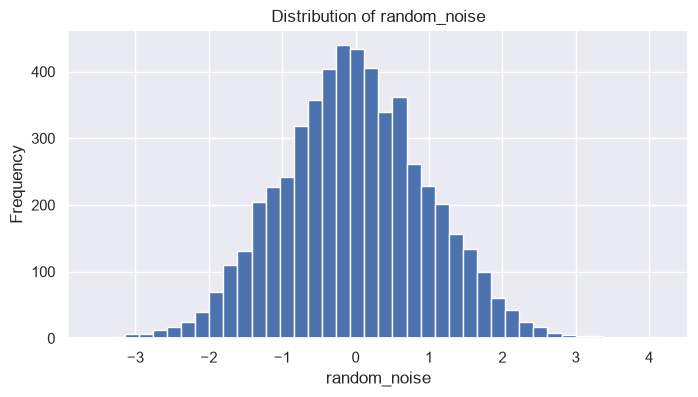

In [997]:
# Inspect the distribution of random_noise

col = X_train["random_noise"]

print("Data type:", col.dtype)
print("Missing values:", col.isna().sum())
print("Unique values:", col.nunique())

print("\nDescriptive statistics:")
display(col.describe())

print("\nDistribution:")
col.hist(bins=40, figsize=(8, 4))
plt.title("Distribution of random_noise")
plt.xlabel("random_noise")
plt.ylabel("Frequency")
plt.show()

Pearson correlation with target:
-0.01722371491569353

Distribution by target class:


,count,mean,std,median
target,,,,
0,2426,-0.000266,0.996815,-0.028769
1,2977,-0.034815,0.998529,-0.038756



Boxplot by target class:


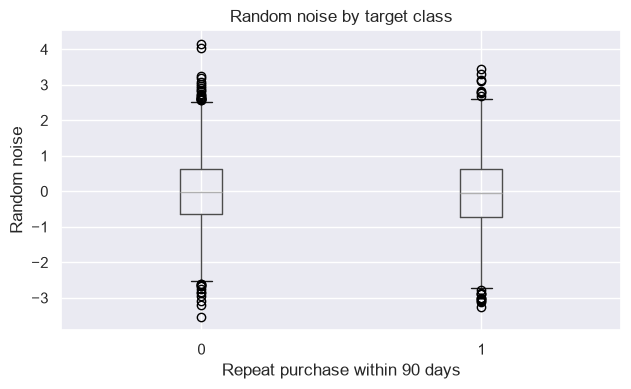

In [998]:
# Check the relationship between random_noise and the target

noise_target = pd.DataFrame({
    "random_noise": X_train["random_noise"],
    "target": y_train
})

print("Pearson correlation with target:")
print(noise_target["random_noise"].corr(noise_target["target"]))

print("\nDistribution by target class:")
display(
    noise_target.groupby("target")["random_noise"]
    .agg(["count", "mean", "std", "median"])
)

print("\nBoxplot by target class:")
noise_target.boxplot(
    column="random_noise",
    by="target",
    figsize=(7, 4)
)

plt.title("Random noise by target class")
plt.suptitle("")
plt.xlabel("Repeat purchase within 90 days")
plt.ylabel("Random noise")
plt.show()

In [999]:
# Reconstruct prior_total_spend using strictly earlier purchases

history = train_raw.copy()

history["purchase_date"] = pd.to_datetime(
    history["purchase_date"],
    errors="coerce"
)

# Total spending per customer and purchase date
daily_spend = (
    history.dropna(subset=["purchase_date"])
    .groupby(["customer_id", "purchase_date"])["Total a Pagar"]
    .sum()
    .sort_index()
)

# Cumulative spending, excluding the current date
reconstructed_daily_spend = (
    daily_spend.groupby(level=0).cumsum() - daily_spend
)

# Match reconstructed values to individual purchases
purchase_keys = pd.MultiIndex.from_arrays(
    [
        history["customer_id"],
        history["purchase_date"]
    ]
)

reconstructed_total_spend = pd.Series(
    reconstructed_daily_spend.reindex(purchase_keys).to_numpy(),
    index=history.index,
    name="reconstructed_prior_total_spend"
)

# Compare only training observations with complete available history
comparison = pd.DataFrame({
    "original": X_train["prior_total_spend"],
    "reconstructed": reconstructed_total_spend.reindex(X_train.index),
    "count_difference": (
        X_train["prior_purchase_count"]
        - history_counts.reindex(X_train.index)
    )
})

valid = comparison.loc[
    comparison["count_difference"].eq(0)
    & comparison["original"].notna()
    & comparison["reconstructed"].notna()
].copy()

valid["absolute_error"] = (
    valid["original"] - valid["reconstructed"]
).abs()

print("Comparable observations:", len(valid))
print(
    "Exact matches:",
    np.isclose(
        valid["original"],
        valid["reconstructed"],
        rtol=1e-6,
        atol=0.01
    ).sum()
)

print(
    "Exact match percentage:",
    round(
        np.isclose(
            valid["original"],
            valid["reconstructed"],
            rtol=1e-6,
            atol=0.01
        ).mean() * 100,
        2
    ),
    "%"
)

print("Mean absolute error:", valid["absolute_error"].mean())
print("Median absolute error:", valid["absolute_error"].median())

print("\nLargest discrepancies:")
display(
    valid.sort_values("absolute_error", ascending=False)
    .head(10)
)

Comparable observations: 4547
Exact matches: 4547
Exact match percentage: 100.0 %
Mean absolute error: 1.7393998662295306e-13
Median absolute error: 0.0

Largest discrepancies:


,original,reconstructed,count_difference,absolute_error
ID,,,,
10004225,98579.65,98579.65,0.0,1.455192e-11
10000873,76056.14,76056.14,0.0,1.455192e-11
10004642,95062.56,95062.56,0.0,1.455192e-11
10002362,97500.49,97500.49,0.0,1.455192e-11
10004742,66738.40,66738.40,0.0,1.455192e-11
10003811,97815.24,97815.24,0.0,1.455192e-11
10001242,45809.52,45809.52,0.0,7.275958e-12
10005336,42523.84,42523.84,0.0,7.275958e-12
10002657,53844.59,53844.59,0.0,7.275958e-12


In [1000]:
# Check consistency between customer tenure and purchase dates

tenure_check = pd.DataFrame({
    "purchase_date": pd.to_datetime(X_train["purchase_date"]),
    "customer_since_year": X_train["customer_since_year"],
    "customer_tenure_days": X_train["customer_tenure_days"]
})

# Estimate customer start date from recorded tenure
tenure_check["estimated_start_date"] = (
    tenure_check["purchase_date"]
    - pd.to_timedelta(
        tenure_check["customer_tenure_days"],
        unit="D"
    )
)

tenure_check["estimated_start_year"] = (
    tenure_check["estimated_start_date"].dt.year
)

print("Estimated start year matches customer_since_year:")
print(
    (
        tenure_check["estimated_start_year"]
        == tenure_check["customer_since_year"]
    ).value_counts()
)

print("\nNegative tenure values:")
print((tenure_check["customer_tenure_days"] < 0).sum())

print("\nExamples of inconsistencies:")
display(
    tenure_check.loc[
        tenure_check["estimated_start_year"]
        != tenure_check["customer_since_year"]
    ].head(10)
)

Estimated start year matches customer_since_year:
True     3767
False    1636
Name: count, dtype: int64

Negative tenure values:
0

Examples of inconsistencies:


,purchase_date,customer_since_year,customer_tenure_days,estimated_start_date,estimated_start_year
ID,,,,,
10000005,2023-07-15,2018,1589.0,2019-03-09,2019
10000009,2021-03-27,2016,1469.0,2017-03-19,2017
10000012,2021-11-20,2017,1351.0,2018-03-10,2018
10000018,2021-09-24,2017,1277.0,2018-03-27,2018
10000022,2023-03-21,2017,1743.0,2018-06-12,2018
10000028,2022-12-27,2017,1736.0,2018-03-27,2018
10000030,2016-03-28,2015,8.0,2016-03-20,2016
10000031,2017-11-11,2015,220.0,2017-04-05,2017
10000036,2023-07-02,2022,182.0,2023-01-01,2023


In [1001]:
# Compare customer tenure with the first observed purchase date

history = train_raw.copy()

history["purchase_date"] = pd.to_datetime(
    history["purchase_date"],
    errors="coerce"
)

first_purchase_dates = (
    history.groupby("customer_id")["purchase_date"]
    .min()
)

tenure_check = pd.DataFrame({
    "customer_id": X_train["customer_id"],
    "purchase_date": pd.to_datetime(X_train["purchase_date"]),
    "original_tenure": X_train["customer_tenure_days"]
})

tenure_check["first_observed_purchase"] = (
    tenure_check["customer_id"].map(first_purchase_dates)
)

tenure_check["reconstructed_tenure"] = (
    tenure_check["purchase_date"]
    - tenure_check["first_observed_purchase"]
).dt.days

tenure_check["difference"] = (
    tenure_check["original_tenure"]
    - tenure_check["reconstructed_tenure"]
)

print("Exact matches:")
print((tenure_check["difference"] == 0).sum())

print("\nExact match percentage:")
print(round((tenure_check["difference"] == 0).mean() * 100, 2), "%")

print("\nDifference distribution:")
display(tenure_check["difference"].describe())

print("\nMost frequent differences:")
display(tenure_check["difference"].value_counts().head(15))

print("\nExamples of discrepancies:")
display(
    tenure_check.loc[tenure_check["difference"] != 0]
    .head(10)
)

Exact matches:
5400

Exact match percentage:
99.94 %

Difference distribution:


count    5403.000000
mean        0.605219
std        35.077676
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      2524.000000
Name: difference, dtype: float64


Most frequent differences:


difference
0.0       5400
373.0        2
2524.0       1
Name: count, dtype: int64


Examples of discrepancies:


,customer_id,purchase_date,original_tenure,first_observed_purchase,reconstructed_tenure,difference
ID,,,,,,
10000877,223603,2022-09-11,2524.0,2022-09-11,0,2524.0
10003170,503397,2016-11-06,373.0,2016-11-06,0,373.0
10003534,503397,2018-08-03,1008.0,2016-11-06,635,373.0


In [1002]:
# Check whether customer tenure evolves consistently over time

tenure_history = X_train[
    ["customer_id", "purchase_date", "customer_tenure_days"]
].copy()

tenure_history["purchase_date"] = pd.to_datetime(
    tenure_history["purchase_date"]
)

tenure_history = tenure_history.sort_values(
    ["customer_id", "purchase_date"]
)

grouped = tenure_history.groupby("customer_id")

tenure_history["elapsed_days"] = (
    grouped["purchase_date"].diff().dt.days
)

tenure_history["tenure_change"] = (
    grouped["customer_tenure_days"].diff()
)

comparable = tenure_history.dropna(
    subset=["elapsed_days", "tenure_change"]
).copy()

comparable["difference"] = (
    comparable["tenure_change"]
    - comparable["elapsed_days"]
)

print("Comparable consecutive purchases:", len(comparable))
print("Consistent tenure changes:", (comparable["difference"] == 0).sum())

print(
    "Consistency percentage:",
    round((comparable["difference"] == 0).mean() * 100, 2),
    "%"
)

print("\nInconsistent observations:")
display(
    comparable.loc[comparable["difference"] != 0]
    .head(15)
)

Comparable consecutive purchases: 4833
Consistent tenure changes: 4833
Consistency percentage: 100.0 %

Inconsistent observations:


,customer_id,purchase_date,customer_tenure_days,elapsed_days,tenure_change,difference
ID,,,,,,


In [1003]:
# Check whether customer_since_year is consistent within each customer

year_consistency = (
    X_train.groupby("customer_id")["customer_since_year"]
    .agg(["count", "nunique", "min", "max"])
)

print("Total customers:", len(year_consistency))

print(
    "Customers with a consistent customer_since_year:",
    (year_consistency["nunique"] == 1).sum()
)

print(
    "Customers with inconsistent customer_since_year:",
    (year_consistency["nunique"] > 1).sum()
)

print("\nInconsistent customers:")
display(
    year_consistency.loc[
        year_consistency["nunique"] > 1
    ]
)

Total customers: 570
Customers with a consistent customer_since_year: 570
Customers with inconsistent customer_since_year: 0

Inconsistent customers:


,count,nunique,min,max
customer_id,,,,


In [1005]:
# Reconstruct purchase_count_365d with chronologically sorted dates

history = train_raw.copy()

history["purchase_date"] = pd.to_datetime(
    history["purchase_date"],
    errors="coerce"
)

history = (
    history.dropna(subset=["purchase_date"])
    .sort_values(["customer_id", "purchase_date"])
)

reconstructed_count_365d = pd.Series(
    index=history.index,
    dtype="float64"
)

for customer_id, group in history.groupby("customer_id"):
    dates = group["purchase_date"].to_numpy(dtype="datetime64[ns]")

    reconstructed_count_365d.loc[group.index] = (
        np.searchsorted(dates, dates, side="left")
        - np.searchsorted(
            dates,
            dates - np.timedelta64(365, "D"),
            side="left"
        )
    )

comparison = pd.DataFrame({
    "original": X_train["purchase_count_365d"],
    "reconstructed": reconstructed_count_365d.reindex(X_train.index),
    "count_difference": (
        X_train["prior_purchase_count"]
        - history_counts.reindex(X_train.index)
    )
})

valid = comparison.loc[
    comparison["count_difference"].eq(0)
    & comparison["reconstructed"].notna()
].copy()

valid["difference"] = valid["original"] - valid["reconstructed"]

print("Comparable observations:", len(valid))
print("Exact matches:", (valid["difference"] == 0).sum())
print(
    "Exact match percentage:",
    round((valid["difference"] == 0).mean() * 100, 2),
    "%"
)

print("\nDifference distribution:")
display(valid["difference"].value_counts().head(15))

print("\nExamples of discrepancies:")
display(valid.loc[valid["difference"] != 0].head(10))

Comparable observations: 4547
Exact matches: 4547
Exact match percentage: 100.0 %

Difference distribution:


difference
0.0    4547
Name: count, dtype: int64


Examples of discrepancies:


,original,reconstructed,count_difference,difference
ID,,,,


In [1006]:
# Validate all remaining historical purchase counts

windows = [30, 90, 180]

results = []

for window in windows:
    reconstructed = pd.Series(
        index=history.index,
        dtype="float64"
    )

    for customer_id, group in history.groupby("customer_id"):
        dates = group["purchase_date"].to_numpy(dtype="datetime64[ns]")

        reconstructed.loc[group.index] = (
            np.searchsorted(dates, dates, side="left")
            - np.searchsorted(
                dates,
                dates - np.timedelta64(window, "D"),
                side="left"
            )
        )

    column = f"purchase_count_{window}d"

    comparison = pd.DataFrame({
        "original": X_train[column],
        "reconstructed": reconstructed.reindex(X_train.index),
        "count_difference": (
            X_train["prior_purchase_count"]
            - history_counts.reindex(X_train.index)
        )
    })

    valid = comparison.loc[
        comparison["count_difference"].eq(0)
        & comparison["reconstructed"].notna()
    ]

    matches = valid["original"].eq(valid["reconstructed"])

    results.append({
        "variable": column,
        "comparable": len(valid),
        "exact_matches": matches.sum(),
        "match_pct": round(matches.mean() * 100, 2),
        "discrepancies": (~matches).sum()
    })

display(pd.DataFrame(results))

,variable,comparable,exact_matches,match_pct,discrepancies
0,purchase_count_30d,4547,4547,100.0,0
1,purchase_count_90d,4547,4547,100.0,0
2,purchase_count_180d,4547,4547,100.0,0


## Modelling

In [1008]:
# Check target distribution across temporal splits

target_distribution = pd.DataFrame({
    "training": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True)
}).sort_index()

target_counts = pd.DataFrame({
    "training": y_train.value_counts(),
    "validation": y_val.value_counts()
}).sort_index()

print("Target counts:")
display(target_counts)

print("\nTarget proportions (%):")
display((target_distribution * 100).round(2))

print("\nMajority-class baseline accuracy:")
print(
    "Training:",
    round(y_train.value_counts(normalize=True).max(), 4)
)
print(
    "Validation:",
    round(y_val.value_counts(normalize=True).max(), 4)
)

Target counts:


,training,validation
repeat_purchase_90d,,
0,2426,301
1,2977,456



Target proportions (%):


,training,validation
repeat_purchase_90d,,
0,44.9,39.76
1,55.1,60.24



Majority-class baseline accuracy:
Training: 0.551
Validation: 0.6024


In [1009]:
# Establish a majority-class baseline

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

y_pred_dummy = dummy_model.predict(X_val)
y_proba_dummy = dummy_model.predict_proba(X_val)[:, 1]

baseline_results = pd.DataFrame({
    "model": ["DummyClassifier"],
    "roc_auc": [roc_auc_score(y_val, y_proba_dummy)],
    "average_precision": [
        average_precision_score(y_val, y_proba_dummy)
    ],
    "accuracy": [accuracy_score(y_val, y_pred_dummy)],
    "precision": [
        precision_score(y_val, y_pred_dummy, zero_division=0)
    ],
    "recall": [
        recall_score(y_val, y_pred_dummy, zero_division=0)
    ],
    "f1": [f1_score(y_val, y_pred_dummy, zero_division=0)]
})

display(baseline_results.round(4))

,model,roc_auc,average_precision,accuracy,precision,recall,f1
0,DummyClassifier,0.5,0.6024,0.6024,0.6024,1.0,0.7519


In [1010]:
# Inspect feature data types before preprocessing

feature_types = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str)
})

display(
    feature_types
    .groupby("dtype")
    .size()
    .rename("feature_count")
    .reset_index()
)

print("\nNon-numeric features:")
display(
    feature_types[
        ~feature_types["dtype"].isin(
            ["int64", "float64", "int32", "float32"]
        )
    ]
)

,dtype,feature_count
0,float64,30
1,int64,2
2,str,17



Non-numeric features:


,dtype
payment_type,str
salesperson,str
commercial_zone,str
transport_method,str
warehouse,str
document_series,str
purchase_date,str
country_or_region,str
commercial_region,str
island,str


In [1011]:
# Identify numeric features and their data types

numeric_features = X_train.select_dtypes(include="number").columns

numeric_feature_info = pd.DataFrame({
    "dtype": X_train[numeric_features].dtypes,
    "unique_values": X_train[numeric_features].nunique(),
    "missing_pct": (
        X_train[numeric_features].isna().mean() * 100
    ).round(2)
})

display(numeric_feature_info)

,dtype,unique_values,missing_pct
Total a Pagar,float64,5129,0.00
Total Bruto,float64,5065,0.00
Total Liquido,float64,5107,0.00
Total Imp_,float64,4591,0.00
Total Portes,float64,189,0.00
Total Desc_ Global,float64,72,0.00
Total Desc_ Linha,float64,2799,0.00
Custo,float64,4747,0.00
N_ Detalhes,float64,164,0.00
invoice_count_current_purchase,float64,5,0.00


In [1012]:
# Define initial feature groups

excluded_features = [
    "customer_id",
    "customer_type",
    "random_noise",
    "company_name",
    "address",
    "purchase_date"
]

numeric_features = (
    X_train
    .select_dtypes(include="number")
    .columns
    .difference(excluded_features)
    .tolist()
)

categorical_features = (
    X_train
    .select_dtypes(include=["str", "object", "category"])
    .columns
    .difference(excluded_features)
    .tolist()
)

selected_features = numeric_features + categorical_features

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total selected features:", len(selected_features))

print("\nExcluded features:")
print(excluded_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features: 29
Categorical features: 14
Total selected features: 43

Excluded features:
['customer_id', 'customer_type', 'random_noise', 'company_name', 'address', 'purchase_date']

Categorical features:
['city', 'commercial_region', 'commercial_zone', 'country_or_region', 'document_series', 'island', 'municipality', 'payment_type', 'postal_area', 'postal_code', 'salesperson', 'street', 'transport_method', 'warehouse']


In [1013]:
def reconstruct_purchase_counts(X, history):

    X = X.copy()
    history = history.copy()

    # Convert dates to datetime
    X["purchase_date"] = pd.to_datetime(X["purchase_date"])
    history["purchase_date"] = pd.to_datetime(
        history["purchase_date"]
    )

    # Sort historical transactions
    history = history.sort_values(
        ["customer_id", "purchase_date"]
    )

    windows = [30, 90, 180, 365]

    # Prepare reconstructed columns
    for window in windows:
        X[f"reconstructed_count_{window}d"] = np.nan

    X["observed_prior_count"] = np.nan

    # Process each customer independently
    for customer_id, group in history.groupby("customer_id"):

        customer_mask = X["customer_id"] == customer_id

        if not customer_mask.any():
            continue

        dates = group["purchase_date"].dropna().to_numpy(
            dtype="datetime64[ns]"
        )

        dates = np.sort(dates)

        target_dates = X.loc[
            customer_mask, "purchase_date"
        ]

        valid_dates = target_dates.notna()

        target_index = target_dates.index[valid_dates]

        query_dates = target_dates.loc[
            target_index
        ].to_numpy(dtype="datetime64[ns]")

        # Number of strictly earlier purchases
        prior_positions = np.searchsorted(
            dates, query_dates, side="left"
        )

        X.loc[
            target_index, "observed_prior_count"
        ] = prior_positions

        # Purchases within each historical window
        for window in windows:

            window_start = (
                query_dates
                - np.timedelta64(window, "D")
            )

            start_positions = np.searchsorted(
                dates, window_start, side="left"
            )

            counts = prior_positions - start_positions

            X.loc[
                target_index,
                f"reconstructed_count_{window}d"
            ] = counts

    return X

In [1014]:
X_train_check = reconstruct_purchase_counts(
    X_train,
    train_raw
)

# Check historical completeness
X_train_check["history_consistent"] = (
    X_train_check["prior_purchase_count"]
    == X_train_check["observed_prior_count"]
)

print("Training observations:", len(X_train_check))

print(
    "Observations with consistent history:",
    X_train_check["history_consistent"].sum()
)

print(
    "Observations with inconsistent history:",
    (~X_train_check["history_consistent"]).sum()
)

# Compare original and reconstructed values
results = []

for window in [30, 90, 180, 365]:

    original = f"purchase_count_{window}d"
    reconstructed = f"reconstructed_count_{window}d"

    valid = (
        X_train_check["history_consistent"]
        & X_train_check[original].notna()
        & X_train_check[reconstructed].notna()
    )

    matches = (
        X_train_check.loc[valid, original]
        == X_train_check.loc[valid, reconstructed]
    )

    results.append({
        "feature": original,
        "comparable_rows": valid.sum(),
        "exact_matches": matches.sum(),
        "match_pct": round(matches.mean() * 100, 2)
    })

display(pd.DataFrame(results))

Training observations: 5403
Observations with consistent history: 4547
Observations with inconsistent history: 856


,feature,comparable_rows,exact_matches,match_pct
0,purchase_count_30d,4547,4547,100.0
1,purchase_count_90d,4547,4547,100.0
2,purchase_count_180d,4547,4547,100.0
3,purchase_count_365d,4547,4547,100.0


In [1015]:
def fill_purchase_counts(X):

    X = X.copy()

    windows = [30, 90, 180, 365]

    recovery_report = []

    for window in windows:

        col = f"purchase_count_{window}d"
        reconstructed = f"reconstructed_count_{window}d"

        # Identify missing values with reliable history
        mask = (
            X[col].isna()
            & X["history_consistent"]
            & X[reconstructed].notna()
        )

        missing_before = X[col].isna().sum()

        # Recover missing values
        X.loc[mask, col] = X.loc[mask, reconstructed]

        missing_after = X[col].isna().sum()

        recovery_report.append({
            "feature": col,
            "missing_before": missing_before,
            "recovered": mask.sum(),
            "missing_after": missing_after
        })

    return X, pd.DataFrame(recovery_report)

In [1016]:
X_train_recovered, recovery_report = fill_purchase_counts(
    X_train_check
)

display(recovery_report)

,feature,missing_before,recovered,missing_after
0,purchase_count_30d,0,0,0
1,purchase_count_90d,0,0,0
2,purchase_count_180d,0,0,0
3,purchase_count_365d,0,0,0


In [1017]:
# Missing values after initial cleaning

missing_report = pd.DataFrame({
    "dtype": X_train.dtypes,
    "missing_count": X_train.isna().sum(),
    "missing_pct": (
        X_train.isna().mean() * 100
    ).round(2)
})

# Keep only features with missing values
missing_report = (
    missing_report[missing_report["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

display(missing_report)

,dtype,missing_count,missing_pct
customer_type,float64,5403,100.00
street,str,3176,58.78
island,str,1777,32.89
city,str,1728,31.98
prior_std_gap_days,float64,1310,24.25
prior_mean_gap_days,float64,1141,21.12
prior_std_purchase_value,float64,977,18.08
prior_mean_purchase_value,float64,736,13.62
days_since_previous_purchase,float64,729,13.49
prior_max_purchase_value,float64,568,10.51


In [1018]:
col = "prior_mean_purchase_value"

missing = X_train_recovered[col].isna()

# Classify missing values
missing_analysis = pd.Series({

    "No previous purchases": (
        missing
        & X_train_recovered["prior_purchase_count"].eq(0)
    ).sum(),

    "Recoverable from history": (
        missing
        & X_train_recovered["prior_purchase_count"].gt(0)
        & X_train_recovered["history_consistent"]
    ).sum(),

    "Incomplete history": (
        missing
        & X_train_recovered["prior_purchase_count"].gt(0)
        & ~X_train_recovered["history_consistent"]
    ).sum()

})

display(missing_analysis)

print("Total missing:", missing.sum())
print("Classified missing:", missing_analysis.sum())

No previous purchases       568
Recoverable from history    138
Incomplete history           30
dtype: int64

Total missing: 736
Classified missing: 736


In [1019]:
def fill_prior_mean_purchase_value(X, history):

    X = X.copy()
    history = history.copy()

    col = "prior_mean_purchase_value"

    history["purchase_date"] = pd.to_datetime(
        history["purchase_date"]
    )

    # Only recover missing values with consistent history
    candidates = X.loc[
        X[col].isna()
        & X["prior_purchase_count"].gt(0)
        & X["history_consistent"]
    ]

    recovered = 0

    for idx, row in candidates.iterrows():

        # Get previous purchases from the same customer
        previous = history.loc[
            (history["customer_id"] == row["customer_id"])
            & (history["purchase_date"] < row["purchase_date"]),
            "Total a Pagar"
        ]

        # Require complete historical amounts
        if previous.empty or previous.isna().any():
            continue

        # Calculate historical average
        reconstructed = previous.mean()

        if pd.notna(reconstructed):
            X.loc[idx, col] = reconstructed
            recovered += 1

    print(f"Candidates: {len(candidates)}")
    print(f"Recovered: {recovered}")
    print(f"Not recovered: {len(candidates) - recovered}")
    print(f"Remaining missing values: {X[col].isna().sum()}")

    return X

In [1021]:
X_train_recovered = fill_prior_mean_purchase_value(
    X_train_recovered,
    train_raw
)

Candidates: 138
Recovered: 138
Not recovered: 0
Remaining missing values: 598


In [1022]:
col = "prior_std_purchase_value"

missing = X_train_recovered[col].isna()

std_missing_analysis = pd.Series({

    "Fewer than 2 previous purchases": (
        missing
        & X_train_recovered["prior_purchase_count"].lt(2)
    ).sum(),

    "Recoverable from history": (
        missing
        & X_train_recovered["prior_purchase_count"].ge(2)
        & X_train_recovered["history_consistent"]
    ).sum(),

    "Incomplete history": (
        missing
        & X_train_recovered["prior_purchase_count"].ge(2)
        & ~X_train_recovered["history_consistent"]
    ).sum()

})

display(std_missing_analysis)

print("Total missing:", missing.sum())

Fewer than 2 previous purchases    977
Recoverable from history             0
Incomplete history                   0
dtype: int64

Total missing: 977


In [1023]:
historical_features = {
    "prior_min_purchase_value": 1,
    "prior_max_purchase_value": 1,
    "days_since_previous_purchase": 1,
    "prior_mean_gap_days": 2,
    "prior_std_gap_days": 3
}

results = []

for col, min_purchases in historical_features.items():

    missing = X_train_recovered[col].isna()

    structural = (
        missing
        & X_train_recovered["prior_purchase_count"].lt(min_purchases)
    )

    recoverable = (
        missing
        & X_train_recovered["prior_purchase_count"].ge(min_purchases)
        & X_train_recovered["history_consistent"]
    )

    incomplete = (
        missing
        & X_train_recovered["prior_purchase_count"].ge(min_purchases)
        & ~X_train_recovered["history_consistent"]
    )

    results.append({
        "feature": col,
        "total_missing": missing.sum(),
        "structural": structural.sum(),
        "recoverable": recoverable.sum(),
        "incomplete_history": incomplete.sum()
    })

display(pd.DataFrame(results))

,feature,total_missing,structural,recoverable,incomplete_history
0,prior_min_purchase_value,568,568,0,0
1,prior_max_purchase_value,568,568,0,0
2,days_since_previous_purchase,729,568,135,26
3,prior_mean_gap_days,1141,977,139,25
4,prior_std_gap_days,1310,1310,0,0


In [1024]:
def fill_historical_gap_features(X, history):

    X = X.copy()
    history = history.copy()

    history["purchase_date"] = pd.to_datetime(
        history["purchase_date"]
    )

    # Only rows with consistent history
    candidates = X[
        X["history_consistent"]
        & (
            X["days_since_previous_purchase"].isna()
            | X["prior_mean_gap_days"].isna()
        )
    ]

    recovered_days = 0
    recovered_mean = 0

    for idx, row in candidates.iterrows():

        previous_dates = (
            history.loc[
                (history["customer_id"] == row["customer_id"])
                & (history["purchase_date"] < row["purchase_date"]),
                "purchase_date"
            ]
            .dropna()
            .sort_values()
        )

        # Days since previous purchase
        if (
            pd.isna(row["days_since_previous_purchase"])
            and len(previous_dates) >= 1
        ):

            last_purchase = previous_dates.iloc[-1]

            days = (
                row["purchase_date"] - last_purchase
            ).total_seconds() / 86400

            X.loc[idx, "days_since_previous_purchase"] = days

            recovered_days += 1

        # Mean gap between previous purchases
        if (
            pd.isna(row["prior_mean_gap_days"])
            and len(previous_dates) >= 2
        ):

            gaps = (
                previous_dates.diff()
                .dropna()
                .dt.total_seconds() / 86400
            )

            X.loc[idx, "prior_mean_gap_days"] = gaps.mean()

            recovered_mean += 1

    print("Recovered days_since_previous_purchase:", recovered_days)
    print("Recovered prior_mean_gap_days:", recovered_mean)

    print(
        "Remaining missing days_since_previous_purchase:",
        X["days_since_previous_purchase"].isna().sum()
    )

    print(
        "Remaining missing prior_mean_gap_days:",
        X["prior_mean_gap_days"].isna().sum()
    )

    return X

In [1025]:
X_train_recovered = fill_historical_gap_features(
    X_train_recovered,
    train_raw
)

Recovered days_since_previous_purchase: 135
Recovered prior_mean_gap_days: 139
Remaining missing days_since_previous_purchase: 594
Remaining missing prior_mean_gap_days: 1002


In [1027]:
# Validate historical gap reconstruction

history = train_raw.copy()
X_validation = X_train.copy()

# Convert dates to datetime
history["purchase_date"] = pd.to_datetime(
    history["purchase_date"]
)

X_validation["purchase_date"] = pd.to_datetime(
    X_validation["purchase_date"]
)

validation_results = []

features = {
    "days_since_previous_purchase": 1,
    "prior_mean_gap_days": 2
}

for col, min_purchases in features.items():

    candidates = X_validation.loc[
        X_train_check["history_consistent"]
        & X_validation[col].notna()
        & X_validation["prior_purchase_count"].ge(min_purchases)
    ]

    original_values = []
    reconstructed_values = []

    for _, row in candidates.iterrows():

        previous_dates = (
            history.loc[
                (history["customer_id"] == row["customer_id"])
                & (history["purchase_date"] < row["purchase_date"]),
                "purchase_date"
            ]
            .dropna()
            .sort_values()
        )

        if len(previous_dates) < min_purchases:
            continue

        if col == "days_since_previous_purchase":

            reconstructed = (
                row["purchase_date"] - previous_dates.iloc[-1]
            ).total_seconds() / 86400

        else:

            gaps = (
                previous_dates.diff()
                .dropna()
                .dt.total_seconds() / 86400
            )

            reconstructed = gaps.mean()

        original_values.append(row[col])
        reconstructed_values.append(reconstructed)

    original_values = np.array(original_values)
    reconstructed_values = np.array(reconstructed_values)

    errors = np.abs(original_values - reconstructed_values)

    validation_results.append({
        "feature": col,
        "compared_rows": len(errors),
        "exact_match_pct": round(
            np.mean(
                np.isclose(
                    original_values,
                    reconstructed_values,
                    atol=1e-6,
                    rtol=0
                )
            ) * 100, 2
        ),
        "mean_absolute_error": round(errors.mean(), 4),
        "max_absolute_error": round(errors.max(), 4)
    })

display(pd.DataFrame(validation_results))

,feature,compared_rows,exact_match_pct,mean_absolute_error,max_absolute_error
0,days_since_previous_purchase,3844,99.74,0.3244,354.00
1,prior_mean_gap_days,3433,99.68,0.2257,124.75


In [1028]:
# Investigate discrepancies in historical gap features

history = train_raw.copy()
X_validation = X_train.copy()

history["purchase_date"] = pd.to_datetime(
    history["purchase_date"]
)

X_validation["purchase_date"] = pd.to_datetime(
    X_validation["purchase_date"]
)

discrepancies = []

features = {
    "days_since_previous_purchase": 1,
    "prior_mean_gap_days": 2
}

for col, min_purchases in features.items():

    candidates = X_validation.loc[
        X_train_check["history_consistent"]
        & X_validation[col].notna()
        & X_validation["prior_purchase_count"].ge(min_purchases)
    ]

    for idx, row in candidates.iterrows():

        previous_dates = (
            history.loc[
                (history["customer_id"] == row["customer_id"])
                & (history["purchase_date"] < row["purchase_date"]),
                "purchase_date"
            ]
            .dropna()
            .sort_values()
        )

        if len(previous_dates) < min_purchases:
            continue

        if col == "days_since_previous_purchase":

            reconstructed = (
                row["purchase_date"] - previous_dates.iloc[-1]
            ).total_seconds() / 86400

        else:

            gaps = (
                previous_dates.diff()
                .dropna()
                .dt.total_seconds() / 86400
            )

            reconstructed = gaps.mean()

        original = row[col]
        error = abs(original - reconstructed)

        if not np.isclose(
            original,
            reconstructed,
            atol=1e-6,
            rtol=0
        ):

            discrepancies.append({
                "feature": col,
                "customer_id": row["customer_id"],
                "purchase_date": row["purchase_date"],
                "prior_purchase_count": row["prior_purchase_count"],
                "original": original,
                "reconstructed": reconstructed,
                "absolute_error": error
            })

discrepancies_df = pd.DataFrame(discrepancies)

display(
    discrepancies_df.sort_values(
        "absolute_error",
        ascending=False
    )
)

print("Total discrepancies:", len(discrepancies_df))

,feature,customer_id,purchase_date,prior_purchase_count,original,reconstructed,absolute_error
7,days_since_previous_purchase,120503,2022-10-15,13.0,-4.0,350.000000,354.000000
5,days_since_previous_purchase,636831,2017-08-26,1.0,-4.0,279.000000,283.000000
2,days_since_previous_purchase,119885,2021-11-06,11.0,-4.0,231.000000,235.000000
16,prior_mean_gap_days,944110,2022-10-22,13.0,-4.0,120.750000,124.750000
3,days_since_previous_purchase,991454,2015-10-31,1.0,-4.0,111.000000,115.000000
14,prior_mean_gap_days,274962,2016-03-20,2.0,-4.0,111.000000,115.000000
20,prior_mean_gap_days,992356,2021-03-20,19.0,-4.0,109.222222,113.222222
8,days_since_previous_purchase,992356,2016-10-30,4.0,-4.0,105.000000,109.000000
15,prior_mean_gap_days,543949,2023-04-01,16.0,-4.0,104.066667,108.066667
13,prior_mean_gap_days,274962,2020-03-28,17.0,-4.0,99.687500,103.687500


Total discrepancies: 21


In [1029]:
# Detect potential artificial values in historical features

historical_features = [
    "prior_total_spend",
    "prior_mean_purchase_value",
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "days_since_previous_purchase",
    "prior_mean_gap_days",
    "prior_std_gap_days",
    "spend_365d",
    "purchase_count_30d",
    "purchase_count_90d",
    "purchase_count_180d",
    "purchase_count_365d"
]

results = []

for col in historical_features:

    results.append({
        "feature": col,
        "minus_4_count": X_train_recovered[col].eq(-4).sum(),
        "minus_1_count": X_train_recovered[col].eq(-1).sum(),
        "value_1e9_count": X_train_recovered[col].eq(1e9).sum(),
        "negative_count": X_train_recovered[col].lt(0).sum(),
        "missing_count": X_train_recovered[col].isna().sum()
    })

anomaly_report = pd.DataFrame(results)

display(anomaly_report)

,feature,minus_4_count,minus_1_count,value_1e9_count,negative_count,missing_count
0,prior_total_spend,0,0,0,0,0
1,prior_mean_purchase_value,0,0,12,13,598
2,prior_std_purchase_value,0,0,0,0,977
3,prior_min_purchase_value,0,0,0,0,568
4,prior_max_purchase_value,0,0,0,0,568
5,days_since_previous_purchase,13,0,0,13,594
6,prior_mean_gap_days,12,0,0,12,1002
7,prior_std_gap_days,0,0,0,0,1310
8,spend_365d,0,0,11,14,164
9,purchase_count_30d,0,0,0,0,0


In [1030]:
# Recover artificial -4 values in historical gap features

def recover_negative_gap_values(X, history):

    X = X.copy()
    history = history.copy()

    X["purchase_date"] = pd.to_datetime(X["purchase_date"])
    history["purchase_date"] = pd.to_datetime(history["purchase_date"])

    recovered_days = 0
    recovered_mean = 0

    candidates = X.loc[
        X["history_consistent"]
        & (
            X["days_since_previous_purchase"].eq(-4)
            | X["prior_mean_gap_days"].eq(-4)
        )
    ]

    for idx, row in candidates.iterrows():

        previous_dates = (
            history.loc[
                (history["customer_id"] == row["customer_id"])
                & (history["purchase_date"] < row["purchase_date"]),
                "purchase_date"
            ]
            .dropna()
            .sort_values()
        )

        # Recover days since previous purchase
        if (
            row["days_since_previous_purchase"] == -4
            and len(previous_dates) >= 1
        ):

            reconstructed = (
                row["purchase_date"] - previous_dates.iloc[-1]
            ).total_seconds() / 86400

            X.loc[idx, "days_since_previous_purchase"] = reconstructed

            recovered_days += 1

        # Recover mean gap between previous purchases
        if (
            row["prior_mean_gap_days"] == -4
            and len(previous_dates) >= 2
        ):

            gaps = (
                previous_dates.diff()
                .dropna()
                .dt.total_seconds() / 86400
            )

            X.loc[idx, "prior_mean_gap_days"] = gaps.mean()

            recovered_mean += 1

    print("Recovered artificial values:")
    print("days_since_previous_purchase:", recovered_days)
    print("prior_mean_gap_days:", recovered_mean)

    print("\nRemaining -4 values:")
    print(
        "days_since_previous_purchase:",
        X["days_since_previous_purchase"].eq(-4).sum()
    )
    print(
        "prior_mean_gap_days:",
        X["prior_mean_gap_days"].eq(-4).sum()
    )

    return X


# Apply reconstruction
X_train_recovered = recover_negative_gap_values(
    X_train_recovered,
    train_raw
)

Recovered artificial values:
days_since_previous_purchase: 10
prior_mean_gap_days: 11

Remaining -4 values:
days_since_previous_purchase: 3
prior_mean_gap_days: 1


In [1031]:
# Replace unrecoverable artificial values with NaN

gap_features = [
    "days_since_previous_purchase",
    "prior_mean_gap_days"
]

for col in gap_features:

    X_train_recovered.loc[
        X_train_recovered[col] == -4,
        col
    ] = np.nan

# Verify results
gap_report = pd.DataFrame({
    "missing_count": X_train_recovered[gap_features].isna().sum(),
    "negative_count": X_train_recovered[gap_features].lt(0).sum()
})

display(gap_report)

,missing_count,negative_count
days_since_previous_purchase,597,0
prior_mean_gap_days,1003,0


In [1032]:
# Analyze missing and artificial values in spend_365d

col = "spend_365d"

missing = X_train_recovered[col].isna()
artificial = X_train_recovered[col].eq(1e9)

analysis = pd.Series({

    "Missing - no previous purchases": (
        missing
        & X_train_recovered["prior_purchase_count"].eq(0)
    ).sum(),

    "Missing - consistent history": (
        missing
        & X_train_recovered["history_consistent"]
        & X_train_recovered["prior_purchase_count"].gt(0)
    ).sum(),

    "Missing - incomplete history": (
        missing
        & ~X_train_recovered["history_consistent"]
        & X_train_recovered["prior_purchase_count"].gt(0)
    ).sum(),

    "Artificial 1e9 - consistent history": (
        artificial
        & X_train_recovered["history_consistent"]
    ).sum(),

    "Artificial 1e9 - incomplete history": (
        artificial
        & ~X_train_recovered["history_consistent"]
    ).sum()

})

display(analysis)

print("\nTotal missing:", missing.sum())
print("Total artificial 1e9:", artificial.sum())

Missing - no previous purchases         17
Missing - consistent history           126
Missing - incomplete history            21
Artificial 1e9 - consistent history      9
Artificial 1e9 - incomplete history      2
dtype: int64


Total missing: 164
Total artificial 1e9: 11


In [1033]:
def fill_spend_365d(X, history):

    X = X.copy()
    history = history.copy()

    col = "spend_365d"

    # Convert dates
    X["purchase_date"] = pd.to_datetime(X["purchase_date"])
    history["purchase_date"] = pd.to_datetime(
        history["purchase_date"]
    )

    # Identify missing and artificial values
    invalid = X[col].isna() | X[col].eq(1e9)

    # Only candidates with consistent history
    candidates = X.loc[
        invalid & X["history_consistent"]
    ]

    recovered = 0

    for idx, row in candidates.iterrows():

        purchase_date = row["purchase_date"]

        if pd.isna(purchase_date):
            continue

        # Historical window: previous 365 days
        window_start = purchase_date - pd.Timedelta(days=365)

        previous = history.loc[
            (history["customer_id"] == row["customer_id"])
            & (history["purchase_date"] < purchase_date)
            & (history["purchase_date"] >= window_start),
            "Total a Pagar"
        ]

        # Do not reconstruct when historical amounts are missing
        if previous.isna().any():
            continue

        # Sum historical spending
        # Empty history correctly produces 0
        reconstructed = previous.sum()

        X.loc[idx, col] = reconstructed

        recovered += 1

    # Remaining artificial values are invalid
    X.loc[X[col].eq(1e9), col] = np.nan

    print("Candidates:", len(candidates))
    print("Recovered:", recovered)
    print("Not recovered:", len(candidates) - recovered)

    print("\nRemaining missing values:", X[col].isna().sum())
    print("Remaining artificial 1e9:", X[col].eq(1e9).sum())

    return X


# Apply reconstruction
X_train_recovered = fill_spend_365d(
    X_train_recovered,
    train_raw
)

Candidates: 152
Recovered: 152
Not recovered: 0

Remaining missing values: 23
Remaining artificial 1e9: 0


In [1034]:
def recover_artificial_mean_purchase(X, history):

    X = X.copy()
    history = history.copy()

    col = "prior_mean_purchase_value"

    # Convert dates
    X["purchase_date"] = pd.to_datetime(X["purchase_date"])
    history["purchase_date"] = pd.to_datetime(
        history["purchase_date"]
    )

    # Identify artificial values
    artificial = X[col].eq(1e9)

    # Only recover when history is consistent
    candidates = X.loc[
        artificial & X["history_consistent"]
    ]

    recovered = 0

    for idx, row in candidates.iterrows():

        previous = history.loc[
            (history["customer_id"] == row["customer_id"])
            & (history["purchase_date"] < row["purchase_date"]),
            "Total a Pagar"
        ]

        # Require previous purchases and complete amounts
        if previous.empty or previous.isna().any():
            continue

        reconstructed = previous.mean()

        if pd.notna(reconstructed):
            X.loc[idx, col] = reconstructed
            recovered += 1

    # Unrecoverable artificial values become NaN
    X.loc[X[col].eq(1e9), col] = np.nan

    print("Artificial values initially:", artificial.sum())
    print("Candidates:", len(candidates))
    print("Recovered:", recovered)
    print("Not recovered:", len(candidates) - recovered)

    print("\nRemaining missing:", X[col].isna().sum())
    print("Remaining 1e9:", X[col].eq(1e9).sum())

    return X


# Apply reconstruction
X_train_recovered = recover_artificial_mean_purchase(
    X_train_recovered,
    train_raw
)

Artificial values initially: 12
Candidates: 9
Recovered: 9
Not recovered: 0

Remaining missing: 601
Remaining 1e9: 0


In [1035]:
# Inspect negative monetary values

monetary_features = [
    "prior_total_spend",
    "prior_mean_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "spend_365d"
]

negative_report = []

for col in monetary_features:

    negative_values = X_train_recovered.loc[
        X_train_recovered[col] < 0,
        col
    ]

    negative_report.append({
        "feature": col,
        "negative_count": len(negative_values),
        "min_negative_value": (
            negative_values.min()
            if len(negative_values) > 0
            else np.nan
        ),
        "max_negative_value": (
            negative_values.max()
            if len(negative_values) > 0
            else np.nan
        )
    })

display(pd.DataFrame(negative_report))

# Check negative transaction amounts in historical data
print(
    "\nNegative Total a Pagar transactions:",
    (train_raw["Total a Pagar"] < 0).sum()
)

,feature,negative_count,min_negative_value,max_negative_value
0,prior_total_spend,0,NaN,NaN
1,prior_mean_purchase_value,13,-885.097111,-110.147097
2,prior_min_purchase_value,0,NaN,NaN
3,prior_max_purchase_value,0,NaN,NaN
4,spend_365d,14,-159115.175535,-295.380000



Negative Total a Pagar transactions: 0


In [1036]:
def recover_negative_monetary_values(X, history):

    X = X.copy()
    history = history.copy()

    X["purchase_date"] = pd.to_datetime(X["purchase_date"])
    history["purchase_date"] = pd.to_datetime(
        history["purchase_date"]
    )

    features = [
        "prior_mean_purchase_value",
        "spend_365d"
    ]

    recovery_report = []

    for col in features:

        negative_mask = X[col] < 0

        candidates = X.loc[
            negative_mask
            & X["history_consistent"]
        ]

        recovered = 0

        for idx, row in candidates.iterrows():

            purchase_date = row["purchase_date"]

            if pd.isna(purchase_date):
                continue

            previous = history.loc[
                (history["customer_id"] == row["customer_id"])
                & (history["purchase_date"] < purchase_date)
            ]

            if col == "prior_mean_purchase_value":

                amounts = previous["Total a Pagar"]

                if amounts.empty or amounts.isna().any():
                    continue

                reconstructed = amounts.mean()

            else:

                window_start = (
                    purchase_date - pd.Timedelta(days=365)
                )

                amounts = previous.loc[
                    previous["purchase_date"] >= window_start,
                    "Total a Pagar"
                ]

                if amounts.isna().any():
                    continue

                reconstructed = amounts.sum()

            if pd.notna(reconstructed) and reconstructed >= 0:

                X.loc[idx, col] = reconstructed
                recovered += 1

        # Unrecoverable negative values become NaN
        X.loc[X[col] < 0, col] = np.nan

        recovery_report.append({
            "feature": col,
            "negative_initial": negative_mask.sum(),
            "recovered": recovered,
            "converted_to_nan": negative_mask.sum() - recovered,
            "remaining_negative": X[col].lt(0).sum(),
            "remaining_missing": X[col].isna().sum()
        })

    return X, pd.DataFrame(recovery_report)


# Apply reconstruction
X_train_recovered, negative_recovery_report = (
    recover_negative_monetary_values(
        X_train_recovered,
        train_raw
    )
)

display(negative_recovery_report)

,feature,negative_initial,recovered,converted_to_nan,remaining_negative,remaining_missing
0,prior_mean_purchase_value,13,7,6,0,607
1,spend_365d,14,12,2,0,25


In [1078]:
import numpy as np
import pandas as pd


def preprocess_historical_features(X, history):

    X = X.copy()
    history = history.copy()

    # Convert dates
    X["purchase_date"] = pd.to_datetime(
        X["purchase_date"]
    )

    history["purchase_date"] = pd.to_datetime(
        history["purchase_date"]
    )

    # Prepare historical transactions by customer
    history = history.sort_values(
        ["customer_id", "purchase_date"]
    )

    customer_history = {
        customer_id: group
        for customer_id, group in history.groupby("customer_id")
    }

    features = [
        "prior_mean_purchase_value",
        "days_since_previous_purchase",
        "prior_mean_gap_days",
        "spend_365d"
    ]

    # --------------------------------------------------------
    # 1. Identify missing and artificial values
    # --------------------------------------------------------

    invalid = pd.DataFrame(index=X.index)

    invalid["prior_mean_purchase_value"] = (
        X["prior_mean_purchase_value"].isna()
        | X["prior_mean_purchase_value"].eq(1e9)
        | X["prior_mean_purchase_value"].lt(0)
    )

    invalid["days_since_previous_purchase"] = (
        X["days_since_previous_purchase"].isna()
        | X["days_since_previous_purchase"].eq(-4)
    )

    invalid["prior_mean_gap_days"] = (
        X["prior_mean_gap_days"].isna()
        | X["prior_mean_gap_days"].eq(-4)
    )

    invalid["spend_365d"] = (
        X["spend_365d"].isna()
        | X["spend_365d"].eq(1e9)
        | X["spend_365d"].lt(0)
    )

    # Store original values before modification
    original_spend_365d = X["spend_365d"].copy()

    # Mark missing and artificial values as NaN
    for col in features:

        X.loc[invalid[col], col] = np.nan

    recovered = {
        col: 0
        for col in features
    }

    # Track newly detected positive anomalies
    inconsistent_spend_365d = 0

    # --------------------------------------------------------
    # 2. Process historical observations
    # --------------------------------------------------------

    for idx, row in X.iterrows():

        customer_id = row["customer_id"]
        purchase_date = row["purchase_date"]

        if pd.isna(purchase_date):
            continue

        customer = customer_history.get(customer_id)

        if customer is None:
            continue

        # Strictly earlier transactions
        previous = customer.loc[
            customer["purchase_date"] < purchase_date
        ]

        # Verify historical completeness
        if (
            pd.isna(row["prior_purchase_count"])
            or len(previous) != row["prior_purchase_count"]
        ):
            continue

        amounts = previous["Total a Pagar"]
        dates = previous["purchase_date"]

        # ----------------------------------------------------
        # Historical mean purchase value
        # ----------------------------------------------------

        col = "prior_mean_purchase_value"

        if (
            invalid.loc[idx, col]
            and len(previous) >= 1
            and amounts.notna().all()
        ):

            X.loc[idx, col] = amounts.mean()
            recovered[col] += 1

        # ----------------------------------------------------
        # Days since previous purchase
        # ----------------------------------------------------

        col = "days_since_previous_purchase"

        if invalid.loc[idx, col] and len(previous) >= 1:

            value = (
                purchase_date - dates.iloc[-1]
            ).total_seconds() / 86400

            X.loc[idx, col] = value
            recovered[col] += 1

        # ----------------------------------------------------
        # Mean gap between previous purchases
        # ----------------------------------------------------

        col = "prior_mean_gap_days"

        if invalid.loc[idx, col] and len(previous) >= 2:

            gaps = (
                dates.diff()
                .dropna()
                .dt.total_seconds() / 86400
            )

            X.loc[idx, col] = gaps.mean()
            recovered[col] += 1

        # ----------------------------------------------------
        # Spending during previous 365 days
        # ----------------------------------------------------

        col = "spend_365d"

        window_start = (
            purchase_date - pd.Timedelta(days=365)
        )

        window = previous.loc[
            previous["purchase_date"] >= window_start,
            "Total a Pagar"
        ]

        # Only reconstruct when all historical amounts
        # required for the calculation are available
        if window.notna().all():

            expected_spend = window.sum()

            original_value = original_spend_365d.loc[idx]

            # Case A: Missing or artificial value
            if invalid.loc[idx, col]:

                X.loc[idx, col] = expected_spend
                recovered[col] += 1

            # Case B: Positive value inconsistent
            # with a complete historical record
            elif not np.isclose(
                original_value,
                expected_spend,
                atol=0.01,
                rtol=0
            ):

                X.loc[idx, col] = expected_spend
                inconsistent_spend_365d += 1

    # --------------------------------------------------------
    # 3. Build recovery report
    # --------------------------------------------------------

    report = pd.DataFrame({
        "feature": features,

        "recovered": [
            recovered[col]
            for col in features
        ],

        "remaining_missing": [
            X[col].isna().sum()
            for col in features
        ]
    })

    report["corrected_inconsistent"] = 0

    report.loc[
        report["feature"] == "spend_365d",
        "corrected_inconsistent"
    ] = inconsistent_spend_365d

    return X, report

In [1038]:
# Rebuild training from the original dataset
X_train_clean, historical_report = (
    preprocess_historical_features(
        X_train,
        train_raw
    )
)

display(historical_report)

# Compare with our previous manual preprocessing
features_to_compare = [
    "prior_mean_purchase_value",
    "days_since_previous_purchase",
    "prior_mean_gap_days",
    "spend_365d"
]

comparison = []

for col in features_to_compare:

    matches = (
        np.isclose(
            X_train_clean[col],
            X_train_recovered[col],
            equal_nan=True,
            atol=1e-6,
            rtol=0
        )
    )

    comparison.append({
        "feature": col,
        "matching_rows": matches.sum(),
        "total_rows": len(matches),
        "match_pct": round(matches.mean() * 100, 2)
    })

display(pd.DataFrame(comparison))

,feature,recovered,remaining_missing
0,prior_mean_purchase_value,154,607
1,days_since_previous_purchase,145,597
2,prior_mean_gap_days,150,1003
3,spend_365d,164,25


,feature,matching_rows,total_rows,match_pct
0,prior_mean_purchase_value,5403,5403,100.0
1,days_since_previous_purchase,5403,5403,100.0
2,prior_mean_gap_days,5403,5403,100.0
3,spend_365d,5403,5403,100.0


In [1039]:
# Apply historical preprocessing to validation

X_val_clean, validation_report = (
    preprocess_historical_features(
        X_val,
        train_raw
    )
)

print("VALIDATION RECOVERY REPORT")
display(validation_report)

# Verify that the number of observations has not changed
print("\nDataset shapes:")
print("Original validation:", X_val.shape)
print("Clean validation:", X_val_clean.shape)

# Check remaining anomalies
historical_features = [
    "prior_mean_purchase_value",
    "days_since_previous_purchase",
    "prior_mean_gap_days",
    "spend_365d"
]

anomaly_report = pd.DataFrame({
    "feature": historical_features,
    "remaining_missing": [
        X_val_clean[col].isna().sum()
        for col in historical_features
    ],
    "remaining_negative": [
        X_val_clean[col].lt(0).sum()
        for col in historical_features
    ],
    "remaining_1e9": [
        X_val_clean[col].eq(1e9).sum()
        for col in historical_features
    ]
})

display(anomaly_report)

VALIDATION RECOVERY REPORT


,feature,recovered,remaining_missing
0,prior_mean_purchase_value,12,30
1,days_since_previous_purchase,22,27
2,prior_mean_gap_days,17,47
3,spend_365d,19,8



Dataset shapes:
Original validation: (757, 49)
Clean validation: (757, 49)


,feature,remaining_missing,remaining_negative,remaining_1e9
0,prior_mean_purchase_value,30,0,0
1,days_since_previous_purchase,27,0,0
2,prior_mean_gap_days,47,0,0
3,spend_365d,8,0,0


In [1043]:
def recover_city(X_train, X_target):

    X_target = X_target.copy()

    sources = [
        "postal_code",
        "municipality",
        "postal_area",
        "commercial_region"
    ]

    predictions = pd.DataFrame(index=X_target.index)

    # Build mappings using training data only
    for source in sources:

        mapping_info = (
            X_train
            .dropna(subset=[source, "city"])
            .groupby(source)["city"]
            .agg(["nunique", "first"])
        )

        # Keep only unambiguous relationships
        valid_mapping = mapping_info.loc[
            mapping_info["nunique"] == 1,
            "first"
        ]

        predictions[source] = (
            X_target[source].map(valid_mapping)
        )

    # Check agreement between reconstruction sources
    prediction_count = predictions.notna().sum(axis=1)

    conflicting = (
        predictions.nunique(axis=1, dropna=True) > 1
    )

    # Recover only missing cities without conflicts
    missing = X_target["city"].isna()

    recoverable = (
        missing
        & (prediction_count > 0)
        & ~conflicting
    )

    # Get the first available prediction
    reconstructed = predictions.bfill(axis=1).iloc[:, 0]

    X_target.loc[recoverable, "city"] = (
        reconstructed.loc[recoverable]
    )

    print("Missing before:", missing.sum())
    print("Recovered:", recoverable.sum())
    print("Conflicting predictions:", (missing & conflicting).sum())
    print("Missing after:", X_target["city"].isna().sum())

    return X_target

In [1044]:
# Rebuild training from original data
X_train_clean, historical_report = preprocess_historical_features(
    X_train,
    train_raw
)

# Recover city using all validated geographic relationships
X_train_clean = recover_city(
    X_train,
    X_train_clean
)

Missing before: 1728
Recovered: 523
Conflicting predictions: 0
Missing after: 1205


In [1046]:
X_val_clean, validation_report = preprocess_historical_features(
    X_val,
    train_raw
)

X_val_clean = recover_city(
    X_train,
    X_val_clean
)

Missing before: 282
Recovered: 82
Conflicting predictions: 0
Missing after: 200


In [1047]:
# ============================================================
# FINAL DATA QUALITY AUDIT BEFORE MODELLING
# ============================================================

# 1. Check almost-empty records identified during EDA

raw_empty_ids = train_raw.index[
    train_raw.drop(
        columns=["customer_id", "repeat_purchase_90d"]
    ).isna().all(axis=1)
]

empty_report = pd.DataFrame({
    "dataset": ["train_raw", "X_train_clean", "X_val_clean"],
    "almost_empty_original_rows": [
        len(raw_empty_ids),
        X_train_clean.index.isin(raw_empty_ids).sum(),
        X_val_clean.index.isin(raw_empty_ids).sum()
    ]
})

print("1. ALMOST-EMPTY RECORDS")
display(empty_report)


# 2. Check anomalies in selected numerical features

numeric_cols = [
    col for col in numeric_features
    if col in X_train_clean.columns
]

anomaly_results = []

for col in numeric_cols:

    train_values = X_train_clean[col]
    val_values = X_val_clean[col]

    anomaly_results.append({
        "feature": col,
        "train_negative": train_values.lt(0).sum(),
        "val_negative": val_values.lt(0).sum(),
        "train_1e9": train_values.eq(1e9).sum(),
        "val_1e9": val_values.eq(1e9).sum(),
        "train_infinite": np.isinf(train_values).sum(),
        "val_infinite": np.isinf(val_values).sum()
    })

anomaly_report = pd.DataFrame(anomaly_results)

anomaly_columns = [
    "train_negative",
    "val_negative",
    "train_1e9",
    "val_1e9",
    "train_infinite",
    "val_infinite"
]

anomaly_report = anomaly_report.loc[
    anomaly_report[anomaly_columns].sum(axis=1) > 0
]

print("\n2. POTENTIAL NUMERICAL ANOMALIES")
display(anomaly_report)


# 3. Check remaining missing values

missing_report = pd.DataFrame({
    "feature": selected_features,
    "train_missing": [
        X_train_clean[col].isna().sum()
        for col in selected_features
    ],
    "val_missing": [
        X_val_clean[col].isna().sum()
        for col in selected_features
    ],
    "train_missing_pct": [
        round(X_train_clean[col].isna().mean() * 100, 2)
        for col in selected_features
    ],
    "val_missing_pct": [
        round(X_val_clean[col].isna().mean() * 100, 2)
        for col in selected_features
    ]
})

missing_report = missing_report.loc[
    (missing_report["train_missing"] > 0)
    | (missing_report["val_missing"] > 0)
].sort_values(
    "train_missing_pct",
    ascending=False
)

print("\n3. REMAINING MISSING VALUES")
display(missing_report)


# 4. Verify dataset consistency

print("\n4. DATASET CONSISTENCY")

print("Training shape:", X_train_clean.shape)
print("Validation shape:", X_val_clean.shape)

print(
    "Same columns:",
    X_train_clean.columns.equals(X_val_clean.columns)
)

print(
    "Selected features available:",
    all(
        col in X_train_clean.columns
        and col in X_val_clean.columns
        for col in selected_features
    )
)

print(
    "Training target alignment:",
    X_train_clean.index.equals(y_train.index)
)

print(
    "Validation target alignment:",
    X_val_clean.index.equals(y_val.index)
)

1. ALMOST-EMPTY RECORDS


,dataset,almost_empty_original_rows
0,train_raw,65
1,X_train_clean,0
2,X_val_clean,0



2. POTENTIAL NUMERICAL ANOMALIES


,feature,train_negative,val_negative,train_1e9,val_1e9,train_infinite,val_infinite



3. REMAINING MISSING VALUES


,feature,train_missing,val_missing,train_missing_pct,val_missing_pct
40,street,3176,445,58.78,58.78
34,island,1777,294,32.89,38.84
18,prior_std_gap_days,1310,61,24.25,8.06
29,city,1205,200,22.30,26.42
14,prior_mean_gap_days,1003,47,18.56,6.21
19,prior_std_purchase_value,977,42,18.08,5.55
15,prior_mean_purchase_value,607,30,11.23,3.96
11,days_since_previous_purchase,597,27,11.05,3.57
16,prior_min_purchase_value,568,22,10.51,2.91
13,prior_max_purchase_value,568,22,10.51,2.91



4. DATASET CONSISTENCY
Training shape: (5403, 49)
Validation shape: (757, 49)
Same columns: True
Selected features available: True
Training target alignment: True
Validation target alignment: True


In [1048]:
# ============================================================
# PREPARE FEATURES FOR CATBOOST
# ============================================================

# 1. Select modelling features
X_train_model = X_train_clean[selected_features].copy()
X_val_model = X_val_clean[selected_features].copy()

# 2. Identify numerical and categorical features
cat_cols = [
    col for col in categorical_features
    if col in selected_features
]

num_cols = [
    col for col in numeric_features
    if col in selected_features
]

# 3. Prepare categorical features
for col in cat_cols:

    X_train_model[col] = (
        X_train_model[col]
        .astype("string")
        .fillna("__MISSING__")
        .astype(str)
    )

    X_val_model[col] = (
        X_val_model[col]
        .astype("string")
        .fillna("__MISSING__")
        .astype(str)
    )

# 4. Prepare numerical features
for col in num_cols:

    X_train_model[col] = pd.to_numeric(
        X_train_model[col],
        errors="raise"
    )

    X_val_model[col] = pd.to_numeric(
        X_val_model[col],
        errors="raise"
    )

# 5. Validate datasets
print("TRAINING")
print("Shape:", X_train_model.shape)
print("Categorical features:", len(cat_cols))
print("Numerical features:", len(num_cols))

print("\nVALIDATION")
print("Shape:", X_val_model.shape)

print("\nDATA QUALITY CHECKS")

print(
    "Categorical missing (train):",
    X_train_model[cat_cols].isna().sum().sum()
)

print(
    "Categorical missing (validation):",
    X_val_model[cat_cols].isna().sum().sum()
)

print(
    "Numerical missing (train):",
    X_train_model[num_cols].isna().sum().sum()
)

print(
    "Numerical missing (validation):",
    X_val_model[num_cols].isna().sum().sum()
)

print(
    "\nSame feature columns:",
    X_train_model.columns.equals(X_val_model.columns)
)

print(
    "Training index aligned:",
    X_train_model.index.equals(y_train.index)
)

print(
    "Validation index aligned:",
    X_val_model.index.equals(y_val.index)
)

TRAINING
Shape: (5403, 43)
Categorical features: 14
Numerical features: 29

VALIDATION
Shape: (757, 43)

DATA QUALITY CHECKS
Categorical missing (train): 0
Categorical missing (validation): 0
Numerical missing (train): 5655
Numerical missing (validation): 259

Same feature columns: True
Training index aligned: True
Validation index aligned: True


In [1049]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

# Combine numerical and categorical transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [1050]:
# Logistic Regression pipeline

logistic_model = Pipeline(steps=[
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

# Train the model
logistic_model.fit(
    X_train_model,
    y_train
)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [1051]:
logistic_model.fit(X_train_model, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](43,)","['Custo','N_ Detalhes','Total Bruto',...,'street','transport_method', 'warehouse']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,43
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [1052]:
logistic_model.predict(X_val_model)

array([0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1,
       0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0,

In [1053]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predictions on validation
y_val_pred = logistic_model.predict(X_val_model)

# Predicted probabilities for class 1
y_val_proba = logistic_model.predict_proba(X_val_model)[:, 1]

# Calculate evaluation metrics
results = {
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Precision": precision_score(y_val, y_val_pred, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred, zero_division=0),
    "F1 Score": f1_score(y_val, y_val_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba)
}

# Display results
results_df = pd.DataFrame(
    results.items(),
    columns=["Metric", "Score"]
)

results_df["Score"] = results_df["Score"].round(4)

display(results_df)

# Classification report
print("\nCLASSIFICATION REPORT")
print(classification_report(y_val, y_val_pred, zero_division=0))

# Confusion matrix
print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val, y_val_pred))

,Metric,Score
0,Accuracy,0.6764
1,Precision,0.7784
2,Recall,0.6469
3,F1 Score,0.7066
4,ROC-AUC,0.7454



CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.57      0.72      0.64       301
           1       0.78      0.65      0.71       456

    accuracy                           0.68       757
   macro avg       0.68      0.68      0.67       757
weighted avg       0.70      0.68      0.68       757


CONFUSION MATRIX
[[217  84]
 [161 295]]


In [1054]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ============================================================
# 1. EVALUATION FUNCTION
# ============================================================

def evaluate_model(model, X, y, model_name, dataset_name):

    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]

    return {
        "model": model_name,
        "dataset": dataset_name,
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(
            y, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y, y_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y, y_proba)
    }


# ============================================================
# 2. LOGISTIC REGRESSION
# ============================================================

results = []

results.append(
    evaluate_model(
        logistic_model,
        X_train_model,
        y_train,
        "Logistic Regression",
        "Train"
    )
)

results.append(
    evaluate_model(
        logistic_model,
        X_val_model,
        y_val,
        "Logistic Regression",
        "Validation"
    )
)


# ============================================================
# 3. DECISION TREE
# ============================================================

decision_tree_model = Pipeline(steps=[

    (
        "preprocessor",
        clone(preprocessor)
    ),

    (
        "classifier",
        DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=20,
            random_state=42
        )
    )

])

decision_tree_model.fit(
    X_train_model,
    y_train
)

results.append(
    evaluate_model(
        decision_tree_model,
        X_train_model,
        y_train,
        "Decision Tree",
        "Train"
    )
)

results.append(
    evaluate_model(
        decision_tree_model,
        X_val_model,
        y_val,
        "Decision Tree",
        "Validation"
    )
)


# ============================================================
# 4. COMPARE RESULTS
# ============================================================

comparison_df = pd.DataFrame(results)

metric_cols = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

comparison_df[metric_cols] = (
    comparison_df[metric_cols].round(4)
)

display(comparison_df)

,model,dataset,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,Train,0.7686,0.7845,0.7998,0.7921,0.8526
1,Logistic Regression,Validation,0.6764,0.7784,0.6469,0.7066,0.7454
2,Decision Tree,Train,0.7209,0.7662,0.7101,0.7371,0.7945
3,Decision Tree,Validation,0.7147,0.7817,0.7303,0.7551,0.7849


In [1055]:
# ============================================================
# FEATURE GROUPS FOR MODEL EXPERIMENTS
# ============================================================

# Historical customer behaviour
historical_features = [
    "customer_tenure_days",
    "customer_since_year",
    "prior_purchase_count",
    "prior_total_spend",
    "prior_mean_purchase_value",
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "days_since_previous_purchase",
    "prior_mean_gap_days",
    "prior_std_gap_days",
    "purchase_count_30d",
    "purchase_count_90d",
    "purchase_count_180d",
    "purchase_count_365d",
    "spend_30d",
    "spend_90d",
    "spend_180d",
    "spend_365d"
]

# Current purchase information
current_purchase_features = [
    "Total a Pagar",
    "Total Bruto",
    "Total Liquido",
    "Total Imp_",
    "Total Portes",
    "Total Desc_ Global",
    "Total Desc_ Linha",
    "Custo",
    "N_ Detalhes",
    "invoice_count_current_purchase"
]

# Geographic information
geographic_features = [
    "city",
    "municipality",
    "postal_code",
    "postal_area",
    "commercial_region",
    "commercial_zone",
    "country_or_region",
    "island",
    "street"
]

# Commercial and operational information
commercial_features = [
    "salesperson",
    "warehouse",
    "payment_type",
    "transport_method",
    "document_series"
]

# Verify feature classification
all_grouped_features = (
    historical_features
    + current_purchase_features
    + geographic_features
    + commercial_features
)

assert len(all_grouped_features) == len(set(all_grouped_features)), (
    "Some features appear in multiple groups."
)

assert set(all_grouped_features) == set(selected_features), (
    "Feature groups do not match selected_features."
)

# Define feature combinations to compare
feature_sets = {
    "Historical only": historical_features,

    "Current purchase only": current_purchase_features,

    "Historical + Current": (
        historical_features + current_purchase_features
    ),

    "Historical + Geographic": (
        historical_features + geographic_features
    ),

    "Historical + Current + Geographic": (
        historical_features
        + current_purchase_features
        + geographic_features
    ),

    "All features": selected_features
}

feature_summary = pd.DataFrame([
    {
        "feature_set": name,
        "n_features": len(features)
    }
    for name, features in feature_sets.items()
])

display(feature_summary)

,feature_set,n_features
0,Historical only,19
1,Current purchase only,10
2,Historical + Current,29
3,Historical + Geographic,28
4,Historical + Current + Geographic,38
5,All features,43


In [1056]:
# ============================================================
# TEMPORAL CROSS-VALIDATION FOLDS
# ============================================================

purchase_dates = pd.to_datetime(
    X_train["purchase_date"]
)

fold_periods = [
    ("2021", "2021-01-01", "2022-01-01"),
    ("2022", "2022-01-01", "2023-01-01"),
    ("2023", "2023-01-01", "2023-10-03")
]

temporal_folds = []

fold_summary = []

for fold_name, val_start, val_end in fold_periods:

    val_start = pd.Timestamp(val_start)
    val_end = pd.Timestamp(val_end)

    # 90-day gap before each validation period
    train_end = val_start - pd.Timedelta(days=90)

    train_idx = X_train.index[
        purchase_dates < train_end
    ]

    val_idx = X_train.index[
        (purchase_dates >= val_start)
        & (purchase_dates < val_end)
    ]

    temporal_folds.append(
        (fold_name, train_idx, val_idx)
    )

    fold_summary.append({
        "fold": fold_name,
        "train_end": train_end.date(),
        "validation_start": val_start.date(),
        "validation_end_exclusive": val_end.date(),
        "train_rows": len(train_idx),
        "validation_rows": len(val_idx)
    })

display(pd.DataFrame(fold_summary))

# Basic checks
for fold_name, train_idx, val_idx in temporal_folds:

    assert len(train_idx) > 0
    assert len(val_idx) > 0

    assert len(set(train_idx) & set(val_idx)) == 0

print("Temporal folds created successfully.")

,fold,train_end,validation_start,validation_end_exclusive,train_rows,validation_rows
0,2021,2020-10-03,2021-01-01,2022-01-01,3234,782
1,2022,2021-10-03,2022-01-01,2023-01-01,4004,628
2,2023,2022-10-03,2023-01-01,2023-10-03,4705,536


Temporal folds created successfully.


In [1057]:
# ============================================================
# EXPERIMENT 1: FEATURE GROUP COMPARISON
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Prepare temporal folds
# ------------------------------------------------------------

prepared_folds = {}

for fold_name, train_idx, val_idx in temporal_folds:

    # Original observations for this fold
    X_fold_train = X_train.loc[train_idx].copy()
    X_fold_val = X_train.loc[val_idx].copy()

    y_fold_train = y_train.loc[train_idx]
    y_fold_val = y_train.loc[val_idx]

    # Historical reconstruction
    X_fold_train, _ = preprocess_historical_features(
        X_fold_train,
        train_raw
    )

    X_fold_val, _ = preprocess_historical_features(
        X_fold_val,
        train_raw
    )

    # Geographic reconstruction
    # Mappings are learned only from this fold's training data
    X_fold_train = recover_city(
        X_train.loc[train_idx],
        X_fold_train
    )

    X_fold_val = recover_city(
        X_train.loc[train_idx],
        X_fold_val
    )

    prepared_folds[fold_name] = {
        "X_train": X_fold_train,
        "X_val": X_fold_val,
        "y_train": y_fold_train,
        "y_val": y_fold_val
    }


# ------------------------------------------------------------
# 2. Compare feature groups
# ------------------------------------------------------------

experiment_results = []

for feature_set_name, features in feature_sets.items():

    num_features = [
        col for col in features
        if col in numeric_features
    ]

    cat_features = [
        col for col in features
        if col in categorical_features
    ]

    for fold_name, fold_data in prepared_folds.items():

        X_tr = fold_data["X_train"][features].copy()
        X_va = fold_data["X_val"][features].copy()

        y_tr = fold_data["y_train"]
        y_va = fold_data["y_val"]

        # Prepare categorical missing values
        for col in cat_features:

            X_tr[col] = (
                X_tr[col]
                .astype("string")
                .fillna("__MISSING__")
                .astype(str)
            )

            X_va[col] = (
                X_va[col]
                .astype("string")
                .fillna("__MISSING__")
                .astype(str)
            )

        # Create fold-specific preprocessing
        transformers = []

        if num_features:
            transformers.append((
                "num",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                ),
                num_features
            ))

        if cat_features:
            transformers.append((
                "cat",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                cat_features
            ))

        fold_preprocessor = ColumnTransformer(
            transformers=transformers
        )

        # Decision Tree pipeline
        model = Pipeline([
            ("preprocessor", fold_preprocessor),
            ("classifier", DecisionTreeClassifier(
                max_depth=5,
                min_samples_leaf=20,
                random_state=42
            ))
        ])

        # Train
        model.fit(X_tr, y_tr)

        # Predict
        y_pred = model.predict(X_va)
        y_proba = model.predict_proba(X_va)[:, 1]

        # Store results
        experiment_results.append({
            "feature_set": feature_set_name,
            "fold": fold_name,
            "n_features": len(features),
            "accuracy": accuracy_score(y_va, y_pred),
            "f1": f1_score(y_va, y_pred),
            "roc_auc": roc_auc_score(y_va, y_proba)
        })


# ------------------------------------------------------------
# 3. Individual fold results
# ------------------------------------------------------------

feature_experiment_df = pd.DataFrame(
    experiment_results
)

print("RESULTS BY FOLD")

display(
    feature_experiment_df.round(4)
)


# ------------------------------------------------------------
# 4. Aggregate results
# ------------------------------------------------------------

feature_summary = (
    feature_experiment_df
    .groupby("feature_set")
    .agg(
        n_features=("n_features", "first"),
        mean_accuracy=("accuracy", "mean"),
        mean_f1=("f1", "mean"),
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std")
    )
    .sort_values("mean_roc_auc", ascending=False)
)

print("\nFEATURE GROUP RANKING")

display(feature_summary.round(4))

Missing before: 978
Recovered: 281
Conflicting predictions: 0
Missing after: 697
Missing before: 239
Recovered: 81
Conflicting predictions: 0
Missing after: 158
Missing before: 1227
Recovered: 357
Conflicting predictions: 0
Missing after: 870
Missing before: 231
Recovered: 62
Conflicting predictions: 0
Missing after: 169
Missing before: 1462
Recovered: 456
Conflicting predictions: 0
Missing after: 1006
Missing before: 197
Recovered: 60
Conflicting predictions: 0
Missing after: 137
RESULTS BY FOLD


,feature_set,fold,n_features,accuracy,f1,roc_auc
0,Historical only,2021,19,0.7238,0.7534,0.7830
1,Historical only,2022,19,0.7118,0.7028,0.7599
2,Historical only,2023,19,0.6866,0.7308,0.7307
3,Current purchase only,2021,10,0.6535,0.7064,0.6836
4,Current purchase only,2022,10,0.5573,0.6233,0.6437
5,Current purchase only,2023,10,0.5970,0.6667,0.6538
6,Historical + Current,2021,29,0.6995,0.7277,0.7801
7,Historical + Current,2022,29,0.6927,0.6799,0.7624
8,Historical + Current,2023,29,0.6493,0.6867,0.7305
9,Historical + Geographic,2021,28,0.7136,0.7395,0.7623



FEATURE GROUP RANKING


,n_features,mean_accuracy,mean_f1,mean_roc_auc,std_roc_auc
feature_set,,,,,
Historical only,19,0.7074,0.7290,0.7579,0.0262
Historical + Current,29,0.6805,0.6981,0.7577,0.0251
Historical + Geographic,28,0.7077,0.7271,0.7557,0.0335
Historical + Current + Geographic,38,0.6843,0.6988,0.7549,0.0232
All features,43,0.6843,0.6988,0.7512,0.0290
Current purchase only,10,0.6026,0.6655,0.6604,0.0207


In [1058]:
# ============================================================
# EXPERIMENT 2: DECISION TREE HYPERPARAMETER TUNING
# ============================================================

from itertools import product

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    f1_score
)

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Feature sets
# ------------------------------------------------------------

candidate_feature_sets = {
    "Historical only": feature_sets["Historical only"],
    "Historical + Current": feature_sets["Historical + Current"],
    "Historical + Geographic": feature_sets["Historical + Geographic"]
}


# ------------------------------------------------------------
# 2. Hyperparameter grid
# ------------------------------------------------------------

max_depth_values = [2, 3, 4, 5, 6, 8, 10]

min_samples_leaf_values = [10, 20, 40]


# ------------------------------------------------------------
# 3. Run experiments
# ------------------------------------------------------------

tuning_results = []

for feature_set_name, features in candidate_feature_sets.items():

    num_features = [
        col for col in features
        if col in numeric_features
    ]

    cat_features = [
        col for col in features
        if col in categorical_features
    ]

    for depth, min_leaf in product(
        max_depth_values,
        min_samples_leaf_values
    ):

        for fold_name, fold_data in prepared_folds.items():

            X_tr = fold_data["X_train"][features].copy()
            X_va = fold_data["X_val"][features].copy()

            y_tr = fold_data["y_train"]
            y_va = fold_data["y_val"]

            # Categorical missing values
            for col in cat_features:

                X_tr[col] = (
                    X_tr[col]
                    .astype("string")
                    .fillna("__MISSING__")
                    .astype(str)
                )

                X_va[col] = (
                    X_va[col]
                    .astype("string")
                    .fillna("__MISSING__")
                    .astype(str)
                )

            # Fold-specific preprocessing
            transformers = []

            if num_features:

                transformers.append((
                    "num",
                    SimpleImputer(
                        strategy="median",
                        add_indicator=True
                    ),
                    num_features
                ))

            if cat_features:

                transformers.append((
                    "cat",
                    OneHotEncoder(
                        handle_unknown="ignore"
                    ),
                    cat_features
                ))

            fold_preprocessor = ColumnTransformer(
                transformers=transformers
            )

            # Decision Tree
            model = Pipeline([
                ("preprocessor", fold_preprocessor),

                ("classifier", DecisionTreeClassifier(
                    max_depth=depth,
                    min_samples_leaf=min_leaf,
                    min_samples_split=2,
                    criterion="gini",
                    random_state=42
                ))
            ])

            # Training
            model.fit(X_tr, y_tr)

            # Predictions
            y_pred_train = model.predict(X_tr)
            y_pred_val = model.predict(X_va)

            y_proba_train = model.predict_proba(X_tr)[:, 1]
            y_proba_val = model.predict_proba(X_va)[:, 1]

            # Store results
            tuning_results.append({

                "feature_set": feature_set_name,

                "max_depth": depth,
                "min_samples_leaf": min_leaf,

                "fold": fold_name,

                "train_roc_auc": roc_auc_score(
                    y_tr, y_proba_train
                ),

                "val_roc_auc": roc_auc_score(
                    y_va, y_proba_val
                ),

                "val_accuracy": accuracy_score(
                    y_va, y_pred_val
                ),

                "val_f1": f1_score(
                    y_va, y_pred_val,
                    zero_division=0
                )
            })


# ------------------------------------------------------------
# 4. Detailed results
# ------------------------------------------------------------

tuning_df = pd.DataFrame(tuning_results)

print("Total experiments:", len(tuning_df))


# ------------------------------------------------------------
# 5. Aggregate by configuration
# ------------------------------------------------------------

tuning_summary = (
    tuning_df
    .groupby([
        "feature_set",
        "max_depth",
        "min_samples_leaf"
    ])
    .agg(
        mean_train_auc=("train_roc_auc", "mean"),
        mean_val_auc=("val_roc_auc", "mean"),
        std_val_auc=("val_roc_auc", "std"),
        mean_accuracy=("val_accuracy", "mean"),
        mean_f1=("val_f1", "mean")
    )
    .reset_index()
)

# Train-validation gap
tuning_summary["auc_gap"] = (
    tuning_summary["mean_train_auc"]
    - tuning_summary["mean_val_auc"]
)

# Rank configurations
tuning_summary = tuning_summary.sort_values(
    ["mean_val_auc", "std_val_auc"],
    ascending=[False, True]
)


# ------------------------------------------------------------
# 6. Show top configurations
# ------------------------------------------------------------

print("\nTOP 15 CONFIGURATIONS")

display(
    tuning_summary.head(15).round(4)
)


# ------------------------------------------------------------
# 7. Best configuration per feature set
# ------------------------------------------------------------

best_per_group = (
    tuning_summary
    .groupby("feature_set", sort=False)
    .head(1)
)

print("\nBEST CONFIGURATION PER FEATURE SET")

display(
    best_per_group.round(4)
)


# ------------------------------------------------------------
# 8. Best overall configuration
# ------------------------------------------------------------

print("\nBEST OVERALL CONFIGURATION")

display(
    tuning_summary.head(1).round(4)
)

Total experiments: 189

TOP 15 CONFIGURATIONS


,feature_set,max_depth,min_samples_leaf,mean_train_auc,mean_val_auc,std_val_auc,mean_accuracy,mean_f1,auc_gap
6,Historical + Current,4,10,0.7707,0.7720,0.0134,0.6988,0.7020,-0.0013
8,Historical + Current,4,40,0.7696,0.7716,0.0114,0.6966,0.7009,-0.0019
56,Historical only,6,40,0.7899,0.7712,0.0170,0.6904,0.7089,0.0187
48,Historical only,4,10,0.7661,0.7709,0.0182,0.6880,0.7060,-0.0048
7,Historical + Current,4,20,0.7696,0.7691,0.0125,0.6973,0.7013,0.0005
35,Historical + Geographic,6,40,0.7935,0.7690,0.0249,0.6853,0.6917,0.0246
53,Historical only,5,40,0.7780,0.7682,0.0174,0.7000,0.7082,0.0098
49,Historical only,4,20,0.7648,0.7682,0.0182,0.6864,0.7053,-0.0034
50,Historical only,4,40,0.7643,0.7682,0.0177,0.6877,0.7057,-0.0038
27,Historical + Geographic,4,10,0.7676,0.7655,0.0153,0.6863,0.6962,0.0021



BEST CONFIGURATION PER FEATURE SET


,feature_set,max_depth,min_samples_leaf,mean_train_auc,mean_val_auc,std_val_auc,mean_accuracy,mean_f1,auc_gap
6,Historical + Current,4,10,0.7707,0.7720,0.0134,0.6988,0.7020,-0.0013
56,Historical only,6,40,0.7899,0.7712,0.0170,0.6904,0.7089,0.0187
35,Historical + Geographic,6,40,0.7935,0.7690,0.0249,0.6853,0.6917,0.0246



BEST OVERALL CONFIGURATION


,feature_set,max_depth,min_samples_leaf,mean_train_auc,mean_val_auc,std_val_auc,mean_accuracy,mean_f1,auc_gap
6,Historical + Current,4,10,0.7707,0.772,0.0134,0.6988,0.702,-0.0013


In [1059]:
# ============================================================
# EXPERIMENT 3: PERMUTATION FEATURE IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Candidate models
# ------------------------------------------------------------

candidate_models = {
    "Historical + Current": {
        "features": feature_sets["Historical + Current"],
        "max_depth": 4,
        "min_samples_leaf": 10
    },

    "Historical only": {
        "features": feature_sets["Historical only"],
        "max_depth": 6,
        "min_samples_leaf": 40
    }
}


# ------------------------------------------------------------
# 2. Calculate permutation importance
# ------------------------------------------------------------

importance_results = []

for model_name, config in candidate_models.items():

    features = config["features"]

    num_features = [
        col for col in features
        if col in numeric_features
    ]

    cat_features = [
        col for col in features
        if col in categorical_features
    ]

    for fold_name, fold_data in prepared_folds.items():

        X_tr = fold_data["X_train"][features].copy()
        X_va = fold_data["X_val"][features].copy()

        y_tr = fold_data["y_train"]
        y_va = fold_data["y_val"]

        # Prepare categorical variables
        for col in cat_features:

            X_tr[col] = (
                X_tr[col]
                .astype("string")
                .fillna("__MISSING__")
                .astype(str)
            )

            X_va[col] = (
                X_va[col]
                .astype("string")
                .fillna("__MISSING__")
                .astype(str)
            )

        # Build preprocessing
        transformers = []

        if num_features:

            transformers.append((
                "num",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                ),
                num_features
            ))

        if cat_features:

            transformers.append((
                "cat",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                cat_features
            ))

        fold_preprocessor = ColumnTransformer(
            transformers=transformers
        )

        # Build model
        model = Pipeline([
            ("preprocessor", fold_preprocessor),

            ("classifier", DecisionTreeClassifier(
                max_depth=config["max_depth"],
                min_samples_leaf=config["min_samples_leaf"],
                random_state=42
            ))
        ])

        # Train
        model.fit(X_tr, y_tr)

        # Permutation importance on validation
        result = permutation_importance(
            model,
            X_va,
            y_va,
            scoring="roc_auc",
            n_repeats=5,
            random_state=42,
            n_jobs=-1
        )

        # Save importance for every feature and fold
        for feature, importance in zip(
            features,
            result.importances_mean
        ):

            importance_results.append({
                "model": model_name,
                "fold": fold_name,
                "feature": feature,
                "importance": importance
            })


# ------------------------------------------------------------
# 3. Results by feature and model
# ------------------------------------------------------------

importance_df = pd.DataFrame(
    importance_results
)

importance_summary = (
    importance_df
    .groupby(["model", "feature"])
    .agg(
        mean_importance=("importance", "mean"),
        std_importance=("importance", "std"),
        min_importance=("importance", "min"),
        max_importance=("importance", "max")
    )
    .reset_index()
    .sort_values(
        ["model", "mean_importance"],
        ascending=[True, False]
    )
)


# ------------------------------------------------------------
# 4. Display top features for each model
# ------------------------------------------------------------

for model_name in candidate_models:

    print(f"\nMODEL: {model_name}")

    model_importance = importance_summary.loc[
        importance_summary["model"] == model_name
    ]

    display(
        model_importance.head(15).round(4)
    )


MODEL: Historical + Current


,model,feature,mean_importance,std_importance,min_importance,max_importance
23,Historical + Current,purchase_count_365d,0.0939,0.0161,0.0844,0.1126
25,Historical + Current,spend_180d,0.0296,0.0067,0.0227,0.0362
28,Historical + Current,spend_90d,0.0169,0.0132,0.0022,0.0278
4,Historical + Current,Total Desc_ Linha,0.0162,0.0016,0.0152,0.0180
14,Historical + Current,prior_mean_gap_days,0.0146,0.0135,-0.0002,0.0262
18,Historical + Current,prior_std_gap_days,0.0047,0.0042,0.0017,0.0095
27,Historical + Current,spend_365d,0.0033,0.0032,0.0001,0.0065
21,Historical + Current,purchase_count_180d,0.0028,0.0046,0.0000,0.0081
9,Historical + Current,customer_since_year,0.0024,0.0042,0.0000,0.0073
10,Historical + Current,customer_tenure_days,0.0010,0.0017,0.0000,0.0030



MODEL: Historical only


,model,feature,mean_importance,std_importance,min_importance,max_importance
42,Historical only,purchase_count_365d,0.1136,0.0061,0.1075,0.1197
46,Historical only,spend_365d,0.0287,0.0208,0.0095,0.0507
47,Historical only,spend_90d,0.0233,0.0062,0.0195,0.0304
39,Historical only,prior_total_spend,0.0221,0.0202,-0.0002,0.0389
33,Historical only,prior_mean_gap_days,0.0142,0.0129,0.0062,0.0291
44,Historical only,spend_180d,0.0125,0.0086,0.0069,0.0224
29,Historical only,customer_since_year,0.0101,0.0017,0.0085,0.0119
37,Historical only,prior_std_gap_days,0.0069,0.0033,0.0036,0.0101
30,Historical only,customer_tenure_days,0.0048,0.0089,-0.0009,0.0150
45,Historical only,spend_30d,0.0038,0.0046,-0.0008,0.0084


In [1060]:
# ============================================================
# EXPERIMENT 4: FEATURE SELECTION
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Candidate configurations
# ------------------------------------------------------------

candidate_configs = {
    "Historical + Current": {
        "max_depth": 4,
        "min_samples_leaf": 10
    },

    "Historical only": {
        "max_depth": 6,
        "min_samples_leaf": 40
    }
}

feature_sizes = [5, 8, 12, 15]


# ------------------------------------------------------------
# 2. Build feature subsets from permutation importance
# ------------------------------------------------------------

selected_feature_sets = {}

for model_name in candidate_configs:

    # Ranking from previous experiment
    ranking = (
        importance_summary.loc[
            importance_summary["model"] == model_name
        ]
        .sort_values(
            "mean_importance",
            ascending=False
        )["feature"]
        .tolist()
    )

    subsets = {
        f"Top {n}": ranking[:n]
        for n in feature_sizes
    }

    # Original complete feature set
    subsets["All original"] = feature_sets[model_name]

    selected_feature_sets[model_name] = subsets


# ------------------------------------------------------------
# 3. Evaluate feature subsets
# ------------------------------------------------------------

selection_results = []

for model_name, subsets in selected_feature_sets.items():

    config = candidate_configs[model_name]

    for subset_name, features in subsets.items():

        num_features = [
            col for col in features
            if col in numeric_features
        ]

        cat_features = [
            col for col in features
            if col in categorical_features
        ]

        for fold_name, fold_data in prepared_folds.items():

            X_tr = fold_data["X_train"][features].copy()
            X_va = fold_data["X_val"][features].copy()

            y_tr = fold_data["y_train"]
            y_va = fold_data["y_val"]

            # Categorical missing values
            for col in cat_features:

                X_tr[col] = (
                    X_tr[col]
                    .astype("string")
                    .fillna("__MISSING__")
                    .astype(str)
                )

                X_va[col] = (
                    X_va[col]
                    .astype("string")
                    .fillna("__MISSING__")
                    .astype(str)
                )

            # Numerical preprocessing
            transformers = []

            if num_features:
                transformers.append((
                    "num",
                    SimpleImputer(
                        strategy="median",
                        add_indicator=True
                    ),
                    num_features
                ))

            # Categorical preprocessing
            if cat_features:
                transformers.append((
                    "cat",
                    OneHotEncoder(
                        handle_unknown="ignore"
                    ),
                    cat_features
                ))

            fold_preprocessor = ColumnTransformer(
                transformers=transformers
            )

            # Decision Tree
            model = Pipeline([
                ("preprocessor", fold_preprocessor),
                ("classifier", DecisionTreeClassifier(
                    max_depth=config["max_depth"],
                    min_samples_leaf=config["min_samples_leaf"],
                    random_state=42
                ))
            ])

            # Train
            model.fit(X_tr, y_tr)

            # Predictions
            y_pred = model.predict(X_va)
            y_proba = model.predict_proba(X_va)[:, 1]

            # Store results
            selection_results.append({
                "model": model_name,
                "subset": subset_name,
                "n_features": len(features),
                "fold": fold_name,
                "roc_auc": roc_auc_score(y_va, y_proba),
                "accuracy": accuracy_score(y_va, y_pred),
                "f1": f1_score(
                    y_va,
                    y_pred,
                    zero_division=0
                )
            })


# ------------------------------------------------------------
# 4. Aggregate results
# ------------------------------------------------------------

selection_df = pd.DataFrame(selection_results)

selection_summary = (
    selection_df
    .groupby(["model", "subset"])
    .agg(
        n_features=("n_features", "first"),
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_f1=("f1", "mean")
    )
    .reset_index()
    .sort_values(
        "mean_roc_auc",
        ascending=False
    )
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("FEATURE SELECTION RESULTS")

display(selection_summary.round(4))


print("\nRESULTS BY FOLD")

display(
    selection_df.sort_values(
        ["model", "subset", "fold"]
    ).round(4)
)


# ------------------------------------------------------------
# 6. Show selected features
# ------------------------------------------------------------

for model_name, subsets in selected_feature_sets.items():

    print(f"\n{model_name}")

    for subset_name, features in subsets.items():

        print(f"\n{subset_name} ({len(features)} features)")

        print(features)

FEATURE SELECTION RESULTS


,model,subset,n_features,mean_roc_auc,std_roc_auc,mean_accuracy,mean_f1
1,Historical + Current,Top 12,12,0.7775,0.0135,0.7009,0.7066
2,Historical + Current,Top 15,15,0.7775,0.0135,0.7009,0.7066
4,Historical + Current,Top 8,8,0.7724,0.0206,0.6928,0.7029
8,Historical only,Top 5,5,0.7723,0.0234,0.6921,0.7200
0,Historical + Current,All original,29,0.7720,0.0134,0.6988,0.7020
5,Historical only,All original,19,0.7712,0.0170,0.6904,0.7089
7,Historical only,Top 15,15,0.7701,0.0160,0.6921,0.7150
6,Historical only,Top 12,12,0.7700,0.0183,0.6889,0.7100
3,Historical + Current,Top 5,5,0.7677,0.0261,0.7023,0.7164
9,Historical only,Top 8,8,0.7669,0.0100,0.7027,0.7239



RESULTS BY FOLD


,model,subset,n_features,fold,roc_auc,accuracy,f1
12,Historical + Current,All original,29,2021,0.7776,0.7263,0.7199
13,Historical + Current,All original,29,2022,0.7817,0.6911,0.6978
14,Historical + Current,All original,29,2023,0.7567,0.6791,0.6884
6,Historical + Current,Top 12,12,2021,0.7858,0.7276,0.7237
7,Historical + Current,Top 12,12,2022,0.7849,0.6959,0.7066
8,Historical + Current,Top 12,12,2023,0.7619,0.6791,0.6895
9,Historical + Current,Top 15,15,2021,0.7858,0.7276,0.7237
10,Historical + Current,Top 15,15,2022,0.7849,0.6959,0.7066
11,Historical + Current,Top 15,15,2023,0.7619,0.6791,0.6895
0,Historical + Current,Top 5,5,2021,0.7891,0.7315,0.7368



Historical + Current

Top 5 (5 features)
['purchase_count_365d', 'spend_180d', 'spend_90d', 'Total Desc_ Linha', 'prior_mean_gap_days']

Top 8 (8 features)
['purchase_count_365d', 'spend_180d', 'spend_90d', 'Total Desc_ Linha', 'prior_mean_gap_days', 'prior_std_gap_days', 'spend_365d', 'purchase_count_180d']

Top 12 (12 features)
['purchase_count_365d', 'spend_180d', 'spend_90d', 'Total Desc_ Linha', 'prior_mean_gap_days', 'prior_std_gap_days', 'spend_365d', 'purchase_count_180d', 'customer_since_year', 'customer_tenure_days', 'prior_std_purchase_value', 'purchase_count_90d']

Top 15 (15 features)
['purchase_count_365d', 'spend_180d', 'spend_90d', 'Total Desc_ Linha', 'prior_mean_gap_days', 'prior_std_gap_days', 'spend_365d', 'purchase_count_180d', 'customer_since_year', 'customer_tenure_days', 'prior_std_purchase_value', 'purchase_count_90d', 'spend_30d', 'purchase_count_30d', 'prior_max_purchase_value']

All original (29 features)
['customer_tenure_days', 'customer_since_year', 'pri

In [1061]:
# ============================================================
# EXPERIMENT 5: PREPROCESSING ABLATION STUDY
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    f1_score
)

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Candidate configurations
# ------------------------------------------------------------

ablation_models = {
    "Historical Top 5": {
        "features": selected_feature_sets[
            "Historical only"
        ]["Top 5"],
        "max_depth": 6,
        "min_samples_leaf": 40
    },

    "Historical + Current Top 12": {
        "features": selected_feature_sets[
            "Historical + Current"
        ]["Top 12"],
        "max_depth": 4,
        "min_samples_leaf": 10
    },

    "Historical + Current All": {
        "features": feature_sets[
            "Historical + Current"
        ],
        "max_depth": 4,
        "min_samples_leaf": 10
    }
}


# ------------------------------------------------------------
# 2. Run ablation experiment
# ------------------------------------------------------------

ablation_results = []

for model_name, config in ablation_models.items():

    features = config["features"]

    num_features = [
        col for col in features
        if col in numeric_features
    ]

    cat_features = [
        col for col in features
        if col in categorical_features
    ]

    for fold_name, train_idx, val_idx in temporal_folds:

        for data_version in ["Raw", "Reconstructed"]:

            # Select data version
            if data_version == "Raw":

                X_tr = X_train.loc[
                    train_idx, features
                ].copy()

                X_va = X_train.loc[
                    val_idx, features
                ].copy()

            else:

                X_tr = prepared_folds[
                    fold_name
                ]["X_train"][features].copy()

                X_va = prepared_folds[
                    fold_name
                ]["X_val"][features].copy()

            y_tr = y_train.loc[train_idx]
            y_va = y_train.loc[val_idx]

            # Prepare categorical variables
            for col in cat_features:

                X_tr[col] = (
                    X_tr[col]
                    .astype("string")
                    .fillna("__MISSING__")
                    .astype(str)
                )

                X_va[col] = (
                    X_va[col]
                    .astype("string")
                    .fillna("__MISSING__")
                    .astype(str)
                )

            # Build preprocessing
            transformers = []

            if num_features:

                transformers.append((
                    "num",
                    SimpleImputer(
                        strategy="median",
                        add_indicator=True
                    ),
                    num_features
                ))

            if cat_features:

                transformers.append((
                    "cat",
                    OneHotEncoder(
                        handle_unknown="ignore"
                    ),
                    cat_features
                ))

            fold_preprocessor = ColumnTransformer(
                transformers=transformers
            )

            # Build Decision Tree
            model = Pipeline([
                ("preprocessor", fold_preprocessor),

                ("classifier", DecisionTreeClassifier(
                    max_depth=config["max_depth"],
                    min_samples_leaf=config["min_samples_leaf"],
                    random_state=42
                ))
            ])

            # Train
            model.fit(X_tr, y_tr)

            # Predictions
            y_pred = model.predict(X_va)
            y_proba = model.predict_proba(X_va)[:, 1]

            # Store results
            ablation_results.append({
                "model": model_name,
                "data_version": data_version,
                "fold": fold_name,
                "n_features": len(features),
                "roc_auc": roc_auc_score(y_va, y_proba),
                "accuracy": accuracy_score(y_va, y_pred),
                "f1": f1_score(
                    y_va,
                    y_pred,
                    zero_division=0
                )
            })


# ------------------------------------------------------------
# 3. Results by fold
# ------------------------------------------------------------

ablation_df = pd.DataFrame(ablation_results)

print("ABLATION RESULTS BY FOLD")

display(
    ablation_df.sort_values(
        ["model", "fold", "data_version"]
    ).round(4)
)


# ------------------------------------------------------------
# 4. Aggregate results
# ------------------------------------------------------------

ablation_summary = (
    ablation_df
    .groupby(["model", "data_version"])
    .agg(
        n_features=("n_features", "first"),
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_f1=("f1", "mean")
    )
    .reset_index()
)

print("\nPREPROCESSING COMPARISON")

display(
    ablation_summary.round(4)
)


# ------------------------------------------------------------
# 5. Measure preprocessing improvement
# ------------------------------------------------------------

auc_comparison = (
    ablation_summary
    .pivot(
        index="model",
        columns="data_version",
        values="mean_roc_auc"
    )
)

auc_comparison["improvement"] = (
    auc_comparison["Reconstructed"]
    - auc_comparison["Raw"]
)

print("\nROC-AUC IMPROVEMENT FROM PREPROCESSING")

display(
    auc_comparison.round(4)
)

ABLATION RESULTS BY FOLD


,model,data_version,fold,n_features,roc_auc,accuracy,f1
12,Historical + Current All,Raw,2021,29,0.7770,0.7263,0.7199
13,Historical + Current All,Reconstructed,2021,29,0.7776,0.7263,0.7199
14,Historical + Current All,Raw,2022,29,0.7700,0.6879,0.6928
15,Historical + Current All,Reconstructed,2022,29,0.7817,0.6911,0.6978
16,Historical + Current All,Raw,2023,29,0.7421,0.6679,0.7033
17,Historical + Current All,Reconstructed,2023,29,0.7567,0.6791,0.6884
6,Historical + Current Top 12,Raw,2021,12,0.7849,0.7263,0.7235
7,Historical + Current Top 12,Reconstructed,2021,12,0.7858,0.7276,0.7237
8,Historical + Current Top 12,Raw,2022,12,0.7733,0.6927,0.6989
9,Historical + Current Top 12,Reconstructed,2022,12,0.7849,0.6959,0.7066



PREPROCESSING COMPARISON


,model,data_version,n_features,mean_roc_auc,std_roc_auc,mean_accuracy,mean_f1
0,Historical + Current All,Raw,29,0.7630,0.0184,0.6941,0.7053
1,Historical + Current All,Reconstructed,29,0.7720,0.0134,0.6988,0.7020
2,Historical + Current Top 12,Raw,12,0.7678,0.0205,0.6944,0.7078
3,Historical + Current Top 12,Reconstructed,12,0.7775,0.0135,0.7009,0.7066
4,Historical Top 5,Raw,5,0.7763,0.0182,0.7087,0.7250
5,Historical Top 5,Reconstructed,5,0.7723,0.0234,0.6921,0.7200



ROC-AUC IMPROVEMENT FROM PREPROCESSING


data_version,Raw,Reconstructed,improvement
model,,,
Historical + Current All,0.7630,0.7720,0.0090
Historical + Current Top 12,0.7678,0.7775,0.0098
Historical Top 5,0.7763,0.7723,-0.0040


In [1062]:
# ============================================================
# EXPERIMENT 6: FEATURE-LEVEL PREPROCESSING ABLATION
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

import pandas as pd


# ------------------------------------------------------------
# 1. Models to evaluate
# ------------------------------------------------------------

models_to_test = {
    "Historical Top 5": {
        "features": selected_feature_sets[
            "Historical only"
        ]["Top 5"],
        "max_depth": 6,
        "min_samples_leaf": 40
    },

    "Historical + Current Top 12": {
        "features": selected_feature_sets[
            "Historical + Current"
        ]["Top 12"],
        "max_depth": 4,
        "min_samples_leaf": 10
    }
}


# ------------------------------------------------------------
# 2. Reconstruction scenarios
# ------------------------------------------------------------

scenarios = {
    "Raw": [],

    "Spend only": [
        "spend_365d"
    ],

    "Gap only": [
        "prior_mean_gap_days"
    ],

    "Both": [
        "spend_365d",
        "prior_mean_gap_days"
    ]
}


# ------------------------------------------------------------
# 3. Run experiments
# ------------------------------------------------------------

feature_ablation_results = []

for model_name, config in models_to_test.items():

    features = config["features"]

    num_features = [
        col for col in features
        if col in numeric_features
    ]

    cat_features = [
        col for col in features
        if col in categorical_features
    ]

    for fold_name, train_idx, val_idx in temporal_folds:

        # Original data
        X_tr_raw = X_train.loc[
            train_idx, features
        ].copy()

        X_va_raw = X_train.loc[
            val_idx, features
        ].copy()

        # Reconstructed data
        X_tr_clean = prepared_folds[
            fold_name
        ]["X_train"][features]

        X_va_clean = prepared_folds[
            fold_name
        ]["X_val"][features]

        y_tr = y_train.loc[train_idx]
        y_va = y_train.loc[val_idx]

        for scenario_name, reconstructed_cols in scenarios.items():

            X_tr = X_tr_raw.copy()
            X_va = X_va_raw.copy()

            # Replace only the selected columns
            for col in reconstructed_cols:

                X_tr[col] = X_tr_clean[col]
                X_va[col] = X_va_clean[col]

            # Prepare categorical variables
            for col in cat_features:

                X_tr[col] = (
                    X_tr[col]
                    .astype("string")
                    .fillna("__MISSING__")
                    .astype(str)
                )

                X_va[col] = (
                    X_va[col]
                    .astype("string")
                    .fillna("__MISSING__")
                    .astype(str)
                )

            # Preprocessing
            transformers = []

            if num_features:

                transformers.append((
                    "num",
                    SimpleImputer(
                        strategy="median",
                        add_indicator=True
                    ),
                    num_features
                ))

            if cat_features:

                transformers.append((
                    "cat",
                    OneHotEncoder(
                        handle_unknown="ignore"
                    ),
                    cat_features
                ))

            preprocessor = ColumnTransformer(
                transformers=transformers
            )

            # Model
            model = Pipeline([
                ("preprocessor", preprocessor),

                ("classifier", DecisionTreeClassifier(
                    max_depth=config["max_depth"],
                    min_samples_leaf=config["min_samples_leaf"],
                    random_state=42
                ))
            ])

            # Train
            model.fit(X_tr, y_tr)

            # Evaluate
            y_pred = model.predict(X_va)
            y_proba = model.predict_proba(X_va)[:, 1]

            feature_ablation_results.append({
                "model": model_name,
                "fold": fold_name,
                "scenario": scenario_name,
                "roc_auc": roc_auc_score(y_va, y_proba),
                "accuracy": accuracy_score(y_va, y_pred),
                "f1": f1_score(
                    y_va,
                    y_pred,
                    zero_division=0
                )
            })


# ------------------------------------------------------------
# 4. Aggregate results
# ------------------------------------------------------------

feature_ablation_df = pd.DataFrame(
    feature_ablation_results
)

feature_ablation_summary = (
    feature_ablation_df
    .groupby(["model", "scenario"])
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_f1=("f1", "mean")
    )
    .reset_index()
)

print("FEATURE-LEVEL ABLATION RESULTS")

display(
    feature_ablation_summary.sort_values(
        ["model", "mean_roc_auc"],
        ascending=[True, False]
    ).round(4)
)


# ------------------------------------------------------------
# 5. ROC-AUC difference relative to Raw
# ------------------------------------------------------------

comparison = feature_ablation_summary.pivot(
    index="model",
    columns="scenario",
    values="mean_roc_auc"
)

for scenario in ["Spend only", "Gap only", "Both"]:

    comparison[f"{scenario} improvement"] = (
        comparison[scenario] - comparison["Raw"]
    )

print("\nROC-AUC IMPROVEMENT BY RECONSTRUCTION")

display(comparison.round(4))


# ------------------------------------------------------------
# 6. Results by fold
# ------------------------------------------------------------

print("\nRESULTS BY FOLD")

display(
    feature_ablation_df.sort_values(
        ["model", "fold", "scenario"]
    ).round(4)
)

FEATURE-LEVEL ABLATION RESULTS


,model,scenario,mean_roc_auc,std_roc_auc,mean_accuracy,mean_f1
0,Historical + Current Top 12,Both,0.7775,0.0135,0.7009,0.7066
1,Historical + Current Top 12,Gap only,0.7772,0.0135,0.7002,0.7046
3,Historical + Current Top 12,Spend only,0.7684,0.0204,0.6950,0.7098
2,Historical + Current Top 12,Raw,0.7678,0.0205,0.6944,0.7078
6,Historical Top 5,Raw,0.7763,0.0182,0.7087,0.7250
5,Historical Top 5,Gap only,0.7747,0.0187,0.7047,0.7194
4,Historical Top 5,Both,0.7723,0.0234,0.6921,0.7200
7,Historical Top 5,Spend only,0.7680,0.0079,0.7044,0.7294



ROC-AUC IMPROVEMENT BY RECONSTRUCTION


scenario,Both,Gap only,Raw,Spend only,Spend only improvement,Gap only improvement,Both improvement
model,,,,,,,
Historical + Current Top 12,0.7775,0.7772,0.7678,0.7684,0.0007,0.0094,0.0098
Historical Top 5,0.7723,0.7747,0.7763,0.7680,-0.0083,-0.0016,-0.0040



RESULTS BY FOLD


,model,fold,scenario,roc_auc,accuracy,f1
15,Historical + Current Top 12,2021,Both,0.7858,0.7276,0.7237
14,Historical + Current Top 12,2021,Gap only,0.7851,0.7276,0.7237
12,Historical + Current Top 12,2021,Raw,0.7849,0.7263,0.7235
13,Historical + Current Top 12,2021,Spend only,0.7856,0.7263,0.7235
19,Historical + Current Top 12,2022,Both,0.7849,0.6959,0.7066
18,Historical + Current Top 12,2022,Gap only,0.7849,0.6959,0.7030
16,Historical + Current Top 12,2022,Raw,0.7733,0.6927,0.6989
17,Historical + Current Top 12,2022,Spend only,0.7739,0.6927,0.7026
23,Historical + Current Top 12,2023,Both,0.7619,0.6791,0.6895
22,Historical + Current Top 12,2023,Gap only,0.7616,0.6772,0.6872


In [1063]:
# ============================================================
# EXPERIMENT 7: TEMPORALLY NESTED FEATURE SELECTION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score


# ------------------------------------------------------------
# 1. Candidate configurations
# ------------------------------------------------------------

nested_candidates = {
    "Historical": {
        "features": feature_sets["Historical only"],
        "max_depth": 6,
        "min_samples_leaf": 40,
        "top_n": 5
    },

    "Historical + Current": {
        "features": feature_sets["Historical + Current"],
        "max_depth": 4,
        "min_samples_leaf": 10,
        "top_n": 12
    }
}


# ------------------------------------------------------------
# 2. Model factory
# ------------------------------------------------------------

def build_nested_tree(config):

    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=config["max_depth"],
                min_samples_leaf=config["min_samples_leaf"],
                random_state=42
            )
        )
    ])


# ------------------------------------------------------------
# 3. Nested feature selection
# ------------------------------------------------------------

nested_results = []
nested_selected_features = {}

for fold_name, fold_data in prepared_folds.items():

    X_outer_train = fold_data["X_train"]
    X_outer_val = fold_data["X_val"]

    y_outer_train = fold_data["y_train"]
    y_outer_val = fold_data["y_val"]

    # Dates belonging to the outer training period
    outer_dates = pd.to_datetime(
        X_train.loc[X_outer_train.index, "purchase_date"]
    )

    # Latest 20% of outer training observations,
    # ordered chronologically, for inner validation
    inner_val_start = outer_dates.quantile(0.80)

    # Leave a 90-day gap before inner validation
    inner_train_end = (
        inner_val_start - pd.Timedelta(days=90)
    )

    inner_train_idx = outer_dates.index[
        outer_dates < inner_train_end
    ]

    inner_val_idx = outer_dates.index[
        outer_dates >= inner_val_start
    ]

    if len(inner_train_idx) == 0 or len(inner_val_idx) == 0:
        raise ValueError(
            f"Insufficient observations in fold {fold_name}"
        )

    print(
        f"\nFold {fold_name}: "
        f"inner train={len(inner_train_idx)}, "
        f"inner val={len(inner_val_idx)}"
    )

    for candidate_name, config in nested_candidates.items():

        features = config["features"]

        # These two candidate groups contain numeric features
        assert all(
            col in numeric_features for col in features
        )

        # -----------------------------------------------
        # A. Inner training
        # -----------------------------------------------

        X_inner_train = X_outer_train.loc[
            inner_train_idx, features
        ]

        X_inner_val = X_outer_train.loc[
            inner_val_idx, features
        ]

        y_inner_train = y_outer_train.loc[inner_train_idx]
        y_inner_val = y_outer_train.loc[inner_val_idx]

        inner_model = build_nested_tree(config)

        inner_model.fit(
            X_inner_train,
            y_inner_train
        )

        # -----------------------------------------------
        # B. Importance on INNER validation only
        # -----------------------------------------------

        importance = permutation_importance(
            inner_model,
            X_inner_val,
            y_inner_val,
            scoring="roc_auc",
            n_repeats=5,
            random_state=42,
            n_jobs=-1
        )

        ranking = pd.Series(
            importance.importances_mean,
            index=features
        ).sort_values(ascending=False)

        selected_features = ranking.head(
            config["top_n"]
        ).index.tolist()

        nested_selected_features[
            (fold_name, candidate_name)
        ] = selected_features

        # -----------------------------------------------
        # C. Evaluate reduced and complete models
        # -----------------------------------------------

        feature_versions = {
            "Selected": selected_features,
            "All": features
        }

        for version_name, model_features in feature_versions.items():

            final_model = build_nested_tree(config)

            final_model.fit(
                X_outer_train[model_features],
                y_outer_train
            )

            y_pred = final_model.predict(
                X_outer_val[model_features]
            )

            y_proba = final_model.predict_proba(
                X_outer_val[model_features]
            )[:, 1]

            nested_results.append({
                "candidate": candidate_name,
                "fold": fold_name,
                "version": version_name,
                "n_features": len(model_features),
                "roc_auc": roc_auc_score(
                    y_outer_val, y_proba
                ),
                "accuracy": accuracy_score(
                    y_outer_val, y_pred
                ),
                "f1": f1_score(
                    y_outer_val,
                    y_pred,
                    zero_division=0
                )
            })


# ------------------------------------------------------------
# 4. Results by fold
# ------------------------------------------------------------

nested_df = pd.DataFrame(nested_results)

print("\nRESULTS BY FOLD")

display(
    nested_df.sort_values(
        ["candidate", "version", "fold"]
    ).round(4)
)


# ------------------------------------------------------------
# 5. Aggregate results
# ------------------------------------------------------------

nested_summary = (
    nested_df
    .groupby(["candidate", "version"])
    .agg(
        n_features=("n_features", "first"),
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_f1=("f1", "mean")
    )
    .reset_index()
    .sort_values("mean_roc_auc", ascending=False)
)

print("\nNESTED FEATURE SELECTION SUMMARY")

display(nested_summary.round(4))


# ------------------------------------------------------------
# 6. Selected features per fold
# ------------------------------------------------------------

print("\nSELECTED FEATURES BY FOLD")

for key, features in nested_selected_features.items():

    fold_name, candidate_name = key

    print(f"\n{fold_name} - {candidate_name}")

    print(features)


Fold 2021: inner train=2392, inner val=648

Fold 2022: inner train=3048, inner val=801

Fold 2023: inner train=3637, inner val=954

RESULTS BY FOLD


,candidate,fold,version,n_features,roc_auc,accuracy,f1
1,Historical,2021,All,19,0.7844,0.7161,0.7252
5,Historical,2022,All,19,0.7771,0.6815,0.7067
9,Historical,2023,All,19,0.7520,0.6735,0.6946
0,Historical,2021,Selected,5,0.7687,0.6867,0.7001
4,Historical,2022,Selected,5,0.7873,0.7022,0.7119
8,Historical,2023,Selected,5,0.7424,0.6922,0.7110
3,Historical + Current,2021,All,29,0.7776,0.7263,0.7199
7,Historical + Current,2022,All,29,0.7817,0.6911,0.6978
11,Historical + Current,2023,All,29,0.7567,0.6791,0.6884
2,Historical + Current,2021,Selected,12,0.7743,0.6969,0.7241



NESTED FEATURE SELECTION SUMMARY


,candidate,version,n_features,mean_roc_auc,std_roc_auc,mean_accuracy,mean_f1
2,Historical + Current,All,29,0.7720,0.0134,0.6988,0.7020
0,Historical,All,19,0.7712,0.0170,0.6904,0.7089
3,Historical + Current,Selected,12,0.7683,0.0173,0.6918,0.7046
1,Historical,Selected,5,0.7662,0.0226,0.6937,0.7077



SELECTED FEATURES BY FOLD

2021 - Historical
['spend_365d', 'purchase_count_365d', 'days_since_previous_purchase', 'spend_90d', 'purchase_count_180d']

2021 - Historical + Current
['purchase_count_365d', 'spend_90d', 'purchase_count_90d', 'purchase_count_180d', 'Total Bruto', 'prior_mean_gap_days', 'Total Desc_ Linha', 'spend_365d', 'prior_mean_purchase_value', 'spend_30d', 'N_ Detalhes', 'Custo']

2022 - Historical
['spend_365d', 'purchase_count_365d', 'purchase_count_90d', 'spend_90d', 'days_since_previous_purchase']

2022 - Historical + Current
['purchase_count_365d', 'purchase_count_90d', 'Total Bruto', 'Custo', 'prior_mean_gap_days', 'Total Desc_ Linha', 'prior_std_gap_days', 'spend_90d', 'spend_365d', 'N_ Detalhes', 'Total Desc_ Global', 'Total Portes']

2023 - Historical
['purchase_count_365d', 'spend_365d', 'spend_90d', 'spend_30d', 'spend_180d']

2023 - Historical + Current
['purchase_count_365d', 'prior_mean_purchase_value', 'purchase_count_180d', 'Total Desc_ Linha', 'spend

In [1064]:
# ============================================================
# EXPERIMENT 8: DECISION TREE VS RANDOM FOREST
# ============================================================

import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# ------------------------------------------------------------
# 1. Model configurations
# ------------------------------------------------------------

model_configs = {
    "Decision Tree - Historical": {
        "features": feature_sets["Historical only"],
        "estimator": DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=40,
            random_state=42
        )
    },

    "Decision Tree - Historical + Current": {
        "features": feature_sets["Historical + Current"],
        "estimator": DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=10,
            random_state=42
        )
    },

    "Random Forest - Historical": {
        "features": feature_sets["Historical only"],
        "estimator": RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=10,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )
    },

    "Random Forest - Historical + Current": {
        "features": feature_sets["Historical + Current"],
        "estimator": RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=10,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )
    }
}


# ------------------------------------------------------------
# 2. Train and evaluate
# ------------------------------------------------------------

model_comparison_results = []

for model_name, config in model_configs.items():

    features = config["features"]

    # Both feature groups contain only numeric variables
    assert all(
        col in numeric_features for col in features
    )

    for fold_name, fold_data in prepared_folds.items():

        X_tr = fold_data["X_train"][features].copy()
        X_va = fold_data["X_val"][features].copy()

        y_tr = fold_data["y_train"]
        y_va = fold_data["y_val"]

        model = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "classifier",
                config["estimator"]
            )
        ])

        model.fit(X_tr, y_tr)

        # Training probabilities
        train_proba = model.predict_proba(X_tr)[:, 1]

        # Validation predictions
        val_proba = model.predict_proba(X_va)[:, 1]
        val_pred = model.predict(X_va)

        model_comparison_results.append({
            "model": model_name,
            "fold": fold_name,
            "n_features": len(features),

            "train_auc": roc_auc_score(
                y_tr, train_proba
            ),

            "val_auc": roc_auc_score(
                y_va, val_proba
            ),

            "accuracy": accuracy_score(
                y_va, val_pred
            ),

            "precision": precision_score(
                y_va, val_pred,
                zero_division=0
            ),

            "recall": recall_score(
                y_va, val_pred,
                zero_division=0
            ),

            "f1": f1_score(
                y_va, val_pred,
                zero_division=0
            )
        })


# ------------------------------------------------------------
# 3. Results by fold
# ------------------------------------------------------------

model_comparison_df = pd.DataFrame(
    model_comparison_results
)

print("RESULTS BY FOLD")

display(
    model_comparison_df.round(4)
)


# ------------------------------------------------------------
# 4. Aggregate results
# ------------------------------------------------------------

model_comparison_summary = (
    model_comparison_df
    .groupby("model")
    .agg(
        n_features=("n_features", "first"),
        mean_train_auc=("train_auc", "mean"),
        mean_val_auc=("val_auc", "mean"),
        std_val_auc=("val_auc", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        mean_f1=("f1", "mean")
    )
    .reset_index()
)

model_comparison_summary["auc_gap"] = (
    model_comparison_summary["mean_train_auc"]
    - model_comparison_summary["mean_val_auc"]
)

model_comparison_summary = (
    model_comparison_summary
    .sort_values(
        "mean_val_auc",
        ascending=False
    )
)

print("\nMODEL COMPARISON SUMMARY")

display(
    model_comparison_summary.round(4)
)

RESULTS BY FOLD


,model,fold,n_features,train_auc,val_auc,accuracy,precision,recall,f1
0,Decision Tree - Historical,2021,19,0.7871,0.7844,0.7161,0.7731,0.6830,0.7252
1,Decision Tree - Historical,2022,19,0.7927,0.7771,0.6815,0.6342,0.7980,0.7067
2,Decision Tree - Historical,2023,19,0.7898,0.7520,0.6735,0.7481,0.6482,0.6946
3,Decision Tree - Historical + Current,2021,29,0.7693,0.7776,0.7263,0.8209,0.6410,0.7199
4,Decision Tree - Historical + Current,2022,29,0.7708,0.7817,0.6911,0.6588,0.7417,0.6978
5,Decision Tree - Historical + Current,2023,29,0.7720,0.7567,0.6791,0.7755,0.6189,0.6884
6,Random Forest - Historical,2021,19,0.8822,0.8016,0.7212,0.7618,0.7156,0.7380
7,Random Forest - Historical,2022,19,0.8890,0.7945,0.7102,0.6829,0.7417,0.7111
8,Random Forest - Historical,2023,19,0.8955,0.7907,0.7239,0.7891,0.7068,0.7457
9,Random Forest - Historical + Current,2021,29,0.9132,0.8075,0.7289,0.7472,0.7646,0.7558



MODEL COMPARISON SUMMARY


,model,n_features,mean_train_auc,mean_val_auc,std_val_auc,mean_accuracy,mean_precision,mean_recall,mean_f1,auc_gap
2,Random Forest - Historical,19,0.8889,0.7956,0.0055,0.7184,0.7446,0.7214,0.7316,0.0933
3,Random Forest - Historical + Current,29,0.9176,0.7913,0.0149,0.7135,0.7243,0.7486,0.7354,0.1263
1,Decision Tree - Historical + Current,29,0.7707,0.7720,0.0134,0.6988,0.7517,0.6672,0.7020,-0.0013
0,Decision Tree - Historical,19,0.7899,0.7712,0.0170,0.6904,0.7185,0.7097,0.7089,0.0187


In [1065]:
# ============================================================
# EXPERIMENT 9: RANDOM FOREST HYPERPARAMETER TUNING
# ============================================================

import numpy as np
import pandas as pd

from itertools import product
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Features and hyperparameter grid
# ------------------------------------------------------------

rf_features = feature_sets["Historical only"]

assert all(col in numeric_features for col in rf_features)

max_depth_values = [4, 6, 10, None]
min_samples_leaf_values = [5, 10, 20, 40]
max_features_values = ["sqrt", 0.7]

rf_tuning_results = []

# ------------------------------------------------------------
# 2. Evaluate every configuration across temporal folds
# ------------------------------------------------------------

for depth, min_leaf, max_feat in product(
    max_depth_values,
    min_samples_leaf_values,
    max_features_values
):

    for fold_name, fold_data in prepared_folds.items():

        X_tr = fold_data["X_train"][rf_features].copy()
        X_va = fold_data["X_val"][rf_features].copy()

        y_tr = fold_data["y_train"]
        y_va = fold_data["y_val"]

        model = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=200,
                    max_depth=depth,
                    min_samples_leaf=min_leaf,
                    max_features=max_feat,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        model.fit(X_tr, y_tr)

        train_proba = model.predict_proba(X_tr)[:, 1]
        val_proba = model.predict_proba(X_va)[:, 1]
        val_pred = model.predict(X_va)

        rf_tuning_results.append({
            "max_depth": str(depth),
            "min_samples_leaf": min_leaf,
            "max_features": str(max_feat),
            "fold": fold_name,

            "train_auc": roc_auc_score(
                y_tr, train_proba
            ),

            "val_auc": roc_auc_score(
                y_va, val_proba
            ),

            "accuracy": accuracy_score(
                y_va, val_pred
            ),

            "f1": f1_score(
                y_va, val_pred,
                zero_division=0
            )
        })


# ------------------------------------------------------------
# 3. Aggregate configuration results
# ------------------------------------------------------------

rf_tuning_df = pd.DataFrame(rf_tuning_results)

rf_tuning_summary = (
    rf_tuning_df
    .groupby(
        ["max_depth", "min_samples_leaf", "max_features"]
    )
    .agg(
        mean_train_auc=("train_auc", "mean"),
        mean_val_auc=("val_auc", "mean"),
        std_val_auc=("val_auc", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_f1=("f1", "mean")
    )
    .reset_index()
)

rf_tuning_summary["auc_gap"] = (
    rf_tuning_summary["mean_train_auc"]
    - rf_tuning_summary["mean_val_auc"]
)

rf_tuning_summary = rf_tuning_summary.sort_values(
    ["mean_val_auc", "std_val_auc"],
    ascending=[False, True]
)

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

print("Total model fits:", len(rf_tuning_df))
print("Total configurations:", len(rf_tuning_summary))

print("\nTOP 15 RANDOM FOREST CONFIGURATIONS")

display(
    rf_tuning_summary.head(15).round(4)
)

print("\nBEST CONFIGURATION")

display(
    rf_tuning_summary.head(1).round(4)
)

# ------------------------------------------------------------
# 5. Performance by fold for top configurations
# ------------------------------------------------------------

top_configs = rf_tuning_summary.head(5)[
    ["max_depth", "min_samples_leaf", "max_features"]
]

top_fold_results = rf_tuning_df.merge(
    top_configs,
    on=["max_depth", "min_samples_leaf", "max_features"],
    how="inner"
)

print("\nTOP 5 CONFIGURATIONS — RESULTS BY FOLD")

display(
    top_fold_results.sort_values(
        ["max_depth", "min_samples_leaf", "max_features", "fold"]
    ).round(4)
)

Total model fits: 96
Total configurations: 32

TOP 15 RANDOM FOREST CONFIGURATIONS


,max_depth,min_samples_leaf,max_features,mean_train_auc,mean_val_auc,std_val_auc,mean_accuracy,mean_f1,auc_gap
4,10,20,0.7,0.8539,0.7978,0.0035,0.7202,0.7304,0.0561
30,None,40,0.7,0.8206,0.7967,0.0041,0.7169,0.7313,0.0239
28,None,20,0.7,0.8602,0.7964,0.0041,0.7240,0.7347,0.0638
5,10,20,sqrt,0.8360,0.7962,0.0061,0.7145,0.7306,0.0398
6,10,40,0.7,0.8200,0.7961,0.0047,0.7213,0.7347,0.0240
18,6,10,0.7,0.8278,0.7959,0.0031,0.7165,0.7255,0.0319
27,None,10,sqrt,0.8888,0.7956,0.0047,0.7216,0.7350,0.0931
22,6,40,0.7,0.8058,0.7954,0.0050,0.7177,0.7306,0.0104
29,None,20,sqrt,0.8413,0.7952,0.0063,0.7219,0.7379,0.0461
20,6,20,0.7,0.8190,0.7948,0.0044,0.7182,0.7286,0.0243



BEST CONFIGURATION


,max_depth,min_samples_leaf,max_features,mean_train_auc,mean_val_auc,std_val_auc,mean_accuracy,mean_f1,auc_gap
4,10,20,0.7,0.8539,0.7978,0.0035,0.7202,0.7304,0.0561



TOP 5 CONFIGURATIONS — RESULTS BY FOLD


,max_depth,min_samples_leaf,max_features,fold,train_auc,val_auc,accuracy,f1
3,10,20,0.7,2021,0.8493,0.8001,0.7251,0.7362
4,10,20,0.7,2022,0.8539,0.7995,0.7134,0.7125
5,10,20,0.7,2023,0.8585,0.7937,0.7220,0.7427
0,10,20,sqrt,2021,0.8310,0.8022,0.7238,0.7422
1,10,20,sqrt,2022,0.8362,0.7964,0.7070,0.7125
2,10,20,sqrt,2023,0.8407,0.7901,0.7127,0.7372
6,10,40,0.7,2021,0.8128,0.7998,0.7251,0.7413
7,10,40,0.7,2022,0.8201,0.7976,0.7150,0.7172
8,10,40,0.7,2023,0.8273,0.7908,0.7239,0.7457
9,None,20,0.7,2021,0.8528,0.7998,0.7302,0.7417


In [1066]:
# ============================================================
# EXPERIMENT 10: RANDOM FOREST SEED STABILITY
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score


# ------------------------------------------------------------
# 1. Candidate configurations
# ------------------------------------------------------------

rf_candidates = {
    "A - Best AUC": {
        "max_depth": 10,
        "min_samples_leaf": 20,
        "max_features": 0.7
    },

    "B - More regularized": {
        "max_depth": None,
        "min_samples_leaf": 40,
        "max_features": 0.7
    }
}

seeds = [0, 21, 42, 123, 2026]

features = feature_sets["Historical only"]


# ------------------------------------------------------------
# 2. Evaluate across seeds and temporal folds
# ------------------------------------------------------------

stability_results = []

for candidate_name, config in rf_candidates.items():

    for seed in seeds:

        for fold_name, fold_data in prepared_folds.items():

            X_tr = fold_data["X_train"][features].copy()
            X_va = fold_data["X_val"][features].copy()

            y_tr = fold_data["y_train"]
            y_va = fold_data["y_val"]

            model = Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median",
                        add_indicator=True
                    )
                ),
                (
                    "classifier",
                    RandomForestClassifier(
                        n_estimators=200,
                        max_depth=config["max_depth"],
                        min_samples_leaf=config["min_samples_leaf"],
                        max_features=config["max_features"],
                        random_state=seed,
                        n_jobs=-1
                    )
                )
            ])

            model.fit(X_tr, y_tr)

            train_proba = model.predict_proba(X_tr)[:, 1]
            val_proba = model.predict_proba(X_va)[:, 1]
            val_pred = model.predict(X_va)

            stability_results.append({
                "candidate": candidate_name,
                "seed": seed,
                "fold": fold_name,
                "train_auc": roc_auc_score(
                    y_tr, train_proba
                ),
                "val_auc": roc_auc_score(
                    y_va, val_proba
                ),
                "accuracy": accuracy_score(
                    y_va, val_pred
                ),
                "f1": f1_score(
                    y_va, val_pred,
                    zero_division=0
                )
            })


# ------------------------------------------------------------
# 3. Results by seed
# ------------------------------------------------------------

stability_df = pd.DataFrame(stability_results)

seed_summary = (
    stability_df
    .groupby(["candidate", "seed"])
    .agg(
        mean_train_auc=("train_auc", "mean"),
        mean_val_auc=("val_auc", "mean"),
        mean_accuracy=("accuracy", "mean"),
        mean_f1=("f1", "mean")
    )
    .reset_index()
)

print("RESULTS BY SEED")

display(seed_summary.round(4))


# ------------------------------------------------------------
# 4. Overall stability
# ------------------------------------------------------------

stability_summary = (
    seed_summary
    .groupby("candidate")
    .agg(
        mean_train_auc=("mean_train_auc", "mean"),
        mean_val_auc=("mean_val_auc", "mean"),
        std_auc_across_seeds=("mean_val_auc", "std"),
        min_val_auc=("mean_val_auc", "min"),
        max_val_auc=("mean_val_auc", "max"),
        mean_accuracy=("mean_accuracy", "mean"),
        mean_f1=("mean_f1", "mean")
    )
    .reset_index()
)

stability_summary["auc_gap"] = (
    stability_summary["mean_train_auc"]
    - stability_summary["mean_val_auc"]
)

print("\nSEED STABILITY SUMMARY")

display(stability_summary.round(4))


# ------------------------------------------------------------
# 5. Stability across temporal folds
# ------------------------------------------------------------

fold_stability = (
    stability_df
    .groupby(["candidate", "fold"])
    .agg(
        mean_val_auc=("val_auc", "mean"),
        std_auc_across_seeds=("val_auc", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_f1=("f1", "mean")
    )
    .reset_index()
)

print("\nSTABILITY BY TEMPORAL FOLD")

display(fold_stability.round(4))


print("\nTotal model fits:", len(stability_df))

RESULTS BY SEED


,candidate,seed,mean_train_auc,mean_val_auc,mean_accuracy,mean_f1
0,A - Best AUC,0,0.8545,0.7969,0.7199,0.7320
1,A - Best AUC,21,0.8548,0.7969,0.7214,0.7316
2,A - Best AUC,42,0.8539,0.7978,0.7202,0.7304
3,A - Best AUC,123,0.8545,0.7966,0.7193,0.7302
4,A - Best AUC,2026,0.8543,0.7970,0.7216,0.7316
5,B - More regularized,0,0.8210,0.7961,0.7187,0.7317
6,B - More regularized,21,0.8210,0.7958,0.7211,0.7346
7,B - More regularized,42,0.8206,0.7967,0.7169,0.7313
8,B - More regularized,123,0.8204,0.7967,0.7165,0.7296
9,B - More regularized,2026,0.8208,0.7957,0.7197,0.7318



SEED STABILITY SUMMARY


,candidate,mean_train_auc,mean_val_auc,std_auc_across_seeds,min_val_auc,max_val_auc,mean_accuracy,mean_f1,auc_gap
0,A - Best AUC,0.8544,0.7970,0.0004,0.7966,0.7978,0.7205,0.7312,0.0574
1,B - More regularized,0.8207,0.7962,0.0005,0.7957,0.7967,0.7186,0.7318,0.0246



STABILITY BY TEMPORAL FOLD


,candidate,fold,mean_val_auc,std_auc_across_seeds,mean_accuracy,mean_f1
0,A - Best AUC,2021,0.8012,0.0010,0.7276,0.7402
1,A - Best AUC,2022,0.7970,0.0014,0.7140,0.7147
2,A - Best AUC,2023,0.7930,0.0008,0.7198,0.7386
3,B - More regularized,2021,0.8008,0.0009,0.7228,0.7387
4,B - More regularized,2022,0.7968,0.0008,0.7124,0.7149
5,B - More regularized,2023,0.7909,0.0017,0.7205,0.7418



Total model fits: 30


In [1067]:
# ============================================================
# EXPERIMENT 11: HISTORICAL FEATURE PROVENANCE AUDIT
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. Historical features used by our Random Forest
# ------------------------------------------------------------

rf_features = feature_sets["Historical only"]

# ------------------------------------------------------------
# 2. Identify where each feature appears
# ------------------------------------------------------------

audit_rows = []

for feature in rf_features:

    in_train_raw = feature in train_raw.columns
    in_clientes_raw = feature in clientes_raw.columns

    audit_rows.append({
        "feature": feature,
        "in_train_raw": in_train_raw,
        "in_clientes_raw": in_clientes_raw,
        "in_X_train": feature in X_train.columns,
        "missing_train_pct": (
            X_train[feature].isna().mean() * 100
            if feature in X_train.columns
            else None
        )
    })

feature_audit = pd.DataFrame(audit_rows)

print("HISTORICAL FEATURE INVENTORY")

display(feature_audit.round(2))


# ------------------------------------------------------------
# 3. Identify date-related columns in original datasets
# ------------------------------------------------------------

date_keywords = [
    "date",
    "data",
    "time",
    "created",
    "updated",
    "timestamp"
]

def find_date_columns(df):

    return [
        col for col in df.columns
        if any(
            keyword in col.lower()
            for keyword in date_keywords
        )
    ]


print("\nDATE-RELATED COLUMNS")

print(
    "train_raw:",
    find_date_columns(train_raw)
)

print(
    "clientes_raw:",
    find_date_columns(clientes_raw)
)


# ------------------------------------------------------------
# 4. Inspect customer history consistency
# ------------------------------------------------------------

history_check = train_raw[
    ["customer_id", "purchase_date", "prior_purchase_count"]
].copy()

history_check["purchase_date"] = pd.to_datetime(
    history_check["purchase_date"]
)

history_check["prior_purchase_count"] = pd.to_numeric(
    history_check["prior_purchase_count"],
    errors="coerce"
)

# Number of recorded transactions on each customer/date
daily_counts = (
    history_check
    .groupby(
        ["customer_id", "purchase_date"],
        dropna=False
    )
    .size()
    .reset_index(name="transactions_on_date")
)

daily_counts = daily_counts.sort_values(
    ["customer_id", "purchase_date"]
)

# Number of recorded transactions strictly before each date
daily_counts["observed_prior_count"] = (
    daily_counts
    .groupby("customer_id")["transactions_on_date"]
    .cumsum()
    - daily_counts["transactions_on_date"]
)

history_check = history_check.merge(
    daily_counts[
        ["customer_id", "purchase_date", "observed_prior_count"]
    ],
    on=["customer_id", "purchase_date"],
    how="left",
    validate="many_to_one"
)

# Compare the source count with the observable transaction history
valid_rows = history_check[
    history_check["prior_purchase_count"].notna()
    & history_check["observed_prior_count"].notna()
].copy()

valid_rows["difference"] = (
    valid_rows["prior_purchase_count"]
    - valid_rows["observed_prior_count"]
)

print("\nHISTORICAL COUNT CONSISTENCY")

print("Rows compared:", len(valid_rows))

print(
    "Exact matches:",
    (valid_rows["difference"] == 0).sum()
)

print(
    "Source indicates more prior purchases:",
    (valid_rows["difference"] > 0).sum()
)

print(
    "Source indicates fewer prior purchases:",
    (valid_rows["difference"] < 0).sum()
)

print("\nDISTRIBUTION OF DIFFERENCES")

display(
    valid_rows["difference"]
    .value_counts()
    .head(15)
    .rename_axis("difference")
    .reset_index(name="rows")
)

HISTORICAL FEATURE INVENTORY


,feature,in_train_raw,in_clientes_raw,in_X_train,missing_train_pct
0,customer_tenure_days,True,False,True,0.00
1,customer_since_year,False,True,True,0.00
2,prior_purchase_count,True,False,True,0.00
3,prior_total_spend,True,False,True,0.00
4,prior_mean_purchase_value,True,False,True,13.62
5,prior_std_purchase_value,True,False,True,18.08
6,prior_min_purchase_value,True,False,True,10.51
7,prior_max_purchase_value,True,False,True,10.51
8,days_since_previous_purchase,True,False,True,13.49
9,prior_mean_gap_days,True,False,True,21.12



DATE-RELATED COLUMNS
train_raw: ['purchase_date']
clientes_raw: []

HISTORICAL COUNT CONSISTENCY
Rows compared: 6469
Exact matches: 5340
Source indicates more prior purchases: 1129
Source indicates fewer prior purchases: 0

DISTRIBUTION OF DIFFERENCES


,difference,rows
0,0.0,5340
1,1.0,805
2,2.0,169
3,3.0,141
4,4.0,14


In [1068]:
# ============================================================
# EXPERIMENT 12: HISTORICAL WINDOW CONSISTENCY AUDIT
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Prepare historical transactions
# ------------------------------------------------------------

history = train_raw[
    [
        "customer_id",
        "purchase_date",
        "prior_purchase_count",
        "purchase_count_30d",
        "purchase_count_90d",
        "purchase_count_180d",
        "purchase_count_365d"
    ]
].copy()

history["purchase_date"] = pd.to_datetime(
    history["purchase_date"]
)

history = history.sort_values(
    ["customer_id", "purchase_date"]
)

# ------------------------------------------------------------
# 2. Recalculate historical counts
# ------------------------------------------------------------

windows = [30, 90, 180, 365]

audit_results = []

for customer_id, customer_data in history.groupby(
    "customer_id",
    dropna=False
):

    dates = customer_data["purchase_date"]

    for idx, row in customer_data.iterrows():

        current_date = row["purchase_date"]

        # Strictly earlier transactions
        previous_dates = dates[
            dates < current_date
        ]

        observed_prior_count = len(previous_dates)

        declared_prior_count = row["prior_purchase_count"]

        history_complete = (
            pd.notna(declared_prior_count)
            and observed_prior_count == declared_prior_count
        )

        result = {
            "row_index": idx,
            "customer_id": customer_id,
            "purchase_date": current_date,
            "history_complete": history_complete,
            "observed_prior_count": observed_prior_count,
            "declared_prior_count": declared_prior_count
        }

        for days in windows:

            start_date = (
                current_date - pd.Timedelta(days=days)
            )

            observed_count = (
                (previous_dates >= start_date)
                & (previous_dates < current_date)
            ).sum()

            original_count = row[
                f"purchase_count_{days}d"
            ]

            result[f"observed_{days}d"] = observed_count
            result[f"original_{days}d"] = original_count

            result[f"match_{days}d"] = (
                pd.notna(original_count)
                and observed_count == original_count
            )

        audit_results.append(result)


window_audit_df = pd.DataFrame(audit_results)


# ------------------------------------------------------------
# 3. Consistency by history completeness
# ------------------------------------------------------------

summary_rows = []

for history_status in [True, False]:

    subset = window_audit_df[
        window_audit_df["history_complete"] == history_status
    ]

    for days in windows:

        summary_rows.append({
            "history_complete": history_status,
            "window": f"{days} days",
            "rows": len(subset),
            "exact_matches": subset[
                f"match_{days}d"
            ].sum(),
            "match_pct": (
                subset[f"match_{days}d"].mean() * 100
                if len(subset) > 0
                else np.nan
            )
        })


window_summary = pd.DataFrame(summary_rows)

print("HISTORICAL WINDOW CONSISTENCY")

display(window_summary.round(2))


# ------------------------------------------------------------
# 4. Overall consistency
# ------------------------------------------------------------

overall_rows = []

for days in windows:

    overall_rows.append({
        "window": f"{days} days",
        "total_rows": len(window_audit_df),
        "exact_matches": window_audit_df[
            f"match_{days}d"
        ].sum(),
        "match_pct": (
            window_audit_df[
                f"match_{days}d"
            ].mean() * 100
        )
    })


print("\nOVERALL WINDOW CONSISTENCY")

display(
    pd.DataFrame(overall_rows).round(2)
)


# ------------------------------------------------------------
# 5. Inspect discrepancies for the most important feature
# ------------------------------------------------------------

mismatches_365 = window_audit_df[
    ~window_audit_df["match_365d"]
].copy()

print("\n365-DAY COUNT MISMATCHES")

print(
    "Total mismatches:",
    len(mismatches_365)
)

display(
    mismatches_365[
        [
            "purchase_date",
            "history_complete",
            "observed_prior_count",
            "declared_prior_count",
            "observed_365d",
            "original_365d"
        ]
    ].head(15)
)

HISTORICAL WINDOW CONSISTENCY


,history_complete,window,rows,exact_matches,match_pct
0,True,30 days,5340,5340,100.00
1,True,90 days,5340,5340,100.00
2,True,180 days,5340,5340,100.00
3,True,365 days,5340,5340,100.00
4,False,30 days,1194,1097,91.88
5,False,90 days,1194,1047,87.69
6,False,180 days,1194,955,79.98
7,False,365 days,1194,788,66.00



OVERALL WINDOW CONSISTENCY


,window,total_rows,exact_matches,match_pct
0,30 days,6534,6437,98.52
1,90 days,6534,6387,97.75
2,180 days,6534,6295,96.34
3,365 days,6534,6128,93.79



365-DAY COUNT MISMATCHES
Total mismatches: 406


,purchase_date,history_complete,observed_prior_count,declared_prior_count,observed_365d,original_365d
148,2020-05-23,False,148,149.0,51,52.0
149,2020-05-26,False,149,150.0,52,53.0
150,2020-05-29,False,150,151.0,53,54.0
151,2020-06-08,False,151,152.0,54,55.0
152,2020-06-22,False,152,153.0,53,54.0
153,2020-07-07,False,153,154.0,53,54.0
154,2020-09-08,False,154,155.0,39,40.0
155,2020-09-11,False,155,156.0,39,40.0
156,2020-09-18,False,156,157.0,37,38.0
157,2020-09-21,False,157,158.0,38,39.0


In [1069]:
# ============================================================
# STEP 51: HISTORICAL WINDOW DISCREPANCY DIAGNOSIS
# ============================================================

import pandas as pd

windows = [30, 90, 180, 365]

discrepancy_results = []

for days in windows:

    observed_col = f"observed_{days}d"
    original_col = f"original_{days}d"

    # Difference between source values and observed history
    differences = (
        window_audit_df[original_col]
        - window_audit_df[observed_col]
    )

    valid = differences.dropna()

    discrepancy_results.append({
        "window": f"{days} days",
        "rows_compared": len(valid),
        "exact_matches": (valid == 0).sum(),
        "original_greater": (valid > 0).sum(),
        "original_smaller": (valid < 0).sum(),
        "max_positive_difference": (
            valid.max() if len(valid) else None
        ),
        "min_difference": (
            valid.min() if len(valid) else None
        )
    })


# ------------------------------------------------------------
# 1. Overall discrepancy direction
# ------------------------------------------------------------

discrepancy_summary = pd.DataFrame(discrepancy_results)

print("WINDOW DISCREPANCY SUMMARY")

display(discrepancy_summary)


# ------------------------------------------------------------
# 2. Detailed 365-day differences
# ------------------------------------------------------------

window_audit_df["difference_365d"] = (
    window_audit_df["original_365d"]
    - window_audit_df["observed_365d"]
)

print("\n365-DAY DIFFERENCE DISTRIBUTION")

display(
    window_audit_df["difference_365d"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("difference")
    .reset_index(name="rows")
)


# ------------------------------------------------------------
# 3. Identify missing prior-purchase-count records
# ------------------------------------------------------------

missing_prior_count = (
    window_audit_df["declared_prior_count"].isna()
)

print("\nROWS WITHOUT PRIOR PURCHASE COUNT")

print("Total:", missing_prior_count.sum())

print(
    "Of these, 365-day counts match:",
    window_audit_df.loc[
        missing_prior_count,
        "match_365d"
    ].sum()
)


# ------------------------------------------------------------
# 4. Inspect unexpected negative differences
# ------------------------------------------------------------

unexpected = window_audit_df[
    window_audit_df["difference_365d"] < 0
]

print("\nROWS WHERE ORIGINAL 365-DAY COUNT IS SMALLER")

print("Total:", len(unexpected))

display(
    unexpected[
        [
            "customer_id",
            "purchase_date",
            "observed_prior_count",
            "declared_prior_count",
            "observed_365d",
            "original_365d",
            "difference_365d"
        ]
    ].head(15)
)

WINDOW DISCREPANCY SUMMARY


,window,rows_compared,exact_matches,original_greater,original_smaller,max_positive_difference,min_difference
0,30 days,6469,6437,32,0,1.0,0.0
1,90 days,6469,6387,82,0,1.0,0.0
2,180 days,6469,6295,174,0,2.0,0.0
3,365 days,6469,6128,341,0,3.0,0.0



365-DAY DIFFERENCE DISTRIBUTION


,difference,rows
0,0.0,6128
1,1.0,297
2,2.0,35
3,3.0,9
4,NaN,65



ROWS WITHOUT PRIOR PURCHASE COUNT
Total: 65
Of these, 365-day counts match: 0

ROWS WHERE ORIGINAL 365-DAY COUNT IS SMALLER
Total: 0


,customer_id,purchase_date,observed_prior_count,declared_prior_count,observed_365d,original_365d,difference_365d


In [1070]:
# ============================================================
# STEP 53: HISTORICAL MONETARY FEATURE CONSISTENCY
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Prepare source data
# ------------------------------------------------------------

monetary_cols = [
    "prior_total_spend",
    "spend_30d",
    "spend_90d",
    "spend_180d",
    "spend_365d"
]

history = train_raw[
    [
        "customer_id",
        "purchase_date",
        "prior_purchase_count",
        "Total a Pagar"
    ] + monetary_cols
].copy()

history["purchase_date"] = pd.to_datetime(
    history["purchase_date"]
)

history["Total a Pagar"] = pd.to_numeric(
    history["Total a Pagar"],
    errors="coerce"
)

for col in monetary_cols:
    history[col] = pd.to_numeric(
        history[col],
        errors="coerce"
    )

history = history.sort_values(
    ["customer_id", "purchase_date"]
)


# ------------------------------------------------------------
# 2. Recalculate monetary features from previous purchases
# ------------------------------------------------------------

audit_rows = []

windows = [30, 90, 180, 365]

for customer_id, customer_data in history.groupby(
    "customer_id",
    dropna=False
):

    for idx, row in customer_data.iterrows():

        current_date = row["purchase_date"]

        # Only strictly earlier purchases
        previous = customer_data[
            customer_data["purchase_date"] < current_date
        ]

        observed_prior_count = len(previous)

        declared_prior_count = row["prior_purchase_count"]

        history_complete = (
            pd.notna(declared_prior_count)
            and observed_prior_count == declared_prior_count
        )

        result = {
            "row_index": idx,
            "history_complete": history_complete,
            "observed_prior_count": observed_prior_count,
            "declared_prior_count": declared_prior_count
        }

        # All-time historical spending
        result["observed_prior_total_spend"] = (
            previous["Total a Pagar"].sum(min_count=1)
            if len(previous) > 0
            else 0.0
        )

        result["original_prior_total_spend"] = row[
            "prior_total_spend"
        ]

        # Spending by temporal window
        for days in windows:

            start_date = (
                current_date - pd.Timedelta(days=days)
            )

            previous_window = previous[
                previous["purchase_date"] >= start_date
            ]

            observed_spend = (
                previous_window["Total a Pagar"].sum(min_count=1)
                if len(previous_window) > 0
                else 0.0
            )

            result[f"observed_spend_{days}d"] = observed_spend

            result[f"original_spend_{days}d"] = row[
                f"spend_{days}d"
            ]

        audit_rows.append(result)


monetary_audit_df = pd.DataFrame(audit_rows)


# ------------------------------------------------------------
# 3. Compare values with numerical tolerance
# ------------------------------------------------------------

tolerance = 0.01

summary_rows = []

for feature in monetary_cols:

    if feature == "prior_total_spend":
        observed_col = "observed_prior_total_spend"
        original_col = "original_prior_total_spend"
    else:
        observed_col = f"observed_{feature}"
        original_col = f"original_{feature}"

    # Only compare finite values
    valid = (
        np.isfinite(monetary_audit_df[observed_col])
        & np.isfinite(monetary_audit_df[original_col])
    )

    differences = (
        monetary_audit_df[original_col]
        - monetary_audit_df[observed_col]
    )

    matches = valid & (differences.abs() <= tolerance)

    for complete in [True, False]:

        subset_mask = (
            monetary_audit_df["history_complete"] == complete
        )

        compared = valid & subset_mask
        matched = matches & subset_mask

        summary_rows.append({
            "feature": feature,
            "history_complete": complete,
            "rows_compared": int(compared.sum()),
            "exact_matches": int(matched.sum()),
            "match_pct": (
                100 * matched.sum() / compared.sum()
                if compared.sum() > 0
                else np.nan
            ),
            "original_greater": int(
                (
                    compared
                    & (differences > tolerance)
                ).sum()
            ),
            "original_smaller": int(
                (
                    compared
                    & (differences < -tolerance)
                ).sum()
            )
        })


# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

monetary_summary = pd.DataFrame(summary_rows)

print("MONETARY FEATURE CONSISTENCY")

display(
    monetary_summary.round(2)
)


# ------------------------------------------------------------
# 5. Overall consistency
# ------------------------------------------------------------

overall_summary = (
    monetary_summary
    .groupby("feature")
    .agg(
        rows_compared=("rows_compared", "sum"),
        exact_matches=("exact_matches", "sum"),
        original_greater=("original_greater", "sum"),
        original_smaller=("original_smaller", "sum")
    )
)

overall_summary["match_pct"] = (
    100
    * overall_summary["exact_matches"]
    / overall_summary["rows_compared"]
)

print("\nOVERALL MONETARY CONSISTENCY")

display(
    overall_summary.round(2)
)

MONETARY FEATURE CONSISTENCY


,feature,history_complete,rows_compared,exact_matches,match_pct,original_greater,original_smaller
0,prior_total_spend,True,5340,5340,100.00,0,0
1,prior_total_spend,False,1129,0,0.00,1129,0
2,spend_30d,True,5340,5340,100.00,0,0
3,spend_30d,False,1129,1097,97.17,32,0
4,spend_90d,True,5340,5340,100.00,0,0
5,spend_90d,False,1129,1047,92.74,82,0
6,spend_180d,True,5340,5340,100.00,0,0
7,spend_180d,False,1129,955,84.59,174,0
8,spend_365d,True,5174,5115,98.86,46,13
9,spend_365d,False,1100,761,69.18,337,2



OVERALL MONETARY CONSISTENCY


,rows_compared,exact_matches,original_greater,original_smaller,match_pct
feature,,,,,
prior_total_spend,6469,5340,1129,0,82.55
spend_180d,6469,6295,174,0,97.31
spend_30d,6469,6437,32,0,99.51
spend_365d,6274,5876,383,15,93.66
spend_90d,6469,6387,82,0,98.73


In [1071]:
# ============================================================
# STEP 54: SPEND_365D ANOMALY DIAGNOSIS
# ============================================================

import numpy as np
import pandas as pd

audit = monetary_audit_df.copy()

original = audit["original_spend_365d"]
observed = audit["observed_spend_365d"]

# Numerical comparison
audit["difference"] = original - observed

audit["is_comparable"] = (
    np.isfinite(original)
    & np.isfinite(observed)
)

audit["is_mismatch"] = (
    audit["is_comparable"]
    & (audit["difference"].abs() > 0.01)
)

# Classify anomalies
audit["anomaly_type"] = "Valid / Matching"

audit.loc[
    original.isna(),
    "anomaly_type"
] = "Missing"

audit.loc[
    original == 1e9,
    "anomaly_type"
] = "Artificial 1e9"

audit.loc[
    (original < 0) & (original != 1e9),
    "anomaly_type"
] = "Negative"

audit.loc[
    audit["is_mismatch"]
    & (original >= 0)
    & (original != 1e9),
    "anomaly_type"
] = "Other discrepancy"


# ------------------------------------------------------------
# 1. Mismatch classification
# ------------------------------------------------------------

mismatches = audit[audit["is_mismatch"]].copy()

print("MISMATCHES BY ANOMALY TYPE")

display(
    mismatches.groupby(
        ["history_complete", "anomaly_type"],
        dropna=False
    )
    .size()
    .reset_index(name="rows")
    .sort_values(
        ["history_complete", "rows"],
        ascending=[False, False]
    )
)


# ------------------------------------------------------------
# 2. Focus on complete histories
# ------------------------------------------------------------

complete_mismatches = mismatches[
    mismatches["history_complete"]
].copy()

print("\nCOMPLETE HISTORY MISMATCHES")

print("Total:", len(complete_mismatches))

display(
    complete_mismatches[
        [
            "row_index",
            "original_spend_365d",
            "observed_spend_365d",
            "difference",
            "anomaly_type"
        ]
    ]
    .sort_values("anomaly_type")
    .head(30)
)


# ------------------------------------------------------------
# 3. Check remaining valid-value discrepancies
# ------------------------------------------------------------

unexpected = complete_mismatches[
    complete_mismatches["anomaly_type"]
    == "Other discrepancy"
]

print("\nUNEXPLAINED COMPLETE-HISTORY DISCREPANCIES")

print("Total:", len(unexpected))

display(
    unexpected[
        [
            "row_index",
            "original_spend_365d",
            "observed_spend_365d",
            "difference"
        ]
    ]
)

MISMATCHES BY ANOMALY TYPE


,history_complete,anomaly_type,rows
5,True,Other discrepancy,35
4,True,Negative,13
3,True,Artificial 1e9,11
2,False,Other discrepancy,333
0,False,Artificial 1e9,4
1,False,Negative,2



COMPLETE HISTORY MISMATCHES
Total: 59


,row_index,original_spend_365d,observed_spend_365d,difference,anomaly_type
4579,10002274,1.000000e+09,8255.74,9.999917e+08,Artificial 1e9
2642,10005159,1.000000e+09,977.42,9.999990e+08,Artificial 1e9
4003,10004118,1.000000e+09,1847.78,9.999982e+08,Artificial 1e9
4212,10005409,1.000000e+09,5271.63,9.999947e+08,Artificial 1e9
1998,10002757,1.000000e+09,1741.18,9.999983e+08,Artificial 1e9
4562,10003040,1.000000e+09,6967.97,9.999930e+08,Artificial 1e9
1939,10006869,1.000000e+09,4406.20,9.999956e+08,Artificial 1e9
4653,10004883,1.000000e+09,10257.84,9.999897e+08,Artificial 1e9
3005,10005561,1.000000e+09,1171.45,9.999988e+08,Artificial 1e9
6031,10001907,1.000000e+09,0.00,1.000000e+09,Artificial 1e9



UNEXPLAINED COMPLETE-HISTORY DISCREPANCIES
Total: 35


,row_index,original_spend_365d,observed_spend_365d,difference
374,10006532,30820.936025,3694.60,27126.336025
376,10006669,59312.225040,4154.91,55157.315040
466,10001193,75829.880120,6636.08,69193.800120
629,10003044,562.018182,41.33,520.688182
779,10003524,65809.071924,2634.47,63174.601924
990,10004342,117091.998718,8191.03,108900.968718
1294,10001548,4313.892650,399.16,3914.732650
1556,10001597,286932.905968,20577.75,266355.155968
1698,10004328,8508.836139,616.56,7892.276139
1820,10005752,1459.891709,89.13,1370.761709


In [1072]:
# ============================================================
# STEP 55: VERIFY UNDETECTED SPEND_365D ANOMALIES
# ============================================================

import numpy as np
import pandas as pd

# 1. Identify unexplained discrepancies with complete history
suspect_rows = monetary_audit_df.loc[
    monetary_audit_df["history_complete"]
    & monetary_audit_df["original_spend_365d"].notna()
    & (monetary_audit_df["original_spend_365d"] >= 0)
    & (monetary_audit_df["original_spend_365d"] != 1e9)
    & (
        (
            monetary_audit_df["original_spend_365d"]
            - monetary_audit_df["observed_spend_365d"]
        ).abs() > 0.01
    )
].copy()

# 2. Keep original and reconstructed amounts
suspect_rows = suspect_rows[
    [
        "row_index",
        "original_spend_365d",
        "observed_spend_365d"
    ]
].copy()

suspect_rows["difference"] = (
    suspect_rows["original_spend_365d"]
    - suspect_rows["observed_spend_365d"]
)

suspect_rows["ratio"] = (
    suspect_rows["original_spend_365d"]
    / suspect_rows["observed_spend_365d"].replace(0, np.nan)
)

# 3. Check which cleaned dataset contains each row
def get_cleaned_value(row_index):

    if row_index in X_train_clean.index:
        value = X_train_clean.loc[row_index, "spend_365d"]
        return "Train", value

    if row_index in X_val_clean.index:
        value = X_val_clean.loc[row_index, "spend_365d"]
        return "Validation", value

    return "Not selected", np.nan


cleaned_info = suspect_rows["row_index"].apply(
    get_cleaned_value
)

suspect_rows[["dataset", "cleaned_spend_365d"]] = (
    pd.DataFrame(
        cleaned_info.tolist(),
        index=suspect_rows.index
    )
)

# 4. Check whether preprocessing corrected the amount
suspect_rows["corrected"] = np.isclose(
    suspect_rows["cleaned_spend_365d"].astype(float),
    suspect_rows["observed_spend_365d"].astype(float),
    atol=0.01,
    rtol=0,
    equal_nan=False
)

# 5. Summary
print("ANOMALY SUMMARY")

display(
    suspect_rows.groupby(
        ["dataset", "corrected"],
        dropna=False
    ).size().reset_index(name="rows")
)

print("\nTOTAL SUSPECT RECORDS:", len(suspect_rows))

print("\nDETAILED ANOMALIES")

display(
    suspect_rows.sort_values(
        "difference",
        ascending=False
    ).round(2)
)

print("\nRATIO DISTRIBUTION")

display(
    suspect_rows["ratio"].describe().round(2)
)

ANOMALY SUMMARY


,dataset,corrected,rows
0,Train,False,34
1,Validation,False,1



TOTAL SUSPECT RECORDS: 35

DETAILED ANOMALIES


,row_index,original_spend_365d,observed_spend_365d,difference,ratio,dataset,cleaned_spend_365d,corrected
1556,10001597,286932.91,20577.75,266355.16,13.94,Train,286932.91,False
5422,10004097,259136.90,11192.97,247943.93,23.15,Train,259136.90,False
5908,10007483,234487.15,12392.59,222094.56,18.92,Train,234487.15,False
4655,10004310,217076.17,9283.07,207793.10,23.38,Train,217076.17,False
2928,10004758,199617.47,9120.42,190497.05,21.89,Validation,199617.47,False
2808,10003695,190192.84,10243.42,179949.42,18.57,Train,190192.84,False
990,10004342,117092.00,8191.03,108900.97,14.30,Train,117092.00,False
3775,10005858,105483.80,5033.95,100449.85,20.95,Train,105483.80,False
3751,10000447,93072.33,3929.20,89143.13,23.69,Train,93072.33,False
4158,10004002,82095.46,4310.72,77784.74,19.04,Train,82095.46,False



RATIO DISTRIBUTION


count    35.00
mean     17.12
std       4.67
min       8.34
25%      13.87
50%      16.38
75%      21.42
max      24.98
Name: ratio, dtype: float64

In [1073]:
# ============================================================
# STEP 56: CORRECT VALIDATED SPEND_365D ANOMALIES
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Identify validated anomalies
# ------------------------------------------------------------

audit = monetary_audit_df.copy()

original = audit["original_spend_365d"]
observed = audit["observed_spend_365d"]

# Only correct rows with a complete historical record
# and a finite, positive original value that differs
# from the reconstructed historical amount.

correction_mask = (
    audit["history_complete"]
    & np.isfinite(original)
    & np.isfinite(observed)
    & (original >= 0)
    & (original != 1e9)
    & ((original - observed).abs() > 0.01)
)

corrections = audit.loc[
    correction_mask,
    ["row_index", "observed_spend_365d"]
].copy()

# Check row identifiers are unique
assert corrections["row_index"].is_unique

assert len(corrections) == 35, (
    f"Expected 35 corrections, found {len(corrections)}"
)

# Create mapping: original row index -> corrected amount
correction_map = corrections.set_index(
    "row_index"
)["observed_spend_365d"]


# ------------------------------------------------------------
# 2. Correct main cleaned datasets
# ------------------------------------------------------------

def apply_spend_corrections(df, correction_map):

    df = df.copy()

    matching_indices = df.index.intersection(
        correction_map.index
    )

    df.loc[
        matching_indices,
        "spend_365d"
    ] = correction_map.loc[
        matching_indices
    ]

    return df, len(matching_indices)


X_train_clean, n_train = apply_spend_corrections(
    X_train_clean,
    correction_map
)

X_val_clean, n_val = apply_spend_corrections(
    X_val_clean,
    correction_map
)


# ------------------------------------------------------------
# 3. Correct the temporal folds
# ------------------------------------------------------------

fold_corrections = []

for fold_name, fold_data in prepared_folds.items():

    fold_data["X_train"], n_fold_train = (
        apply_spend_corrections(
            fold_data["X_train"],
            correction_map
        )
    )

    fold_data["X_val"], n_fold_val = (
        apply_spend_corrections(
            fold_data["X_val"],
            correction_map
        )
    )

    fold_corrections.append({
        "fold": fold_name,
        "train_corrections": n_fold_train,
        "validation_corrections": n_fold_val
    })


# ------------------------------------------------------------
# 4. Update existing model matrices
# ------------------------------------------------------------

X_train_model, _ = apply_spend_corrections(
    X_train_model,
    correction_map
)

X_val_model, _ = apply_spend_corrections(
    X_val_model,
    correction_map
)


# ------------------------------------------------------------
# 5. Verify all corrections
# ------------------------------------------------------------

corrected_values = pd.concat([
    X_train_clean["spend_365d"],
    X_val_clean["spend_365d"]
])

assert correction_map.index.isin(
    corrected_values.index
).all(), "Some correction rows were not found."

for idx, expected_value in correction_map.items():

    actual_value = corrected_values.loc[idx]

    assert np.isclose(
        actual_value,
        expected_value,
        atol=0.01,
        rtol=0
    ), f"Correction failed for row {idx}"


# ------------------------------------------------------------
# 6. Report
# ------------------------------------------------------------

print("SPEND_365D CORRECTION REPORT")

print("Total validated corrections:", len(correction_map))
print("Corrections in training:", n_train)
print("Corrections in validation:", n_val)

print("\nCORRECTIONS BY TEMPORAL FOLD")

display(pd.DataFrame(fold_corrections))

print("\nAll 35 corrections verified successfully.")

SPEND_365D CORRECTION REPORT
Total validated corrections: 35
Corrections in training: 34
Corrections in validation: 1

CORRECTIONS BY TEMPORAL FOLD


,fold,train_corrections,validation_corrections
0,2021,21,5
1,2022,24,4
2,2023,31,3



All 35 corrections verified successfully.


In [1074]:
# ============================================================
# STEP 57: RANDOM FOREST AFTER SPEND_365D CORRECTION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# ------------------------------------------------------------
# 1. Model configurations
# ------------------------------------------------------------

rf_candidates = {
    "A - Best AUC": {
        "max_depth": 10,
        "min_samples_leaf": 20
    },

    "B - More regularized": {
        "max_depth": None,
        "min_samples_leaf": 40
    }
}

features = feature_sets["Historical only"]


# ------------------------------------------------------------
# 2. Train and evaluate corrected datasets
# ------------------------------------------------------------

corrected_results = []

for model_name, config in rf_candidates.items():

    for fold_name, fold_data in prepared_folds.items():

        X_tr = fold_data["X_train"][features].copy()
        X_va = fold_data["X_val"][features].copy()

        y_tr = fold_data["y_train"]
        y_va = fold_data["y_val"]

        model = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )
            ),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=200,
                    max_depth=config["max_depth"],
                    min_samples_leaf=config["min_samples_leaf"],
                    max_features=0.7,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        model.fit(X_tr, y_tr)

        train_proba = model.predict_proba(X_tr)[:, 1]
        val_proba = model.predict_proba(X_va)[:, 1]
        val_pred = model.predict(X_va)

        corrected_results.append({
            "model": model_name,
            "fold": fold_name,
            "train_auc": roc_auc_score(
                y_tr, train_proba
            ),
            "val_auc": roc_auc_score(
                y_va, val_proba
            ),
            "accuracy": accuracy_score(
                y_va, val_pred
            ),
            "precision": precision_score(
                y_va, val_pred,
                zero_division=0
            ),
            "recall": recall_score(
                y_va, val_pred,
                zero_division=0
            ),
            "f1": f1_score(
                y_va, val_pred,
                zero_division=0
            )
        })


# ------------------------------------------------------------
# 3. Results by fold
# ------------------------------------------------------------

corrected_df = pd.DataFrame(corrected_results)

print("CORRECTED RESULTS BY FOLD")

display(corrected_df.round(4))


# ------------------------------------------------------------
# 4. Aggregate results
# ------------------------------------------------------------

corrected_summary = (
    corrected_df
    .groupby("model")
    .agg(
        mean_train_auc=("train_auc", "mean"),
        mean_val_auc=("val_auc", "mean"),
        std_val_auc=("val_auc", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        mean_f1=("f1", "mean")
    )
    .reset_index()
)

corrected_summary["auc_gap"] = (
    corrected_summary["mean_train_auc"]
    - corrected_summary["mean_val_auc"]
)


# ------------------------------------------------------------
# 5. Compare against previous results
# ------------------------------------------------------------

previous_auc = {
    "A - Best AUC": 0.7978,
    "B - More regularized": 0.7967
}

corrected_summary["previous_auc"] = (
    corrected_summary["model"].map(previous_auc)
)

corrected_summary["auc_change"] = (
    corrected_summary["mean_val_auc"]
    - corrected_summary["previous_auc"]
)

print("\nBEFORE VS AFTER CORRECTION")

display(
    corrected_summary.round(4)
)

CORRECTED RESULTS BY FOLD


,model,fold,train_auc,val_auc,accuracy,precision,recall,f1
0,A - Best AUC,2021,0.8485,0.8031,0.7327,0.7835,0.7086,0.7442
1,A - Best AUC,2022,0.8544,0.7975,0.7118,0.6817,0.7517,0.7150
2,A - Best AUC,2023,0.8580,0.7928,0.7201,0.7918,0.6938,0.7396
3,B - More regularized,2021,0.8133,0.8001,0.7238,0.7669,0.7133,0.7391
4,B - More regularized,2022,0.8214,0.7982,0.7070,0.6756,0.7517,0.7116
5,B - More regularized,2023,0.8281,0.7904,0.7183,0.7826,0.7036,0.7410



BEFORE VS AFTER CORRECTION


,model,mean_train_auc,mean_val_auc,std_val_auc,mean_accuracy,mean_precision,mean_recall,mean_f1,auc_gap,previous_auc,auc_change
0,A - Best AUC,0.8537,0.7978,0.0052,0.7216,0.7523,0.7180,0.7329,0.0558,0.7978,0.0000
1,B - More regularized,0.8209,0.7962,0.0051,0.7164,0.7417,0.7228,0.7306,0.0247,0.7967,-0.0005


In [1075]:
# ============================================================
# STEP 59: CUSTOMER TENURE TEMPORAL AUDIT
# ============================================================

import numpy as np
import pandas as pd

# 1. Prepare transaction-level data
tenure_audit = train_raw[
    ["customer_id", "purchase_date", "customer_tenure_days"]
].copy()

tenure_audit["purchase_date"] = pd.to_datetime(
    tenure_audit["purchase_date"]
)

# 2. Add customer_since_year from X_train and X_val
customer_years = pd.concat([
    X_train[["customer_since_year"]],
    X_val[["customer_since_year"]]
])

# Use index alignment only where original row indices are available
tenure_audit["customer_since_year"] = (
    customer_years["customer_since_year"]
    .reindex(tenure_audit.index)
)

tenure_audit["customer_tenure_days"] = pd.to_numeric(
    tenure_audit["customer_tenure_days"],
    errors="coerce"
)

tenure_audit["customer_since_year"] = pd.to_numeric(
    tenure_audit["customer_since_year"],
    errors="coerce"
)

# 3. Estimate customer start date from tenure
tenure_audit["estimated_start_date"] = (
    tenure_audit["purchase_date"]
    - pd.to_timedelta(
        tenure_audit["customer_tenure_days"],
        unit="D"
    )
)

tenure_audit["estimated_start_year"] = (
    tenure_audit["estimated_start_date"].dt.year
)

# 4. Compare with customer_since_year
valid = tenure_audit.dropna(
    subset=[
        "customer_tenure_days",
        "customer_since_year",
        "estimated_start_date"
    ]
).copy()

valid["year_match"] = (
    valid["estimated_start_year"]
    == valid["customer_since_year"]
)

valid["year_difference"] = (
    valid["estimated_start_year"]
    - valid["customer_since_year"]
)

print("CUSTOMER TENURE AUDIT")

print("Comparable rows:", len(valid))

print(
    "Matching start years:",
    valid["year_match"].sum()
)

print(
    "Match percentage:",
    round(valid["year_match"].mean() * 100, 2)
    if len(valid) else np.nan
)

print("\nYEAR DIFFERENCE DISTRIBUTION")

display(
    valid["year_difference"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("year_difference")
    .reset_index(name="rows")
)

# 5. Check whether estimated start date is stable per customer
customer_start_stability = (
    valid.groupby("customer_id")
    .agg(
        n_transactions=("purchase_date", "size"),
        min_start=("estimated_start_date", "min"),
        max_start=("estimated_start_date", "max"),
        min_tenure=("customer_tenure_days", "min"),
        max_tenure=("customer_tenure_days", "max")
    )
)

customer_start_stability["start_date_range_days"] = (
    customer_start_stability["max_start"]
    - customer_start_stability["min_start"]
).dt.days

multi_purchase_customers = customer_start_stability[
    customer_start_stability["n_transactions"] >= 2
]

print("\nCUSTOMER START-DATE STABILITY")

print(
    "Customers with 2+ comparable transactions:",
    len(multi_purchase_customers)
)

print(
    "Customers with identical estimated start date:",
    (multi_purchase_customers["start_date_range_days"] == 0).sum()
)

print(
    "Customers with estimated start-date variation > 1 day:",
    (multi_purchase_customers["start_date_range_days"] > 1).sum()
)

print("\nSTART-DATE VARIATION")

display(
    multi_purchase_customers[
        "start_date_range_days"
    ].describe()
)

# 6. Inspect discrepancies
print("\nEXAMPLES OF INCONSISTENT CUSTOMER TENURE")

display(
    valid.loc[
        ~valid["year_match"],
        [
            "customer_id",
            "purchase_date",
            "customer_since_year",
            "customer_tenure_days",
            "estimated_start_date",
            "year_difference"
        ]
    ].head(15)
)

CUSTOMER TENURE AUDIT
Comparable rows: 6160
Matching start years: 4258
Match percentage: 69.12

YEAR DIFFERENCE DISTRIBUTION


,year_difference,rows
0,0.0,4258
1,1.0,1283
2,2.0,225
3,3.0,259
4,4.0,49
5,5.0,46
6,6.0,20
7,7.0,19
8,9.0,1



CUSTOMER START-DATE STABILITY
Customers with 2+ comparable transactions: 439
Customers with identical estimated start date: 439
Customers with estimated start-date variation > 1 day: 0

START-DATE VARIATION


count    439.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: start_date_range_days, dtype: float64


EXAMPLES OF INCONSISTENT CUSTOMER TENURE


,customer_id,purchase_date,customer_since_year,customer_tenure_days,estimated_start_date,year_difference
ID,,,,,,
10000005,821421,2023-07-15,2018.0,1589.0,2019-03-09,1.0
10000009,488020,2021-03-27,2016.0,1469.0,2017-03-19,1.0
10000012,229943,2021-11-20,2017.0,1351.0,2018-03-10,1.0
10000018,239651,2021-09-24,2017.0,1277.0,2018-03-27,1.0
10000022,180223,2023-03-21,2017.0,1743.0,2018-06-12,1.0
10000028,239651,2022-12-27,2017.0,1736.0,2018-03-27,1.0
10000030,801976,2016-03-28,2015.0,8.0,2016-03-20,1.0
10000031,227020,2017-11-11,2015.0,220.0,2017-04-05,2.0
10000036,248877,2023-07-02,2022.0,182.0,2023-01-01,1.0


In [1076]:
# ============================================================
# STEP 60: IDENTIFY THE MEANING OF CUSTOMER TENURE
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Prepare transaction history
# ------------------------------------------------------------

tenure_check = train_raw[
    ["customer_id", "purchase_date", "customer_tenure_days"]
].copy()

tenure_check["purchase_date"] = pd.to_datetime(
    tenure_check["purchase_date"]
)

tenure_check["customer_tenure_days"] = pd.to_numeric(
    tenure_check["customer_tenure_days"],
    errors="coerce"
)

# ------------------------------------------------------------
# 2. First observed purchase for each customer
# ------------------------------------------------------------

tenure_check["first_observed_purchase"] = (
    tenure_check
    .groupby("customer_id")["purchase_date"]
    .transform("min")
)

# ------------------------------------------------------------
# 3. Calculate tenure from first observed purchase
# ------------------------------------------------------------

tenure_check["expected_tenure_days"] = (
    tenure_check["purchase_date"]
    - tenure_check["first_observed_purchase"]
).dt.days

# ------------------------------------------------------------
# 4. Compare against original tenure
# ------------------------------------------------------------

tenure_check["tenure_difference"] = (
    tenure_check["customer_tenure_days"]
    - tenure_check["expected_tenure_days"]
)

valid = tenure_check.dropna(
    subset=[
        "customer_tenure_days",
        "expected_tenure_days"
    ]
).copy()

print("CUSTOMER TENURE VS FIRST OBSERVED PURCHASE")

print("Comparable rows:", len(valid))

print(
    "Exact matches:",
    (valid["tenure_difference"] == 0).sum()
)

print(
    "Match percentage:",
    round(
        (valid["tenure_difference"] == 0).mean() * 100,
        2
    )
)

# ------------------------------------------------------------
# 5. Difference distribution
# ------------------------------------------------------------

print("\nTENURE DIFFERENCE DISTRIBUTION")

display(
    valid["tenure_difference"]
    .value_counts()
    .head(15)
    .rename_axis("difference_days")
    .reset_index(name="rows")
)

# ------------------------------------------------------------
# 6. Customer-level consistency
# ------------------------------------------------------------

customer_summary = (
    valid.groupby("customer_id")
    .agg(
        n_transactions=("purchase_date", "size"),
        min_difference=("tenure_difference", "min"),
        max_difference=("tenure_difference", "max")
    )
)

customer_summary["constant_difference"] = (
    customer_summary["min_difference"]
    == customer_summary["max_difference"]
)

print("\nCUSTOMER-LEVEL CONSISTENCY")

print("Customers compared:", len(customer_summary))

print(
    "Customers with constant tenure difference:",
    customer_summary["constant_difference"].sum()
)

print(
    "Customers with varying tenure difference:",
    (~customer_summary["constant_difference"]).sum()
)

# ------------------------------------------------------------
# 7. Examples of non-zero differences
# ------------------------------------------------------------

print("\nEXAMPLES OF NON-ZERO DIFFERENCES")

display(
    valid.loc[
        valid["tenure_difference"] != 0,
        [
            "customer_id",
            "purchase_date",
            "first_observed_purchase",
            "customer_tenure_days",
            "expected_tenure_days",
            "tenure_difference"
        ]
    ].head(15)
)

CUSTOMER TENURE VS FIRST OBSERVED PURCHASE
Comparable rows: 6469
Exact matches: 6457
Match percentage: 99.81

TENURE DIFFERENCE DISTRIBUTION


,difference_days,rows
0,0.0,6457
1,1793.0,6
2,2524.0,3
3,373.0,2
4,370.0,1



CUSTOMER-LEVEL CONSISTENCY
Customers compared: 607
Customers with constant tenure difference: 607
Customers with varying tenure difference: 0

EXAMPLES OF NON-ZERO DIFFERENCES


,customer_id,purchase_date,first_observed_purchase,customer_tenure_days,expected_tenure_days,tenure_difference
ID,,,,,,
10000862,971351,2024-04-27,2023-10-17,1986.0,193.0,1793.0
10000877,223603,2022-09-11,2022-09-11,2524.0,0.0,2524.0
10001387,971351,2025-01-03,2023-10-17,2237.0,444.0,1793.0
10001671,928824,2024-12-13,2024-12-13,370.0,0.0,370.0
10002177,971351,2023-10-17,2023-10-17,1793.0,0.0,1793.0
10003170,503397,2016-11-06,2016-11-06,373.0,0.0,373.0
10003304,971351,2023-11-12,2023-10-17,1819.0,26.0,1793.0
10003534,503397,2018-08-03,2016-11-06,1008.0,635.0,373.0
10003595,223603,2023-11-10,2022-09-11,2949.0,425.0,2524.0


In [1079]:
# ============================================================
# STEP 64: VALIDATE UPDATED HISTORICAL PREPROCESSING
# ============================================================

# Reconstruct from original data
X_train_test, train_report = preprocess_historical_features(
    X_train,
    train_raw
)

X_val_test, val_report = preprocess_historical_features(
    X_val,
    train_raw
)

print("TRAINING REPORT")
display(train_report)

print("\nVALIDATION REPORT")
display(val_report)

# ------------------------------------------------------------
# Compare against previously corrected datasets
# ------------------------------------------------------------

train_spend_match = np.isclose(
    X_train_test["spend_365d"].astype(float),
    X_train_clean["spend_365d"].astype(float),
    atol=0.01,
    rtol=0,
    equal_nan=True
)

val_spend_match = np.isclose(
    X_val_test["spend_365d"].astype(float),
    X_val_clean["spend_365d"].astype(float),
    atol=0.01,
    rtol=0,
    equal_nan=True
)

print("\nREPRODUCIBILITY CHECK")

print(
    "Training spend_365d matches:",
    train_spend_match.mean() * 100,
    "%"
)

print(
    "Validation spend_365d matches:",
    val_spend_match.mean() * 100,
    "%"
)

assert train_spend_match.all()
assert val_spend_match.all()

print("\nAll spend_365d corrections reproduced successfully.")

TRAINING REPORT


,feature,recovered,remaining_missing,corrected_inconsistent
0,prior_mean_purchase_value,154,607,0
1,days_since_previous_purchase,145,597,0
2,prior_mean_gap_days,150,1003,0
3,spend_365d,164,25,34



VALIDATION REPORT


,feature,recovered,remaining_missing,corrected_inconsistent
0,prior_mean_purchase_value,12,30,0
1,days_since_previous_purchase,22,27,0
2,prior_mean_gap_days,17,47,0
3,spend_365d,19,8,1



REPRODUCIBILITY CHECK
Training spend_365d matches: 100.0 %
Validation spend_365d matches: 100.0 %

All spend_365d corrections reproduced successfully.


In [1080]:
# ============================================================
# STEP 66: REBUILD FINAL DATASETS FROM ORIGINAL DATA
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Reconstruct historical features from original data
# ------------------------------------------------------------

X_train_final, final_train_report = (
    preprocess_historical_features(
        X_train,
        train_raw
    )
)

X_val_final, final_val_report = (
    preprocess_historical_features(
        X_val,
        train_raw
    )
)

# ------------------------------------------------------------
# 2. Recover geographic information
# ------------------------------------------------------------

X_train_final = recover_city(
    X_train,
    X_train_final
)

X_val_final = recover_city(
    X_train,
    X_val_final
)

# ------------------------------------------------------------
# 3. Verify structure
# ------------------------------------------------------------

assert X_train_final.shape == X_train_clean.shape
assert X_val_final.shape == X_val_clean.shape

assert X_train_final.index.equals(X_train_clean.index)
assert X_val_final.index.equals(X_val_clean.index)

assert X_train_final.columns.equals(X_train_clean.columns)
assert X_val_final.columns.equals(X_val_clean.columns)

# ------------------------------------------------------------
# 4. Compare all selected model features
# ------------------------------------------------------------

comparison_rows = []

for col in selected_features:

    for dataset_name, new_df, old_df in [
        ("Train", X_train_final, X_train_clean),
        ("Validation", X_val_final, X_val_clean)
    ]:

        if col in numeric_features:

            matches = np.isclose(
                pd.to_numeric(new_df[col], errors="coerce"),
                pd.to_numeric(old_df[col], errors="coerce"),
                atol=0.01,
                rtol=0,
                equal_nan=True
            )

        else:

            matches = (
                new_df[col]
                .astype("string")
                .fillna("__MISSING__")
                .eq(
                    old_df[col]
                    .astype("string")
                    .fillna("__MISSING__")
                )
                .fillna(False)
                .to_numpy()
            )

        comparison_rows.append({
            "dataset": dataset_name,
            "feature": col,
            "matching_rows": int(matches.sum()),
            "total_rows": len(matches),
            "match_pct": 100 * matches.mean()
        })

reproducibility_df = pd.DataFrame(comparison_rows)

# ------------------------------------------------------------
# 5. Report differences
# ------------------------------------------------------------

print("FINAL PREPROCESSING REPRODUCIBILITY")

print(
    "Train shape:",
    X_train_final.shape
)

print(
    "Validation shape:",
    X_val_final.shape
)

print(
    "Features checked:",
    len(selected_features)
)

print(
    "Features matching 100%:",
    (reproducibility_df["match_pct"] == 100).sum(),
    "/",
    len(reproducibility_df)
)

print("\nFEATURES WITH DIFFERENCES")

display(
    reproducibility_df.loc[
        reproducibility_df["match_pct"] < 100
    ].round(4)
)

assert (reproducibility_df["match_pct"] == 100).all(), (
    "Final datasets differ from the previously cleaned data."
)

print("\nAll selected features reproduced successfully.")

Missing before: 1728
Recovered: 523
Conflicting predictions: 0
Missing after: 1205
Missing before: 282
Recovered: 82
Conflicting predictions: 0
Missing after: 200
FINAL PREPROCESSING REPRODUCIBILITY
Train shape: (5403, 49)
Validation shape: (757, 49)
Features checked: 12
Features matching 100%: 24 / 24

FEATURES WITH DIFFERENCES


,dataset,feature,matching_rows,total_rows,match_pct



All selected features reproduced successfully.


In [1081]:
# ============================================================
# STEP 67: VERIFY ALL 43 ORIGINAL FEATURES
# ============================================================

import numpy as np
import pandas as pd

# Recover original feature selection
original_selected_features = feature_sets["All features"].copy()

print("Current selected_features:", len(selected_features))
print("Original selected_features:", len(original_selected_features))

assert len(original_selected_features) == 43
assert len(set(original_selected_features)) == 43

assert set(original_selected_features) == (
    set(numeric_features) | set(categorical_features)
)

# Compare all original features
comparison_rows = []

for col in original_selected_features:

    for dataset_name, new_df, old_df in [
        ("Train", X_train_final, X_train_clean),
        ("Validation", X_val_final, X_val_clean)
    ]:

        if col in numeric_features:

            new_values = pd.to_numeric(
                new_df[col], errors="raise"
            )

            old_values = pd.to_numeric(
                old_df[col], errors="raise"
            )

            matches = np.isclose(
                new_values,
                old_values,
                atol=0.01,
                rtol=0,
                equal_nan=True
            )

        else:

            new_values = (
                new_df[col]
                .astype("string")
                .fillna("__MISSING__")
            )

            old_values = (
                old_df[col]
                .astype("string")
                .fillna("__MISSING__")
            )

            matches = (
                new_values.eq(old_values)
                .fillna(False)
                .to_numpy()
            )

        comparison_rows.append({
            "dataset": dataset_name,
            "feature": col,
            "matching_rows": int(matches.sum()),
            "total_rows": len(matches),
            "match_pct": 100 * matches.mean()
        })

reproducibility_full = pd.DataFrame(comparison_rows)

# Report
print("\nFULL PREPROCESSING REPRODUCIBILITY")

print("Features checked:", len(original_selected_features))

print(
    "Features matching 100%:",
    (reproducibility_full["match_pct"] == 100).sum(),
    "/",
    len(reproducibility_full)
)

print("\nFEATURES WITH DIFFERENCES")

display(
    reproducibility_full.loc[
        reproducibility_full["match_pct"] < 100
    ].round(4)
)

assert (reproducibility_full["match_pct"] == 100).all()

print("\nAll 43 original features reproduced successfully.")

Current selected_features: 12
Original selected_features: 43

FULL PREPROCESSING REPRODUCIBILITY
Features checked: 43
Features matching 100%: 86 / 86

FEATURES WITH DIFFERENCES


,dataset,feature,matching_rows,total_rows,match_pct



All 43 original features reproduced successfully.


In [1082]:
# ============================================================
# STEP 69: FINAL RANDOM FOREST - TEMPORAL VALIDATION 2024
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Select historical features
# ------------------------------------------------------------

rf_final_features = feature_sets["Historical only"].copy()

assert len(rf_final_features) == 19

X_train_rf = X_train_final[rf_final_features].copy()
X_val_rf = X_val_final[rf_final_features].copy()

assert X_train_rf.columns.equals(X_val_rf.columns)
assert X_train_rf.index.equals(y_train.index)
assert X_val_rf.index.equals(y_val.index)

# ------------------------------------------------------------
# 2. Build the Random Forest pipeline
# ------------------------------------------------------------

rf_final_model = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True
        )
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_leaf=40,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        )
    )
])

# ------------------------------------------------------------
# 3. Train using historical training data
# ------------------------------------------------------------

rf_final_model.fit(X_train_rf, y_train)

# ------------------------------------------------------------
# 4. Predict on 2024 validation
# ------------------------------------------------------------

y_val_rf_pred = rf_final_model.predict(X_val_rf)

y_val_rf_proba = rf_final_model.predict_proba(
    X_val_rf
)[:, 1]

# ------------------------------------------------------------
# 5. Calculate evaluation metrics
# ------------------------------------------------------------

rf_final_results = {
    "Accuracy": accuracy_score(y_val, y_val_rf_pred),
    "Precision": precision_score(
        y_val, y_val_rf_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_val_rf_pred, zero_division=0
    ),
    "F1 Score": f1_score(
        y_val, y_val_rf_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, y_val_rf_proba)
}

rf_final_results_df = pd.DataFrame(
    rf_final_results.items(),
    columns=["Metric", "Score"]
)

print("RANDOM FOREST - VALIDATION 2024")
display(rf_final_results_df.round(4))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_val,
        y_val_rf_pred,
        zero_division=0
    )
)

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val, y_val_rf_pred))

# ------------------------------------------------------------
# 6. Training vs validation ROC-AUC
# ------------------------------------------------------------

y_train_rf_proba = rf_final_model.predict_proba(
    X_train_rf
)[:, 1]

train_auc = roc_auc_score(
    y_train,
    y_train_rf_proba
)

val_auc = roc_auc_score(
    y_val,
    y_val_rf_proba
)

print("\nGENERALIZATION CHECK")
print(f"Train ROC-AUC:      {train_auc:.4f}")
print(f"Validation ROC-AUC: {val_auc:.4f}")
print(f"ROC-AUC gap:        {train_auc - val_auc:.4f}")

RANDOM FOREST - VALIDATION 2024


,Metric,Score
0,Accuracy,0.7239
1,Precision,0.7879
2,Recall,0.7412
3,F1 Score,0.7638
4,ROC-AUC,0.7949



CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.64      0.70      0.67       301
           1       0.79      0.74      0.76       456

    accuracy                           0.72       757
   macro avg       0.71      0.72      0.72       757
weighted avg       0.73      0.72      0.73       757


CONFUSION MATRIX
[[210  91]
 [118 338]]

GENERALIZATION CHECK
Train ROC-AUC:      0.8304
Validation ROC-AUC: 0.7949
ROC-AUC gap:        0.0354


In [1087]:
print("COLUMNAS DE TEST:")
print(test_raw.columns.tolist())

print("\nCOLUMNAS DE SAMPLE SUBMISSION:")
print(sample_submission.columns.tolist())

print("\nPRIMERAS 5 FILAS DEL TEST:")
display(test_raw.head())

print("\nPRIMERAS 5 FILAS DE SAMPLE SUBMISSION:")
display(sample_submission.head())

print("\nPREDICCIONES GENERADAS:")
print("Total:", len(test_predictions))
print(pd.Series(test_predictions).value_counts().sort_index())

COLUMNAS DE TEST:
['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'purchase_date', 'random_noise']

COLUMNAS DE SAMPLE SUBMISSION:


NameError: name 'sample_submission' is not defined

In [1088]:
# Create Kaggle submission using the original test index

assert len(test_predictions) == len(test_raw)

submission = pd.DataFrame({
    "ID": test_raw.index,
    "repeat_purchase_90d": test_predictions.astype(int)
})

# Verify binary predictions
assert submission["repeat_purchase_90d"].isin([0, 1]).all()

# Export
submission.to_csv("submission.csv", index=False)

print("Submission shape:", submission.shape)
display(submission.head(10))
print("\nPrediction distribution:")
print(submission["repeat_purchase_90d"].value_counts())

Submission shape: (986, 2)


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1
5,10000035,1
6,10000044,0
7,10000046,1
8,10000049,1
9,10000050,1



Prediction distribution:
repeat_purchase_90d
1    605
0    381
Name: count, dtype: int64


In [1089]:
from pathlib import Path

csv_path = Path("submission.csv").resolve()

print("Ubicación del CSV:")
print(csv_path)

print("\n¿Existe el archivo?", csv_path.is_file())

Ubicación del CSV:
/Users/sergiovidalquadras/Desktop/machine_learning_project/machine_learning_202627/notebooks/submission.csv

¿Existe el archivo? True
